In [1]:
# ============================================================
# STEP 1A : IMPORT LIBRARIES
# ============================================================

# ----------------------------
# Deep Learning
# ----------------------------
from fastai.vision.all import *
from fastai.losses import LabelSmoothingCrossEntropy

import torch
import torch.nn as nn
import torchvision
import timm

# ----------------------------
# TorchVision Models
# ----------------------------
from torchvision.models import (
    resnet50,
    densenet121,
    mobilenet_v3_large,
    efficientnet_b0,
    efficientnet_b1,
    vit_b_16,
)

# ----------------------------
# Evaluation Metrics
# ----------------------------
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc,
    precision_recall_curve,
)

# ----------------------------
# Statistical Analysis
# ----------------------------
from scipy import stats

# ----------------------------
# Data Handling
# ----------------------------
import pandas as pd
import numpy as np

# ----------------------------
# Plotting
# ----------------------------
import matplotlib.pyplot as plt
import seaborn as sns

# ----------------------------
# System Utilities
# ----------------------------
import os
import shutil
import json
import random
import platform
import time

from pathlib import Path
from datetime import datetime

# ----------------------------
# Ignore Warnings
# ----------------------------
import warnings
warnings.filterwarnings("ignore")

In [4]:
# ============================================================
# STEP 1B : GLOBAL CONFIGURATION
# ============================================================

from pathlib import Path
from datetime import datetime

# ============================================================
# PROJECT INFORMATION
# ============================================================

PROJECT_NAME = "Sedimentary Structure Benchmark"
PROJECT_VERSION = "2.0"
AUTHOR = "Rahul Bailwal"
DATE = datetime.now().strftime("%Y-%m-%d")

# ============================================================
# DATASET PATHS
# ============================================================

# Main Dataset (8-bit Normalized Grayscale)
GRAY_DATASET_PATH = Path(
    r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary Structure 8Bit N"
)

# Original RGB Dataset (For future preprocessing comparison)
RGB_DATASET_PATH = Path(
    r"C:\Users\Frontech\Desktop\Codes\Combined Data set\Test3\Sedimentary Structure"
)

# Select Active Dataset
ACTIVE_DATASET = GRAY_DATASET_PATH

# ============================================================
# OUTPUT DIRECTORY
# ============================================================

PROJECT_DIR = Path("Benchmark_v2")

PROJECT_DIR.mkdir(exist_ok=True)

# ============================================================
# CLASS NAMES
# ============================================================

CLASSES = [
    "BSS",
    "CL",
    "FS",
    "HBCS",
    "HCS",
    "PCS",
    "PL",
    "RM",
    "TCS",
]

# ============================================================
# TRAINING PARAMETERS
# ============================================================

IMAGE_SIZE = 224

BATCH_SIZE = 32

HEAD_EPOCHS = 5

FINE_TUNE_EPOCHS = 15

LEARNING_RATE = 1e-3

WEIGHT_DECAY = 0.01

MIXUP_ALPHA = 0.4

PATIENCE = 4

NUM_WORKERS = 0      # Windows CPU

# ============================================================
# BENCHMARK SETTINGS
# ============================================================

# Five independent benchmark runs
RUN_SEEDS = [42, 123, 777, 2025, 999]

# ============================================================
# PREPROCESSING OPTIONS
# ============================================================

USE_GRAYSCALE = True
USE_RGB = False

USE_AUGMENTATION = True

# ============================================================
# SAVE OPTIONS
# ============================================================

SAVE_MODELS = True
SAVE_CONFUSION_MATRIX = True
SAVE_ROC = True
SAVE_PR_CURVE = True
SAVE_MISCLASSIFIED = True

# ============================================================
# DEVICE
# ============================================================

DEVICE = default_device()

print("=" * 60)
print(f"Project          : {PROJECT_NAME} v{PROJECT_VERSION}")
print(f"Date             : {DATE}")
print(f"Active Dataset   : {ACTIVE_DATASET}")
print(f"Classes          : {len(CLASSES)}")
print(f"Device           : {DEVICE}")
print("=" * 60)

Project          : Sedimentary Structure Benchmark v2.0
Date             : 2026-07-27
Active Dataset   : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Sedimentary Structure 8Bit N
Classes          : 9
Device           : cpu


In [3]:
# ============================================================
# STEP 2 : CREATE FIXED TEST SET
# ============================================================

from sklearn.model_selection import train_test_split
import shutil

print("="*70)
print("STEP 2 : CREATING FIXED TEST SET")
print("="*70)

# ------------------------------------------------------------
# Output Folders
# ------------------------------------------------------------

FIXED_SPLIT_DIR = PROJECT_DIR / "Fixed_Split"

TRAINVAL_DIR = FIXED_SPLIT_DIR / "TrainVal"

TEST_DIR = FIXED_SPLIT_DIR / "Test"

# Remove previous split if it exists
if FIXED_SPLIT_DIR.exists():
    shutil.rmtree(FIXED_SPLIT_DIR)

TRAINVAL_DIR.mkdir(parents=True)
TEST_DIR.mkdir(parents=True)

# ------------------------------------------------------------
# Create Folder Structure
# ------------------------------------------------------------

for cls in CLASSES:
    (TRAINVAL_DIR / cls).mkdir(parents=True, exist_ok=True)
    (TEST_DIR / cls).mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Split Each Class
# ------------------------------------------------------------

TEST_SIZE = 0.25      # 25% fixed testing

split_summary = []

for cls in CLASSES:

    images = sorted((ACTIVE_DATASET / cls).glob("*"))

    trainval_imgs, test_imgs = train_test_split(
        images,
        test_size=TEST_SIZE,
        random_state=42,
        shuffle=True
    )

    # Copy TrainVal Images
    for img in trainval_imgs:
        shutil.copy2(img, TRAINVAL_DIR / cls / img.name)

    # Copy Test Images
    for img in test_imgs:
        shutil.copy2(img, TEST_DIR / cls / img.name)

    split_summary.append([
        cls,
        len(images),
        len(trainval_imgs),
        len(test_imgs)
    ])

# ------------------------------------------------------------
# Summary Table
# ------------------------------------------------------------

summary_df = pd.DataFrame(
    split_summary,
    columns=[
        "Class",
        "Total",
        "Train+Val",
        "Test"
    ]
)

display(summary_df)

print("\n")

print(f"Total Images      : {summary_df['Total'].sum()}")
print(f"Train+Validation  : {summary_df['Train+Val'].sum()}")
print(f"Fixed Test Images : {summary_df['Test'].sum()}")

print("\nFixed test set successfully created.")

STEP 2 : CREATING FIXED TEST SET


,Class,Total,Train+Val,Test
0,BSS,105,78,27
1,CL,63,47,16
2,FS,94,70,24
3,HBCS,66,49,17
4,HCS,70,52,18
5,PCS,80,60,20
6,PL,120,90,30
7,RM,128,96,32
8,TCS,159,119,40




Total Images      : 885
Train+Validation  : 661
Fixed Test Images : 224

Fixed test set successfully created.


In [4]:
# ============================================================
# STEP 3 : CREATE FIVE TRAIN / VALIDATION SPLITS
# ============================================================

from sklearn.model_selection import train_test_split
import shutil

print("=" * 70)
print("STEP 3 : GENERATING FIVE INDEPENDENT RUNS")
print("=" * 70)

RUNS_DIR = PROJECT_DIR / "Runs"

# Remove previous runs if they exist
if RUNS_DIR.exists():
    shutil.rmtree(RUNS_DIR)

RUNS_DIR.mkdir(parents=True)

# Validation percentage
VALID_SIZE = 0.20

# Summary table
all_runs_summary = []

# ------------------------------------------------------------
# Generate Runs
# ------------------------------------------------------------

for run_number, seed in enumerate(RUN_SEEDS, start=1):

    print(f"\nCreating Run {run_number} (Seed = {seed})")

    run_dir = RUNS_DIR / f"Run_{run_number}"

    train_dir = run_dir / "Training"

    valid_dir = run_dir / "Validation"

    # Create folders
    for cls in CLASSES:

        (train_dir / cls).mkdir(parents=True, exist_ok=True)
        (valid_dir / cls).mkdir(parents=True, exist_ok=True)

    # Split every class independently
    for cls in CLASSES:

        images = sorted((TRAINVAL_DIR / cls).glob("*"))

        train_imgs, valid_imgs = train_test_split(
            images,
            test_size=VALID_SIZE,
            random_state=seed,
            shuffle=True
        )

        # Copy Training Images
        for img in train_imgs:
            shutil.copy2(img, train_dir / cls / img.name)

        # Copy Validation Images
        for img in valid_imgs:
            shutil.copy2(img, valid_dir / cls / img.name)

        all_runs_summary.append([
            run_number,
            cls,
            len(train_imgs),
            len(valid_imgs)
        ])

print("\n")
print("=" * 70)
print("ALL FIVE RUNS CREATED SUCCESSFULLY")
print("=" * 70)

STEP 3 : GENERATING FIVE INDEPENDENT RUNS

Creating Run 1 (Seed = 42)

Creating Run 2 (Seed = 123)

Creating Run 3 (Seed = 777)

Creating Run 4 (Seed = 2025)

Creating Run 5 (Seed = 999)


ALL FIVE RUNS CREATED SUCCESSFULLY


In [5]:
# ============================================================
# STEP 3B : VERIFY RUNS
# ============================================================

summary_df = pd.DataFrame(
    all_runs_summary,
    columns=[
        "Run",
        "Class",
        "Training",
        "Validation"
    ]
)

display(summary_df)

print("\n")

for run in range(1, 6):

    train_total = summary_df[
        summary_df.Run == run
    ]["Training"].sum()

    valid_total = summary_df[
        summary_df.Run == run
    ]["Validation"].sum()

    print(f"Run {run}")

    print(f"Training Images  : {train_total}")

    print(f"Validation Images: {valid_total}")

    print("-" * 40)

,Run,Class,Training,Validation
0,1,BSS,62,16
1,1,CL,37,10
2,1,FS,56,14
3,1,HBCS,39,10
4,1,HCS,41,11
5,1,PCS,48,12
6,1,PL,72,18
7,1,RM,76,20
8,1,TCS,95,24
9,2,BSS,62,16




Run 1
Training Images  : 526
Validation Images: 135
----------------------------------------
Run 2
Training Images  : 526
Validation Images: 135
----------------------------------------
Run 3
Training Images  : 526
Validation Images: 135
----------------------------------------
Run 4
Training Images  : 526
Validation Images: 135
----------------------------------------
Run 5
Training Images  : 526
Validation Images: 135
----------------------------------------


In [6]:
# ============================================================
# VERIFY THAT RUNS ARE DIFFERENT
# ============================================================

run1 = sorted((RUNS_DIR / "Run_1" / "Validation" / "BSS").glob("*"))
run2 = sorted((RUNS_DIR / "Run_2" / "Validation" / "BSS").glob("*"))

run1_names = {x.name for x in run1}
run2_names = {x.name for x in run2}

common = run1_names.intersection(run2_names)

print(f"Run 1 Validation Images : {len(run1_names)}")
print(f"Run 2 Validation Images : {len(run2_names)}")
print(f"Common Images           : {len(common)}")

print("\nCommon Image Names:")
print(sorted(common))

Run 1 Validation Images : 16
Run 2 Validation Images : 16
Common Images           : 4

Common Image Names:
['BSS104.png', 'BSS59.png', 'BSS8.png', 'BSS98.png']


In [7]:
# ============================================================
# STEP 3C : DATASET QUALITY CHECK
# ============================================================

print("=" * 70)
print("STEP 3C : DATASET QUALITY CHECK")
print("=" * 70)

# ------------------------------------------------------------
# Check 1 : Test leakage
# ------------------------------------------------------------

test_images = set()

for cls in CLASSES:
    test_images.update(
        img.name for img in (TEST_DIR / cls).glob("*")
    )

print(f"Total Test Images : {len(test_images)}")

# ------------------------------------------------------------
# Check every run
# ------------------------------------------------------------

for run in range(1, 6):

    train_names = set()
    valid_names = set()

    train_dir = RUNS_DIR / f"Run_{run}" / "Training"
    valid_dir = RUNS_DIR / f"Run_{run}" / "Validation"

    for cls in CLASSES:

        train_names.update(
            img.name for img in (train_dir / cls).glob("*")
        )

        valid_names.update(
            img.name for img in (valid_dir / cls).glob("*")
        )

    # Leakage checks
    train_test_overlap = train_names.intersection(test_images)
    valid_test_overlap = valid_names.intersection(test_images)
    train_valid_overlap = train_names.intersection(valid_names)

    print(f"\nRun {run}")

    print(f"Training Images     : {len(train_names)}")
    print(f"Validation Images   : {len(valid_names)}")

    print(f"Train ∩ Test        : {len(train_test_overlap)}")
    print(f"Validation ∩ Test   : {len(valid_test_overlap)}")
    print(f"Train ∩ Validation  : {len(train_valid_overlap)}")

print("\n" + "=" * 70)
print("QUALITY CHECK COMPLETED")
print("=" * 70)

STEP 3C : DATASET QUALITY CHECK


NameError: name 'TEST_DIR' is not defined

In [21]:
# ============================================================
# STEP 4A : CREATE FASTAI DATALOADERS
# ============================================================

def create_dataloaders(run_number, model_name):
    """
    Create FastAI DataLoaders for a specific benchmark run.

    Parameters
    ----------
    run_number : int
        Benchmark run number (1–5)

    Returns
    -------
    dls : FastAI DataLoaders
    """

    # --------------------------------------------------------
    # Dataset Paths
    # --------------------------------------------------------

    run_dir = RUNS_DIR / f"Run_{run_number}"

    cfg = MODELS[model_name]

    img_size = cfg["img_size"]
    batch_size = cfg["batch_size"]

    # --------------------------------------------------------
    # Data Augmentation
    # --------------------------------------------------------

    if USE_AUGMENTATION:

        batch_tfms = [
        
            *aug_transforms(
        
                mult=1.0,
        
                flip_vert=False,
        
                max_rotate=10,
        
                max_zoom=1.05,
        
                max_lighting=0.10,
        
                max_warp=0.0,
        
                p_affine=0.75,
        
                p_lighting=0.50
        
            ),
        
            Normalize.from_stats(*imagenet_stats)
        
        ]

    else:

        batch_tfms = [

            Normalize.from_stats((0.5,), (0.5,))

        ]

    # --------------------------------------------------------
    # DataBlock
    # --------------------------------------------------------

    dblock = DataBlock(

        blocks=(ImageBlock, CategoryBlock),

        get_items=get_image_files,

        splitter=GrandparentSplitter(

            train_name="Training",

            valid_name="Validation"

        ),

        get_y=parent_label,

        item_tfms=[

            Resize(

                img_size,

                method=ResizeMethod.Pad,

                pad_mode="reflection"

            )

        ],

        batch_tfms=batch_tfms

    )

    # --------------------------------------------------------
    # Create DataLoaders
    # --------------------------------------------------------

    dls = dblock.dataloaders(

        run_dir,

        bs=batch_size,

        num_workers=NUM_WORKERS,

        device=DEVICE

    )

    return dls

STEP 4B : VERIFYING DATALOADER

✓ DataLoader Created Successfully

DATASET INFORMATION
Training Images   : 526
Validation Images : 135
Number of Classes : 9
Image Size        : 224
Batch Size        : 32


CLASS NAMES
1. BSS
2. CL
3. FS
4. HBCS
5. HCS
6. PCS
7. PL
8. RM
9. TCS


BATCH INFORMATION
Image Tensor Shape : torch.Size([32, 3, 224, 224])
Label Shape        : torch.Size([32])
Minimum Pixel      : -2.1179
Maximum Pixel      : 2.6400


SAMPLE IMAGES


STEP 4B COMPLETED SUCCESSFULLY


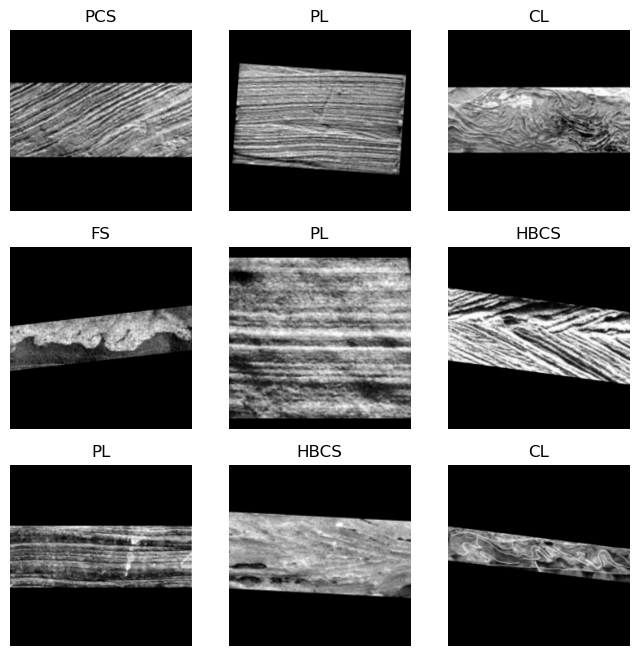

In [25]:
# ============================================================
# STEP 4B : VERIFY DATALOADER
# ============================================================

print("=" * 70)
print("STEP 4B : VERIFYING DATALOADER")
print("=" * 70)

# --------------------------------------------------------
# Create DataLoader for Run 1
# --------------------------------------------------------

MODEL_NAME = "ResNet50"

dls = create_dataloaders(
    run_number=1,
    model_name=MODEL_NAME
)

cfg = MODELS[MODEL_NAME]

print("\n✓ DataLoader Created Successfully\n")

# --------------------------------------------------------
# Dataset Information
# --------------------------------------------------------

print("=" * 70)
print("DATASET INFORMATION")
print("=" * 70)

print(f"Training Images   : {len(dls.train_ds)}")
print(f"Validation Images : {len(dls.valid_ds)}")
print(f"Number of Classes : {dls.c}")
print(f"Image Size        : {cfg['img_size']}")
print(f"Batch Size        : {cfg['batch_size']}")

# --------------------------------------------------------
# Class Names
# --------------------------------------------------------

print("\n")
print("=" * 70)
print("CLASS NAMES")
print("=" * 70)

for i, cls in enumerate(dls.vocab, start=1):
    print(f"{i}. {cls}")

# --------------------------------------------------------
# One Batch Information
# --------------------------------------------------------

print("\n")
print("=" * 70)
print("BATCH INFORMATION")
print("=" * 70)

x, y = dls.one_batch()

print(f"Image Tensor Shape : {x.shape}")
print(f"Label Shape        : {y.shape}")

print(f"Minimum Pixel      : {x.min().item():.4f}")
print(f"Maximum Pixel      : {x.max().item():.4f}")

# --------------------------------------------------------
# Show Sample Batch
# --------------------------------------------------------

print("\n")
print("=" * 70)
print("SAMPLE IMAGES")
print("=" * 70)

dls.show_batch(max_n=9, figsize=(8,8))

print("\n")
print("=" * 70)
print("STEP 4B COMPLETED SUCCESSFULLY")
print("=" * 70)

In [16]:
# ============================================================
# STEP 5 : MODEL BENCHMARK CONFIGURATION
# ============================================================

from torchvision.models import (
    resnet50,
    densenet121,
    mobilenet_v3_large,
    efficientnet_b0,
    efficientnet_b1,
    vit_b_16
)

# ------------------------------------------------------------
# Models to Benchmark
# ------------------------------------------------------------

MODELS = {

    "ResNet50": {
        "arch": resnet50,
        "weights": "DEFAULT",
        "img_size": 224,
        "batch_size": 32,
    },

    "DenseNet121": {
        "arch": densenet121,
        "weights": "DEFAULT",
        "img_size": 224,
        "batch_size": 32,
    },

    "MobileNetV3": {
        "arch": mobilenet_v3_large,
        "weights": "DEFAULT",
        "img_size": 224,
        "batch_size": 32,
    },

    "EfficientNet_B0": {
        "arch": efficientnet_b0,
        "weights": "DEFAULT",
        "img_size": 224,
        "batch_size": 32,
    },

    "EfficientNet_B1": {
        "arch": efficientnet_b1,
        "weights": "DEFAULT",
        "img_size": 240,
        "batch_size": 24,
    },

}

print("=" * 70)
print("STEP 5 : MODEL CONFIGURATION")
print("=" * 70)

for i, (name, cfg) in enumerate(MODELS.items(), start=1):

    print(f"{i}. {name}")

    print(f"   Image Size : {cfg['img_size']}")

    print(f"   Batch Size : {cfg['batch_size']}")

    print()

print(f"Total Models : {len(MODELS)}")

STEP 5 : MODEL CONFIGURATION
1. ResNet50
   Image Size : 224
   Batch Size : 32

2. DenseNet121
   Image Size : 224
   Batch Size : 32

3. MobileNetV3
   Image Size : 224
   Batch Size : 32

4. EfficientNet_B0
   Image Size : 224
   Batch Size : 32

5. EfficientNet_B1
   Image Size : 240
   Batch Size : 24

Total Models : 5


In [32]:
# ============================================================
# STEP 6A : CREATE FASTAI LEARNER
# ============================================================

from fastai.vision.all import *

def create_learner(model_name, dls):
    """
    Create a FastAI Learner.
    """

    # --------------------------------------------------------
    # Get Model Configuration
    # --------------------------------------------------------

    cfg = MODELS[model_name]

    arch = cfg["arch"]
    weights = cfg["weights"]

    # --------------------------------------------------------
    # Create Learner
    # --------------------------------------------------------

    learn = vision_learner(
        dls,
        arch,
        pretrained=(weights is not None),
        loss_func=CrossEntropyLossFlat(),
        metrics=[
            accuracy,
            error_rate
        ]
    )

    return learn

In [33]:
# ============================================================
# STEP 6B : VERIFY FASTAI LEARNER
# ============================================================

print("=" * 70)
print("STEP 6B : VERIFY FASTAI LEARNER")
print("=" * 70)

# --------------------------------------------------------
# Select Model & Run
# --------------------------------------------------------

MODEL_NAME = "ResNet50"
RUN_NUMBER = 1

print(f"\nModel : {MODEL_NAME}")
print(f"Run   : {RUN_NUMBER}")

# --------------------------------------------------------
# Create DataLoaders
# --------------------------------------------------------

dls = create_dataloaders(
    run_number=RUN_NUMBER,
    model_name=MODEL_NAME
)

cfg = MODELS[MODEL_NAME]

# --------------------------------------------------------
# Create Learner
# --------------------------------------------------------

learn = create_learner(
    model_name=MODEL_NAME,
    dls=dls
)

print("\n✓ Learner created successfully!")

# --------------------------------------------------------
# Model Information
# --------------------------------------------------------

print("\n" + "=" * 70)
print("MODEL INFORMATION")
print("=" * 70)

total_params = sum(p.numel() for p in learn.model.parameters())
trainable_params = sum(
    p.numel() for p in learn.model.parameters()
    if p.requires_grad
)

print(f"Architecture         : {MODEL_NAME}")
print(f"Image Size           : {cfg['img_size']}")
print(f"Batch Size           : {cfg['batch_size']}")
print(f"Training Images      : {len(dls.train_ds)}")
print(f"Validation Images    : {len(dls.valid_ds)}")
print(f"Number of Classes    : {dls.c}")

print(f"\nTotal Parameters     : {total_params:,}")
print(f"Trainable Parameters : {trainable_params:,}")

# --------------------------------------------------------
# Forward Pass Test
# --------------------------------------------------------

print("\n" + "=" * 70)
print("FORWARD PASS TEST")
print("=" * 70)

xb, yb = dls.one_batch()

with torch.no_grad():
    pred = learn.model(xb)

print(f"Input Shape          : {tuple(xb.shape)}")
print(f"Output Shape         : {tuple(pred.shape)}")

expected_classes = dls.c

assert pred.shape[1] == expected_classes, \
    f"Expected {expected_classes} classes, got {pred.shape[1]}"

print("\n✓ Forward pass successful!")
print("✓ Output dimensions are correct!")

print("\n" + "=" * 70)
print("STEP 6B COMPLETED SUCCESSFULLY")
print("=" * 70)

STEP 6B : VERIFY FASTAI LEARNER

Model : ResNet50
Run   : 1

✓ Learner created successfully!

MODEL INFORMATION
Architecture         : ResNet50
Image Size           : 224
Batch Size           : 32
Training Images      : 526
Validation Images    : 135
Number of Classes    : 9

Total Parameters     : 25,619,008
Trainable Parameters : 2,164,096

FORWARD PASS TEST
Input Shape          : (32, 3, 224, 224)
Output Shape         : (32, 9)

✓ Forward pass successful!
✓ Output dimensions are correct!

STEP 6B COMPLETED SUCCESSFULLY


In [34]:
# ============================================================
# STEP 6C : VERIFY ALL BENCHMARK MODELS
# ============================================================

print("=" * 80)
print("STEP 6C : VERIFYING ALL BENCHMARK MODELS")
print("=" * 80)

verification_results = []

RUN_NUMBER = 1

for model_name in MODELS.keys():

    print(f"\nTesting {model_name}...")

    try:

        # ----------------------------------------------------
        # Create DataLoader
        # ----------------------------------------------------

        dls = create_dataloaders(
            run_number=RUN_NUMBER,
            model_name=model_name
        )

        cfg = MODELS[model_name]

        # ----------------------------------------------------
        # Create Learner
        # ----------------------------------------------------

        learn = create_learner(
            model_name=model_name,
            dls=dls
        )

        # ----------------------------------------------------
        # Forward Pass
        # ----------------------------------------------------

        xb, yb = dls.one_batch()

        with torch.no_grad():
            preds = learn.model(xb)

        # ----------------------------------------------------
        # Verify Output Shape
        # ----------------------------------------------------

        assert preds.shape[1] == dls.c, \
            f"Expected {dls.c} classes, got {preds.shape[1]}"

        # ----------------------------------------------------
        # Parameter Count
        # ----------------------------------------------------

        total_params = sum(
            p.numel() for p in learn.model.parameters()
        )

        trainable_params = sum(
            p.numel()
            for p in learn.model.parameters()
            if p.requires_grad
        )

        verification_results.append({

            "Model": model_name,
            "Status": "PASS",
            "Image Size": cfg["img_size"],
            "Batch Size": cfg["batch_size"],
            "Classes": dls.c,
            "Train Images": len(dls.train_ds),
            "Valid Images": len(dls.valid_ds),
            "Parameters": f"{total_params:,}",
            "Trainable": f"{trainable_params:,}",
            "Output Shape": tuple(preds.shape)

        })

        print("✓ PASS")

    except Exception as e:

        verification_results.append({

            "Model": model_name,
            "Status": "FAIL",
            "Image Size": MODELS[model_name]["img_size"],
            "Batch Size": MODELS[model_name]["batch_size"],
            "Classes": "-",
            "Train Images": "-",
            "Valid Images": "-",
            "Parameters": "-",
            "Trainable": "-",
            "Output Shape": str(e)

        })

        print("✗ FAIL")
        print(e)

# ============================================================
# Summary
# ============================================================

print("\n")
print("=" * 80)
print("MODEL VERIFICATION SUMMARY")
print("=" * 80)

verification_df = pd.DataFrame(verification_results)

display(verification_df)

passed = (verification_df["Status"] == "PASS").sum()
failed = (verification_df["Status"] == "FAIL").sum()

print("\n" + "=" * 80)
print(f"Passed : {passed}")
print(f"Failed : {failed}")

if failed == 0:
    print("\n🎉 All benchmark models are ready for training!")
else:
    print("\n⚠️ Please resolve the failed models before proceeding.")

STEP 6C : VERIFYING ALL BENCHMARK MODELS

Testing ResNet50...
✓ PASS

Testing DenseNet121...
✓ PASS

Testing MobileNetV3...
✓ PASS

Testing EfficientNet_B0...
✓ PASS

Testing EfficientNet_B1...
✓ PASS


MODEL VERIFICATION SUMMARY


,Model,Status,Image Size,Batch Size,Classes,Train Images,Valid Images,Parameters,Trainable,Output Shape
0,ResNet50,PASS,224,32,9,526,135,"25,619,008","2,164,096","(32, 9)"
1,DenseNet121,PASS,224,32,9,526,135,"8,012,160","1,141,952","(32, 9)"
2,MobileNetV3,PASS,224,32,9,526,135,"3,964,464","1,016,912","(32, 9)"
3,EfficientNet_B0,PASS,224,32,9,526,135,"5,329,020","1,363,488","(32, 9)"
4,EfficientNet_B1,PASS,240,24,9,526,135,"7,834,656","1,383,520","(24, 9)"



Passed : 5
Failed : 0

🎉 All benchmark models are ready for training!


In [4]:
# ============================================================
# STEP 7A : TRAINING CONFIGURATION
# ============================================================

from pathlib import Path
from fastai.callback.tracker import SaveModelCallback, EarlyStoppingCallback
import json
import os

print("=" * 80)
print("STEP 7A : TRAINING CONFIGURATION")
print("=" * 80)

# ------------------------------------------------------------
# Training Hyperparameters
# ------------------------------------------------------------

TRAINING_CONFIG = {

    # Training
    "epochs": 30,
    "use_lr_finder":True,
    "default_lr":1e-3,

    # Fine-tuning
    "freeze_epochs": 1,

    # # Early stopping
    # "early_stopping": True,
    # "patience": 5,

    # Save best model
    "monitor": "valid_loss",

    # Mixed precision
    "mixed_precision": False,

    # Reproducibility
    "deterministic": True

}

# ------------------------------------------------------------
# Output Directories
# ------------------------------------------------------------

OUTPUT_DIR = PROJECT_DIR / "Benchmark_Results"

MODELS_DIR = OUTPUT_DIR / "Saved_Models"
LOGS_DIR = OUTPUT_DIR / "Training_Logs"
HISTORY_DIR = OUTPUT_DIR / "History"
FIGURES_DIR = OUTPUT_DIR / "Figures"

for folder in [
    OUTPUT_DIR,
    MODELS_DIR,
    LOGS_DIR,
    HISTORY_DIR,
    FIGURES_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Save Configuration
# ------------------------------------------------------------

config_path = OUTPUT_DIR / "training_config.json"

with open(config_path, "w") as f:
    json.dump(TRAINING_CONFIG, f, indent=4)

# ------------------------------------------------------------
# Display Configuration
# ------------------------------------------------------------

print("\nTraining Configuration\n")

for key, value in TRAINING_CONFIG.items():
    print(f"{key:20s}: {value}")

print("\nOutput Directories")

print(f"Results Folder : {OUTPUT_DIR}")
print(f"Models Folder  : {MODELS_DIR}")
print(f"Logs Folder    : {LOGS_DIR}")
print(f"History Folder : {HISTORY_DIR}")
print(f"Figures Folder : {FIGURES_DIR}")

print("\n✓ Training configuration completed.")

STEP 7A : TRAINING CONFIGURATION

Training Configuration

epochs              : 30
use_lr_finder       : True
default_lr          : 0.001
freeze_epochs       : 1
monitor             : valid_loss
mixed_precision     : False
deterministic       : True

Output Directories
Results Folder : Benchmark_v2\Benchmark_Results
Models Folder  : Benchmark_v2\Benchmark_Results\Saved_Models
Logs Folder    : Benchmark_v2\Benchmark_Results\Training_Logs
History Folder : Benchmark_v2\Benchmark_Results\History
Figures Folder : Benchmark_v2\Benchmark_Results\Figures

✓ Training configuration completed.


In [5]:
# ============================================================
# STEP 7B : TRAIN A SINGLE MODEL
# ============================================================

import time
import pandas as pd
from fastai.callback.tracker import SaveModelCallback
from fastai.callback.schedule import valley

def train_model(model_name, run_number):

    print("\n" + "=" * 80)
    print(f"Training : {model_name} | Run {run_number}")
    print("=" * 80)

    # --------------------------------------------------------
    # Set Seed
    # --------------------------------------------------------

    set_seed(RUN_SEEDS[run_number-1], reproducible=True)

    # --------------------------------------------------------
    # Create DataLoader
    # --------------------------------------------------------

    dls = create_dataloaders(
        run_number=run_number,
        model_name=model_name
    )

    # --------------------------------------------------------
    # Create Learner
    # --------------------------------------------------------

    learn = create_learner(
        model_name=model_name,
        dls=dls
    )
    
    # --------------------------------------------------------
    # Learning Rate Finder
    # --------------------------------------------------------
    
    try:
        if TRAINING_CONFIG["use_lr_finder"]:
            lr = learn.lr_find(suggest_funcs=(valley,)).valley
            lr = float(lr)
        else:
            lr = TRAINING_CONFIG["default_lr"]
    
    except Exception as e:
        print(f"LR finder failed ({e}). Using default LR.")
        lr = TRAINING_CONFIG["default_lr"]
    
    print(f"\nSelected LR : {lr:.2e}")
    
    # Save checkpoints inside MODELS_DIR
    learn.path = MODELS_DIR
    learn.model_dir = "."
    MODELS_DIR.mkdir(parents=True, exist_ok=True)
    
    # --------------------------------------------------------
    # Save Path
    # --------------------------------------------------------

    model_filename = f"{model_name}_Run{run_number}"

    save_callback = SaveModelCallback(
        monitor=TRAINING_CONFIG["monitor"],
        fname=model_filename
    )

    # --------------------------------------------------------
    # Start Timer
    # --------------------------------------------------------

    start_time = time.time()

    # --------------------------------------------------------
    # Train Frozen Head
    # --------------------------------------------------------

    print("\nStage 1 : Training classifier head")

    learn.freeze()

    learn.fit_one_cycle(
        TRAINING_CONFIG["freeze_epochs"],
        lr_max=lr,
        cbs=[save_callback]
    )
    # --------------------------------------------------------
    # Fine Tune Entire Network
    # --------------------------------------------------------

    print("\nStage 2 : Fine-tuning entire model")

    learn.unfreeze()

    learn.fit_one_cycle(
        TRAINING_CONFIG["epochs"],
        lr_max=slice(
            lr/100,
            lr
        ),
        cbs=[save_callback]
    )

    # --------------------------------------------------------
    # Training Time
    # --------------------------------------------------------

    elapsed = time.time() - start_time

    print(f"\nTraining Time : {elapsed/60:.2f} minutes")

    # --------------------------------------------------------
    try:
        learn.load(model_filename)
        learn.export(f"{model_filename}.pkl")
        print("✓ Best model and learner exported successfully.")
    except Exception as e:
        print(f"Warning: Export failed: {e}")
    # Return Summary
    # --------------------------------------------------------

    summary = {
    
        "Model": model_name,
        "Run": run_number,
        "Seed": RUN_SEEDS[run_number-1],
        "Learning Rate": float(lr),
        "Epochs": TRAINING_CONFIG["epochs"],
        "Image Size": MODELS[model_name]["img_size"],
        "Batch Size": MODELS[model_name]["batch_size"],
        "Training Time (min)": round(elapsed/60,2)
    
    }
    print("\n✓ Training Completed Successfully")

    return learn, summary

STEP 7C : VERIFY SINGLE TRAINING RUN

Training : ResNet50 | Run 1



Selected LR : 3.63e-03

Stage 1 : Training classifier head


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.642745,3.615587,0.333333,0.666667,01:12


Better model found at epoch 0 with valid_loss value: 3.615586519241333.

Stage 2 : Fine-tuning entire model


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,1.831815,2.006671,0.451852,0.548148,01:30
1,1.544421,1.877389,0.451852,0.548148,01:44
2,1.332937,1.813660,0.503704,0.496296,01:30
3,1.165596,1.412482,0.622222,0.377778,01:29
4,1.048246,1.368579,0.607407,0.392593,01:33
5,0.954587,1.443125,0.629630,0.370370,01:35
6,0.846225,1.426919,0.666667,0.333333,01:30
7,0.737636,1.171451,0.718518,0.281481,01:30
8,0.671930,1.062761,0.733333,0.266667,01:30
9,0.605443,1.267466,0.666667,0.333333,01:30


Better model found at epoch 0 with valid_loss value: 2.0066709518432617.
Better model found at epoch 1 with valid_loss value: 1.8773889541625977.
Better model found at epoch 2 with valid_loss value: 1.8136603832244873.
Better model found at epoch 3 with valid_loss value: 1.412481665611267.
Better model found at epoch 4 with valid_loss value: 1.3685789108276367.
Better model found at epoch 7 with valid_loss value: 1.1714513301849365.
Better model found at epoch 8 with valid_loss value: 1.0627609491348267.
Better model found at epoch 10 with valid_loss value: 1.0373380184173584.
Better model found at epoch 18 with valid_loss value: 0.9481816291809082.
Better model found at epoch 19 with valid_loss value: 0.912045955657959.
Better model found at epoch 21 with valid_loss value: 0.839730978012085.
Better model found at epoch 26 with valid_loss value: 0.8025074601173401.

Training Time : 46.81 minutes
✓ Best model and learner exported successfully.

✓ Training Completed Successfully


TRAINI

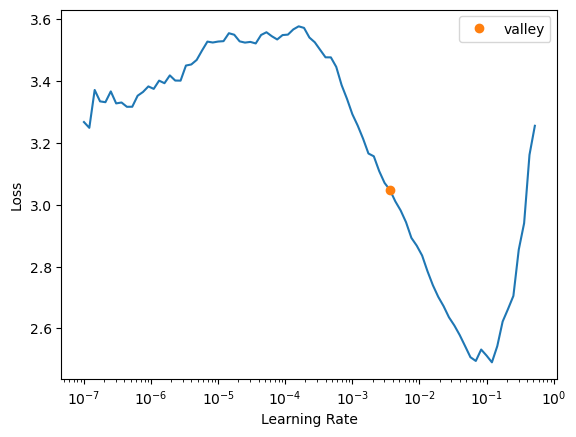

In [45]:
# ============================================================
# STEP 7C : VERIFY SINGLE TRAINING RUN
# ============================================================

print("=" * 80)
print("STEP 7C : VERIFY SINGLE TRAINING RUN")
print("=" * 80)

# ------------------------------------------------------------
# Select Model
# ------------------------------------------------------------

MODEL_NAME = "ResNet50"
RUN_NUMBER = 1

# ------------------------------------------------------------
# Train Model
# ------------------------------------------------------------

learn, summary = train_model(
    model_name=MODEL_NAME,
    run_number=RUN_NUMBER
)

# ------------------------------------------------------------
# Training Summary
# ------------------------------------------------------------

print("\n")
print("=" * 80)
print("TRAINING SUMMARY")
print("=" * 80)

for key, value in summary.items():
    print(f"{key:22s}: {value}")

# ------------------------------------------------------------
# Check Saved Files
# ------------------------------------------------------------

print("\n")
print("=" * 80)
print("VERIFY SAVED FILES")
print("=" * 80)

model_file = MODELS_DIR / f"{MODEL_NAME}_Run{RUN_NUMBER}.pth"
export_file = MODELS_DIR / f"{MODEL_NAME}_Run{RUN_NUMBER}.pkl"

print(f"Best Model (.pth) : {'✓ Found' if model_file.exists() else '✗ Missing'}")
print(f"Learner (.pkl)    : {'✓ Found' if export_file.exists() else '✗ Missing'}")

# ------------------------------------------------------------
# ------------------------------------------------------------
# Final Status
# ------------------------------------------------------------

if model_file.exists() and export_file.exists():
    print("\n✓ All model files saved successfully.")

    print("\n" + "=" * 80)
    print("STEP 7C COMPLETED SUCCESSFULLY")
    print("=" * 80)

else:
    print("\n✗ One or more model files are missing.")
    print("Please fix the issue before running Step 7D.")

STEP 7D : TRAIN ALL CNN MODELS

Models to Train:
  • ResNet50
  • DenseNet121
  • MobileNetV3
  • EfficientNet_B0
  • EfficientNet_B1

Total Models : 5
Runs / Model : 5
Total Experiments : 25

MODEL : ResNet50

--------------------------------------------------------------------------------
Experiment 1/25
Model : ResNet50
Run   : 1
--------------------------------------------------------------------------------
✓ ResNet50 Run 1 already trained. Skipping.

--------------------------------------------------------------------------------
Experiment 2/25
Model : ResNet50
Run   : 2
--------------------------------------------------------------------------------

Training : ResNet50 | Run 2



Selected LR : 1.45e-03

Stage 1 : Training classifier head


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.811109,2.932335,0.340741,0.659259,01:01


Better model found at epoch 0 with valid_loss value: 2.9323348999023438.

Stage 2 : Fine-tuning entire model


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,1.905305,1.978374,0.392593,0.607407,01:16
1,1.748992,2.030726,0.429630,0.570370,01:16
2,1.631201,2.027735,0.414815,0.585185,01:16
3,1.526095,1.354468,0.562963,0.437037,01:16
4,1.387799,1.272466,0.622222,0.377778,01:18
5,1.258790,1.058840,0.637037,0.362963,01:16
6,1.160770,1.112350,0.703704,0.296296,01:22
7,1.019273,1.053570,0.703704,0.296296,01:25
8,0.880561,0.950868,0.703704,0.296296,01:18
9,0.765596,1.024618,0.674074,0.325926,01:17


Better model found at epoch 0 with valid_loss value: 1.9783741235733032.
Better model found at epoch 3 with valid_loss value: 1.3544683456420898.
Better model found at epoch 4 with valid_loss value: 1.2724664211273193.
Better model found at epoch 5 with valid_loss value: 1.058840036392212.
Better model found at epoch 7 with valid_loss value: 1.05357027053833.
Better model found at epoch 8 with valid_loss value: 0.9508683085441589.
Better model found at epoch 13 with valid_loss value: 0.9464572668075562.
Better model found at epoch 14 with valid_loss value: 0.9425654411315918.
Better model found at epoch 16 with valid_loss value: 0.9030298590660095.
Better model found at epoch 19 with valid_loss value: 0.8730095624923706.
Better model found at epoch 20 with valid_loss value: 0.8479152917861938.

Training Time : 40.68 minutes
✓ Best model and learner exported successfully.

✓ Training Completed Successfully

--------------------------------------------------------------------------------


Selected LR : 1.74e-03

Stage 1 : Training classifier head


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.715944,5.270847,0.207407,0.792593,01:03


Better model found at epoch 0 with valid_loss value: 5.270846843719482.

Stage 2 : Fine-tuning entire model


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,1.934967,2.584172,0.362963,0.637037,01:20
1,1.707936,2.405690,0.385185,0.614815,01:21
2,1.531409,1.951426,0.414815,0.585185,01:18
3,1.463553,1.601835,0.525926,0.474074,01:17
4,1.299597,1.486733,0.577778,0.422222,01:18
5,1.141154,1.200756,0.614815,0.385185,01:18
6,1.025628,1.272034,0.666667,0.333333,01:18
7,0.906650,0.973240,0.681481,0.318519,01:18
8,0.800409,1.140899,0.659259,0.340741,01:18
9,0.694050,1.292469,0.637037,0.362963,01:17


Better model found at epoch 0 with valid_loss value: 2.584172248840332.
Better model found at epoch 1 with valid_loss value: 2.4056897163391113.
Better model found at epoch 2 with valid_loss value: 1.951425552368164.
Better model found at epoch 3 with valid_loss value: 1.6018354892730713.
Better model found at epoch 4 with valid_loss value: 1.4867327213287354.
Better model found at epoch 5 with valid_loss value: 1.2007558345794678.
Better model found at epoch 7 with valid_loss value: 0.9732400178909302.

Training Time : 40.10 minutes
✓ Best model and learner exported successfully.

✓ Training Completed Successfully

--------------------------------------------------------------------------------
Experiment 4/25
Model : ResNet50
Run   : 4
--------------------------------------------------------------------------------

Training : ResNet50 | Run 4



Selected LR : 1.20e-03

Stage 1 : Training classifier head


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.773142,2.192646,0.422222,0.577778,01:01


Better model found at epoch 0 with valid_loss value: 2.19264554977417.

Stage 2 : Fine-tuning entire model


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,1.923097,1.809227,0.400000,0.600000,01:16
1,1.781982,1.947574,0.422222,0.577778,01:18
2,1.650260,2.219638,0.407407,0.592593,01:19
3,1.488642,1.439818,0.555556,0.444444,01:21
4,1.344318,1.123848,0.614815,0.385185,01:18
5,1.227775,1.119703,0.681481,0.318519,01:16
6,1.115570,1.016368,0.644444,0.355556,01:17
7,1.011499,1.106707,0.681481,0.318519,01:18
8,0.939060,0.838477,0.711111,0.288889,01:17
9,0.815353,1.007959,0.711111,0.288889,01:17


Better model found at epoch 0 with valid_loss value: 1.8092269897460938.
Better model found at epoch 3 with valid_loss value: 1.4398175477981567.
Better model found at epoch 4 with valid_loss value: 1.1238479614257812.
Better model found at epoch 5 with valid_loss value: 1.1197032928466797.
Better model found at epoch 6 with valid_loss value: 1.0163682699203491.
Better model found at epoch 8 with valid_loss value: 0.8384773135185242.
Better model found at epoch 12 with valid_loss value: 0.7812294960021973.
Better model found at epoch 14 with valid_loss value: 0.779297411441803.
Better model found at epoch 16 with valid_loss value: 0.7000088095664978.

Training Time : 40.76 minutes
✓ Best model and learner exported successfully.

✓ Training Completed Successfully

--------------------------------------------------------------------------------
Experiment 5/25
Model : ResNet50
Run   : 5
--------------------------------------------------------------------------------

Training : ResNet50 


Selected LR : 8.32e-04

Stage 1 : Training classifier head


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,3.002786,2.875673,0.266667,0.733333,01:03


Better model found at epoch 0 with valid_loss value: 2.8756728172302246.

Stage 2 : Fine-tuning entire model


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.284842,1.932765,0.348148,0.651852,01:19
1,2.081769,1.910099,0.333333,0.666667,01:19
2,1.977091,1.754653,0.466667,0.533333,01:19
3,1.810171,1.362735,0.548148,0.451852,01:20
4,1.664973,1.234167,0.622222,0.377778,01:19
5,1.518671,1.183006,0.644444,0.355556,01:18
6,1.340633,1.107399,0.659259,0.340741,01:22
7,1.185760,1.192099,0.659259,0.340741,01:25
8,1.092309,1.020549,0.651852,0.348148,01:26
9,0.986319,1.032110,0.666667,0.333333,01:25


Better model found at epoch 0 with valid_loss value: 1.9327645301818848.
Better model found at epoch 1 with valid_loss value: 1.9100985527038574.
Better model found at epoch 2 with valid_loss value: 1.754652976989746.
Better model found at epoch 3 with valid_loss value: 1.3627352714538574.
Better model found at epoch 4 with valid_loss value: 1.2341666221618652.
Better model found at epoch 5 with valid_loss value: 1.1830061674118042.
Better model found at epoch 6 with valid_loss value: 1.1073991060256958.
Better model found at epoch 8 with valid_loss value: 1.0205490589141846.
Better model found at epoch 10 with valid_loss value: 0.9970625042915344.
Better model found at epoch 12 with valid_loss value: 0.9142860174179077.
Better model found at epoch 15 with valid_loss value: 0.8621311187744141.
Better model found at epoch 16 with valid_loss value: 0.8579527735710144.
Better model found at epoch 17 with valid_loss value: 0.828698992729187.
Better model found at epoch 18 with valid_loss v


Selected LR : 8.32e-04

Stage 1 : Training classifier head


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.584214,1.897583,0.385185,0.614815,01:10


Better model found at epoch 0 with valid_loss value: 1.8975830078125.

Stage 2 : Fine-tuning entire model


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,1.676059,1.833208,0.437037,0.562963,01:26
1,1.539743,1.523633,0.496296,0.503704,01:23
2,1.411151,1.160951,0.622222,0.377778,01:26
3,1.284853,0.937630,0.681481,0.318519,01:20
4,1.145698,0.859044,0.688889,0.311111,01:20
5,1.022378,0.849494,0.748148,0.251852,01:21
6,0.893041,0.848917,0.725926,0.274074,01:20
7,0.787890,0.957097,0.733333,0.266667,01:19
8,0.688910,0.866335,0.703704,0.296296,01:19
9,0.615621,0.849206,0.740741,0.259259,01:19


Better model found at epoch 0 with valid_loss value: 1.8332080841064453.
Better model found at epoch 1 with valid_loss value: 1.5236331224441528.
Better model found at epoch 2 with valid_loss value: 1.1609511375427246.
Better model found at epoch 3 with valid_loss value: 0.9376298785209656.
Better model found at epoch 4 with valid_loss value: 0.8590443730354309.
Better model found at epoch 5 with valid_loss value: 0.8494943976402283.
Better model found at epoch 6 with valid_loss value: 0.8489172458648682.
Better model found at epoch 11 with valid_loss value: 0.8449479341506958.
Better model found at epoch 13 with valid_loss value: 0.8411833643913269.
Better model found at epoch 16 with valid_loss value: 0.8177291750907898.

Training Time : 41.31 minutes
✓ Best model and learner exported successfully.

✓ Training Completed Successfully

--------------------------------------------------------------------------------
Experiment 7/25
Model : DenseNet121
Run   : 2
-------------------------


Selected LR : 1.00e-03

Stage 1 : Training classifier head


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.467632,1.791937,0.392593,0.607407,01:07


Better model found at epoch 0 with valid_loss value: 1.791937232017517.

Stage 2 : Fine-tuning entire model


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,1.629448,1.452571,0.525926,0.474074,01:18
1,1.530970,1.188268,0.607407,0.392593,01:18
2,1.403727,0.915419,0.688889,0.311111,01:18
3,1.269824,0.789639,0.703704,0.296296,01:18
4,1.105899,0.762392,0.696296,0.303704,01:19
5,0.976345,0.702207,0.725926,0.274074,01:19
6,0.857971,0.664482,0.740741,0.259259,01:18
7,0.732261,0.753325,0.733333,0.266667,01:18
8,0.639171,0.713021,0.755556,0.244444,01:18
9,0.573547,0.711599,0.748148,0.251852,01:18


Better model found at epoch 0 with valid_loss value: 1.4525706768035889.
Better model found at epoch 1 with valid_loss value: 1.1882681846618652.
Better model found at epoch 2 with valid_loss value: 0.9154186844825745.
Better model found at epoch 3 with valid_loss value: 0.7896389365196228.
Better model found at epoch 4 with valid_loss value: 0.7623924016952515.
Better model found at epoch 5 with valid_loss value: 0.7022066712379456.
Better model found at epoch 6 with valid_loss value: 0.6644823551177979.

Training Time : 40.60 minutes
✓ Best model and learner exported successfully.

✓ Training Completed Successfully

--------------------------------------------------------------------------------
Experiment 8/25
Model : DenseNet121
Run   : 3
--------------------------------------------------------------------------------

Training : DenseNet121 | Run 3



Selected LR : 6.92e-04

Stage 1 : Training classifier head


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.498378,2.120289,0.325926,0.674074,01:07


Better model found at epoch 0 with valid_loss value: 2.1202893257141113.

Stage 2 : Fine-tuning entire model


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,1.818514,1.685006,0.429630,0.570370,01:19
1,1.638570,1.366149,0.525926,0.474074,01:19
2,1.540134,1.167202,0.592593,0.407407,01:19
3,1.441423,0.935591,0.637037,0.362963,01:19
4,1.246189,0.838813,0.666667,0.333333,01:19
5,1.099141,0.821285,0.733333,0.266667,01:19
6,0.937937,0.821658,0.703704,0.296296,01:19
7,0.834055,0.689653,0.733333,0.266667,01:19
8,0.751946,0.618701,0.785185,0.214815,01:19
9,0.673794,0.685596,0.740741,0.259259,01:19


Better model found at epoch 0 with valid_loss value: 1.6850056648254395.
Better model found at epoch 1 with valid_loss value: 1.366148591041565.
Better model found at epoch 2 with valid_loss value: 1.1672019958496094.
Better model found at epoch 3 with valid_loss value: 0.9355912208557129.
Better model found at epoch 4 with valid_loss value: 0.8388132452964783.
Better model found at epoch 5 with valid_loss value: 0.8212852478027344.
Better model found at epoch 7 with valid_loss value: 0.6896533370018005.
Better model found at epoch 8 with valid_loss value: 0.6187010407447815.
Better model found at epoch 11 with valid_loss value: 0.5639594793319702.
Better model found at epoch 15 with valid_loss value: 0.5523398518562317.
Better model found at epoch 20 with valid_loss value: 0.5498074293136597.
Better model found at epoch 24 with valid_loss value: 0.5365548729896545.
Better model found at epoch 25 with valid_loss value: 0.5361531376838684.
Better model found at epoch 27 with valid_loss 


Selected LR : 1.45e-03

Stage 1 : Training classifier head


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.517703,1.709766,0.422222,0.577778,01:07


Better model found at epoch 0 with valid_loss value: 1.7097657918930054.

Stage 2 : Fine-tuning entire model


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,1.404553,1.410555,0.503704,0.496296,01:19
1,1.306783,1.214584,0.585185,0.414815,01:19
2,1.169156,1.060065,0.614815,0.385185,01:19
3,1.038900,0.972028,0.681481,0.318519,01:19
4,0.930445,0.870760,0.703704,0.296296,01:19
5,0.823498,0.960723,0.681481,0.318519,01:18
6,0.731651,1.045005,0.711111,0.288889,01:19
7,0.637769,0.891465,0.740741,0.259259,01:19
8,0.578587,0.903844,0.733333,0.266667,01:19
9,0.493464,0.917538,0.711111,0.288889,01:19


Better model found at epoch 0 with valid_loss value: 1.4105547666549683.
Better model found at epoch 1 with valid_loss value: 1.2145837545394897.
Better model found at epoch 2 with valid_loss value: 1.0600649118423462.
Better model found at epoch 3 with valid_loss value: 0.9720277190208435.
Better model found at epoch 4 with valid_loss value: 0.8707603812217712.
Better model found at epoch 11 with valid_loss value: 0.7618692517280579.

Training Time : 40.78 minutes
✓ Best model and learner exported successfully.

✓ Training Completed Successfully

--------------------------------------------------------------------------------
Experiment 10/25
Model : DenseNet121
Run   : 5
--------------------------------------------------------------------------------

Training : DenseNet121 | Run 5



Selected LR : 6.92e-04

Stage 1 : Training classifier head


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.614515,1.731047,0.377778,0.622222,01:07


Better model found at epoch 0 with valid_loss value: 1.7310469150543213.

Stage 2 : Fine-tuning entire model


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,1.925838,1.654548,0.422222,0.577778,01:19
1,1.756387,1.389099,0.540741,0.459259,01:20
2,1.605443,1.092056,0.607407,0.392593,01:19
3,1.453330,0.868850,0.718518,0.281481,01:19
4,1.253227,0.691767,0.718518,0.281481,01:19
5,1.086221,0.654367,0.770370,0.229630,01:19
6,0.930203,0.730819,0.762963,0.237037,01:19
7,0.846391,0.740628,0.755556,0.244444,01:18
8,0.755465,0.635093,0.807407,0.192593,01:19
9,0.680416,0.797920,0.785185,0.214815,01:19


Better model found at epoch 0 with valid_loss value: 1.6545480489730835.
Better model found at epoch 1 with valid_loss value: 1.3890985250473022.
Better model found at epoch 2 with valid_loss value: 1.0920557975769043.
Better model found at epoch 3 with valid_loss value: 0.8688501715660095.
Better model found at epoch 4 with valid_loss value: 0.6917673945426941.
Better model found at epoch 5 with valid_loss value: 0.654367208480835.
Better model found at epoch 8 with valid_loss value: 0.6350933909416199.

Training Time : 40.79 minutes
✓ Best model and learner exported successfully.

✓ Training Completed Successfully

MODEL : MobileNetV3

--------------------------------------------------------------------------------
Experiment 11/25
Model : MobileNetV3
Run   : 1
--------------------------------------------------------------------------------

Training : MobileNetV3 | Run 1



Selected LR : 1.45e-03

Stage 1 : Training classifier head


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.400839,3.806529,0.266667,0.733333,00:19


Better model found at epoch 0 with valid_loss value: 3.8065285682678223.

Stage 2 : Fine-tuning entire model


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,1.491539,4.152616,0.259259,0.740741,00:24
1,1.473060,3.418010,0.296296,0.703704,00:24
2,1.296381,2.724163,0.377778,0.622222,00:24
3,1.189014,2.549777,0.392593,0.607407,00:24
4,1.065211,2.728773,0.362963,0.637037,00:24
5,0.977609,2.825274,0.407407,0.592593,00:24
6,0.884186,2.641791,0.407407,0.592593,00:24
7,0.806703,2.316990,0.488889,0.511111,00:24
8,0.768469,2.333824,0.481481,0.518519,00:24
9,0.684726,2.024358,0.518519,0.481481,00:24


Better model found at epoch 0 with valid_loss value: 4.152616024017334.
Better model found at epoch 1 with valid_loss value: 3.4180095195770264.
Better model found at epoch 2 with valid_loss value: 2.724163055419922.
Better model found at epoch 3 with valid_loss value: 2.549776792526245.
Better model found at epoch 7 with valid_loss value: 2.3169901371002197.
Better model found at epoch 9 with valid_loss value: 2.024357795715332.
Better model found at epoch 12 with valid_loss value: 1.6310702562332153.
Better model found at epoch 13 with valid_loss value: 1.5924562215805054.
Better model found at epoch 15 with valid_loss value: 1.5617592334747314.
Better model found at epoch 16 with valid_loss value: 1.55020010471344.
Better model found at epoch 17 with valid_loss value: 1.4353747367858887.
Better model found at epoch 18 with valid_loss value: 1.4004844427108765.
Better model found at epoch 25 with valid_loss value: 1.3957951068878174.
Better model found at epoch 26 with valid_loss val


Selected LR : 1.74e-03

Stage 1 : Training classifier head


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.113308,2.937396,0.318519,0.681481,00:20


Better model found at epoch 0 with valid_loss value: 2.9373955726623535.

Stage 2 : Fine-tuning entire model


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,1.453173,2.993483,0.362963,0.637037,00:24
1,1.370177,2.903120,0.333333,0.666667,00:24
2,1.250479,2.344308,0.437037,0.562963,00:24
3,1.127660,2.584995,0.407407,0.592593,00:24
4,1.025762,2.598649,0.414815,0.585185,00:25
5,0.941100,2.325725,0.414815,0.585185,00:24
6,0.880194,2.734102,0.474074,0.525926,00:24
7,0.778359,2.212945,0.525926,0.474074,00:24
8,0.715960,2.145092,0.555556,0.444444,00:24
9,0.685352,1.927358,0.525926,0.474074,00:24


Better model found at epoch 0 with valid_loss value: 2.9934825897216797.
Better model found at epoch 1 with valid_loss value: 2.903120279312134.
Better model found at epoch 2 with valid_loss value: 2.3443078994750977.
Better model found at epoch 5 with valid_loss value: 2.3257246017456055.
Better model found at epoch 7 with valid_loss value: 2.2129452228546143.
Better model found at epoch 8 with valid_loss value: 2.1450915336608887.
Better model found at epoch 9 with valid_loss value: 1.92735755443573.
Better model found at epoch 10 with valid_loss value: 1.6696783304214478.
Better model found at epoch 13 with valid_loss value: 1.6577903032302856.
Better model found at epoch 17 with valid_loss value: 1.6372450590133667.
Better model found at epoch 18 with valid_loss value: 1.600367784500122.
Better model found at epoch 19 with valid_loss value: 1.5796693563461304.
Better model found at epoch 20 with valid_loss value: 1.5158401727676392.
Better model found at epoch 24 with valid_loss va


Selected LR : 1.00e-03

Stage 1 : Training classifier head


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.502448,2.903938,0.251852,0.748148,00:20


Better model found at epoch 0 with valid_loss value: 2.9039382934570312.

Stage 2 : Fine-tuning entire model


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,1.622441,3.021805,0.274074,0.725926,00:24
1,1.612683,2.753673,0.288889,0.711111,00:24
2,1.478232,2.690280,0.340741,0.659259,00:24
3,1.377759,2.375306,0.385185,0.614815,00:24
4,1.219910,2.668137,0.385185,0.614815,00:24
5,1.115194,2.633203,0.400000,0.600000,00:25
6,1.012988,2.311802,0.407407,0.592593,00:24
7,0.930388,2.382287,0.414815,0.585185,00:24
8,0.866539,2.255502,0.437037,0.562963,00:24
9,0.765196,2.187248,0.407407,0.592593,00:24


Better model found at epoch 0 with valid_loss value: 3.0218048095703125.
Better model found at epoch 1 with valid_loss value: 2.7536730766296387.
Better model found at epoch 2 with valid_loss value: 2.6902804374694824.
Better model found at epoch 3 with valid_loss value: 2.3753063678741455.
Better model found at epoch 6 with valid_loss value: 2.3118021488189697.
Better model found at epoch 8 with valid_loss value: 2.255502223968506.
Better model found at epoch 9 with valid_loss value: 2.1872475147247314.
Better model found at epoch 10 with valid_loss value: 2.1104865074157715.
Better model found at epoch 11 with valid_loss value: 1.6275240182876587.
Better model found at epoch 12 with valid_loss value: 1.5205804109573364.
Better model found at epoch 17 with valid_loss value: 1.4668115377426147.
Better model found at epoch 19 with valid_loss value: 1.4249022006988525.
Better model found at epoch 20 with valid_loss value: 1.417608380317688.
Better model found at epoch 21 with valid_loss 


Selected LR : 8.32e-04

Stage 1 : Training classifier head


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.529696,2.443499,0.214815,0.785185,00:19


Better model found at epoch 0 with valid_loss value: 2.4434993267059326.

Stage 2 : Fine-tuning entire model


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,1.707125,2.606265,0.237037,0.762963,00:24
1,1.651253,2.438144,0.311111,0.688889,00:24
2,1.510732,2.188164,0.377778,0.622222,00:24
3,1.389073,2.101717,0.400000,0.600000,00:24
4,1.277899,1.957354,0.488889,0.511111,00:24
5,1.169560,1.777287,0.496296,0.503704,00:24
6,1.085063,2.109596,0.429630,0.570370,00:24
7,0.990454,1.778639,0.525926,0.474074,00:24
8,0.915718,1.623145,0.562963,0.437037,00:24
9,0.824983,1.705519,0.503704,0.496296,00:25


Better model found at epoch 0 with valid_loss value: 2.60626482963562.
Better model found at epoch 1 with valid_loss value: 2.4381439685821533.
Better model found at epoch 2 with valid_loss value: 2.1881637573242188.
Better model found at epoch 3 with valid_loss value: 2.101717233657837.
Better model found at epoch 4 with valid_loss value: 1.9573535919189453.
Better model found at epoch 5 with valid_loss value: 1.777287483215332.
Better model found at epoch 8 with valid_loss value: 1.623144507408142.
Better model found at epoch 10 with valid_loss value: 1.6022720336914062.
Better model found at epoch 11 with valid_loss value: 1.4982068538665771.
Better model found at epoch 15 with valid_loss value: 1.4819486141204834.
Better model found at epoch 16 with valid_loss value: 1.4385384321212769.
Better model found at epoch 17 with valid_loss value: 1.3659148216247559.
Better model found at epoch 18 with valid_loss value: 1.217442274093628.
Better model found at epoch 19 with valid_loss valu


Selected LR : 1.20e-03

Stage 1 : Training classifier head


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.361451,3.416622,0.222222,0.777778,00:19


Better model found at epoch 0 with valid_loss value: 3.416621685028076.

Stage 2 : Fine-tuning entire model


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,1.635125,3.603997,0.229630,0.770370,00:24
1,1.566179,3.092329,0.311111,0.688889,00:24
2,1.407658,2.581905,0.385185,0.614815,00:24
3,1.296940,2.417492,0.377778,0.622222,00:24
4,1.191206,1.961125,0.466667,0.533333,00:24
5,1.078840,2.166303,0.451852,0.548148,00:24
6,0.985052,1.943478,0.518519,0.481481,00:24
7,0.888772,1.916976,0.503704,0.496296,00:24
8,0.815446,2.171535,0.488889,0.511111,00:24
9,0.737185,1.962620,0.525926,0.474074,00:24


Better model found at epoch 0 with valid_loss value: 3.6039974689483643.
Better model found at epoch 1 with valid_loss value: 3.0923287868499756.
Better model found at epoch 2 with valid_loss value: 2.5819051265716553.
Better model found at epoch 3 with valid_loss value: 2.417492389678955.
Better model found at epoch 4 with valid_loss value: 1.9611246585845947.
Better model found at epoch 6 with valid_loss value: 1.9434781074523926.
Better model found at epoch 7 with valid_loss value: 1.9169758558273315.
Better model found at epoch 10 with valid_loss value: 1.8113750219345093.
Better model found at epoch 17 with valid_loss value: 1.7203257083892822.
Better model found at epoch 20 with valid_loss value: 1.6922370195388794.
Better model found at epoch 21 with valid_loss value: 1.654433250427246.
Better model found at epoch 22 with valid_loss value: 1.633575201034546.
Better model found at epoch 23 with valid_loss value: 1.558746576309204.
Better model found at epoch 24 with valid_loss va


Selected LR : 1.45e-03

Stage 1 : Training classifier head


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.534927,1.945263,0.407407,0.592593,00:35


Better model found at epoch 0 with valid_loss value: 1.9452632665634155.

Stage 2 : Fine-tuning entire model


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,1.860566,1.892273,0.518519,0.481481,00:43
1,1.769019,1.505544,0.525926,0.474074,00:43
2,1.641342,1.500138,0.585185,0.414815,00:43
3,1.503806,1.315750,0.600000,0.400000,00:43
4,1.416523,1.191625,0.622222,0.377778,00:43
5,1.342677,1.443964,0.592593,0.407407,00:43
6,1.201101,1.330796,0.585185,0.414815,00:43
7,1.098471,1.288477,0.614815,0.385185,00:43
8,1.037080,1.243737,0.614815,0.385185,00:43
9,0.963275,1.211373,0.644444,0.355556,00:43


Better model found at epoch 0 with valid_loss value: 1.89227294921875.
Better model found at epoch 1 with valid_loss value: 1.50554358959198.
Better model found at epoch 2 with valid_loss value: 1.5001380443572998.
Better model found at epoch 3 with valid_loss value: 1.315750241279602.
Better model found at epoch 4 with valid_loss value: 1.1916253566741943.
Better model found at epoch 11 with valid_loss value: 1.1327365636825562.
Better model found at epoch 12 with valid_loss value: 1.0934810638427734.
Better model found at epoch 13 with valid_loss value: 1.0863943099975586.
Better model found at epoch 15 with valid_loss value: 1.0584020614624023.
Better model found at epoch 18 with valid_loss value: 1.0027426481246948.
Better model found at epoch 19 with valid_loss value: 1.0011935234069824.
Better model found at epoch 26 with valid_loss value: 0.9795949459075928.

Training Time : 22.21 minutes
✓ Best model and learner exported successfully.

✓ Training Completed Successfully

-------


Selected LR : 6.92e-04

Stage 1 : Training classifier head


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.727162,1.636124,0.437037,0.562963,00:34


Better model found at epoch 0 with valid_loss value: 1.6361241340637207.

Stage 2 : Fine-tuning entire model


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.038693,1.741721,0.444444,0.555556,00:43
1,1.975354,1.497569,0.488889,0.511111,00:43
2,1.909268,1.193019,0.644444,0.355556,00:43
3,1.839361,1.121645,0.607407,0.392593,00:43
4,1.712134,1.115473,0.614815,0.385185,00:43
5,1.561843,1.029111,0.659259,0.340741,00:43
6,1.446920,1.048972,0.629630,0.370370,00:42
7,1.316731,1.018987,0.666667,0.333333,00:43
8,1.224244,1.107752,0.666667,0.333333,00:43
9,1.111889,1.071417,0.666667,0.333333,00:43


Better model found at epoch 0 with valid_loss value: 1.7417205572128296.
Better model found at epoch 1 with valid_loss value: 1.4975686073303223.
Better model found at epoch 2 with valid_loss value: 1.193018913269043.
Better model found at epoch 3 with valid_loss value: 1.1216448545455933.
Better model found at epoch 4 with valid_loss value: 1.1154730319976807.
Better model found at epoch 5 with valid_loss value: 1.0291105508804321.
Better model found at epoch 7 with valid_loss value: 1.0189868211746216.
Better model found at epoch 12 with valid_loss value: 1.0138429403305054.
Better model found at epoch 13 with valid_loss value: 0.9705488681793213.
Better model found at epoch 21 with valid_loss value: 0.9523166418075562.
Better model found at epoch 22 with valid_loss value: 0.9437031149864197.
Better model found at epoch 23 with valid_loss value: 0.9370684027671814.
Better model found at epoch 24 with valid_loss value: 0.9348503351211548.
Better model found at epoch 25 with valid_loss


Selected LR : 1.45e-03

Stage 1 : Training classifier head


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.384541,1.664136,0.444444,0.555556,00:33


Better model found at epoch 0 with valid_loss value: 1.664136290550232.

Stage 2 : Fine-tuning entire model


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,1.810301,1.628721,0.466667,0.533333,00:42
1,1.763360,1.486897,0.533333,0.466667,00:42
2,1.618214,1.251788,0.585185,0.414815,00:42
3,1.514564,1.091542,0.600000,0.400000,00:42
4,1.431716,1.118752,0.629630,0.370370,00:42
5,1.329617,1.144105,0.629630,0.370370,00:42
6,1.235513,1.183927,0.614815,0.385185,00:42
7,1.159343,1.127940,0.651852,0.348148,00:42
8,1.058829,1.098455,0.659259,0.340741,00:42
9,0.974704,1.062295,0.644444,0.355556,00:42


Better model found at epoch 0 with valid_loss value: 1.6287212371826172.
Better model found at epoch 1 with valid_loss value: 1.4868972301483154.
Better model found at epoch 2 with valid_loss value: 1.2517879009246826.
Better model found at epoch 3 with valid_loss value: 1.0915424823760986.
Better model found at epoch 9 with valid_loss value: 1.0622953176498413.
Better model found at epoch 19 with valid_loss value: 1.0533311367034912.
Better model found at epoch 20 with valid_loss value: 1.0466471910476685.
Better model found at epoch 21 with valid_loss value: 0.9945482015609741.
Better model found at epoch 23 with valid_loss value: 0.9638795256614685.
Better model found at epoch 24 with valid_loss value: 0.957069993019104.
Better model found at epoch 26 with valid_loss value: 0.948671817779541.

Training Time : 21.78 minutes
✓ Best model and learner exported successfully.

✓ Training Completed Successfully

------------------------------------------------------------------------------


Selected LR : 5.75e-04

Stage 1 : Training classifier head


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.940460,1.687148,0.459259,0.540741,00:33


Better model found at epoch 0 with valid_loss value: 1.687147617340088.

Stage 2 : Fine-tuning entire model


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.324669,1.792008,0.437037,0.562963,00:41
1,2.266041,1.660890,0.451852,0.548148,00:41
2,2.124704,1.432084,0.525926,0.474074,00:41
3,1.953375,1.263747,0.607407,0.392593,00:41
4,1.792256,1.200163,0.585185,0.414815,00:41
5,1.670406,1.145254,0.607407,0.392593,00:41
6,1.560244,1.103437,0.622222,0.377778,00:41
7,1.404839,1.178483,0.607407,0.392593,00:41
8,1.286472,1.124405,0.637037,0.362963,00:41
9,1.184666,1.210921,0.622222,0.377778,00:41


Better model found at epoch 0 with valid_loss value: 1.7920080423355103.
Better model found at epoch 1 with valid_loss value: 1.660889983177185.
Better model found at epoch 2 with valid_loss value: 1.4320837259292603.
Better model found at epoch 3 with valid_loss value: 1.263747215270996.
Better model found at epoch 4 with valid_loss value: 1.2001632452011108.
Better model found at epoch 5 with valid_loss value: 1.145254373550415.
Better model found at epoch 6 with valid_loss value: 1.1034369468688965.
Better model found at epoch 11 with valid_loss value: 1.0718154907226562.
Better model found at epoch 18 with valid_loss value: 1.0311473608016968.
Better model found at epoch 19 with valid_loss value: 0.9937413930892944.

Training Time : 21.46 minutes
✓ Best model and learner exported successfully.

✓ Training Completed Successfully

--------------------------------------------------------------------------------
Experiment 20/25
Model : EfficientNet_B0
Run   : 5
-----------------------


Selected LR : 8.32e-04

Stage 1 : Training classifier head


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.813120,1.813919,0.377778,0.622222,00:33


Better model found at epoch 0 with valid_loss value: 1.8139187097549438.

Stage 2 : Fine-tuning entire model


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.117530,1.549278,0.459259,0.540741,00:41
1,2.043649,1.316769,0.496296,0.503704,00:41
2,1.887969,1.314077,0.540741,0.459259,00:41
3,1.751910,1.080381,0.622222,0.377778,00:41
4,1.611789,1.002949,0.622222,0.377778,00:41
5,1.463738,1.013764,0.681481,0.318519,00:41
6,1.358874,1.027928,0.644444,0.355556,00:41
7,1.250880,1.067383,0.622222,0.377778,00:41
8,1.186598,1.002209,0.688889,0.311111,00:41
9,1.119429,1.085892,0.659259,0.340741,00:41


Better model found at epoch 0 with valid_loss value: 1.5492775440216064.
Better model found at epoch 1 with valid_loss value: 1.3167692422866821.
Better model found at epoch 2 with valid_loss value: 1.3140771389007568.
Better model found at epoch 3 with valid_loss value: 1.0803812742233276.
Better model found at epoch 4 with valid_loss value: 1.0029493570327759.
Better model found at epoch 8 with valid_loss value: 1.002208948135376.
Better model found at epoch 11 with valid_loss value: 0.9008347988128662.
Better model found at epoch 12 with valid_loss value: 0.8931072950363159.
Better model found at epoch 13 with valid_loss value: 0.8710518479347229.
Better model found at epoch 26 with valid_loss value: 0.8568578958511353.

Training Time : 21.30 minutes
✓ Best model and learner exported successfully.

✓ Training Completed Successfully

MODEL : EfficientNet_B1

--------------------------------------------------------------------------------
Experiment 21/25
Model : EfficientNet_B1
Run  


Selected LR : 1.45e-03

Stage 1 : Training classifier head


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.643496,2.444783,0.377778,0.622222,00:55


Better model found at epoch 0 with valid_loss value: 2.4447827339172363.

Stage 2 : Fine-tuning entire model


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,1.758738,1.837963,0.429630,0.570370,01:07
1,1.746342,1.597557,0.518519,0.481481,01:08
2,1.557111,1.628649,0.474074,0.525926,01:09
3,1.405272,1.524198,0.548148,0.451852,01:09
4,1.335298,1.610135,0.540741,0.459259,01:09
5,1.288472,1.484558,0.562963,0.437037,01:08
6,1.245245,1.540116,0.533333,0.466667,01:11
7,1.126960,1.534912,0.562963,0.437037,01:11
8,1.018744,1.519662,0.577778,0.422222,01:11
9,0.980027,1.515260,0.577778,0.422222,01:12


Better model found at epoch 0 with valid_loss value: 1.8379626274108887.
Better model found at epoch 1 with valid_loss value: 1.5975568294525146.
Better model found at epoch 3 with valid_loss value: 1.5241979360580444.
Better model found at epoch 5 with valid_loss value: 1.4845584630966187.
Better model found at epoch 10 with valid_loss value: 1.4068700075149536.
Better model found at epoch 11 with valid_loss value: 1.341604232788086.
Better model found at epoch 14 with valid_loss value: 1.251826524734497.
Better model found at epoch 15 with valid_loss value: 1.2351818084716797.
Better model found at epoch 21 with valid_loss value: 1.2187559604644775.
Better model found at epoch 22 with valid_loss value: 1.1566438674926758.
Better model found at epoch 27 with valid_loss value: 1.1314946413040161.

Training Time : 35.91 minutes
✓ Best model and learner exported successfully.

✓ Training Completed Successfully

-----------------------------------------------------------------------------


Selected LR : 2.09e-03

Stage 1 : Training classifier head


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.567443,1.813497,0.481481,0.518519,00:57


Better model found at epoch 0 with valid_loss value: 1.8134973049163818.

Stage 2 : Fine-tuning entire model


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,1.803971,1.433933,0.570370,0.429630,01:09
1,1.718723,1.076196,0.614815,0.385185,01:09
2,1.520659,1.229371,0.592593,0.407407,01:10
3,1.397542,1.267387,0.592593,0.407407,01:09
4,1.328609,1.294476,0.592593,0.407407,01:10
5,1.248980,1.473154,0.548148,0.451852,01:09
6,1.182473,1.449639,0.540741,0.459259,01:09
7,1.099706,1.260343,0.644444,0.355556,01:10
8,0.992153,1.189237,0.570370,0.429630,01:09
9,0.890676,1.039772,0.644444,0.355556,01:09


Better model found at epoch 0 with valid_loss value: 1.4339326620101929.
Better model found at epoch 1 with valid_loss value: 1.0761964321136475.
Better model found at epoch 9 with valid_loss value: 1.039771556854248.
Better model found at epoch 19 with valid_loss value: 1.037485122680664.
Better model found at epoch 21 with valid_loss value: 0.9727869033813477.
Better model found at epoch 22 with valid_loss value: 0.9614546298980713.

Training Time : 36.22 minutes
✓ Best model and learner exported successfully.

✓ Training Completed Successfully

--------------------------------------------------------------------------------
Experiment 23/25
Model : EfficientNet_B1
Run   : 3
--------------------------------------------------------------------------------

Training : EfficientNet_B1 | Run 3



Selected LR : 1.20e-03

Stage 1 : Training classifier head


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.773060,2.217926,0.385185,0.614815,00:58


Better model found at epoch 0 with valid_loss value: 2.217925548553467.

Stage 2 : Fine-tuning entire model


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,1.878308,1.844232,0.451852,0.548148,01:10
1,1.796658,1.504591,0.488889,0.511111,01:10
2,1.657276,1.476834,0.525926,0.474074,01:10
3,1.533879,1.447381,0.459259,0.540741,01:10
4,1.411705,1.382625,0.540741,0.459259,01:10
5,1.304667,1.480433,0.540741,0.459259,01:10
6,1.252594,1.438765,0.548148,0.451852,01:10
7,1.117876,1.284078,0.585185,0.414815,01:10
8,1.051615,1.218103,0.600000,0.400000,01:10
9,0.984270,1.298594,0.600000,0.400000,01:10


Better model found at epoch 0 with valid_loss value: 1.844232201576233.
Better model found at epoch 1 with valid_loss value: 1.5045905113220215.
Better model found at epoch 2 with valid_loss value: 1.4768344163894653.
Better model found at epoch 3 with valid_loss value: 1.4473806619644165.
Better model found at epoch 4 with valid_loss value: 1.3826254606246948.
Better model found at epoch 7 with valid_loss value: 1.2840776443481445.
Better model found at epoch 8 with valid_loss value: 1.218103289604187.
Better model found at epoch 10 with valid_loss value: 1.1947901248931885.
Better model found at epoch 15 with valid_loss value: 1.174583911895752.
Better model found at epoch 16 with valid_loss value: 1.109214186668396.
Better model found at epoch 17 with valid_loss value: 1.0823630094528198.
Better model found at epoch 18 with valid_loss value: 1.0023887157440186.

Training Time : 36.10 minutes
✓ Best model and learner exported successfully.

✓ Training Completed Successfully

--------


Selected LR : 6.92e-04

Stage 1 : Training classifier head


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.605361,2.172446,0.385185,0.614815,00:58


Better model found at epoch 0 with valid_loss value: 2.17244553565979.

Stage 2 : Fine-tuning entire model


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.273649,1.793822,0.392593,0.607407,01:10
1,2.113188,1.551211,0.481481,0.518519,01:10
2,1.935423,1.441909,0.511111,0.488889,01:11
3,1.778586,1.391145,0.577778,0.422222,01:11
4,1.626441,1.392812,0.548148,0.451852,01:10
5,1.537337,1.342126,0.600000,0.400000,01:10
6,1.425084,1.414041,0.600000,0.400000,01:10
7,1.298561,1.328680,0.555556,0.444444,01:10
8,1.208706,1.403149,0.585185,0.414815,01:10
9,1.163249,1.337547,0.592593,0.407407,01:10


Better model found at epoch 0 with valid_loss value: 1.793821930885315.
Better model found at epoch 1 with valid_loss value: 1.5512109994888306.
Better model found at epoch 2 with valid_loss value: 1.4419090747833252.
Better model found at epoch 3 with valid_loss value: 1.39114511013031.
Better model found at epoch 5 with valid_loss value: 1.3421263694763184.
Better model found at epoch 7 with valid_loss value: 1.3286795616149902.
Better model found at epoch 10 with valid_loss value: 1.3167271614074707.
Better model found at epoch 11 with valid_loss value: 1.2703781127929688.
Better model found at epoch 12 with valid_loss value: 1.1920428276062012.
Better model found at epoch 18 with valid_loss value: 1.1884969472885132.
Better model found at epoch 19 with valid_loss value: 1.1769030094146729.
Better model found at epoch 27 with valid_loss value: 1.1749454736709595.
Better model found at epoch 28 with valid_loss value: 1.1441470384597778.

Training Time : 36.32 minutes
✓ Best model and


Selected LR : 4.79e-04

Stage 1 : Training classifier head


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.859327,2.063880,0.340741,0.659259,00:57


Better model found at epoch 0 with valid_loss value: 2.06387996673584.

Stage 2 : Fine-tuning entire model


epoch,train_loss,valid_loss,accuracy,error_rate,time
0,2.394340,1.740692,0.422222,0.577778,01:11
1,2.330473,1.559866,0.474074,0.525926,01:11
2,2.214489,1.469371,0.474074,0.525926,01:11
3,2.040435,1.331457,0.525926,0.474074,01:11
4,1.877657,1.287557,0.600000,0.400000,01:11
5,1.691100,1.271941,0.622222,0.377778,01:11
6,1.588658,1.246817,0.629630,0.370370,01:11
7,1.426401,1.289643,0.607407,0.392593,01:10
8,1.316572,1.198392,0.600000,0.400000,01:10
9,1.195034,1.214484,0.607407,0.392593,01:10


Better model found at epoch 0 with valid_loss value: 1.740691900253296.
Better model found at epoch 1 with valid_loss value: 1.5598657131195068.
Better model found at epoch 2 with valid_loss value: 1.4693714380264282.
Better model found at epoch 3 with valid_loss value: 1.3314567804336548.
Better model found at epoch 4 with valid_loss value: 1.2875574827194214.
Better model found at epoch 5 with valid_loss value: 1.2719409465789795.
Better model found at epoch 6 with valid_loss value: 1.246816873550415.
Better model found at epoch 8 with valid_loss value: 1.1983917951583862.
Better model found at epoch 10 with valid_loss value: 1.1955184936523438.
Better model found at epoch 11 with valid_loss value: 1.1799427270889282.
Better model found at epoch 16 with valid_loss value: 1.1457737684249878.
Better model found at epoch 21 with valid_loss value: 1.1272544860839844.
Better model found at epoch 22 with valid_loss value: 1.0862420797348022.
Better model found at epoch 24 with valid_loss v

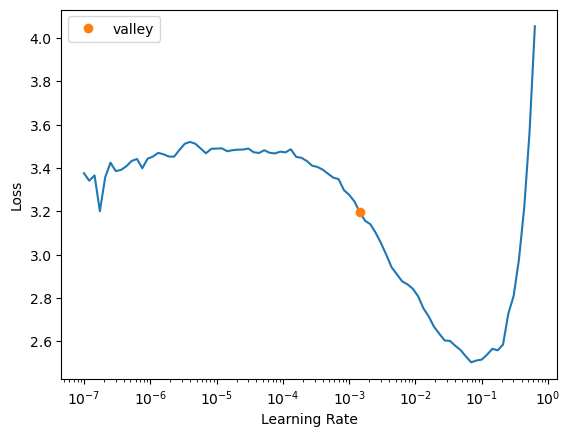

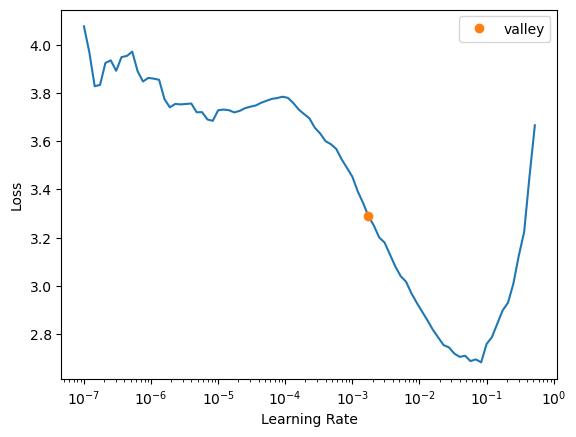

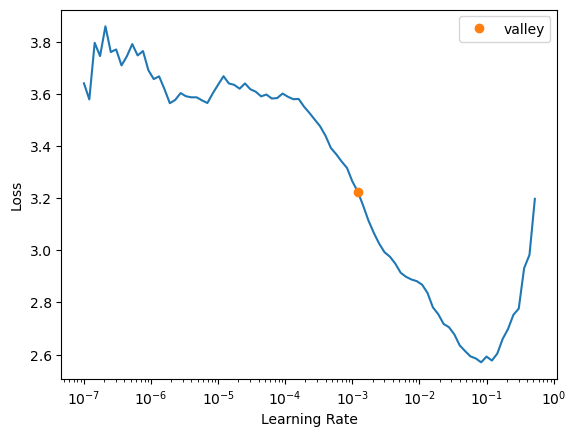

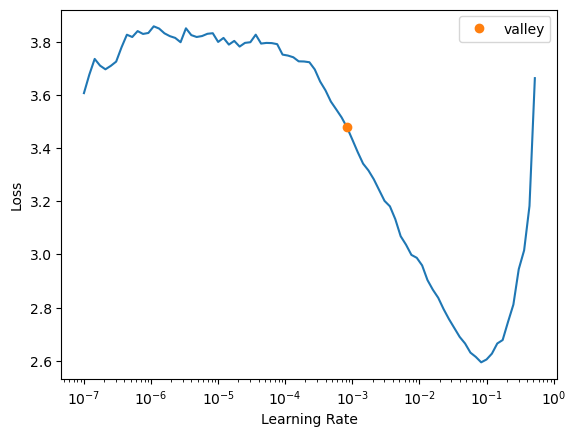

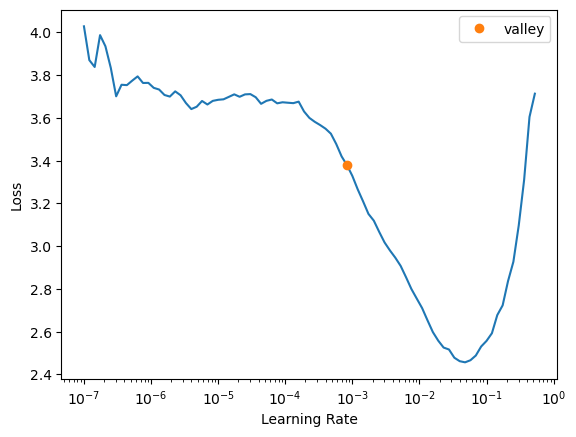

...

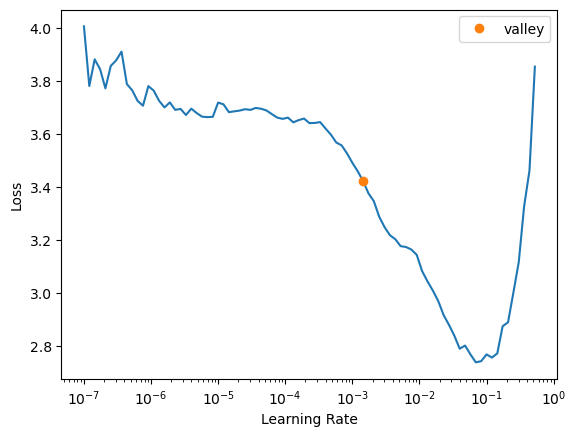

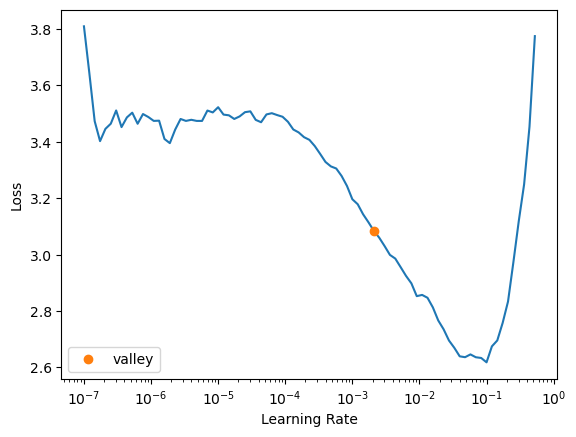

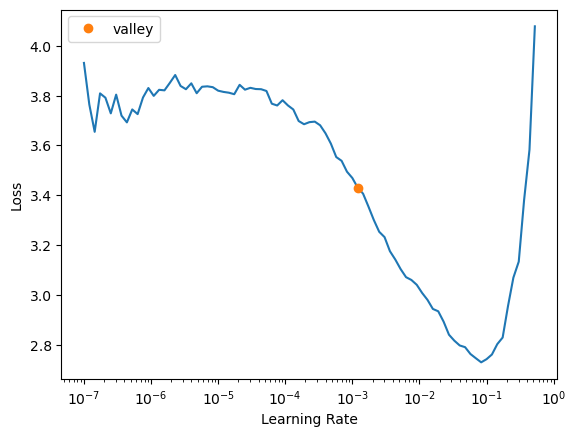

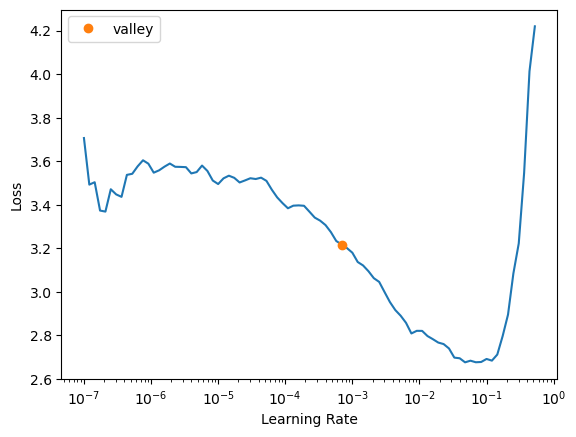

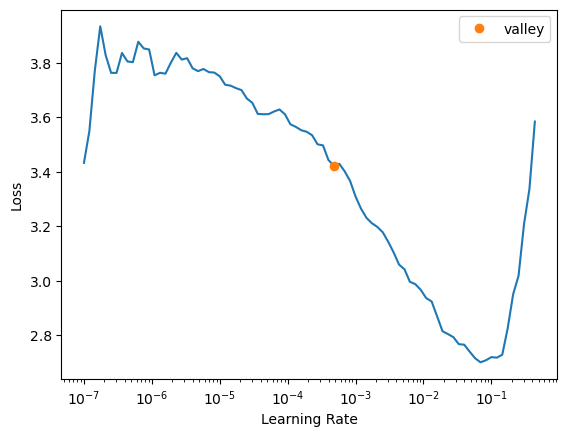

In [47]:
# ============================================================
# STEP 7D : TRAIN ALL CNN MODELS
# ============================================================

import traceback
import pandas as pd

print("=" * 80)
print("STEP 7D : TRAIN ALL CNN MODELS")
print("=" * 80)

# ------------------------------------------------------------
# Model List
# ------------------------------------------------------------

MODEL_LIST = list(MODELS.keys())

print("\nModels to Train:")
for model in MODEL_LIST:
    print(f"  • {model}")

print(f"\nTotal Models : {len(MODEL_LIST)}")
print(f"Runs / Model : {len(RUN_SEEDS)}")
print(f"Total Experiments : {len(MODEL_LIST) * len(RUN_SEEDS)}")

# ------------------------------------------------------------
# Storage
# ------------------------------------------------------------

all_results = []

experiment = 1
total_experiments = len(MODEL_LIST) * len(RUN_SEEDS)

summary_file = MODELS_DIR / "training_summary.csv"

# ------------------------------------------------------------
# Train All Models
# ------------------------------------------------------------

for model_name in MODEL_LIST:

    print("\n" + "=" * 80)
    print(f"MODEL : {model_name}")
    print("=" * 80)

    for run_number in range(1, len(RUN_SEEDS) + 1):

        print("\n" + "-" * 80)
        print(f"Experiment {experiment}/{total_experiments}")
        print(f"Model : {model_name}")
        print(f"Run   : {run_number}")
        print("-" * 80)

        # ----------------------------------------------------
        # Skip already trained models
        # ----------------------------------------------------

        model_file = MODELS_DIR / f"{model_name}_Run{run_number}.pth"

        if model_file.exists():

            print(f"✓ {model_name} Run {run_number} already trained. Skipping.")

            summary = {
                "Model": model_name,
                "Run": run_number,
                "Seed": RUN_SEEDS[run_number-1],
                "Status": "SKIPPED"
            }

            all_results.append(summary)

            experiment += 1
            continue

        # ----------------------------------------------------
        # Train Model
        # ----------------------------------------------------

        try:

            learn, summary = train_model(
                model_name=model_name,
                run_number=run_number
            )

            summary["Status"] = "SUCCESS"

        except Exception as e:

            print("\nERROR OCCURRED")
            traceback.print_exc()

            summary = {
                "Model": model_name,
                "Run": run_number,
                "Seed": RUN_SEEDS[run_number-1],
                "Learning Rate": None,
                "Epochs": TRAINING_CONFIG["epochs"],
                "Image Size": MODELS[model_name]["img_size"],
                "Batch Size": MODELS[model_name]["batch_size"],
                "Training Time (min)": None,
                "Status": "FAILED",
                "Error": str(e)
            }

        all_results.append(summary)

        # ----------------------------------------------------
        # Save progress after every run
        # ----------------------------------------------------

        pd.DataFrame(all_results).to_csv(
            summary_file,
            index=False
        )

        experiment += 1

# ------------------------------------------------------------
# Final Results
# ------------------------------------------------------------

results_df = pd.DataFrame(all_results)

print("\n")
print("=" * 80)
print("TRAINING COMPLETED")
print("=" * 80)

print(results_df)

print("\n")

print(results_df.groupby("Model")["Status"].value_counts())

print(f"\nTraining summary saved to:")
print(summary_file)

In [48]:
print(results_df.groupby("Model")["Status"].value_counts())

Model            Status 
DenseNet121      SUCCESS    5
EfficientNet_B0  SUCCESS    5
EfficientNet_B1  SUCCESS    5
MobileNetV3      SUCCESS    5
ResNet50         SUCCESS    4
                 SKIPPED    1
Name: count, dtype: int64


In [50]:
# Show all path-related variables currently in memory

for name, value in globals().items():
    if any(x in name.upper() for x in ["PATH", "DIR", "DATA", "OUTPUT", "MODEL"]):
        print(f"{name} = {value}")

is_data_frame = <function is_data_frame at 0x000001657AB89DA0>
dataframe_columns = <function dataframe_columns at 0x0000016503190A40>
dataframe_hash = <function dataframe_hash at 0x00000165674EAFC0>
get_dataframes = <function get_dataframes at 0x00000165674E85E0>
models = <module 'fastai.vision.models' from 'C:\\Users\\Frontech\\anaconda3\\Lib\\site-packages\\fastai\\vision\\models\\__init__.py'>
redirect_stdout = <class 'contextlib.redirect_stdout'>
Path = <class 'pathlib._local.Path'>
working_directory = <function working_directory at 0x000001655C996700>
custom_dir = <function custom_dir at 0x000001655C94E8E0>
mkdir = <function mkdir at 0x000001655C9B5A80>
untar_dir = <function untar_dir at 0x000001655C9B62A0>
join_path_file = <function join_path_file at 0x000001655C9D44A0>
dataclass_src = <function dataclass_src at 0x000001655C9D5300>
HTTP421MisdirectedRequestError = <class 'fastcore.net.HTTP421MisdirectedRequestError'>
IterableDataset = <class 'torch.utils.data.dataset.IterableData

In [25]:
# ============================================================
# STEP 8A : CONFIGURATION FOR TEST EVALUATION
# ============================================================

from pathlib import Path
import os
import time
import numpy as np
import pandas as pd

from fastai.vision.all import *

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report,
    cohen_kappa_score,
    matthews_corrcoef,
    roc_auc_score,
    log_loss
)

print("=" * 80)
print("STEP 8A : CONFIGURATION FOR TEST EVALUATION")
print("=" * 80)

# ------------------------------------------------------------
# Project Paths
# ------------------------------------------------------------

PROJECT_DIR = Path(
    r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2"
)

# Dataset
FIXED_SPLIT_DIR = PROJECT_DIR / "Fixed_Split"
TRAINVAL_DIR    = FIXED_SPLIT_DIR / "TrainVal"
TEST_DIR        = FIXED_SPLIT_DIR / "Test"

# Benchmark Root
BENCHMARK_RESULTS_DIR = PROJECT_DIR / "Benchmark_Results"

# CNN Benchmark Directories
CNN_RESULTS_DIR = BENCHMARK_RESULTS_DIR / "CNN_Results"

MODELS_DIR   = CNN_RESULTS_DIR / "Saved_Models"
LOGS_DIR     = CNN_RESULTS_DIR / "Training_Logs"
RESULTS_DIR  = CNN_RESULTS_DIR / "Evaluation"
FIGURES_DIR  = CNN_RESULTS_DIR / "Figures"

# Evaluation Directories
CONFUSION_DIR = RESULTS_DIR / "Confusion_Matrices"
ROC_DIR       = RESULTS_DIR / "ROC_Curves"
PREDICTION_DIR = RESULTS_DIR / "Prediction_Analysis"
CONFIDENCE_DIR = RESULTS_DIR / "Confidence_Analysis"
SUMMARY_DIR = RESULTS_DIR / "Summary"

# Create folders if they do not exist
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
CONFUSION_DIR.mkdir(parents=True, exist_ok=True)
ROC_DIR.mkdir(parents=True, exist_ok=True)
PREDICTION_DIR.mkdir(parents=True, exist_ok=True)
CONFIDENCE_DIR.mkdir(parents=True, exist_ok=True)
SUMMARY_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


print("\nDirectories")
print(f"Project Folder        : {PROJECT_DIR}")
print(f"Dataset Folder        : {FIXED_SPLIT_DIR}")
print(f"Train Folder          : {TRAINVAL_DIR}")
print(f"Test Folder           : {TEST_DIR}")
print(f"CNN Results Folder    : {CNN_RESULTS_DIR}")
print(f"Models Folder         : {MODELS_DIR}")
print(f"Logs Folder           : {LOGS_DIR}")
print(f"Figures Folder        : {FIGURES_DIR}")
print(f"Evaluation Folder     : {RESULTS_DIR}")

# ------------------------------------------------------------
# Classes
# ------------------------------------------------------------

classes = sorted(
    [
        x.name
        for x in TEST_DIR.iterdir()
        if x.is_dir()
    ]
)

NUM_CLASSES = len(classes)

print("\nClasses")

for i, c in enumerate(classes):
    print(f"{i:2d} : {c}")

print(f"\nTotal Classes : {NUM_CLASSES}")

# ------------------------------------------------------------
# Create Test DataLoader
# ------------------------------------------------------------

def create_test_dls(model_name):

    cfg = MODELS[model_name]

    img_size = cfg["img_size"]
    batch_size = cfg["batch_size"]

    dls = ImageDataLoaders.from_folder(
        FIXED_SPLIT_DIR,
        train="TrainVal",
        valid="Test",
        valid_pct=None,
        seed=42,
        item_tfms=Resize(img_size),
        batch_tfms=Normalize.from_stats(*imagenet_stats),
        bs=batch_size,
        shuffle=False,
    )

    return dls

print("\n✓ Test DataLoader function created")

# ------------------------------------------------------------
# Parameter Counting
# ------------------------------------------------------------

def count_parameters(model):
    return sum(p.numel() for p in model.parameters())


def count_trainable_parameters(model):
    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

print("✓ Parameter counting functions created")

# ------------------------------------------------------------
# Output Files
# ------------------------------------------------------------

MASTER_RESULTS_FILE = RESULTS_DIR / "cnn_test_results.csv"
SUMMARY_RESULTS_FILE = RESULTS_DIR / "cnn_summary_statistics.csv"


print("\nOutput Files")
print(MASTER_RESULTS_FILE)
print(SUMMARY_RESULTS_FILE)

if MASTER_RESULTS_FILE.exists():
    print("✓ Existing master results found.")

if SUMMARY_RESULTS_FILE.exists():
    print("✓ Existing summary statistics found.")

print("\n" + "=" * 80)
print("STEP 8A COMPLETED SUCCESSFULLY")
print("=" * 80)

STEP 8A : CONFIGURATION FOR TEST EVALUATION

Directories
Project Folder        : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2
Dataset Folder        : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split
Train Folder          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\TrainVal
Test Folder           : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test
CNN Results Folder    : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results
Models Folder         : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Saved_Models
Logs Folder           : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Training_Logs
Figures Folder        : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmar

In [18]:
print(TEST_DIR)

list(TEST_DIR.iterdir())

C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test


[Path('C:/Users/Frontech/Desktop/Codes/Combined Data set/New Test/Benchmark_v2/Fixed_Split/Test/BSS'),
 Path('C:/Users/Frontech/Desktop/Codes/Combined Data set/New Test/Benchmark_v2/Fixed_Split/Test/CL'),
 Path('C:/Users/Frontech/Desktop/Codes/Combined Data set/New Test/Benchmark_v2/Fixed_Split/Test/FS'),
 Path('C:/Users/Frontech/Desktop/Codes/Combined Data set/New Test/Benchmark_v2/Fixed_Split/Test/HBCS'),
 Path('C:/Users/Frontech/Desktop/Codes/Combined Data set/New Test/Benchmark_v2/Fixed_Split/Test/HCS'),
 Path('C:/Users/Frontech/Desktop/Codes/Combined Data set/New Test/Benchmark_v2/Fixed_Split/Test/PCS'),
 Path('C:/Users/Frontech/Desktop/Codes/Combined Data set/New Test/Benchmark_v2/Fixed_Split/Test/PL'),
 Path('C:/Users/Frontech/Desktop/Codes/Combined Data set/New Test/Benchmark_v2/Fixed_Split/Test/RM'),
 Path('C:/Users/Frontech/Desktop/Codes/Combined Data set/New Test/Benchmark_v2/Fixed_Split/Test/TCS')]

In [95]:
# Test Evaluation

result = evaluate_model("DenseNet121", 2)

print(result.keys())

Evaluating : DenseNet121 | Run 2

Loading Model : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Saved_Models\DenseNet121_Run2.pkl
Number of Classes : 9
Classes : ['BSS', 'CL', 'FS', 'HBCS', 'HCS', 'PCS', 'PL', 'RM', 'TCS']

Loaded : DenseNet121_Run2.pkl



Images Evaluated : 224
Total Inference : 11.002 sec
Per Image       : 0.049118 sec
dict_keys(['model_name', 'run', 'learner', 'y_true', 'y_pred', 'y_prob', 'classes', 'class_to_idx', 'idx_to_class', 'test_files', 'test_paths', 'total_parameters', 'trainable_parameters', 'total_inference_time', 'average_inference_time'])


In [26]:
# ============================================================
# STEP 8B : EVALUATE A SINGLE TRAINED MODEL
# ============================================================

def evaluate_model(model_name, run_number):

    print("="*80)
    print(f"Evaluating : {model_name} | Run {run_number}")
    print("="*80)

    # --------------------------------------------------------
    # Load corresponding DataLoader
    # --------------------------------------------------------

    dls = create_test_dls(model_name)

    # --------------------------------------------------------
    # Load learner
    # --------------------------------------------------------

    learner_path = MODELS_DIR / f"{model_name}_Run{run_number}.pkl"
    print(f"\nLoading Model : {learner_path}")

    if not learner_path.exists():
        raise FileNotFoundError(f"\nModel not found:\n{learner_path}")

    learn = load_learner(learner_path)

    # attach correct dataloaders
    learn.dls = dls
    print(f"Number of Classes : {len(dls.vocab)}")
    print("Classes :", dls.vocab)
    print(f"\nLoaded : {learner_path.name}")

    # --------------------------------------------------------
    # Parameter counts
    # --------------------------------------------------------

    total_params = count_parameters(learn.model)
    trainable_params = count_trainable_parameters(learn.model)

    # --------------------------------------------------------
    # Test predictions
    # --------------------------------------------------------

    start = time.time()

    probs, targets = learn.get_preds(dl=dls.valid)

    inference_time = time.time() - start

    preds = probs.argmax(dim=1)

    # --------------------------------------------------------
    # Convert to numpy
    # --------------------------------------------------------

    y_true = targets.cpu().numpy()

    y_pred = preds.cpu().numpy()

    y_prob = probs.cpu().numpy()

    class_to_idx = {c:i for i,c in enumerate(dls.vocab)}

    idx_to_class = {i:c for c,i in class_to_idx.items()}

    # --------------------------------------------------------
    # Average inference time
    # --------------------------------------------------------

    total_images = len(y_true)

    avg_time = inference_time / total_images

    print(f"\nImages Evaluated : {total_images}")
    print(f"Total Inference : {inference_time:.3f} sec")
    print(f"Per Image       : {avg_time:.6f} sec")

    # --------------------------------------------------------
    # Test image filenames
    # --------------------------------------------------------
    
    from pathlib import Path
    
    test_files = [Path(x).name for x in dls.valid.items]
    
    test_paths = [str(x) for x in dls.valid.items]
    # --------------------------------------------------------
    # Return everything
    # --------------------------------------------------------

    return {
    
        "model_name": model_name,
    
        "run": run_number,
    
        "learner": learn,
    
        "y_true": y_true,
    
        "y_pred": y_pred,
    
        "y_prob": y_prob,
    
        "classes": dls.vocab,
    
        "class_to_idx": class_to_idx,
    
        "idx_to_class": idx_to_class,
    
        "test_files": test_files,
    
        "test_paths": test_paths,
    
        "total_parameters": total_params,
    
        "trainable_parameters": trainable_params,
    
        "total_inference_time": inference_time,
    
        "average_inference_time": avg_time,
    
    }

print("="*80)
print("STEP 8B READY")
print("="*80)

STEP 8B READY


In [56]:
# ============================================================
# STEP 8C : COMPUTE CLASSIFICATION METRICS
# ============================================================

def compute_metrics(result):

    print("="*80)
    print(f"Computing Metrics : {result['model_name']} | Run {result['run']}")
    print("="*80)

    y_true = result["y_true"]
    y_pred = result["y_pred"]
    y_prob = result["y_prob"]

    # --------------------------------------------------------
    # Overall Metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(y_true, y_pred)

    precision_macro = precision_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    recall_macro = recall_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    f1_macro = f1_score(
        y_true, y_pred,
        average="macro",
        zero_division=0
    )

    precision_weighted = precision_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )

    recall_weighted = recall_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )

    f1_weighted = f1_score(
        y_true, y_pred,
        average="weighted",
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_true,
        y_pred
    )

    kappa = cohen_kappa_score(
        y_true,
        y_pred
    )

    mcc = matthews_corrcoef(
        y_true,
        y_pred
    )

    # --------------------------------------------------------
    # Log Loss
    # --------------------------------------------------------

    try:
        loss = log_loss(y_true, y_prob)

    except:
        loss = np.nan

    # --------------------------------------------------------
    # Per-Class Metrics
    # --------------------------------------------------------

    report = classification_report(
        y_true,
        y_pred,
        target_names=result["classes"],
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).transpose()

    # --------------------------------------------------------
    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------
    
    metrics = {
    
        "Model": result["model_name"],
        "Run": result["run"],
    
        "Accuracy": accuracy,
    
        "Precision_Macro": precision_macro,
        "Recall_Macro": recall_macro,
        "F1_Macro": f1_macro,
    
        "Precision_Weighted": precision_weighted,
        "Recall_Weighted": recall_weighted,
        "F1_Weighted": f1_weighted,
    
        "Balanced_Accuracy": balanced_acc,
    
        "Cohen_Kappa": kappa,
        "MCC": mcc,
        "Log_Loss": loss,
    
        "Parameters": result["total_parameters"],
        "Trainable_Parameters": result["trainable_parameters"],
    
        "Inference_Time_Total": result["total_inference_time"],
        "Inference_Time_Per_Image": result["average_inference_time"]
    
    }
    
    # Store inside result
    result["metrics"] = metrics
    result["classification_report"] = report_df
    print("\nOverall Performance")
    print("-"*50)

    print(f"Accuracy              : {accuracy:.4f}")
    print(f"Precision (Macro)     : {precision_macro:.4f}")
    print(f"Recall (Macro)        : {recall_macro:.4f}")
    print(f"F1 Score (Macro)      : {f1_macro:.4f}")

    print(f"Precision (Weighted)  : {precision_weighted:.4f}")
    print(f"Recall (Weighted)     : {recall_weighted:.4f}")
    print(f"F1 Score (Weighted)   : {f1_weighted:.4f}")

    print(f"Balanced Accuracy     : {balanced_acc:.4f}")
    print(f"Cohen Kappa           : {kappa:.4f}")
    print(f"MCC                   : {mcc:.4f}")
    print(f"Log Loss              : {loss:.4f}")

    print("="*80)

    return result

print("="*80)
print("STEP 8C READY")
print("="*80)

STEP 8C READY


In [79]:
result = compute_metrics(result)

print(result.keys())

Computing Metrics : DenseNet121 | Run 2

Overall Performance
--------------------------------------------------
Accuracy              : 0.7500
Precision (Macro)     : 0.7569
Recall (Macro)        : 0.7325
F1 Score (Macro)      : 0.7400
Precision (Weighted)  : 0.7519
Recall (Weighted)     : 0.7500
F1 Score (Weighted)   : 0.7473
Balanced Accuracy     : 0.7325
Cohen Kappa           : 0.7146
MCC                   : 0.7153
Log Loss              : 0.8288
dict_keys(['model_name', 'run', 'learner', 'y_true', 'y_pred', 'y_prob', 'classes', 'class_to_idx', 'idx_to_class', 'test_files', 'test_paths', 'total_parameters', 'trainable_parameters', 'total_inference_time', 'average_inference_time', 'prediction_table', 'prediction_csv', 'prediction_summary', 'best_predictions', 'weakest_correct_predictions', 'dangerous_predictions', 'uncertain_predictions', 'confidence_summary', 'confidence_correctness', 'high_confidence_wrong', 'low_confidence_correct', 'classwise_confidence', 'classwise_misclassificat

In [57]:
# ============================================================
# STEP 8D : CONFUSION MATRIX
# ============================================================

import matplotlib.pyplot as plt
import seaborn as sns

def plot_confusion_matrix(result):

    print("="*80)
    print(f"Confusion Matrix : {result['model_name']} | Run {result['run']}")
    print("="*80)

    y_true = result["y_true"]
    y_pred = result["y_pred"]
    classes = result["classes"]

    # --------------------------------------------------------
    # Compute confusion matrices
    # --------------------------------------------------------

    cm = confusion_matrix(y_true, y_pred)
    misclassified_pairs = []
    
    for i in range(len(classes)):
        for j in range(len(classes)):
            if i != j and cm[i, j] > 0:
                misclassified_pairs.append({
                    "True_Class": classes[i],
                    "Predicted_Class": classes[j],
                    "Count": cm[i, j]
                })
    
    misclassified_df = pd.DataFrame(misclassified_pairs)
    
    if not misclassified_df.empty:
        misclassified_df = misclassified_df.sort_values(
            "Count",
            ascending=False
        )
    
    misclassified_df.to_csv(
        CONFUSION_DIR /
        f"{result['model_name']}_Run{result['run']}_Most_Confused_Classes.csv",
        index=False
    )
    cm_norm = confusion_matrix(
        y_true,
        y_pred,
        normalize="true"
    )

    # --------------------------------------------------------
    # Save CSV files
    # --------------------------------------------------------

    cm_df = pd.DataFrame(
        cm,
        index=classes,
        columns=classes
    )

    cm_norm_df = pd.DataFrame(
        cm_norm,
        index=classes,
        columns=classes
    )

    raw_csv = CONFUSION_DIR / f"{result['model_name']}_Run{result['run']}_Raw.csv"

    norm_csv = CONFUSION_DIR / f"{result['model_name']}_Run{result['run']}_Normalized.csv"

    cm_df.to_csv(raw_csv)

    cm_norm_df.to_csv(norm_csv)

    # --------------------------------------------------------
    # Plot Raw Confusion Matrix
    # --------------------------------------------------------

    plt.figure(figsize=(12,10))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=classes,
        yticklabels=classes,
        linewidths=0.5,
        linecolor="black",
        square=True,
        cbar=True,
        annot_kws={
            "size": 12,
            "weight": "bold"
        }
    )
    
    plt.xlabel("Predicted Class", fontsize=16, fontweight="bold")
    plt.ylabel("True Class", fontsize=16, fontweight="bold")
    plt.title(
        f"{result['model_name']} - Run {result['run']}\nRaw Confusion Matrix",
        fontsize=18,
        fontweight="bold",
        pad=20
    )
    
    plt.xticks(rotation=45, ha="right", fontsize=13)
    plt.yticks(rotation=0, fontsize=13)

    raw_png = CONFUSION_DIR / f"{result['model_name']}_Run{result['run']}_Raw.png"

    plt.tight_layout()
    plt.savefig(raw_png, dpi=300, bbox_inches="tight")
    plt.show()

    # --------------------------------------------------------
    # Plot Normalized Confusion Matrix
    # --------------------------------------------------------

    plt.figure(figsize=(12,10))

    sns.heatmap(
        cm_norm,
        annot=True,
        fmt=".2f",
        cmap="Blues",
        xticklabels=classes,
        yticklabels=classes,
        linewidths=0.5,
        linecolor="black",
        vmin=0,
        vmax=1,
        square=True,
        annot_kws={
            "size": 12,
            "weight": "bold"
        },
        cbar_kws={
            "label": "Normalized Accuracy"
        }
    )

    plt.xlabel("Predicted Class", fontsize=16, fontweight="bold")
    plt.ylabel("True Class", fontsize=16, fontweight="bold")
    plt.title(
        f"{result['model_name']} - Run {result['run']}\nNormalized Confusion Matrix",
        fontsize=18,
        fontweight="bold",
        pad=20
    )
    
    plt.xticks(rotation=45, ha="right", fontsize=13)
    plt.yticks(rotation=0, fontsize=13)

    norm_png = CONFUSION_DIR / f"{result['model_name']}_Run{result['run']}_Normalized.png"

    plt.tight_layout()
    plt.savefig(norm_png, dpi=300, bbox_inches="tight")
    plt.show()

    print("\n✓ Confusion matrices saved successfully")

    result["confusion_matrix"] = cm
    result["normalized_confusion_matrix"] = cm_norm
    result["misclassified_pairs"] = misclassified_df
    return {
    "raw_confusion": cm_df,
    "normalized_confusion": cm_norm_df,
    "misclassified_pairs": misclassified_df
}

print("="*80)
print("STEP 8D READY")
print("="*80)

STEP 8D READY


Evaluating : DenseNet121 | Run 2

Loading Model : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Saved_Models\DenseNet121_Run2.pkl
Number of Classes : 9
Classes : ['BSS', 'CL', 'FS', 'HBCS', 'HCS', 'PCS', 'PL', 'RM', 'TCS']

Loaded : DenseNet121_Run2.pkl



Images Evaluated : 224
Total Inference : 11.007 sec
Per Image       : 0.049140 sec
Confusion Matrix : DenseNet121 | Run 2


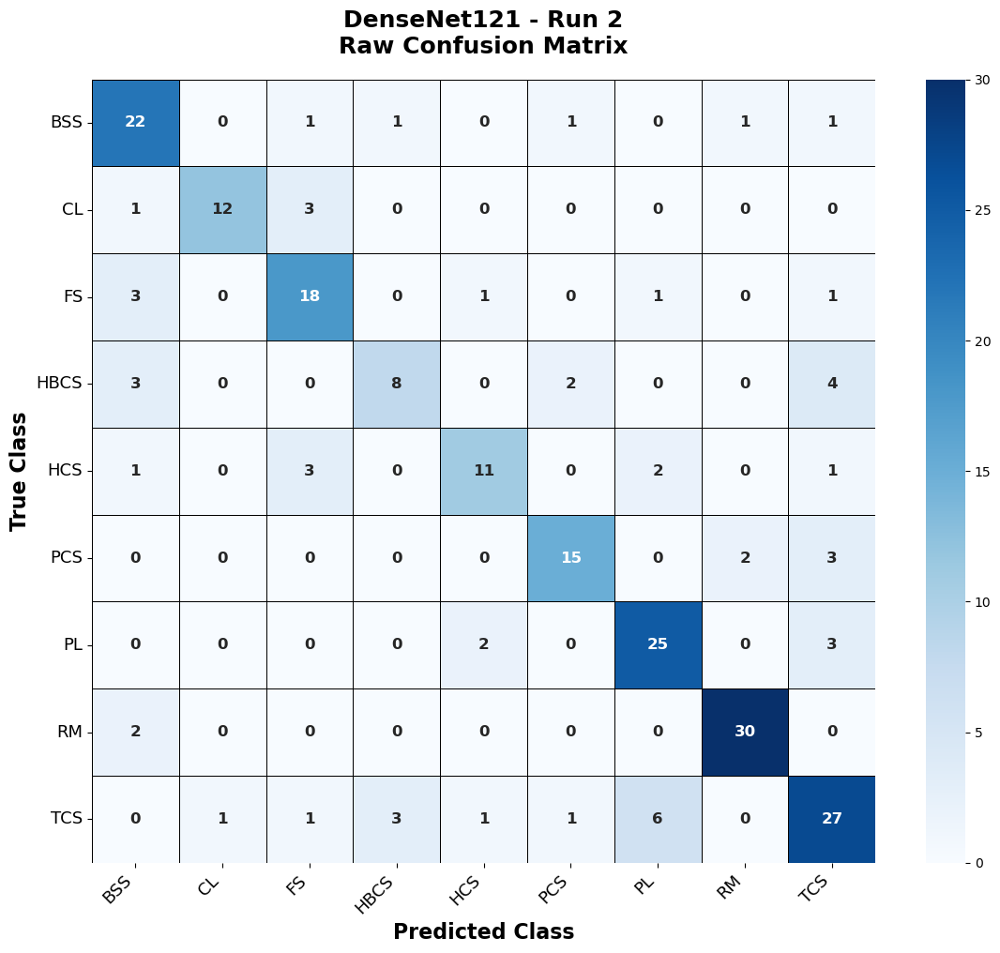

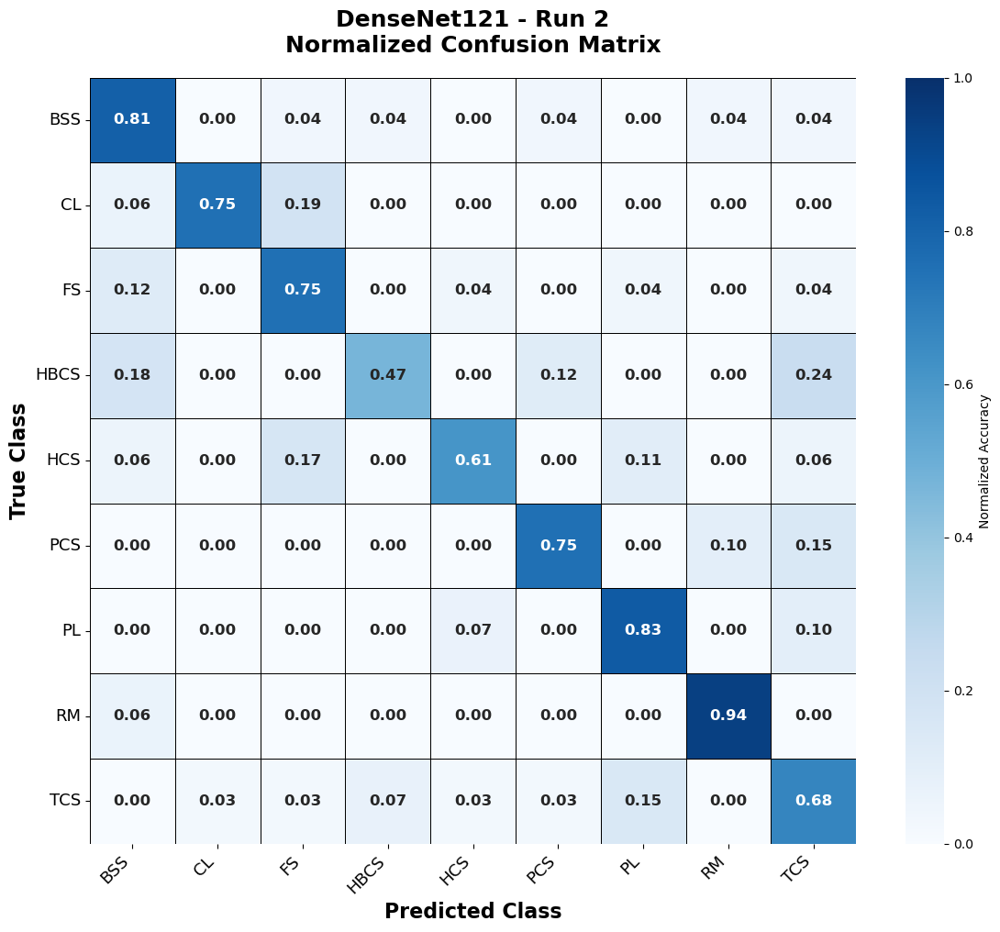


✓ Confusion matrices saved successfully

Step 8D executed successfully!

Stored in result dictionary:
dict_keys(['model_name', 'run', 'learner', 'y_true', 'y_pred', 'y_prob', 'classes', 'class_to_idx', 'idx_to_class', 'test_files', 'test_paths', 'total_parameters', 'trainable_parameters', 'total_inference_time', 'average_inference_time', 'confusion_matrix', 'normalized_confusion_matrix', 'misclassified_pairs'])

Top Confused Class Pairs:
   True_Class Predicted_Class  Count
28        TCS              PL      6
13       HBCS             TCS      4
11       HBCS             BSS      3
7          FS             BSS      3
6          CL              FS      3
15        HCS              FS      3
19        PCS             TCS      3
25        TCS            HBCS      3
21         PL             TCS      3
16        HCS              PL      2


In [58]:
# ============================================================
# TEST STEP 8D
# ============================================================

# Replace with any model you have
model_name = "DenseNet121"
run_number = 2

# Evaluate model
result = evaluate_model(model_name, run_number)

# Plot confusion matrices
cm_results = plot_confusion_matrix(result)

print("\nStep 8D executed successfully!")

print("\nStored in result dictionary:")
print(result.keys())

print("\nTop Confused Class Pairs:")

if not result["misclassified_pairs"].empty:
    print(result["misclassified_pairs"].head(10))
else:
    print("No misclassified class pairs.")

In [59]:
# ============================================================
# STEP 8E-1 : BUILD PREDICTION TABLE
# ============================================================

def build_prediction_table(result):

    print("=" * 80)
    print(f"Prediction Table : {result['model_name']} | Run {result['run']}")
    print("=" * 80)

    # --------------------------------------------------------
    # Extract prediction results
    # --------------------------------------------------------

    y_true = result["y_true"]
    y_pred = result["y_pred"]
    y_prob = result["y_prob"]

    classes = result["classes"]

    image_names = result["test_files"]
    image_paths = result["test_paths"]

    model_name = result["model_name"]
    run_number = result["run"]

    # --------------------------------------------------------
    # Initialize prediction table
    # --------------------------------------------------------

    prediction_rows = []

    # --------------------------------------------------------
    # Process every test image
    # --------------------------------------------------------

    for i in range(len(y_true)):

        probs = y_prob[i]

        # Top-1 prediction
        top1_idx = np.argmax(probs)
        top1_prob = probs[top1_idx]

        # Top-2 prediction
        sorted_idx = np.argsort(probs)[::-1]

        top2_idx = sorted_idx[1]
        top2_prob = probs[top2_idx]

        # True class probability
        true_prob = probs[y_true[i]]

        # Confidence margin
        margin = top1_prob - top2_prob

        prediction_rows.append({

            "Model": model_name,

            "Run": run_number,

            "Image_Name": image_names[i],

            "Image_Path": image_paths[i],

            "True_Index": int(y_true[i]),

            "Predicted_Index": int(y_pred[i]),

            "True_Class": classes[y_true[i]],

            "Predicted_Class": classes[y_pred[i]],

            "Correct": y_true[i] == y_pred[i],

            "Prediction_Probability": float(top1_prob),

            "True_Class_Probability": float(true_prob),

            "Second_Best_Class": classes[top2_idx],

            "Second_Best_Probability": float(top2_prob),

            "Confidence_Margin": float(margin)

        })

    # --------------------------------------------------------
    # Create DataFrame
    # --------------------------------------------------------

    prediction_df = pd.DataFrame(prediction_rows)

    # --------------------------------------------------------
    # Rank by confidence
    # --------------------------------------------------------

    prediction_df = prediction_df.sort_values(
        by="Prediction_Probability",
        ascending=False
    ).reset_index(drop=True)

    prediction_df.insert(
        0,
        "Confidence_Rank",
        np.arange(1, len(prediction_df) + 1)
    )

    # --------------------------------------------------------
    # Store in result dictionary
    # --------------------------------------------------------

    result["prediction_table"] = prediction_df

    print(f"\nPrediction Table Created Successfully")
    print(f"Total Predictions : {len(prediction_df)}")

    return prediction_df


print("=" * 80)
print("STEP 8E-1 READY")
print("=" * 80)

STEP 8E-1 READY


In [60]:
# ============================================================
# TEST STEP 8E-1
# ============================================================

model_name = "DenseNet121"
run_number = 2

result = evaluate_model(model_name, run_number)

prediction_df = build_prediction_table(result)

prediction_df.head(10)

Evaluating : DenseNet121 | Run 2

Loading Model : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Saved_Models\DenseNet121_Run2.pkl
Number of Classes : 9
Classes : ['BSS', 'CL', 'FS', 'HBCS', 'HCS', 'PCS', 'PL', 'RM', 'TCS']

Loaded : DenseNet121_Run2.pkl



Images Evaluated : 224
Total Inference : 10.187 sec
Per Image       : 0.045477 sec
Prediction Table : DenseNet121 | Run 2

Prediction Table Created Successfully
Total Predictions : 224


,Confidence_Rank,Model,Run,Image_Name,Image_Path,True_Index,Predicted_Index,True_Class,Predicted_Class,Correct,Prediction_Probability,True_Class_Probability,Second_Best_Class,Second_Best_Probability,Confidence_Margin
0,1,DenseNet121,2,PL88.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\PL\PL88.png,6,6,PL,PL,True,0.999997,0.999997,PCS,0.000001,0.999996
1,2,DenseNet121,2,PL109.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\PL\PL109.png,6,6,PL,PL,True,0.999995,0.999995,HCS,0.000003,0.999992
2,3,DenseNet121,2,RM117.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\RM\RM117.png,7,7,RM,RM,True,0.999995,0.999995,BSS,0.000005,0.999990
3,4,DenseNet121,2,RM115.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\RM\RM115.png,7,7,RM,RM,True,0.999992,0.999992,FS,0.000006,0.999986
4,5,DenseNet121,2,PL205.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\PL\PL205.png,6,6,PL,PL,True,0.999988,0.999988,HCS,0.000009,0.999979
5,6,DenseNet121,2,RM219.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\RM\RM219.png,7,7,RM,RM,True,0.999986,0.999986,FS,0.000011,0.999975
6,7,DenseNet121,2,PL114.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\PL\PL114.png,6,6,PL,PL,True,0.999978,0.999978,HCS,0.000010,0.999968
7,8,DenseNet121,2,PL235.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\PL\PL235.png,6,6,PL,PL,True,0.999977,0.999977,BSS,0.000010,0.999966
8,9,DenseNet121,2,PL116.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\PL\PL116.png,6,6,PL,PL,True,0.999940,0.999940,HCS,0.000040,0.999900
9,10,DenseNet121,2,PCS100.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\PCS\PCS100.png,5,5,PCS,PCS,True,0.999935,0.999935,PL,0.000053,0.999882


In [61]:
# ============================================================
# STEP 8E-2 : SAVE PREDICTION TABLE
# ============================================================

def save_prediction_table(result):

    print("=" * 80)
    print(f"Saving Prediction Table : {result['model_name']} | Run {result['run']}")
    print("=" * 80)

    # --------------------------------------------------------
    # Retrieve Prediction Table
    # --------------------------------------------------------

    prediction_df = result["prediction_table"]

    model_name = result["model_name"]
    run_number = result["run"]

    # --------------------------------------------------------
    # Create Output Filename
    # --------------------------------------------------------

    csv_filename = f"{model_name}_Run{run_number}_Predictions.csv"

    csv_path = PREDICTION_DIR / csv_filename

    # --------------------------------------------------------
    # Save CSV
    # --------------------------------------------------------

    prediction_df.to_csv(csv_path, index=False)

    # --------------------------------------------------------
    # Store Path in Result Dictionary
    # --------------------------------------------------------

    result["prediction_csv"] = csv_path

    # --------------------------------------------------------
    # Display Information
    # --------------------------------------------------------

    print("\nPrediction Table Saved Successfully")
    print(f"Location : {csv_path}")
    print(f"Rows Saved : {len(prediction_df)}")

    return csv_path


print("=" * 80)
print("STEP 8E-2 READY")
print("=" * 80)

STEP 8E-2 READY


In [62]:
# ============================================================
# TEST STEP 8E-2
# ============================================================

prediction_df = build_prediction_table(result)

csv_path = save_prediction_table(result)

Prediction Table : DenseNet121 | Run 2

Prediction Table Created Successfully
Total Predictions : 224
Saving Prediction Table : DenseNet121 | Run 2

Prediction Table Saved Successfully
Location : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\CNN_Results\Evaluation\Prediction_Analysis\DenseNet121_Run2_Predictions.csv
Rows Saved : 224


In [63]:
# ============================================================
# STEP 8E-3 : PREDICTION SUMMARY
# ============================================================

def prediction_summary(result):

    print("=" * 80)
    print(f"Prediction Summary : {result['model_name']} | Run {result['run']}")
    print("=" * 80)

    # --------------------------------------------------------
    # Load Prediction Table
    # --------------------------------------------------------

    prediction_df = result["prediction_table"]

    # --------------------------------------------------------
    # Basic Statistics
    # --------------------------------------------------------

    total_images = len(prediction_df)

    correct_predictions = prediction_df["Correct"].sum()

    incorrect_predictions = total_images - correct_predictions

    accuracy = (correct_predictions / total_images) * 100

    # --------------------------------------------------------
    # Confidence Statistics
    # --------------------------------------------------------

    avg_confidence = (
        prediction_df["Prediction_Probability"].mean() * 100
    )

    avg_true_probability = (
        prediction_df["True_Class_Probability"].mean() * 100
    )

    avg_margin = (
        prediction_df["Confidence_Margin"].mean() * 100
    )

    # --------------------------------------------------------
    # Correct / Incorrect Confidence
    # --------------------------------------------------------

    correct_df = prediction_df[prediction_df["Correct"]]

    incorrect_df = prediction_df[~prediction_df["Correct"]]

    correct_confidence = (
        correct_df["Prediction_Probability"].mean() * 100
        if len(correct_df) > 0 else 0
    )

    incorrect_confidence = (
        incorrect_df["Prediction_Probability"].mean() * 100
        if len(incorrect_df) > 0 else 0
    )

    # --------------------------------------------------------
    # Build Summary
    # --------------------------------------------------------

    summary = {

        "Model": result["model_name"],

        "Run": result["run"],

        "Total Images": total_images,

        "Correct Predictions": int(correct_predictions),

        "Incorrect Predictions": int(incorrect_predictions),

        "Accuracy (%)": round(accuracy, 2),

        "Average Prediction Confidence (%)":
            round(avg_confidence, 2),

        "Average True-Class Probability (%)":
            round(avg_true_probability, 2),

        "Average Confidence Margin (%)":
            round(avg_margin, 2),

        "Correct Prediction Confidence (%)":
            round(correct_confidence, 2),

        "Incorrect Prediction Confidence (%)":
            round(incorrect_confidence, 2)

    }

    summary_df = pd.DataFrame([summary])

    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------

    result["prediction_summary"] = summary_df

    # --------------------------------------------------------
    # Display Summary
    # --------------------------------------------------------

    print(f"Model                         : {result['model_name']}")
    print(f"Run                           : {result['run']}")
    print("-" * 80)
    print(f"Total Images                  : {total_images}")
    print(f"Correct Predictions           : {correct_predictions}")
    print(f"Incorrect Predictions         : {incorrect_predictions}")
    print(f"Accuracy (%)                 : {accuracy:.2f}")
    print("-" * 80)
    print(f"Average Prediction Confidence : {avg_confidence:.2f}%")
    print(f"Average True-Class Probability: {avg_true_probability:.2f}%")
    print(f"Average Confidence Margin     : {avg_margin:.2f}%")
    print("-" * 80)
    print(f"Correct Prediction Confidence : {correct_confidence:.2f}%")
    print(f"Incorrect Prediction Confidence: {incorrect_confidence:.2f}%")

    return summary_df


print("=" * 80)
print("STEP 8E-3 READY")
print("=" * 80)

STEP 8E-3 READY


In [64]:
# Test 8E-3
summary_df = prediction_summary(result)

summary_df

Prediction Summary : DenseNet121 | Run 2
Model                         : DenseNet121
Run                           : 2
--------------------------------------------------------------------------------
Total Images                  : 224
Correct Predictions           : 168
Incorrect Predictions         : 56
Accuracy (%)                 : 75.00
--------------------------------------------------------------------------------
Average Prediction Confidence : 83.23%
Average True-Class Probability: 69.30%
Average Confidence Margin     : 72.52%
--------------------------------------------------------------------------------
Correct Prediction Confidence : 88.33%
Incorrect Prediction Confidence: 67.93%


,Model,Run,Total Images,Correct Predictions,Incorrect Predictions,Accuracy (%),Average Prediction Confidence (%),Average True-Class Probability (%),Average Confidence Margin (%),Correct Prediction Confidence (%),Incorrect Prediction Confidence (%)
0,DenseNet121,2,224,168,56,75.0,83.23,69.3,72.52,88.33,67.93


In [65]:
# ============================================================
# STEP 8E-4 : BEST & WORST PREDICTIONS
# ============================================================

def analyze_predictions(result):

    print("=" * 80)
    print(f"Prediction Analysis : {result['model_name']} | Run {result['run']}")
    print("=" * 80)

    # --------------------------------------------------------
    # Load Prediction Table
    # --------------------------------------------------------

    prediction_df = result["prediction_table"]

    # --------------------------------------------------------
    # Separate Correct and Incorrect Predictions
    # --------------------------------------------------------

    correct_df = prediction_df[
        prediction_df["Correct"] == True
    ].copy()

    incorrect_df = prediction_df[
        prediction_df["Correct"] == False
    ].copy()

    # --------------------------------------------------------
    # Highest Confidence Correct Predictions
    # --------------------------------------------------------

    best_predictions = correct_df.sort_values(
        by="Prediction_Probability",
        ascending=False
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # Lowest Confidence Correct Predictions
    # --------------------------------------------------------

    weakest_correct = correct_df.sort_values(
        by="Prediction_Probability",
        ascending=True
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # Highest Confidence Incorrect Predictions
    # --------------------------------------------------------

    dangerous_predictions = incorrect_df.sort_values(
        by="Prediction_Probability",
        ascending=False
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # Lowest Confidence Incorrect Predictions
    # --------------------------------------------------------

    uncertain_predictions = incorrect_df.sort_values(
        by="Prediction_Probability",
        ascending=True
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------

    result["best_predictions"] = best_predictions

    result["weakest_correct_predictions"] = weakest_correct

    result["dangerous_predictions"] = dangerous_predictions

    result["uncertain_predictions"] = uncertain_predictions

    # --------------------------------------------------------
    # Display Summary
    # --------------------------------------------------------

    print(f"Best Correct Predictions          : {len(best_predictions)}")
    print(f"Weakest Correct Predictions       : {len(weakest_correct)}")
    print(f"High Confidence Wrong Predictions : {len(dangerous_predictions)}")
    print(f"Low Confidence Wrong Predictions  : {len(uncertain_predictions)}")

    return {
        "best_predictions": best_predictions,
        "weakest_correct_predictions": weakest_correct,
        "dangerous_predictions": dangerous_predictions,
        "uncertain_predictions": uncertain_predictions
    }


print("=" * 80)
print("STEP 8E-4 READY")
print("=" * 80)

STEP 8E-4 READY


In [66]:
# Test 8E-4
prediction_analysis = analyze_predictions(result)

prediction_analysis["dangerous_predictions"].head(10)

Prediction Analysis : DenseNet121 | Run 2
Best Correct Predictions          : 168
Weakest Correct Predictions       : 168
High Confidence Wrong Predictions : 56
Low Confidence Wrong Predictions  : 56


,Confidence_Rank,Model,Run,Image_Name,Image_Path,True_Index,Predicted_Index,True_Class,Predicted_Class,Correct,Prediction_Probability,True_Class_Probability,Second_Best_Class,Second_Best_Probability,Confidence_Margin
0,25,DenseNet121,2,HCS23.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\HCS\HCS23.png,4,6,HCS,PL,False,0.999480,0.000059,HBCS,0.000237,0.999243
1,30,DenseNet121,2,TC142.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\TCS\TC142.png,8,6,TCS,PL,False,0.999076,0.000375,TCS,0.000375,0.998701
2,79,DenseNet121,2,CL46.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\CL\CL46.png,1,2,CL,FS,False,0.980461,0.008946,CL,0.008946,0.971515
3,81,DenseNet121,2,HCS74.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\HCS\HCS74.png,4,2,HCS,FS,False,0.978450,0.019983,HCS,0.019983,0.958466
4,83,DenseNet121,2,BSS102.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\BSS\BSS102.png,0,7,BSS,RM,False,0.973699,0.005545,TCS,0.008637,0.965062
5,91,DenseNet121,2,CL54.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\CL\CL54.png,1,2,CL,FS,False,0.965275,0.033070,CL,0.033070,0.932205
6,106,DenseNet121,2,CL42.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\CL\CL42.png,1,0,CL,BSS,False,0.943375,0.019731,CL,0.019731,0.923644
7,111,DenseNet121,2,HCS54.1.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\HCS\HCS54.1.png,4,2,HCS,FS,False,0.936804,0.039124,HCS,0.039124,0.897680
8,120,DenseNet121,2,HBCS1.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\HBCS\HBCS1.png,3,5,HBCS,PCS,False,0.915846,0.018709,TCS,0.064288,0.851558
9,121,DenseNet121,2,TC154.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\TCS\TC154.png,8,3,TCS,HBCS,False,0.911194,0.023911,CL,0.051153,0.860041


In [67]:
# ============================================================
# STEP 8F-1 : CONFIDENCE CATEGORIZATION
# ============================================================

def confidence_analysis(result):

    print("=" * 80)
    print(f"Confidence Analysis : {result['model_name']} | Run {result['run']}")
    print("=" * 80)

    # --------------------------------------------------------
    # Load Prediction Table
    # --------------------------------------------------------

    prediction_df = result["prediction_table"].copy()

    # --------------------------------------------------------
    # Confidence Categorization Function
    # --------------------------------------------------------

    def classify_confidence(prob):

        if prob >= 0.90:
            return "Excellent", "Very High Confidence"

        elif prob >= 0.70:
            return "Good", "High Confidence"

        elif prob >= 0.50:
            return "Average", "Moderate Confidence"

        else:
            return "Poor", "Low Confidence"

    # --------------------------------------------------------
    # Assign Categories
    # --------------------------------------------------------

    categories = prediction_df["Prediction_Probability"].apply(
        classify_confidence
    )

    prediction_df["Confidence_Category"] = [
        c[0] for c in categories
    ]

    prediction_df["Confidence_Level"] = [
        c[1] for c in categories
    ]

    # --------------------------------------------------------
    # Store Updated Table
    # --------------------------------------------------------

    result["prediction_table"] = prediction_df

    # --------------------------------------------------------
    # Category Statistics
    # --------------------------------------------------------

    confidence_summary = (
        prediction_df["Confidence_Category"]
        .value_counts()
        .reindex(
            ["Excellent", "Good", "Average", "Poor"],
            fill_value=0
        )
    )

    confidence_df = confidence_summary.reset_index()

    confidence_df.columns = [
        "Confidence_Category",
        "Number_of_Images"
    ]

    confidence_df["Percentage"] = (
        confidence_df["Number_of_Images"]
        / len(prediction_df)
        * 100
    ).round(2)

    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------

    result["confidence_summary"] = confidence_df

    # --------------------------------------------------------
    # Display Results
    # --------------------------------------------------------

    print("\nConfidence Category Distribution")
    print("-" * 80)

    print(confidence_df)

    return confidence_df


print("=" * 80)
print("STEP 8F-1 READY")
print("=" * 80)

STEP 8F-1 READY


In [68]:
# ============================================================
# TEST STEP 8F-1
# ============================================================

confidence_df = confidence_analysis(result)

confidence_df

Confidence Analysis : DenseNet121 | Run 2

Confidence Category Distribution
--------------------------------------------------------------------------------
  Confidence_Category  Number_of_Images  Percentage
0           Excellent               125       55.80
1                Good                42       18.75
2             Average                36       16.07
3                Poor                21        9.38


,Confidence_Category,Number_of_Images,Percentage
0,Excellent,125,55.80
1,Good,42,18.75
2,Average,36,16.07
3,Poor,21,9.38


In [69]:
# ============================================================
# STEP 8F-2 : CONFIDENCE vs CORRECTNESS ANALYSIS
# ============================================================

def confidence_correctness_analysis(result):

    print("=" * 80)
    print(f"Confidence vs Correctness : {result['model_name']} | Run {result['run']}")
    print("=" * 80)

    # --------------------------------------------------------
    # Load Prediction Table
    # --------------------------------------------------------

    prediction_df = result["prediction_table"].copy()

    confidence_order = [
        "Excellent",
        "Good",
        "Average",
        "Poor"
    ]

    # --------------------------------------------------------
    # Confidence vs Correctness
    # --------------------------------------------------------

    summary = []

    for category in confidence_order:

        subset = prediction_df[
            prediction_df["Confidence_Category"] == category
        ]

        total = len(subset)

        correct = subset["Correct"].sum()

        incorrect = total - correct

        accuracy = (
            (correct / total) * 100
            if total > 0 else 0
        )

        mean_confidence = (
            subset["Prediction_Probability"].mean() * 100
            if total > 0 else 0
        )

        summary.append({

            "Confidence_Category": category,

            "Total_Images": total,

            "Correct": int(correct),

            "Incorrect": int(incorrect),

            "Accuracy (%)": round(accuracy, 2),

            "Mean_Confidence (%)": round(mean_confidence, 2)

        })

    confidence_correctness_df = pd.DataFrame(summary)

    # --------------------------------------------------------
    # High Confidence Wrong Predictions
    # --------------------------------------------------------

    high_conf_wrong = prediction_df[
        (prediction_df["Correct"] == False) &
        (prediction_df["Confidence_Category"].isin(
            ["Excellent", "Good"]
        ))
    ].copy()

    high_conf_wrong = high_conf_wrong.sort_values(
        by="Prediction_Probability",
        ascending=False
    )

    # --------------------------------------------------------
    # Low Confidence Correct Predictions
    # --------------------------------------------------------

    low_conf_correct = prediction_df[
        (prediction_df["Correct"] == True) &
        (prediction_df["Confidence_Category"].isin(
            ["Average", "Poor"]
        ))
    ].copy()

    low_conf_correct = low_conf_correct.sort_values(
        by="Prediction_Probability",
        ascending=True
    )

    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------

    result["confidence_correctness"] = confidence_correctness_df

    result["high_confidence_wrong"] = high_conf_wrong

    result["low_confidence_correct"] = low_conf_correct

    # --------------------------------------------------------
    # Display Results
    # --------------------------------------------------------

    print("\nConfidence vs Correctness Summary")
    print("-" * 80)

    print(confidence_correctness_df)

    print("\nHigh Confidence Wrong Predictions :", len(high_conf_wrong))
    print("Low Confidence Correct Predictions :", len(low_conf_correct))

    return confidence_correctness_df


print("=" * 80)
print("STEP 8F-2 READY")
print("=" * 80)

STEP 8F-2 READY


In [70]:
# Test 8F-2
confidence_correctness_df = confidence_correctness_analysis(result)

confidence_correctness_df

# High-confidence mistakes
result["high_confidence_wrong"].head(10)

# Low-confidence correct predictions
result["low_confidence_correct"].head(10)

Confidence vs Correctness : DenseNet121 | Run 2

Confidence vs Correctness Summary
--------------------------------------------------------------------------------
  Confidence_Category  Total_Images  Correct  Incorrect  Accuracy (%)  \
0           Excellent           125      113         12         90.40   
1                Good            42       29         13         69.05   
2             Average            36       19         17         52.78   
3                Poor            21        7         14         33.33   

   Mean_Confidence (%)  
0                97.76  
1                79.77  
2                60.49  
3                42.63  

High Confidence Wrong Predictions : 25
Low Confidence Correct Predictions : 26


,Confidence_Rank,Model,Run,Image_Name,Image_Path,True_Index,Predicted_Index,True_Class,Predicted_Class,Correct,Prediction_Probability,True_Class_Probability,Second_Best_Class,Second_Best_Probability,Confidence_Margin,Confidence_Category,Confidence_Level
222,223,DenseNet121,2,RM218.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\RM\RM218.png,7,7,RM,RM,True,0.357696,0.357696,HBCS,0.265196,0.092500,Poor,Low Confidence
221,222,DenseNet121,2,HCS40.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\HCS\HCS40.png,4,4,HCS,HCS,True,0.362078,0.362078,PL,0.266355,0.095723,Poor,Low Confidence
219,220,DenseNet121,2,TC174.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\TCS\TC174.png,8,8,TCS,TCS,True,0.391902,0.391902,PL,0.355304,0.036597,Poor,Low Confidence
216,217,DenseNet121,2,HBCS12.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\HBCS\HBCS12.png,3,3,HBCS,HBCS,True,0.414052,0.414052,TCS,0.350063,0.063989,Poor,Low Confidence
215,216,DenseNet121,2,TC186.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\TCS\TC186.png,8,8,TCS,TCS,True,0.414074,0.414074,FS,0.402835,0.011239,Poor,Low Confidence
214,215,DenseNet121,2,TC127.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\TCS\TC127.png,8,8,TCS,TCS,True,0.415930,0.415930,PCS,0.404865,0.011065,Poor,Low Confidence
204,205,DenseNet121,2,PCS85.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\PCS\PCS85.png,5,5,PCS,PCS,True,0.487746,0.487746,TCS,0.431874,0.055871,Poor,Low Confidence
201,202,DenseNet121,2,HBCS53.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\HBCS\HBCS53.png,3,3,HBCS,HBCS,True,0.519235,0.519235,PCS,0.249518,0.269718,Average,Moderate Confidence
200,201,DenseNet121,2,BSS1.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\BSS\BSS1.png,0,0,BSS,BSS,True,0.525812,0.525812,FS,0.330496,0.195316,Average,Moderate Confidence
198,199,DenseNet121,2,FS26.png,C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Test\FS\FS26.png,2,2,FS,FS,True,0.528378,0.528378,BSS,0.458177,0.070201,Average,Moderate Confidence


In [71]:
# ============================================================
# STEP 8F-3 : CLASS-WISE CONFIDENCE ANALYSIS
# ============================================================

def classwise_confidence_analysis(result):

    print("=" * 80)
    print(f"Class-wise Confidence Analysis : {result['model_name']} | Run {result['run']}")
    print("=" * 80)

    # --------------------------------------------------------
    # Load Prediction Table
    # --------------------------------------------------------

    prediction_df = result["prediction_table"].copy()

    classes = result["classes"]

    confidence_order = [
        "Excellent",
        "Good",
        "Average",
        "Poor"
    ]

    # --------------------------------------------------------
    # Class-wise Analysis
    # --------------------------------------------------------

    class_summary = []

    for cls in classes:

        class_df = prediction_df[
            prediction_df["True_Class"] == cls
        ]

        total = len(class_df)

        if total == 0:
            continue

        correct = class_df["Correct"].sum()

        incorrect = total - correct

        accuracy = (correct / total) * 100

        mean_conf = (
            class_df["Prediction_Probability"].mean() * 100
        )

        median_conf = (
            class_df["Prediction_Probability"].median() * 100
        )

        min_conf = (
            class_df["Prediction_Probability"].min() * 100
        )

        max_conf = (
            class_df["Prediction_Probability"].max() * 100
        )

        std_conf = (
            class_df["Prediction_Probability"].std() * 100
        )

        row = {

            "Class": cls,

            "Total Images": total,

            "Correct": int(correct),

            "Incorrect": int(incorrect),

            "Accuracy (%)": round(accuracy,2),

            "Mean Confidence (%)": round(mean_conf,2),

            "Median Confidence (%)": round(median_conf,2),

            "Std Confidence (%)": round(std_conf,2),

            "Min Confidence (%)": round(min_conf,2),

            "Max Confidence (%)": round(max_conf,2)

        }

        # --------------------------------------------
        # Confidence Category Counts
        # --------------------------------------------

        for category in confidence_order:

            row[category] = int(
                (class_df["Confidence_Category"] == category).sum()
            )

        class_summary.append(row)

    classwise_df = pd.DataFrame(class_summary)

    # --------------------------------------------------------
    # Sort by Accuracy
    # --------------------------------------------------------

    classwise_df = classwise_df.sort_values(
        by="Accuracy (%)",
        ascending=False
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------

    result["classwise_confidence"] = classwise_df

    # --------------------------------------------------------
    # Display
    # --------------------------------------------------------

    print("\nClass-wise Confidence Summary")
    print("-" * 80)

    print(classwise_df)

    return classwise_df


print("=" * 80)
print("STEP 8F-3 READY")
print("=" * 80)

STEP 8F-3 READY


In [72]:
# Test 8F-3
classwise_df = classwise_confidence_analysis(result)

classwise_df

Class-wise Confidence Analysis : DenseNet121 | Run 2

Class-wise Confidence Summary
--------------------------------------------------------------------------------
  Class  Total Images  Correct  Incorrect  Accuracy (%)  Mean Confidence (%)  \
0    RM            32       30          2         93.75                93.81   
1    PL            30       25          5         83.33                90.95   
2   BSS            27       22          5         81.48                81.90   
3    CL            16       12          4         75.00                90.55   
4    FS            24       18          6         75.00                84.10   
5   PCS            20       15          5         75.00                80.70   
6   TCS            40       27         13         67.50                75.70   
7   HCS            18       11          7         61.11                77.48   
8  HBCS            17        8          9         47.06                70.47   

   Median Confidence (%)  Std Conf

,Class,Total Images,Correct,Incorrect,Accuracy (%),Mean Confidence (%),Median Confidence (%),Std Confidence (%),Min Confidence (%),Max Confidence (%),Excellent,Good,Average,Poor
0,RM,32,30,2,93.75,93.81,99.80,15.44,35.77,100.00,28,1,1,2
1,PL,30,25,5,83.33,90.95,99.55,16.83,40.00,100.00,24,1,4,1
2,BSS,27,22,5,81.48,81.90,88.26,18.37,37.99,99.99,12,8,5,2
3,CL,16,12,4,75.00,90.55,96.26,13.18,57.18,99.88,12,2,2,0
4,FS,24,18,6,75.00,84.10,94.23,18.68,44.94,99.99,13,4,6,1
5,PCS,20,15,5,75.00,80.70,83.76,16.60,48.77,99.99,8,8,3,1
6,TCS,40,27,13,67.50,75.70,79.18,20.44,39.19,99.91,15,12,5,8
7,HCS,18,11,7,61.11,77.48,80.58,20.69,36.21,99.95,8,2,6,2
8,HBCS,17,8,9,47.06,70.47,80.26,22.46,32.70,99.90,5,4,4,4


In [73]:
# ============================================================
# STEP 8F-4 : CLASS-WISE MISCLASSIFICATION ANALYSIS
# ============================================================

def classwise_misclassification_analysis(result):

    print("=" * 80)
    print(f"Class-wise Misclassification Analysis : {result['model_name']} | Run {result['run']}")
    print("=" * 80)

    # --------------------------------------------------------
    # Load Prediction Table
    # --------------------------------------------------------

    prediction_df = result["prediction_table"].copy()

    classes = result["classes"]

    misclassification_summary = []

    # --------------------------------------------------------
    # Analyze Each True Class
    # --------------------------------------------------------

    for cls in classes:

        class_df = prediction_df[
            prediction_df["True_Class"] == cls
        ]

        incorrect_df = class_df[
            class_df["Correct"] == False
        ]

        # ----------------------------------------------------
        # No Misclassification
        # ----------------------------------------------------

        if len(incorrect_df) == 0:

            misclassification_summary.append({

                "True_Class": cls,

                "Total_Incorrect": 0,

                "Most_Common_Wrong_Class": "None",

                "Misclassification_Count": 0,

                "Mean_Wrong_Confidence (%)": 0.0

            })

            continue

        # ----------------------------------------------------
        # Most Frequent Wrong Prediction
        # ----------------------------------------------------

        wrong_counts = (
            incorrect_df["Predicted_Class"]
            .value_counts()
        )

        most_common_wrong = wrong_counts.idxmax()

        wrong_count = int(wrong_counts.max())

        wrong_subset = incorrect_df[
            incorrect_df["Predicted_Class"] == most_common_wrong
        ]

        mean_confidence = (
            wrong_subset["Prediction_Probability"]
            .mean() * 100
        )

        misclassification_summary.append({

            "True_Class": cls,

            "Total_Incorrect": len(incorrect_df),

            "Most_Common_Wrong_Class": most_common_wrong,

            "Misclassification_Count": wrong_count,

            "Mean_Wrong_Confidence (%)":
                round(mean_confidence,2)

        })

    # --------------------------------------------------------
    # Create DataFrame
    # --------------------------------------------------------

    misclassification_df = pd.DataFrame(
        misclassification_summary
    )

    # --------------------------------------------------------
    # Sort by Number of Errors
    # --------------------------------------------------------

    misclassification_df = (
        misclassification_df
        .sort_values(
            by="Total_Incorrect",
            ascending=False
        )
        .reset_index(drop=True)
    )

    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------

    result["classwise_misclassification"] = (
        misclassification_df
    )

    # --------------------------------------------------------
    # Display Results
    # --------------------------------------------------------

    print("\nClass-wise Misclassification Summary")
    print("-" * 80)

    print(misclassification_df)

    return misclassification_df


print("=" * 80)
print("STEP 8F-4 READY")
print("=" * 80)

STEP 8F-4 READY


In [74]:
# Test 8F-4
misclassification_df = classwise_misclassification_analysis(result)

misclassification_df

Class-wise Misclassification Analysis : DenseNet121 | Run 2

Class-wise Misclassification Summary
--------------------------------------------------------------------------------
  True_Class  Total_Incorrect Most_Common_Wrong_Class  \
0        TCS               13                      PL   
1       HBCS                9                     TCS   
2        HCS                7                      FS   
3         FS                6                     BSS   
4        BSS                5                      RM   
5         PL                5                     TCS   
6        PCS                5                     TCS   
7         CL                4                      FS   
8         RM                2                     BSS   

   Misclassification_Count  Mean_Wrong_Confidence (%)  
0                        6                      61.00  
1                        4                      68.76  
2                        3                      92.02  
3                        3

,True_Class,Total_Incorrect,Most_Common_Wrong_Class,Misclassification_Count,Mean_Wrong_Confidence (%)
0,TCS,13,PL,6,61.00
1,HBCS,9,TCS,4,68.76
2,HCS,7,FS,3,92.02
3,FS,6,BSS,3,74.60
4,BSS,5,RM,1,97.37
5,PL,5,TCS,3,54.06
6,PCS,5,TCS,3,67.09
7,CL,4,FS,3,88.97
8,RM,2,BSS,2,55.76


In [75]:
# ============================================================
# STEP 8G : MULTI-CLASS ROC CURVES & AUC ANALYSIS
# ============================================================

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def plot_multiclass_roc(result):

    print("=" * 80)
    print(f"ROC Curve : {result['model_name']} | Run {result['run']}")
    print("=" * 80)

    # --------------------------------------------------------
    # Load Data
    # --------------------------------------------------------

    y_true = result["y_true"]
    y_prob = result["y_prob"]
    classes = result["classes"]

    n_classes = len(classes)

    # --------------------------------------------------------
    # Binarize Labels
    # --------------------------------------------------------

    y_true_bin = label_binarize(
        y_true,
        classes=np.arange(n_classes)
    )

    fpr = {}
    tpr = {}
    roc_auc = {}

    # --------------------------------------------------------
    # Per-Class ROC
    # --------------------------------------------------------

    for i in range(n_classes):

        fpr[i], tpr[i], _ = roc_curve(
            y_true_bin[:, i],
            y_prob[:, i]
        )

        roc_auc[i] = auc(
            fpr[i],
            tpr[i]
        )

    # --------------------------------------------------------
    # Micro Average
    # --------------------------------------------------------

    fpr["micro"], tpr["micro"], _ = roc_curve(
        y_true_bin.ravel(),
        y_prob.ravel()
    )

    roc_auc["micro"] = auc(
        fpr["micro"],
        tpr["micro"]
    )

    # --------------------------------------------------------
    # Macro Average
    # --------------------------------------------------------

    roc_auc["macro"] = np.mean(
        [roc_auc[i] for i in range(n_classes)]
    )

    # --------------------------------------------------------
    # Weighted Average
    # --------------------------------------------------------

    class_counts = np.bincount(y_true)

    roc_auc["weighted"] = np.average(
        [roc_auc[i] for i in range(n_classes)],
        weights=class_counts
    )

    # --------------------------------------------------------
    # Plot ROC Curves
    # --------------------------------------------------------

    plt.figure(figsize=(10,8))

    # --------------------------------------------------------
    # Plot ROC Curves (Sorted by AUC)
    # --------------------------------------------------------
    
    sorted_classes = sorted(
        range(n_classes),
        key=lambda x: roc_auc[x],
        reverse=True
    )
    
    colors = plt.cm.tab10(np.linspace(0,1,n_classes))
    
    for color, i in zip(colors, sorted_classes):
    
        plt.plot(
            fpr[i],
            tpr[i],
            lw=2,
            color=color,
            label=f"{classes[i]} (AUC={roc_auc[i]:.3f})"
        )
    plt.plot(
        fpr["micro"],
        tpr["micro"],
        color="black",
        linestyle="--",
        linewidth=4,
        label=f"Micro Average (AUC={roc_auc['micro']:.3f})"
    )

    plt.plot(
        [0,1],
        [0,1],
        linestyle=":",
        color="gray"
    )

    plt.xlabel(
        "False Positive Rate",
        fontsize=16,
        fontweight="bold"
    )

    plt.ylabel(
        "True Positive Rate",
        fontsize=16,
        fontweight="bold"
    )

    plt.title(
        f"{result['model_name']} | Run {result['run']}\nMulti-Class ROC Curve (One-vs-Rest)",
        fontsize=18,
        fontweight="bold"
    )

    plt.xticks(fontsize=13)
    plt.yticks(fontsize=13)

    plt.legend(
        fontsize=9,
        loc="lower right",
        frameon=True
    )
    plt.grid(alpha=0.3)
    
    plt.xlim([0,1])
    plt.ylim([0,1.02])
    
    plt.tight_layout()

    # --------------------------------------------------------
    # Save Figure
    # --------------------------------------------------------

    save_png = (
        ROC_DIR /
        f"{result['model_name']}_Run{result['run']}_ROC.png"
    )


    
    plt.savefig(
        save_png,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    # --------------------------------------------------------
    # --------------------------------------------------------
    # AUC Interpretation Function
    # --------------------------------------------------------
    
    def auc_interpretation(x):
    
        if x >= 0.99:
            return "Outstanding"
    
        elif x >= 0.90:
            return "Excellent"
    
        elif x >= 0.80:
            return "Good"
    
        elif x >= 0.70:
            return "Fair"
    
        elif x >= 0.60:
            return "Poor"
    
        else:
            return "Fail"
    
     
    # --------------------------------------------------------
    # --------------------------------------------------------
    # Create Class-wise AUC Table
    # --------------------------------------------------------
    
    class_auc_df = pd.DataFrame({
    
        "Class": classes,
    
        "AUC": [roc_auc[i] for i in range(n_classes)]
    
    })
    
    class_auc_df["Performance"] = (
        class_auc_df["AUC"]
        .apply(auc_interpretation)
    )
    
    class_auc_df = class_auc_df.sort_values(
        by="AUC",
        ascending=False
    ).reset_index(drop=True)
    
    # --------------------------------------------------------
    # Best & Worst AUC Classes
    # --------------------------------------------------------
    
    result["best_auc_class"] = class_auc_df.iloc[0].to_dict()
    result["worst_auc_class"] = class_auc_df.iloc[-1].to_dict()
    
    # --------------------------------------------------------
    # Overall ROC Summary
    # --------------------------------------------------------
    
    excellent_classes = int(
        (class_auc_df["AUC"] >= 0.90).sum()
    )
    
    result["excellent_auc_classes"] = excellent_classes
    result["n_classes"] = n_classes
    
    summary_df = pd.DataFrame({
    
        "Class": [
            "Micro Average",
            "Macro Average",
            "Weighted Average"
        ],
    
        "AUC": [
            roc_auc["micro"],
            roc_auc["macro"],
            roc_auc["weighted"]
        ],
    
        "Performance": [
            "Summary",
            "Summary",
            "Summary"
        ]
    
    })
    
    # --------------------------------------------------------
    # Final AUC Table
    # --------------------------------------------------------
    
    auc_df = pd.concat(
        [class_auc_df, summary_df],
        ignore_index=True
    )    
    # --------------------------------------------------------
    # Save CSV
    # --------------------------------------------------------

    auc_csv = (
        ROC_DIR /
        f"{result['model_name']}_Run{result['run']}_AUC.csv"
    )

    auc_df.to_csv(
        auc_csv,
        index=False
    )

    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------

    result["roc_fpr"] = fpr

    result["roc_tpr"] = tpr

    result["roc_auc"] = roc_auc

    result["auc_table"] = auc_df

    result["n_classes"] = n_classes
    
    result["roc_curve_png"] = save_png

    result["auc_csv"] = auc_csv

    result["auc_summary"] = {

        "Micro AUC": round(roc_auc["micro"],4),

        "Macro AUC": round(roc_auc["macro"],4),

        "Weighted AUC": round(roc_auc["weighted"],4)

    }
    # --------------------------------------------------------
    # Display Results
    # --------------------------------------------------------

    print("\nAUC Values")
    print("-" * 80)

    print(auc_df)

    print("\nROC Curve Saved :", save_png.name)

    print("AUC Table Saved :", auc_csv.name)

    print("\nROC Summary")
    print("-" * 80)
    
    excellent_classes = (
        class_auc_df["AUC"] >= 0.90
    ).sum()

    result["excellent_auc_classes"] = int(excellent_classes)
    
    print(f"Number of Classes : {n_classes}")
    
    print(
        f"Excellent ROC (AUC ≥ 0.90): "
        f"{excellent_classes}/{n_classes}"
    )
    
    print()
    
    best = result["best_auc_class"]
    worst = result["worst_auc_class"]
    
    print(
        f"Best Class        : "
        f"{best['Class']} ({best['Performance']})"
    )
    print(f"Best AUC          : {best['AUC']:.4f}")
    
    print()
    
    print(
        f"Worst Class       : "
        f"{worst['Class']} ({worst['Performance']})"
    )
    print(f"Worst AUC         : {worst['AUC']:.4f}")
    
    print()
    
    print(f"Micro Average     : {roc_auc['micro']:.4f}")
    print(f"Macro Average     : {roc_auc['macro']:.4f}")
    print(f"Weighted Average  : {roc_auc['weighted']:.4f}")  
    
    return result

ROC Curve : DenseNet121 | Run 2


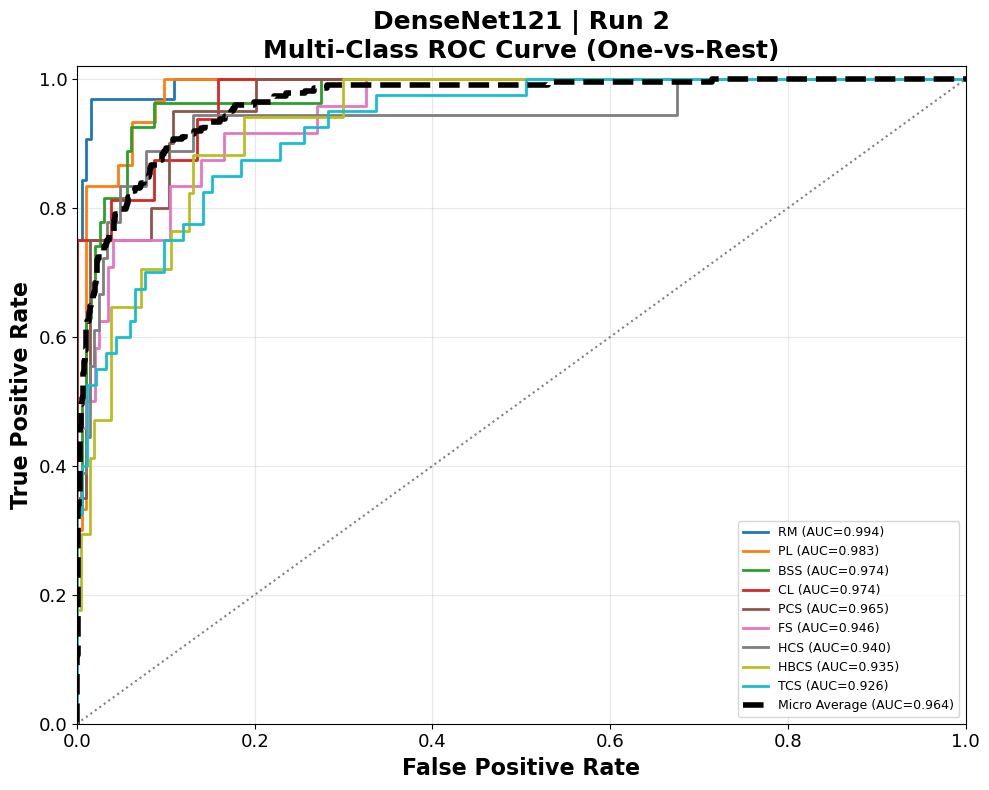


AUC Values
--------------------------------------------------------------------------------
               Class       AUC  Performance
0                 RM  0.994466  Outstanding
1                 PL  0.982818    Excellent
2                BSS  0.974055    Excellent
3                 CL  0.973858    Excellent
4                PCS  0.964951    Excellent
5                 FS  0.946042    Excellent
6                HCS  0.939860    Excellent
7               HBCS  0.935493    Excellent
8                TCS  0.925543    Excellent
9      Micro Average  0.963513      Summary
10     Macro Average  0.959676      Summary
11  Weighted Average  0.959979      Summary

ROC Curve Saved : DenseNet121_Run2_ROC.png
AUC Table Saved : DenseNet121_Run2_AUC.csv

ROC Summary
--------------------------------------------------------------------------------
Number of Classes : 9
Excellent ROC (AUC ≥ 0.90): 9/9

Best Class        : RM (Outstanding)
Best AUC          : 0.9945

Worst Class       : TCS (Excellent

,Class,AUC,Performance
0,RM,0.994466,Outstanding
1,PL,0.982818,Excellent
2,BSS,0.974055,Excellent
3,CL,0.973858,Excellent
4,PCS,0.964951,Excellent
5,FS,0.946042,Excellent
6,HCS,0.939860,Excellent
7,HBCS,0.935493,Excellent
8,TCS,0.925543,Excellent
9,Micro Average,0.963513,Summary


In [76]:
# Test 8G
result = plot_multiclass_roc(result)

result["auc_table"]

In [84]:
print(type(result))
print("metrics" in result)
print(result["metrics"])

<class 'dict'>
True
{'Model': 'DenseNet121', 'Run': 2, 'Accuracy': 0.75, 'Precision_Macro': 0.7568603695925676, 'Recall_Macro': 0.7324830549503752, 'F1_Macro': 0.7400330461851502, 'Precision_Weighted': 0.7518734599217861, 'Recall_Weighted': 0.75, 'F1_Weighted': 0.7473074098151266, 'Balanced_Accuracy': np.float64(0.7324830549503752), 'Cohen_Kappa': np.float64(0.714584755403868), 'MCC': np.float64(0.7153227151858319), 'Log_Loss': 0.8288475306100439, 'Parameters': 8012160, 'Trainable_Parameters': 8012160, 'Inference_Time_Total': 10.186804294586182, 'Inference_Time_Per_Image': 0.04547680488654545}


In [87]:
print(result["metrics"])

{'Model': 'DenseNet121', 'Run': 2, 'Accuracy': 0.75, 'Precision_Macro': 0.7568603695925676, 'Recall_Macro': 0.7324830549503752, 'F1_Macro': 0.7400330461851502, 'Precision_Weighted': 0.7518734599217861, 'Recall_Weighted': 0.75, 'F1_Weighted': 0.7473074098151266, 'Balanced_Accuracy': np.float64(0.7324830549503752), 'Cohen_Kappa': np.float64(0.714584755403868), 'MCC': np.float64(0.7153227151858319), 'Log_Loss': 0.8288475306100439, 'Parameters': 8012160, 'Trainable_Parameters': 8012160, 'Inference_Time_Total': 10.186804294586182, 'Inference_Time_Per_Image': 0.04547680488654545}


In [90]:
# ============================================================
# STEP 8H : CNN BENCHMARK SUMMARY
# ============================================================

import pandas as pd

def build_benchmark_summary(result):

    print("="*80)
    print(f"Benchmark Summary : {result['model_name']} | Run {result['run']}")
    print("="*80)

    metrics = result["metrics"]

    prediction = result["prediction_summary"].iloc[0]

    auc = result["auc_summary"]

    confidence = (
        result["confidence_summary"]
        .set_index("Confidence_Category")["Number_of_Images"]
        .to_dict()
    )

    benchmark = {

        # ----------------------------------------------------
        # ----------------------------------------------------
        # Model Information
        # ----------------------------------------------------
        
        "Model": result["model_name"],
        "Run": result["run"],
        "Number of Classes": result["n_classes"],

        # ----------------------------------------------------
        # Classification Metrics
        # ----------------------------------------------------

        "Accuracy": metrics["Accuracy"],

        "Precision (Macro)": metrics["Precision_Macro"],
        "Recall (Macro)": metrics["Recall_Macro"],
        "F1 Score (Macro)": metrics["F1_Macro"],

        "Precision (Weighted)": metrics["Precision_Weighted"],
        "Recall (Weighted)": metrics["Recall_Weighted"],
        "F1 Score (Weighted)": metrics["F1_Weighted"],

        "Balanced Accuracy": metrics["Balanced_Accuracy"],
        "Cohen Kappa": metrics["Cohen_Kappa"],
        "MCC": metrics["MCC"],
        "Log Loss": metrics["Log_Loss"],

        # ----------------------------------------------------
        # Prediction Summary
        # ----------------------------------------------------

        "Total Images": prediction["Total Images"],
        "Correct Predictions": prediction["Correct Predictions"],
        "Incorrect Predictions": prediction["Incorrect Predictions"],

        "Average Prediction Confidence (%)":
            prediction["Average Prediction Confidence (%)"],

        "Average True-Class Probability (%)":
            prediction["Average True-Class Probability (%)"],

        "Average Confidence Margin (%)":
            prediction["Average Confidence Margin (%)"],

        "Correct Prediction Confidence (%)":
            prediction["Correct Prediction Confidence (%)"],

        "Incorrect Prediction Confidence (%)":
            prediction["Incorrect Prediction Confidence (%)"],

        # ----------------------------------------------------
        # Confidence Distribution
        # ----------------------------------------------------

        "Excellent Predictions":
            confidence.get("Excellent", 0),

        "Good Predictions":
            confidence.get("Good", 0),

        "Average Predictions":
            confidence.get("Average", 0),

        "Poor Predictions":
            confidence.get("Poor", 0),

        # ----------------------------------------------------
        # ROC Summary
        # ----------------------------------------------------

        "Micro AUC": auc["Micro AUC"],
        "Macro AUC": auc["Macro AUC"],
        "Weighted AUC": auc["Weighted AUC"],

        "Best ROC Class":
            result["best_auc_class"]["Class"],

        "Best ROC":
            result["best_auc_class"]["AUC"],

        "Worst ROC Class":
            result["worst_auc_class"]["Class"],

        "Worst ROC":
            result["worst_auc_class"]["AUC"],

        "Excellent ROC Classes":
            result["excellent_auc_classes"],

        # ----------------------------------------------------
        # Model Complexity
        # ----------------------------------------------------

        "Total Parameters":
            result["total_parameters"],

        "Trainable Parameters":
            result["trainable_parameters"],

        # ----------------------------------------------------
        # Speed
        # ----------------------------------------------------

        "Total Inference Time (s)":
            result["total_inference_time"],

        "Average Inference Time/Image (s)":
            result["average_inference_time"]

    }

    benchmark_df = pd.DataFrame([benchmark])

    result["benchmark_summary"] = benchmark_df

    print("\nBenchmark Summary")
    print("-"*80)

    display(benchmark_df)

    print("="*80)

    return result

In [91]:
# Test Step 8H

result = build_benchmark_summary(result)

result["benchmark_summary"]

Benchmark Summary : DenseNet121 | Run 2

Benchmark Summary
--------------------------------------------------------------------------------


,Model,Run,Number of Classes,Accuracy,Precision (Macro),Recall (Macro),F1 Score (Macro),Precision (Weighted),Recall (Weighted),F1 Score (Weighted),...,Weighted AUC,Best ROC Class,Best ROC,Worst ROC Class,Worst ROC,Excellent ROC Classes,Total Parameters,Trainable Parameters,Total Inference Time (s),Average Inference Time/Image (s)
0,DenseNet121,2,9,0.75,0.75686,0.732483,0.740033,0.751873,0.75,0.747307,...,0.96,RM,0.994466,TCS,0.925543,9,8012160,8012160,10.186804,0.045477


,Model,Run,Number of Classes,Accuracy,Precision (Macro),Recall (Macro),F1 Score (Macro),Precision (Weighted),Recall (Weighted),F1 Score (Weighted),...,Weighted AUC,Best ROC Class,Best ROC,Worst ROC Class,Worst ROC,Excellent ROC Classes,Total Parameters,Trainable Parameters,Total Inference Time (s),Average Inference Time/Image (s)
0,DenseNet121,2,9,0.75,0.75686,0.732483,0.740033,0.751873,0.75,0.747307,...,0.96,RM,0.994466,TCS,0.925543,9,8012160,8012160,10.186804,0.045477


In [94]:
# ============================================================
# STEP 8I : EXPORT CNN RESULTS
# ============================================================

from pathlib import Path
import pandas as pd
import shutil

def export_results(result, root_dir="Results"):

    print("="*80)
    print(f"Exporting Results : {result['model_name']} | Run {result['run']}")
    print("="*80)

    # --------------------------------------------------------
    # Create Folder Structure
    # --------------------------------------------------------

    base_dir = Path(root_dir) / result["model_name"] / f"Run_{result['run']}"

    metrics_dir     = base_dir / "Metrics"
    prediction_dir  = base_dir / "Prediction"
    confidence_dir  = base_dir / "Confidence"
    roc_dir         = base_dir / "ROC"
    benchmark_dir   = base_dir / "Benchmark"

    for folder in [
        metrics_dir,
        prediction_dir,
        confidence_dir,
        roc_dir,
        benchmark_dir
    ]:
        folder.mkdir(parents=True, exist_ok=True)

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    pd.DataFrame([result["metrics"]]).to_csv(
        metrics_dir / "Overall_Metrics.csv",
        index=False
    )

    result["classification_report"].to_csv(
        metrics_dir / "Classification_Report.csv"
    )

    # --------------------------------------------------------
    # Prediction
    # --------------------------------------------------------

    result["prediction_table"].to_csv(
        prediction_dir / "Prediction_Table.csv",
        index=False
    )

    result["prediction_summary"].to_csv(
        prediction_dir / "Prediction_Summary.csv",
        index=False
    )

    result["best_predictions"].to_csv(
        prediction_dir / "Best_Predictions.csv",
        index=False
    )

    result["weakest_correct_predictions"].to_csv(
        prediction_dir / "Weakest_Correct_Predictions.csv",
        index=False
    )

    result["dangerous_predictions"].to_csv(
        prediction_dir / "Dangerous_Predictions.csv",
        index=False
    )

    result["uncertain_predictions"].to_csv(
        prediction_dir / "Uncertain_Predictions.csv",
        index=False
    )

    # --------------------------------------------------------
    # Confidence
    # --------------------------------------------------------

    result["confidence_summary"].to_csv(
        confidence_dir / "Confidence_Summary.csv",
        index=False
    )

    result["confidence_correctness"].to_csv(
        confidence_dir / "Confidence_Correctness.csv",
        index=False
    )

    result["high_confidence_wrong"].to_csv(
        confidence_dir / "High_Confidence_Wrong.csv",
        index=False
    )

    result["low_confidence_correct"].to_csv(
        confidence_dir / "Low_Confidence_Correct.csv",
        index=False
    )

    result["classwise_confidence"].to_csv(
        confidence_dir / "Classwise_Confidence.csv",
        index=False
    )

    result["classwise_misclassification"].to_csv(
        confidence_dir / "Classwise_Misclassification.csv",
        index=False
    )

    # --------------------------------------------------------
    # ROC
    # --------------------------------------------------------

    result["auc_table"].to_csv(
        roc_dir / "AUC_Table.csv",
        index=False
    )

    if Path(result["roc_curve_png"]).exists():

        shutil.copy(
            result["roc_curve_png"],
            roc_dir / "ROC_Curve.png"
        )

    # --------------------------------------------------------
    # Benchmark
    # --------------------------------------------------------

    result["benchmark_summary"].to_csv(
        benchmark_dir / "Benchmark_Summary.csv",
        index=False
    )

    # --------------------------------------------------------
    # Store Export Path
    # --------------------------------------------------------

    result["export_directory"] = str(base_dir.resolve())

    print("\nResults Successfully Exported")
    print("-"*80)
    print(base_dir)

    print("="*80)

    return result


# --------------------------------------------------------
# Store Export Path
# --------------------------------------------------------

result["export_directory"] = str(base_dir.resolve())

print("\nResults Successfully Exported")
print("-"*80)

print(f"Export Folder : {base_dir.resolve()}")

print("="*80)

NameError: name 'base_dir' is not defined

In [93]:
# Test Step 8I

result = export_results(result)

print(result["export_directory"])

Exporting Results : DenseNet121 | Run 2

Results Successfully Exported
--------------------------------------------------------------------------------
Results\DenseNet121\Run_2
Results\DenseNet121\Run_2


STEP 8F : EVALUATING ALL MODELS

MODEL : ResNet50

Run 1
Evaluating : ResNet50 | Run 1

Loaded : ResNet50_Run1.pkl



Images Evaluated : 224
Total Inference : 12.110 sec
Per Image       : 0.054063 sec
Computing Metrics : ResNet50 | Run 1

Overall Performance
--------------------------------------------------
Accuracy              : 0.8125
Precision (Macro)     : 0.8368
Recall (Macro)        : 0.7987
F1 Score (Macro)      : 0.8139
Precision (Weighted)  : 0.8223
Recall (Weighted)     : 0.8125
F1 Score (Weighted)   : 0.8136
Balanced Accuracy     : 0.7987
Cohen Kappa           : 0.7854
MCC                   : 0.7867
Log Loss              : 0.7394
Confusion Matrix : ResNet50 | Run 1


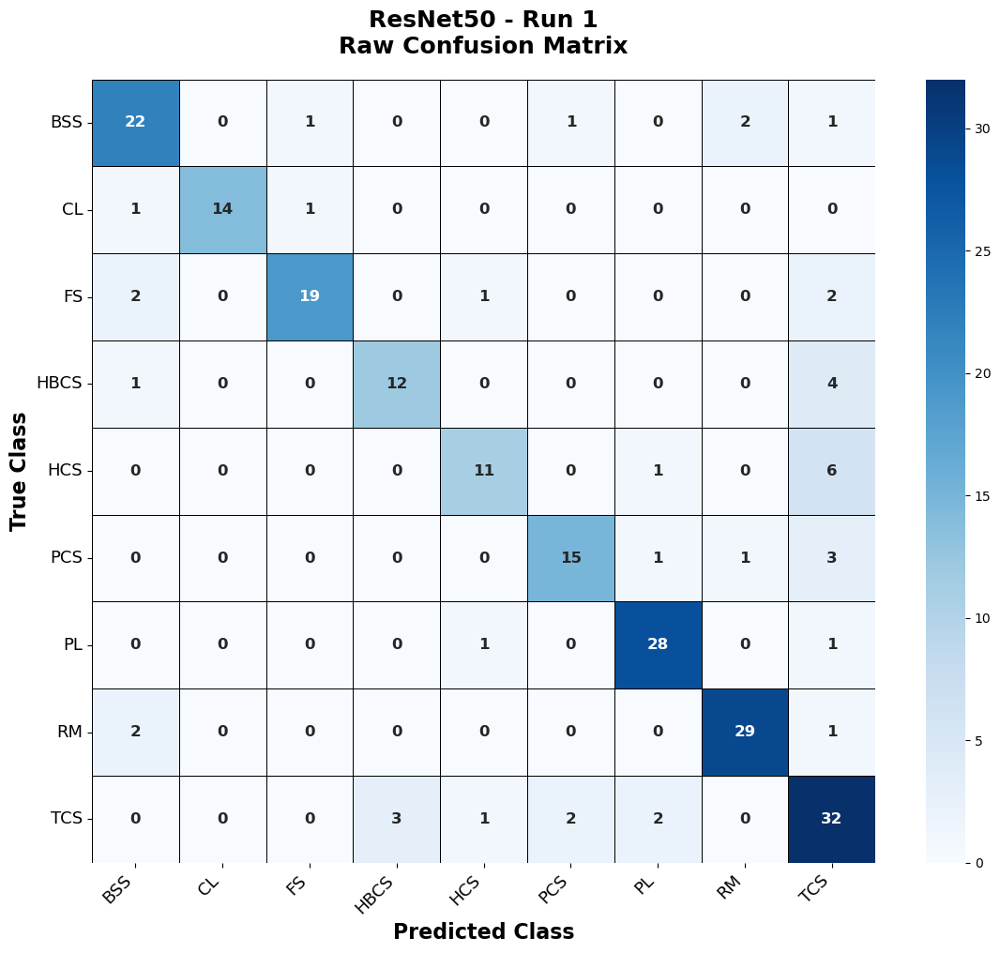

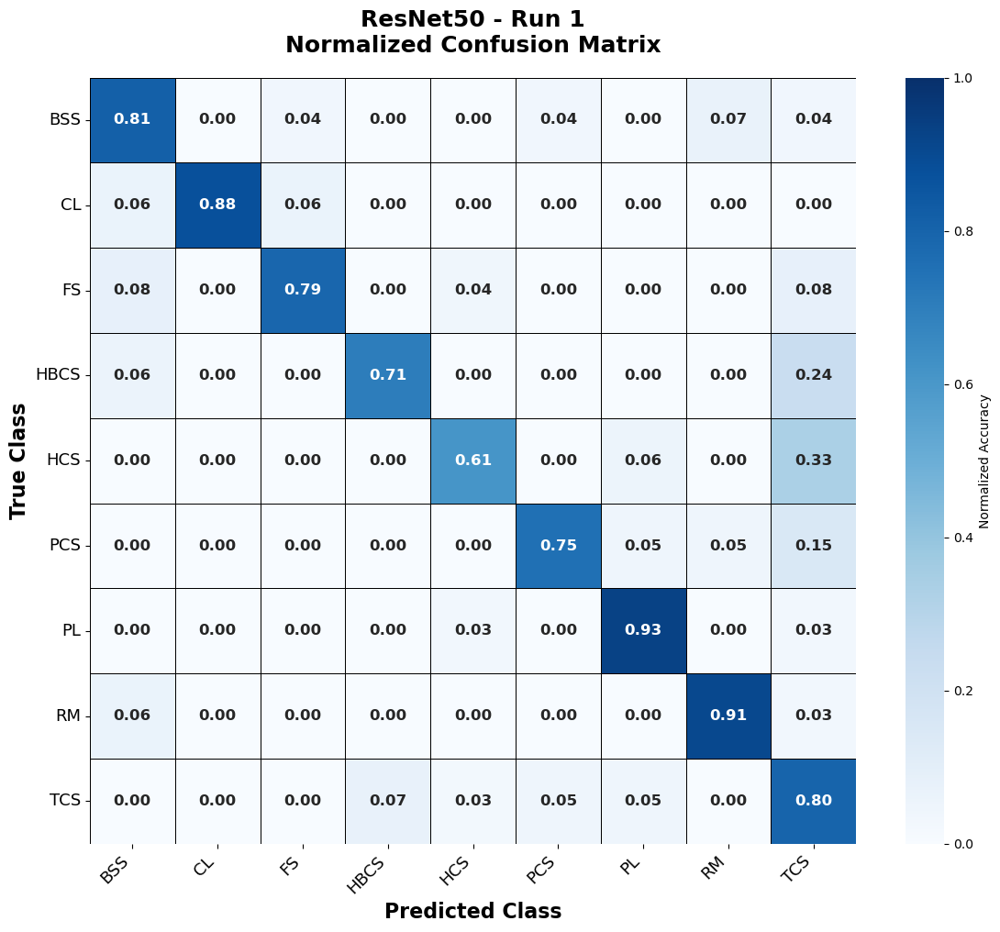


✓ Confusion matrices saved successfully
ROC Curve : ResNet50 | Run 1


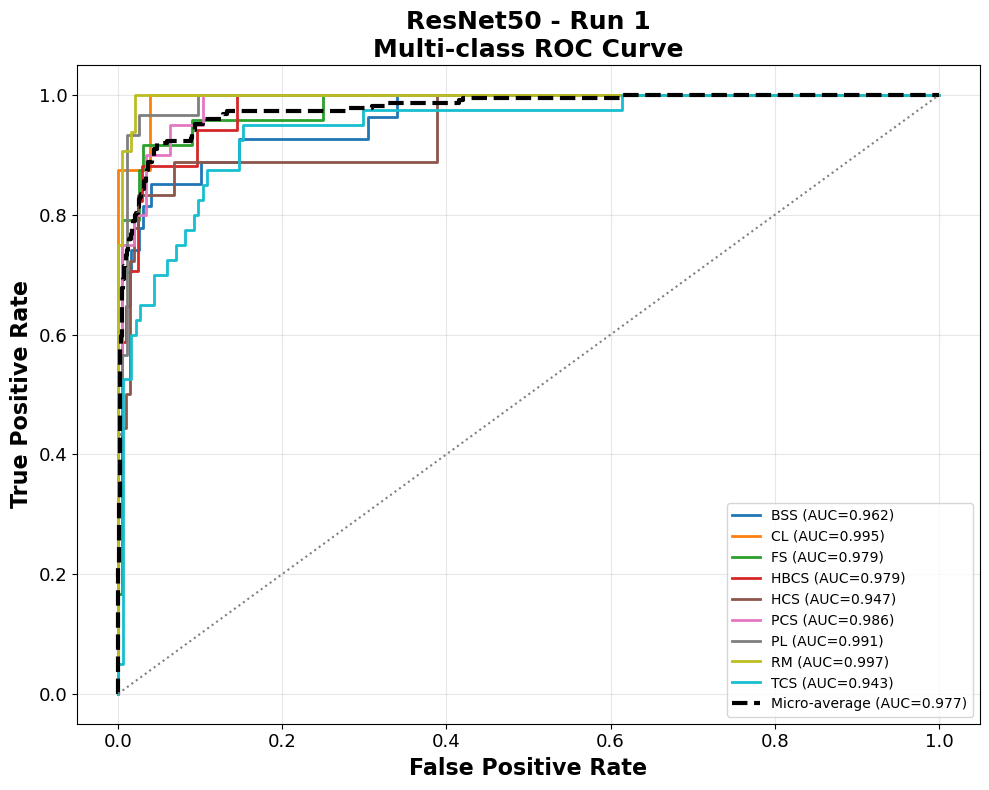


AUC Values
            Class       AUC
0             BSS  0.962211
1              CL  0.995192
2              FS  0.979375
3            HBCS  0.978687
4             HCS  0.946872
5             PCS  0.986029
6              PL  0.991409
7              RM  0.997396
8             TCS  0.943478
9   Micro Average  0.977360
10  Macro Average  0.975628

✓ ROC curve saved successfully.
✓ Completed Successfully

Run 2
Evaluating : ResNet50 | Run 2

Loaded : ResNet50_Run2.pkl



Images Evaluated : 224
Total Inference : 11.878 sec
Per Image       : 0.053027 sec
Computing Metrics : ResNet50 | Run 2

Overall Performance
--------------------------------------------------
Accuracy              : 0.7589
Precision (Macro)     : 0.7706
Recall (Macro)        : 0.7387
F1 Score (Macro)      : 0.7492
Precision (Weighted)  : 0.7654
Recall (Weighted)     : 0.7589
F1 Score (Weighted)   : 0.7565
Balanced Accuracy     : 0.7387
Cohen Kappa           : 0.7241
MCC                   : 0.7257
Log Loss              : 0.8651
Confusion Matrix : ResNet50 | Run 2


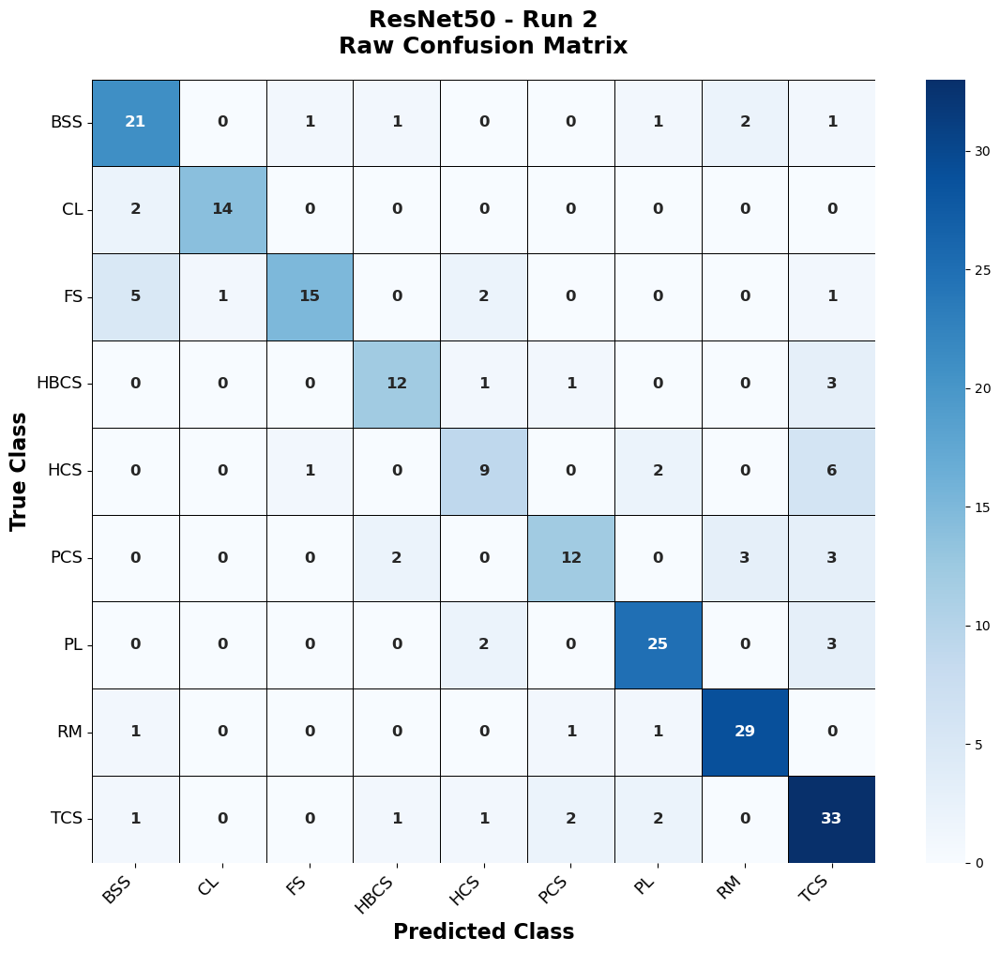

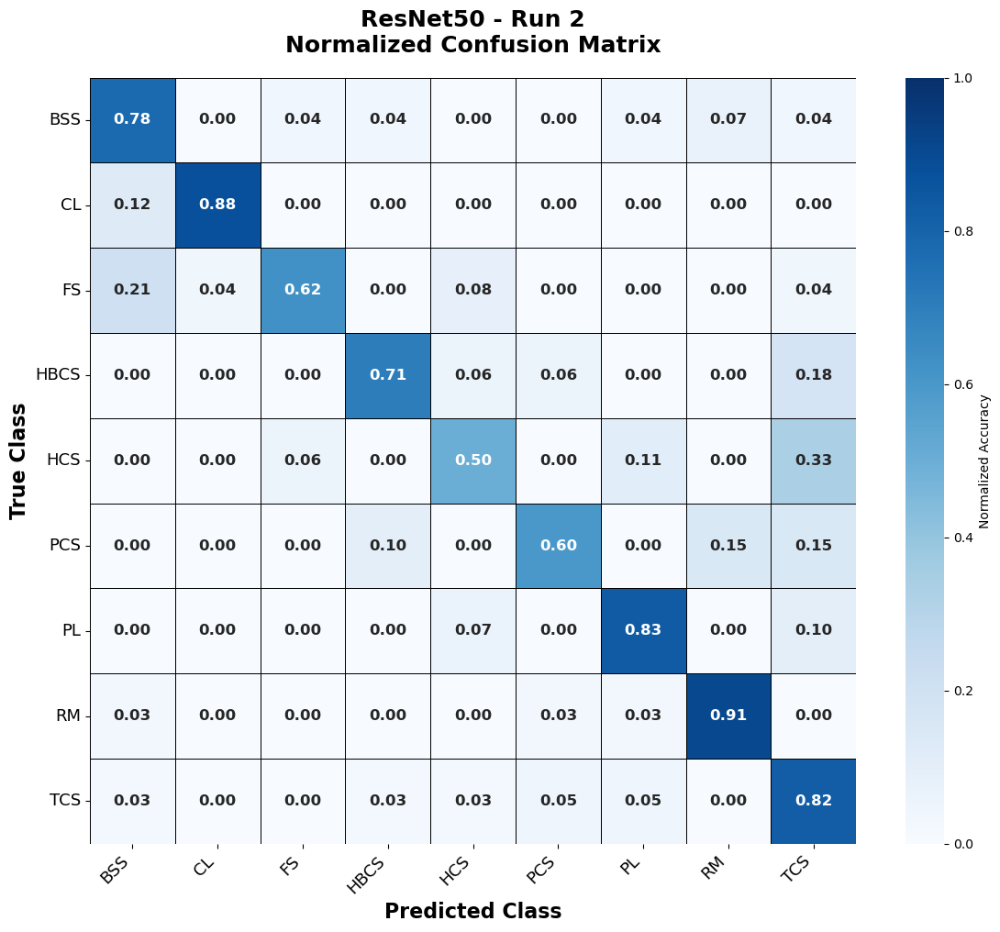


✓ Confusion matrices saved successfully
ROC Curve : ResNet50 | Run 2


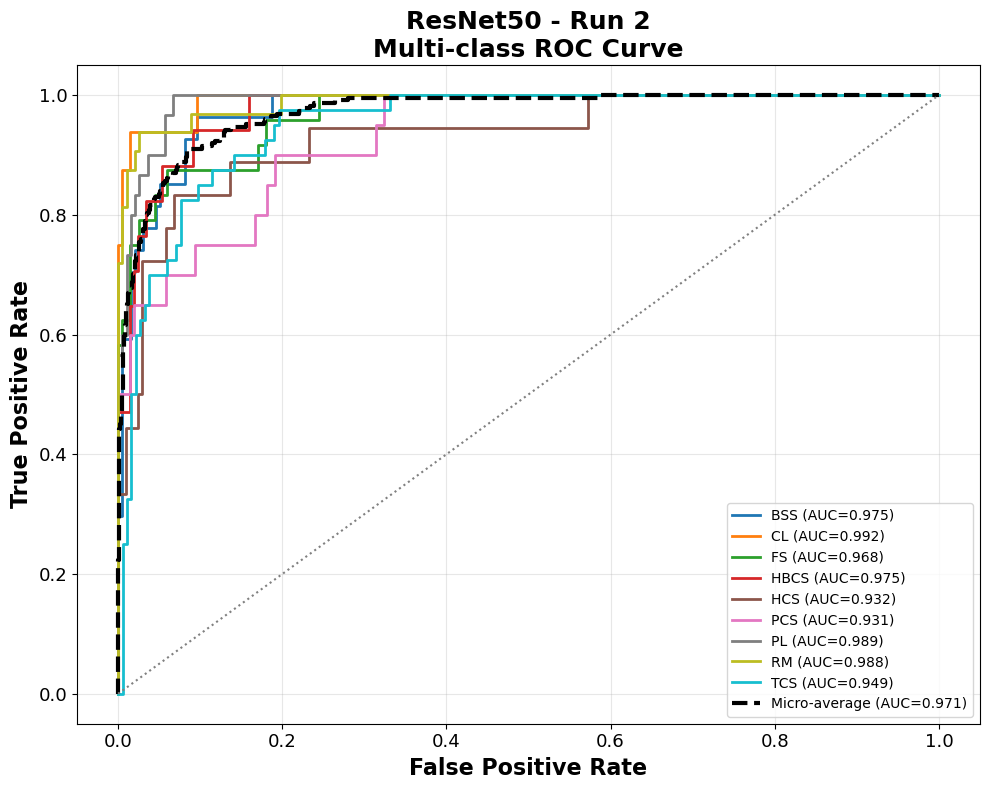


AUC Values
            Class       AUC
0             BSS  0.974807
1              CL  0.992488
2              FS  0.967708
3            HBCS  0.974993
4             HCS  0.931769
5             PCS  0.931127
6              PL  0.988660
7              RM  0.988444
8             TCS  0.949185
9   Micro Average  0.970830
10  Macro Average  0.966576

✓ ROC curve saved successfully.
✓ Completed Successfully

Run 3
Evaluating : ResNet50 | Run 3

Loaded : ResNet50_Run3.pkl



Images Evaluated : 224
Total Inference : 14.437 sec
Per Image       : 0.064451 sec
Computing Metrics : ResNet50 | Run 3

Overall Performance
--------------------------------------------------
Accuracy              : 0.7098
Precision (Macro)     : 0.7030
Recall (Macro)        : 0.6953
F1 Score (Macro)      : 0.6964
Precision (Weighted)  : 0.7088
Recall (Weighted)     : 0.7098
F1 Score (Weighted)   : 0.7064
Balanced Accuracy     : 0.6953
Cohen Kappa           : 0.6690
MCC                   : 0.6697
Log Loss              : 0.8547
Confusion Matrix : ResNet50 | Run 3


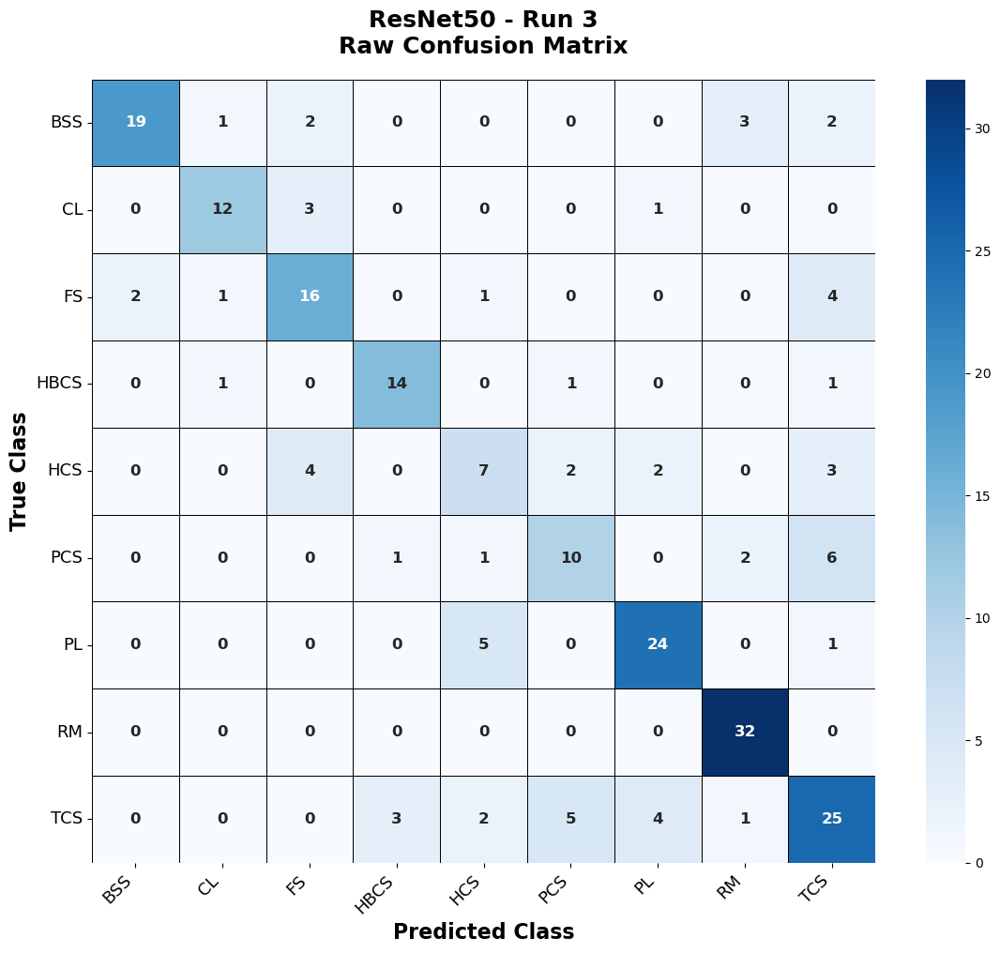

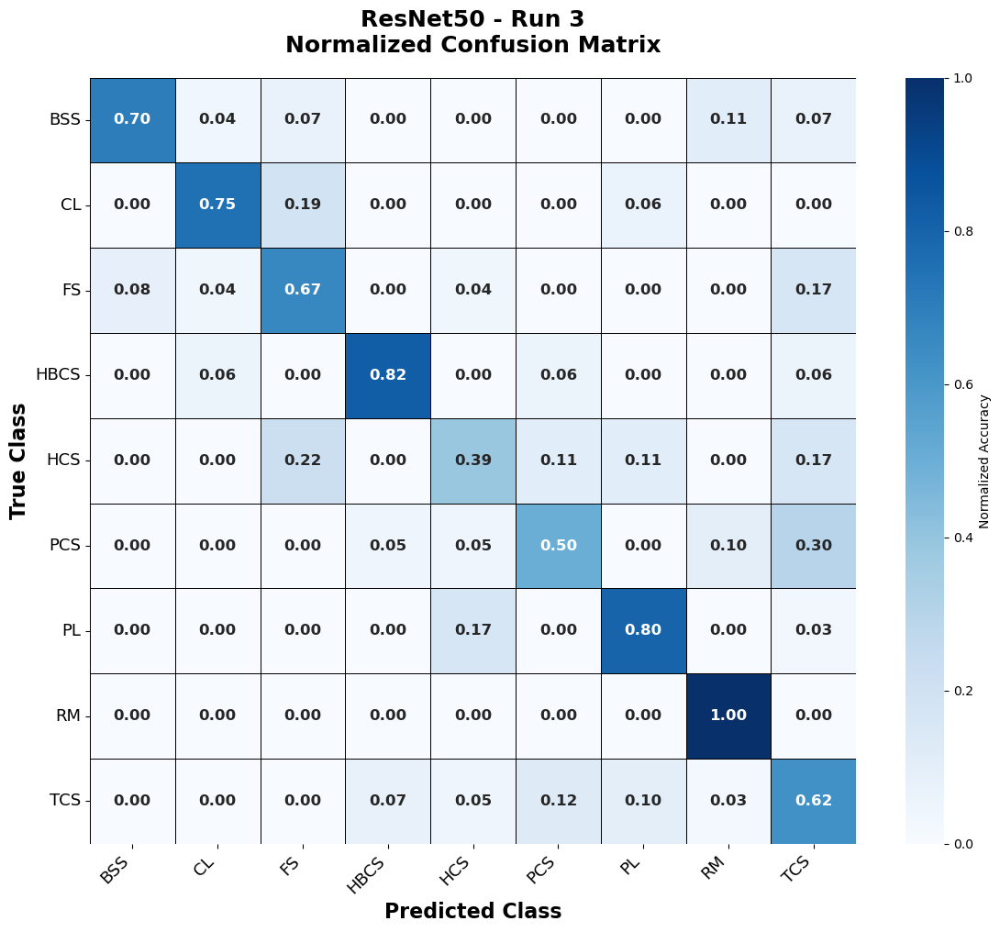


✓ Confusion matrices saved successfully
ROC Curve : ResNet50 | Run 3


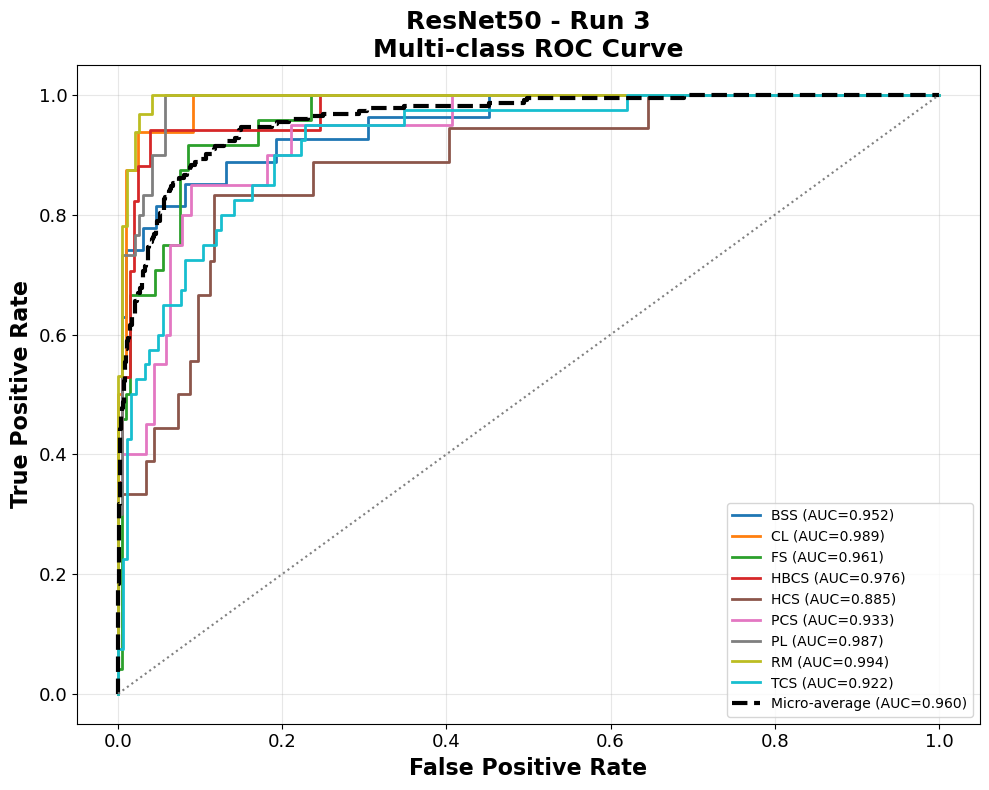


AUC Values
            Class       AUC
0             BSS  0.952059
1              CL  0.989483
2              FS  0.961042
3            HBCS  0.976130
4             HCS  0.885383
5             PCS  0.932843
6              PL  0.986770
7              RM  0.994303
8             TCS  0.922283
9   Micro Average  0.960071
10  Macro Average  0.955588

✓ ROC curve saved successfully.
✓ Completed Successfully

Run 4
Evaluating : ResNet50 | Run 4

Loaded : ResNet50_Run4.pkl



Images Evaluated : 224
Total Inference : 11.852 sec
Per Image       : 0.052912 sec
Computing Metrics : ResNet50 | Run 4

Overall Performance
--------------------------------------------------
Accuracy              : 0.7679
Precision (Macro)     : 0.7754
Recall (Macro)        : 0.7420
F1 Score (Macro)      : 0.7537
Precision (Weighted)  : 0.7712
Recall (Weighted)     : 0.7679
F1 Score (Weighted)   : 0.7652
Balanced Accuracy     : 0.7420
Cohen Kappa           : 0.7344
MCC                   : 0.7355
Log Loss              : 0.8043
Confusion Matrix : ResNet50 | Run 4


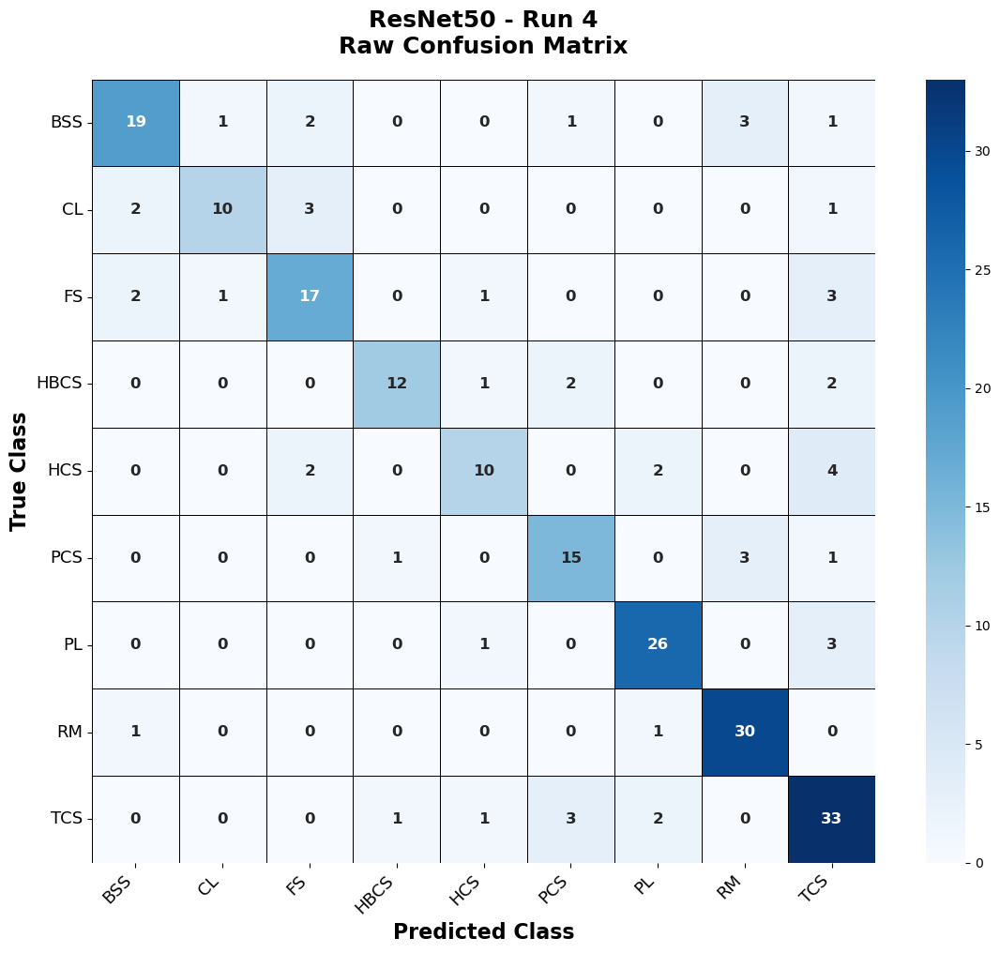

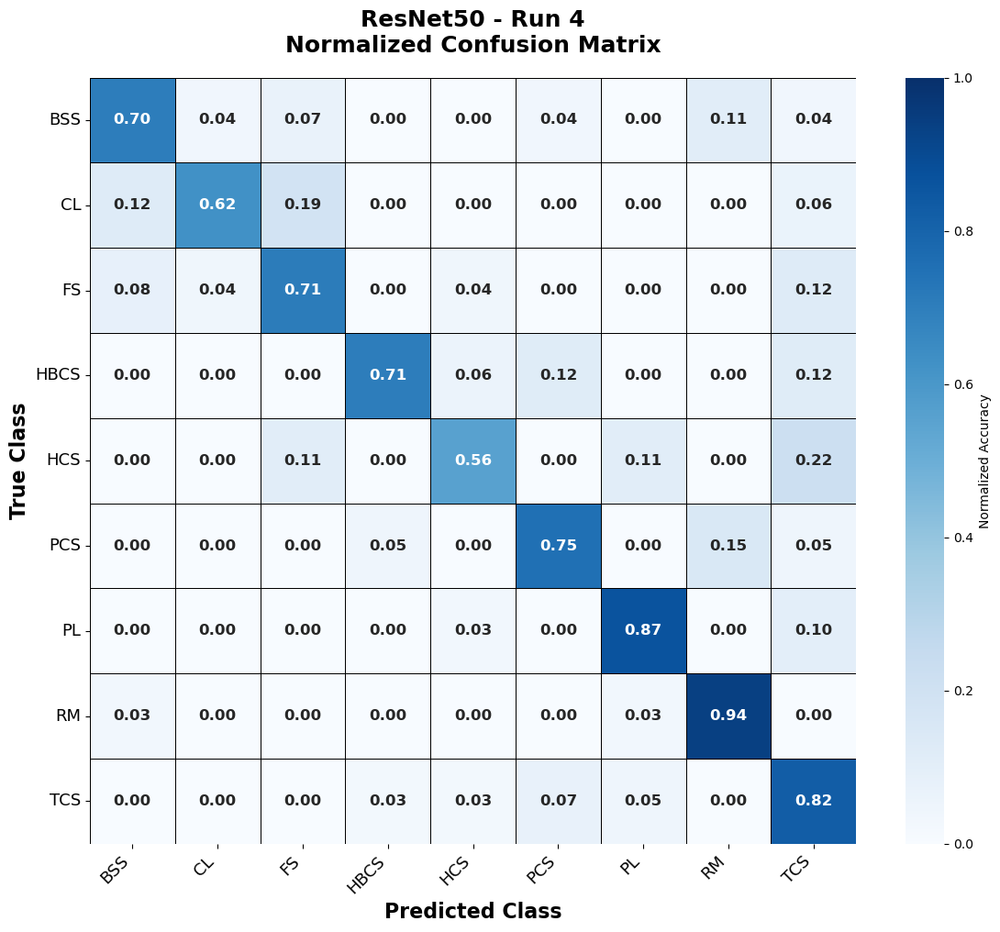


✓ Confusion matrices saved successfully
ROC Curve : ResNet50 | Run 4


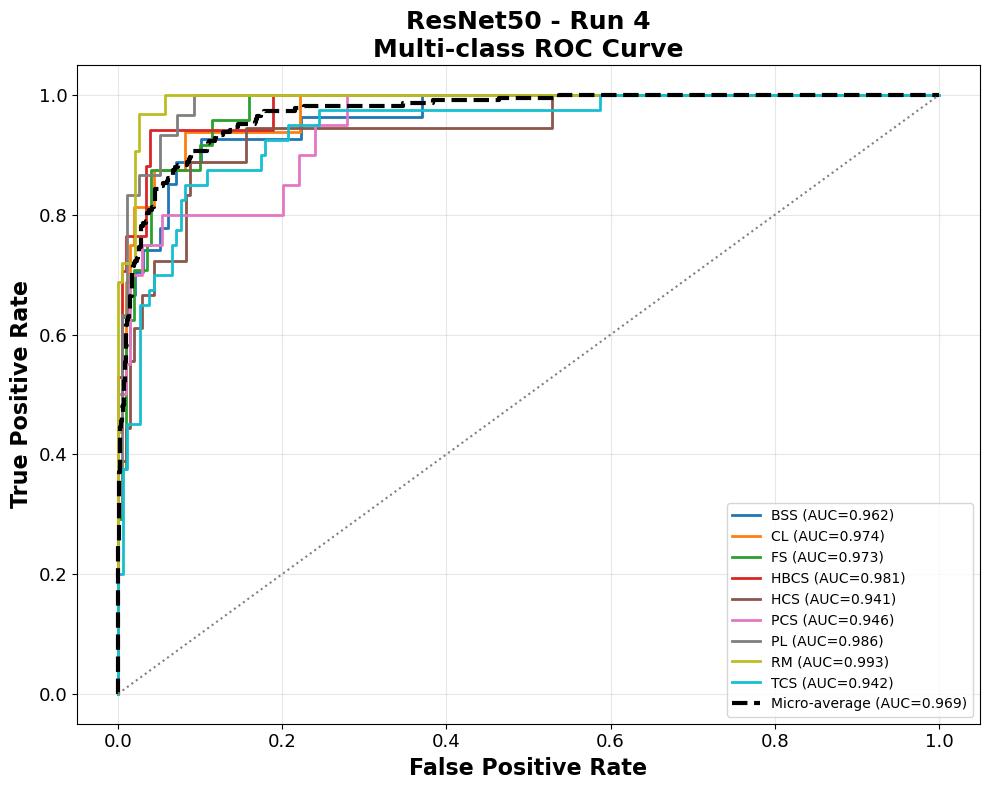


AUC Values
            Class       AUC
0             BSS  0.962211
1              CL  0.974159
2              FS  0.973125
3            HBCS  0.981245
4             HCS  0.940669
5             PCS  0.946078
6              PL  0.986426
7              RM  0.992513
8             TCS  0.942391
9   Micro Average  0.969111
10  Macro Average  0.966535

✓ ROC curve saved successfully.
✓ Completed Successfully

Run 5
Evaluating : ResNet50 | Run 5

Loaded : ResNet50_Run5.pkl



Images Evaluated : 224
Total Inference : 12.067 sec
Per Image       : 0.053870 sec
Computing Metrics : ResNet50 | Run 5

Overall Performance
--------------------------------------------------
Accuracy              : 0.7723
Precision (Macro)     : 0.7731
Recall (Macro)        : 0.7597
F1 Score (Macro)      : 0.7626
Precision (Weighted)  : 0.7702
Recall (Weighted)     : 0.7723
F1 Score (Weighted)   : 0.7682
Balanced Accuracy     : 0.7597
Cohen Kappa           : 0.7403
MCC                   : 0.7408
Log Loss              : 0.8158
Confusion Matrix : ResNet50 | Run 5


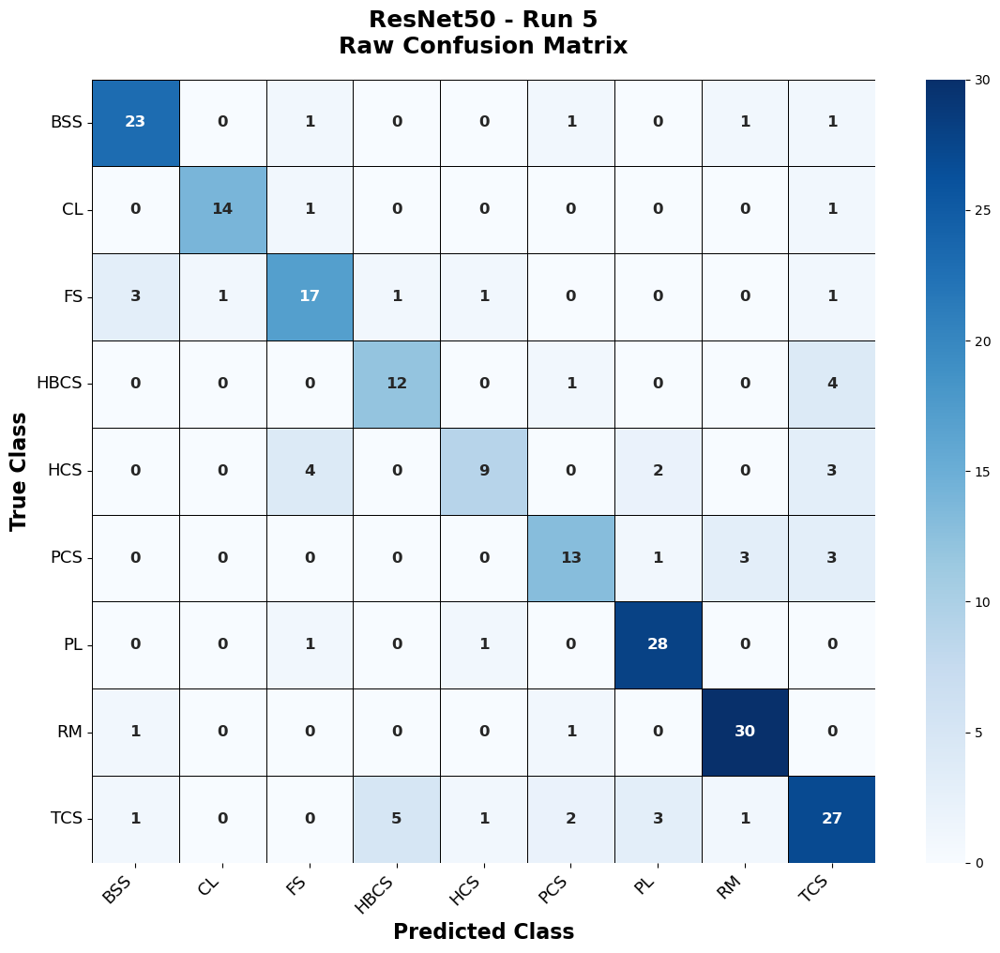

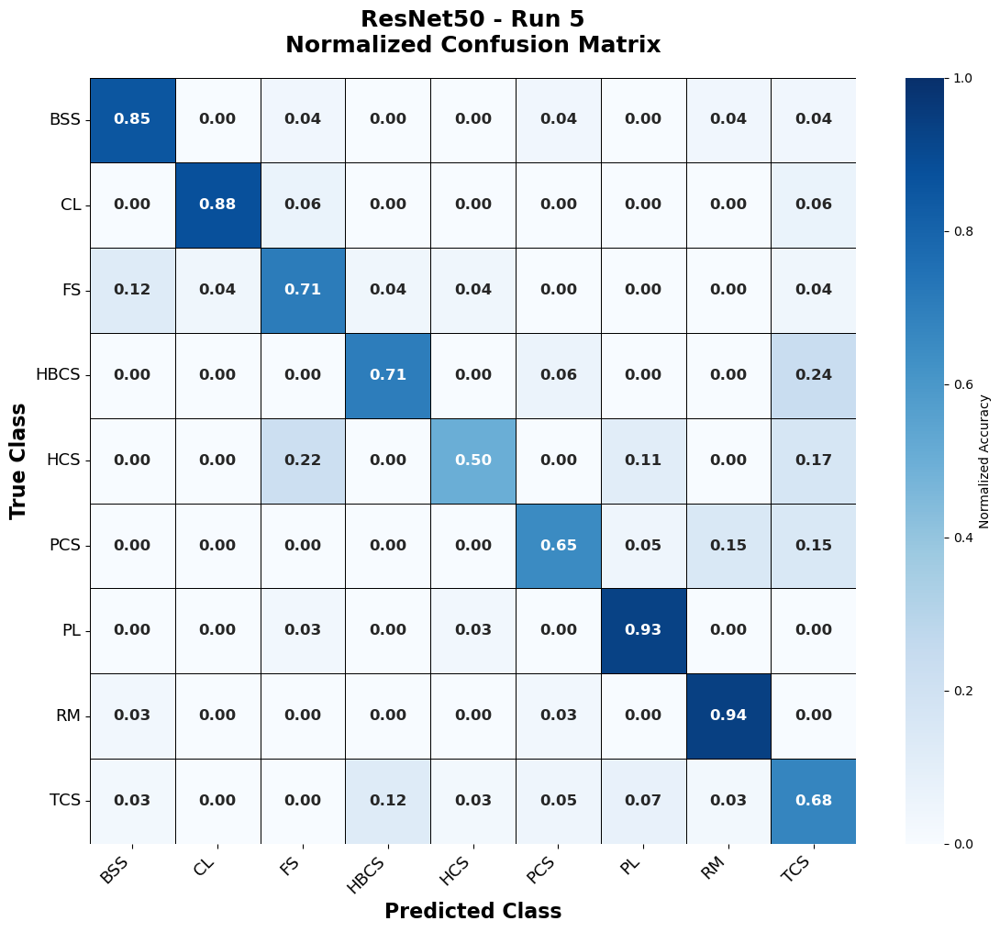


✓ Confusion matrices saved successfully
ROC Curve : ResNet50 | Run 5


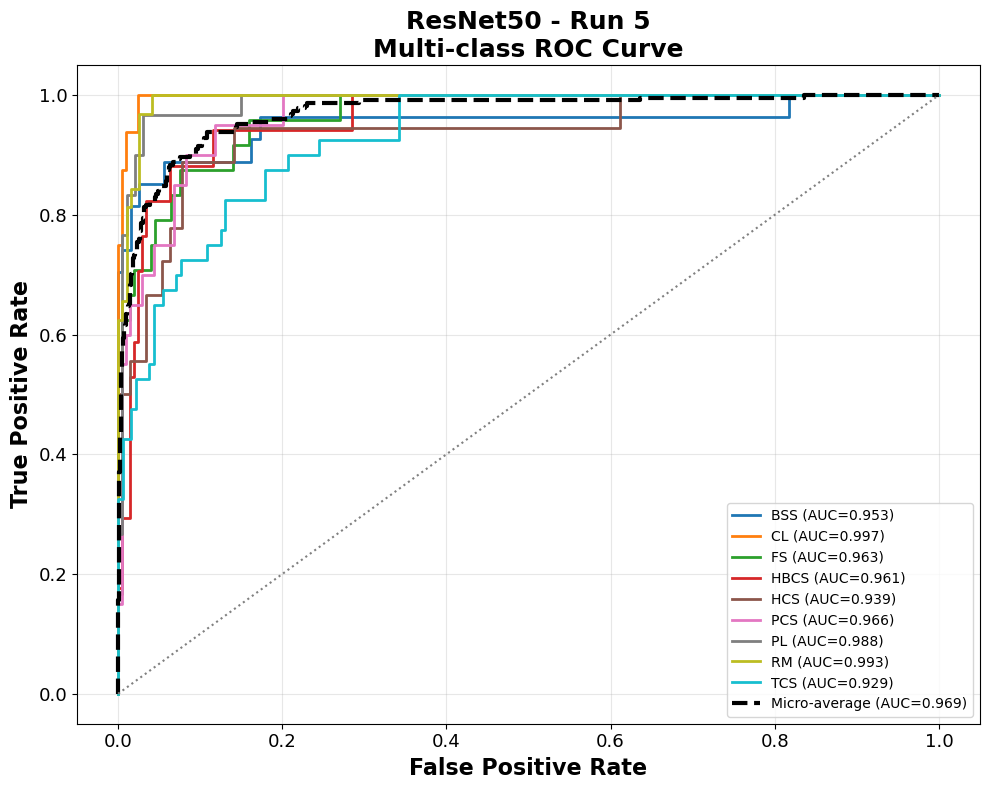


AUC Values
            Class       AUC
0             BSS  0.952999
1              CL  0.997296
2              FS  0.963125
3            HBCS  0.961068
4             HCS  0.938511
5             PCS  0.966176
6              PL  0.988316
7              RM  0.993164
8             TCS  0.928940
9   Micro Average  0.968984
10  Macro Average  0.965511

✓ ROC curve saved successfully.
✓ Completed Successfully

MODEL : DenseNet121

Run 1
Evaluating : DenseNet121 | Run 1

Loaded : DenseNet121_Run1.pkl



Images Evaluated : 224
Total Inference : 12.146 sec
Per Image       : 0.054225 sec
Computing Metrics : DenseNet121 | Run 1

Overall Performance
--------------------------------------------------
Accuracy              : 0.8080
Precision (Macro)     : 0.8194
Recall (Macro)        : 0.7841
F1 Score (Macro)      : 0.7928
Precision (Weighted)  : 0.8132
Recall (Weighted)     : 0.8080
F1 Score (Weighted)   : 0.8036
Balanced Accuracy     : 0.7841
Cohen Kappa           : 0.7803
MCC                   : 0.7819
Log Loss              : 0.7734
Confusion Matrix : DenseNet121 | Run 1


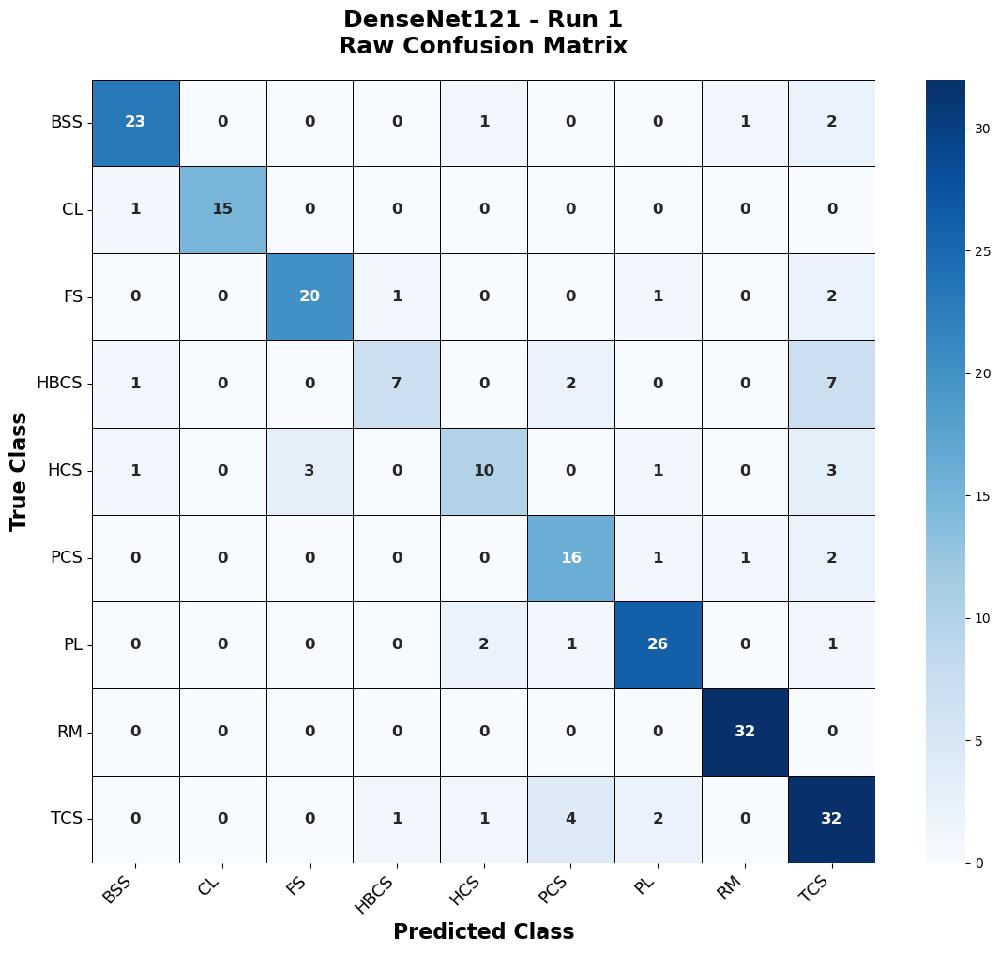

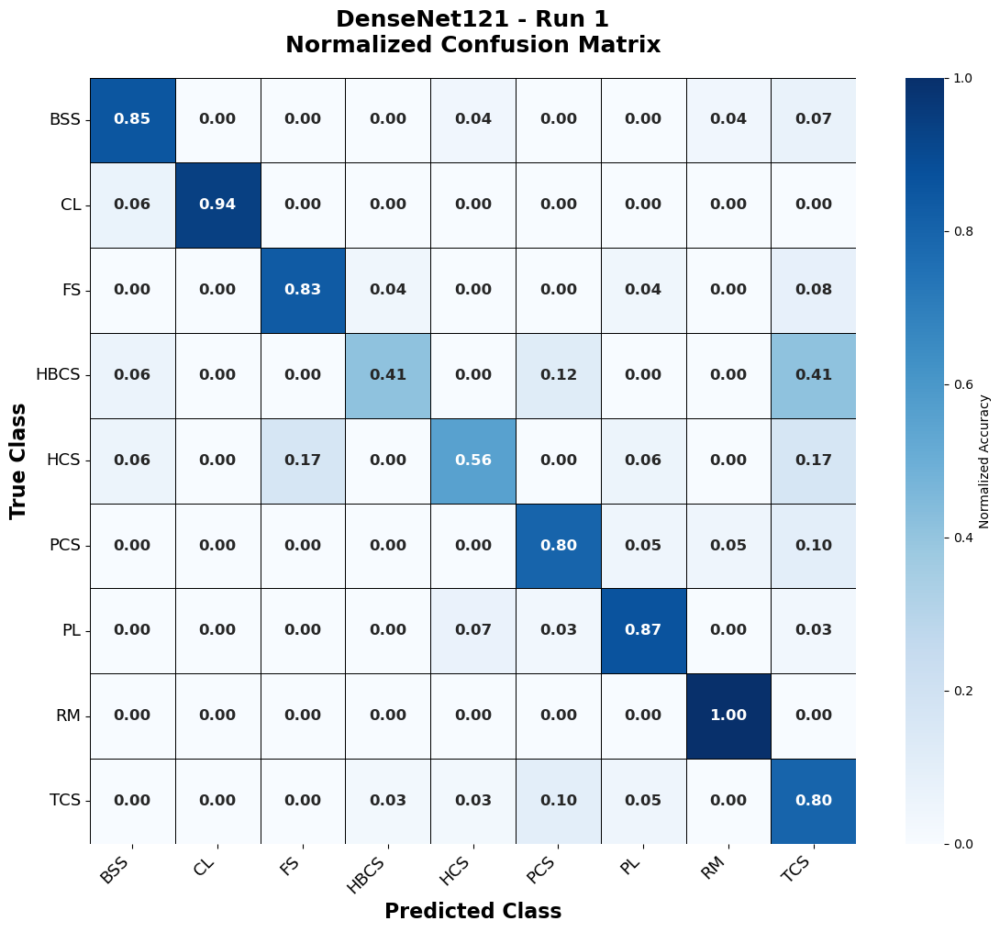


✓ Confusion matrices saved successfully
ROC Curve : DenseNet121 | Run 1


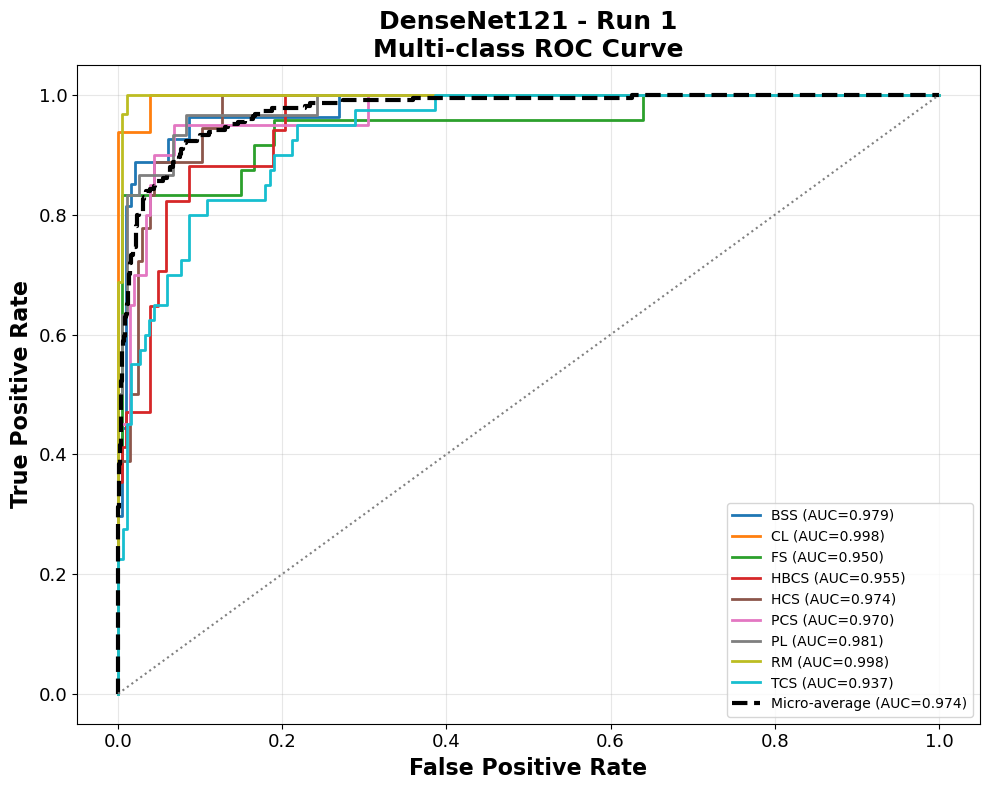


AUC Values
            Class       AUC
0             BSS  0.978755
1              CL  0.997596
2              FS  0.950000
3            HBCS  0.954533
4             HCS  0.974110
5             PCS  0.969853
6              PL  0.981100
7              RM  0.998210
8             TCS  0.937092
9   Micro Average  0.974091
10  Macro Average  0.971250

✓ ROC curve saved successfully.
✓ Completed Successfully

Run 2
Evaluating : DenseNet121 | Run 2

Loaded : DenseNet121_Run2.pkl



Images Evaluated : 224
Total Inference : 11.780 sec
Per Image       : 0.052590 sec
Computing Metrics : DenseNet121 | Run 2

Overall Performance
--------------------------------------------------
Accuracy              : 0.7500
Precision (Macro)     : 0.7569
Recall (Macro)        : 0.7325
F1 Score (Macro)      : 0.7400
Precision (Weighted)  : 0.7519
Recall (Weighted)     : 0.7500
F1 Score (Weighted)   : 0.7473
Balanced Accuracy     : 0.7325
Cohen Kappa           : 0.7146
MCC                   : 0.7153
Log Loss              : 0.8288
Confusion Matrix : DenseNet121 | Run 2


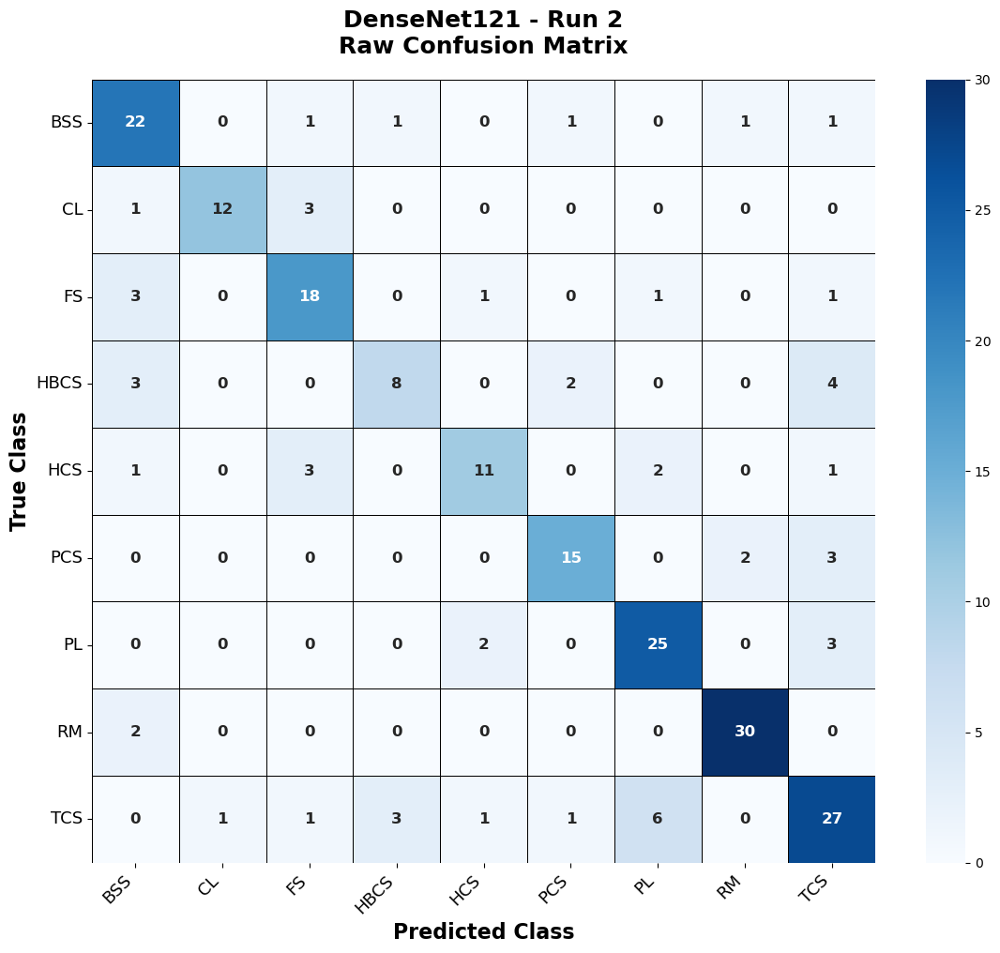

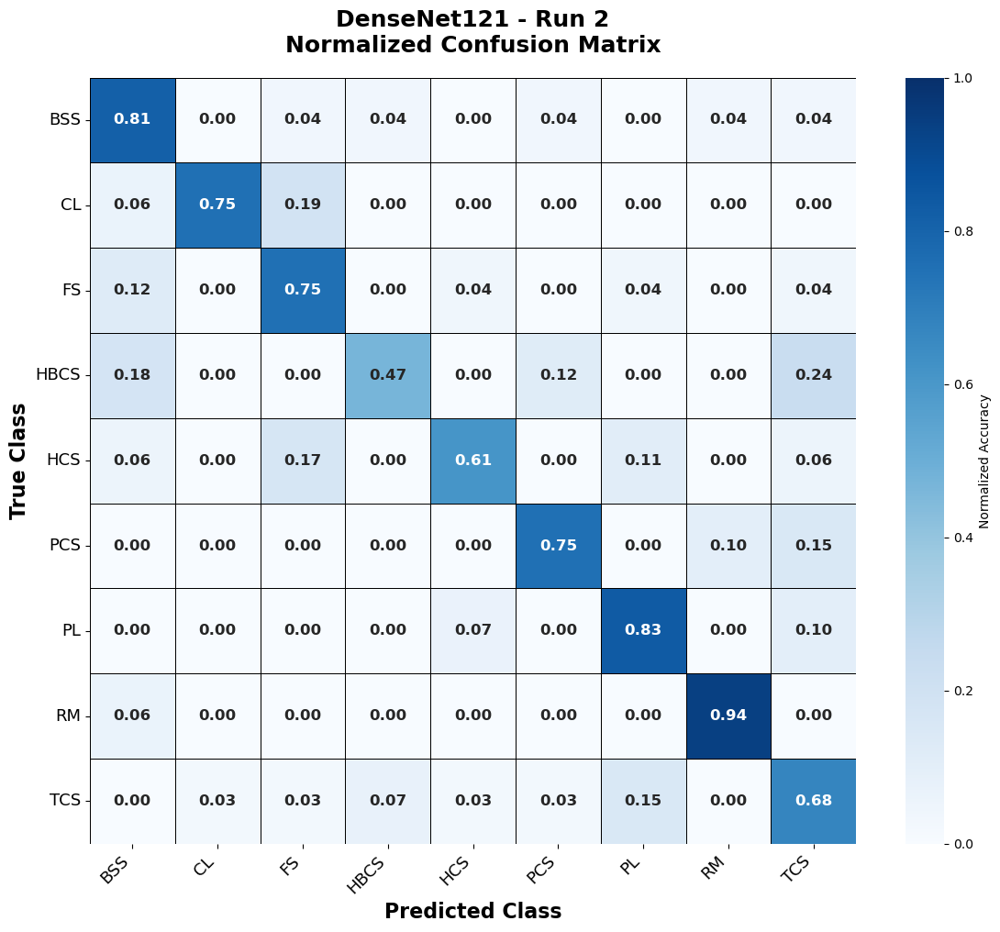


✓ Confusion matrices saved successfully
ROC Curve : DenseNet121 | Run 2


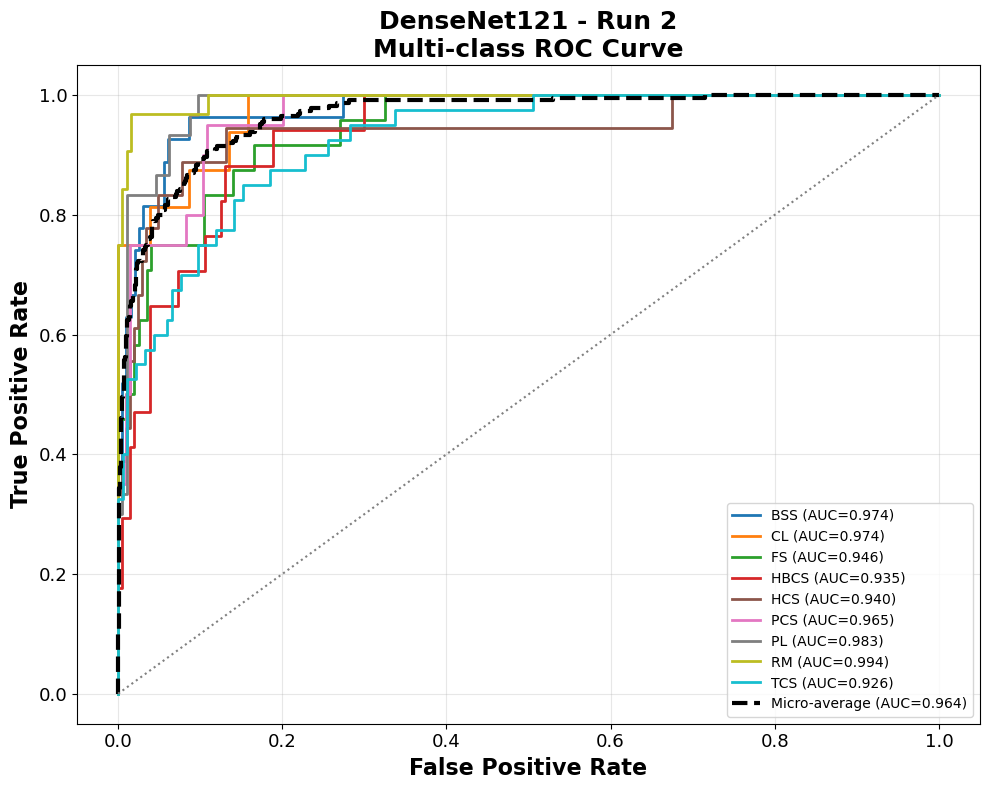


AUC Values
            Class       AUC
0             BSS  0.974055
1              CL  0.973858
2              FS  0.946042
3            HBCS  0.935493
4             HCS  0.939860
5             PCS  0.964951
6              PL  0.982818
7              RM  0.994466
8             TCS  0.925543
9   Micro Average  0.963513
10  Macro Average  0.959676

✓ ROC curve saved successfully.
✓ Completed Successfully

Run 3
Evaluating : DenseNet121 | Run 3

Loaded : DenseNet121_Run3.pkl



Images Evaluated : 224
Total Inference : 11.721 sec
Per Image       : 0.052324 sec
Computing Metrics : DenseNet121 | Run 3

Overall Performance
--------------------------------------------------
Accuracy              : 0.7991
Precision (Macro)     : 0.7969
Recall (Macro)        : 0.7850
F1 Score (Macro)      : 0.7885
Precision (Weighted)  : 0.7978
Recall (Weighted)     : 0.7991
F1 Score (Weighted)   : 0.7965
Balanced Accuracy     : 0.7850
Cohen Kappa           : 0.7710
MCC                   : 0.7715
Log Loss              : 0.7030
Confusion Matrix : DenseNet121 | Run 3


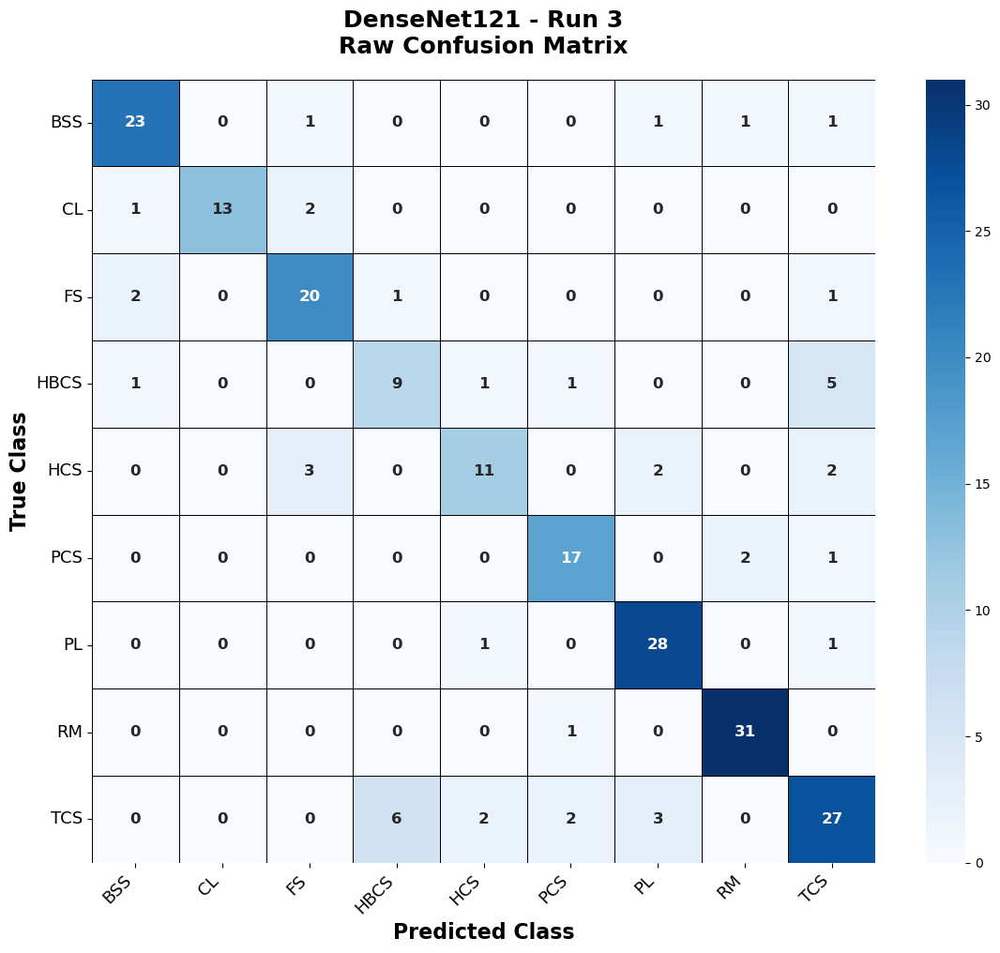

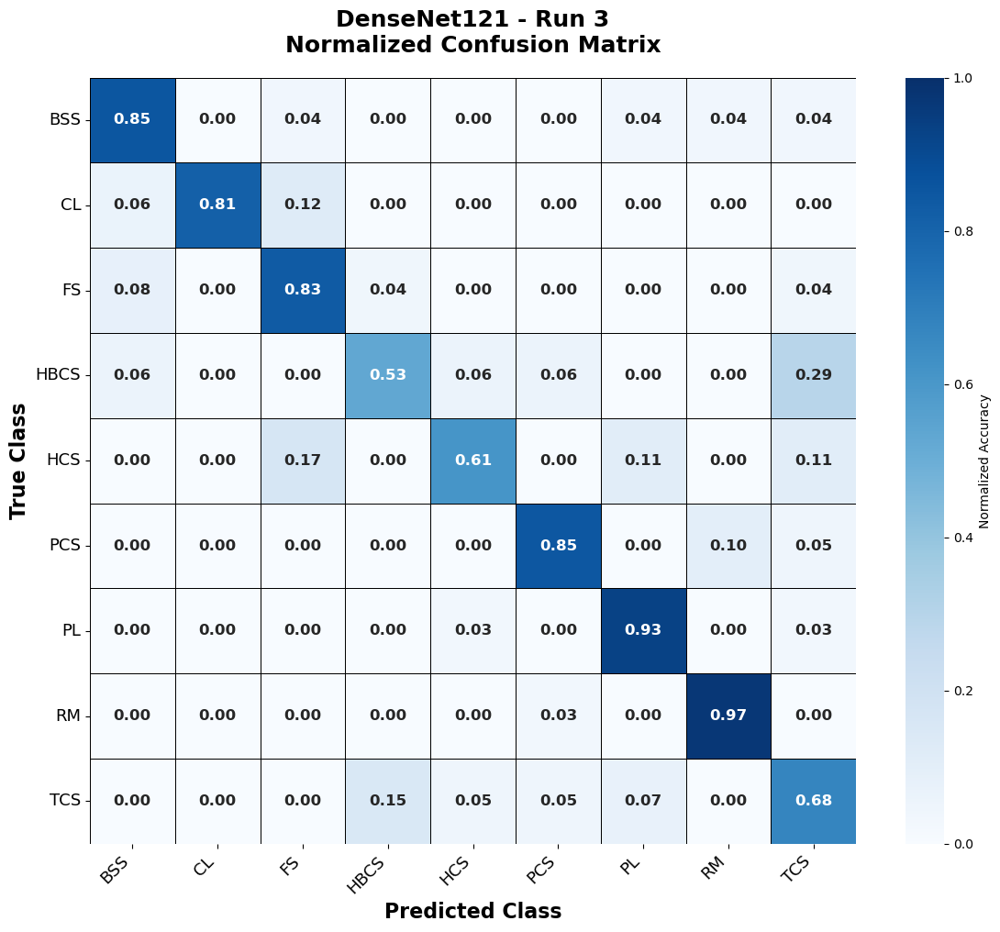


✓ Confusion matrices saved successfully
ROC Curve : DenseNet121 | Run 3


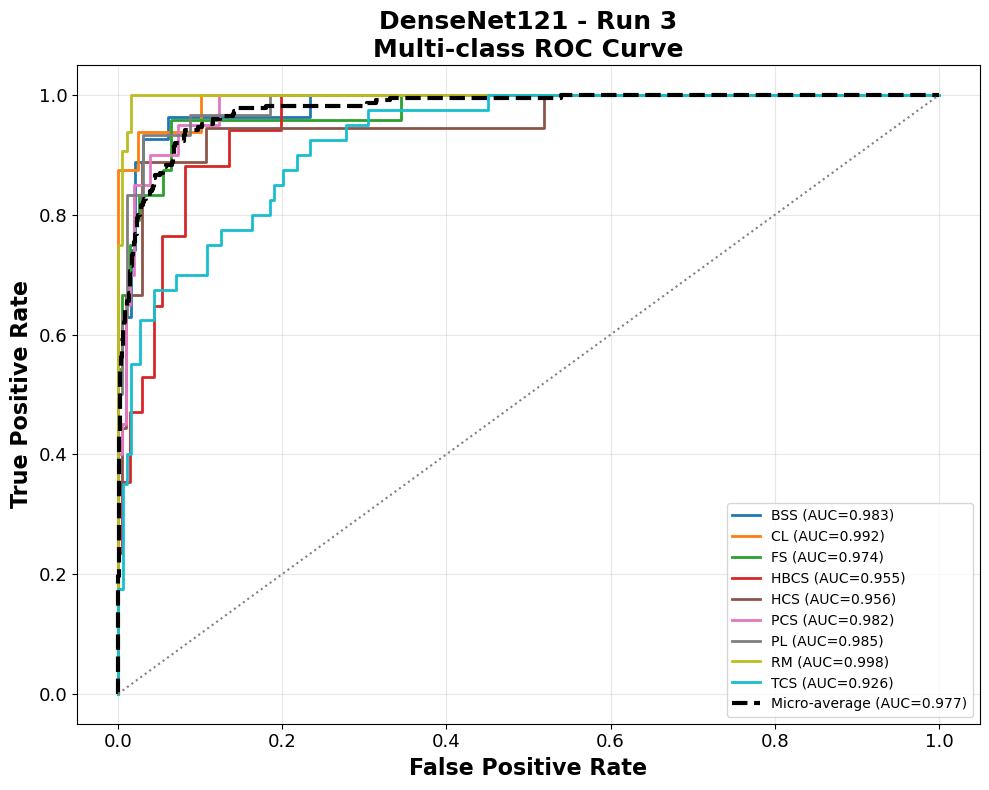


AUC Values
            Class       AUC
0             BSS  0.982892
1              CL  0.992188
2              FS  0.974167
3            HBCS  0.955385
4             HCS  0.956041
5             PCS  0.982353
6              PL  0.985052
7              RM  0.997884
8             TCS  0.925951
9   Micro Average  0.976774
10  Macro Average  0.972435

✓ ROC curve saved successfully.
✓ Completed Successfully

Run 4
Evaluating : DenseNet121 | Run 4

Loaded : DenseNet121_Run4.pkl



Images Evaluated : 224
Total Inference : 11.707 sec
Per Image       : 0.052262 sec
Computing Metrics : DenseNet121 | Run 4

Overall Performance
--------------------------------------------------
Accuracy              : 0.7589
Precision (Macro)     : 0.8197
Recall (Macro)        : 0.7201
F1 Score (Macro)      : 0.7378
Precision (Weighted)  : 0.7922
Recall (Weighted)     : 0.7589
F1 Score (Weighted)   : 0.7515
Balanced Accuracy     : 0.7201
Cohen Kappa           : 0.7228
MCC                   : 0.7267
Log Loss              : 0.8994
Confusion Matrix : DenseNet121 | Run 4


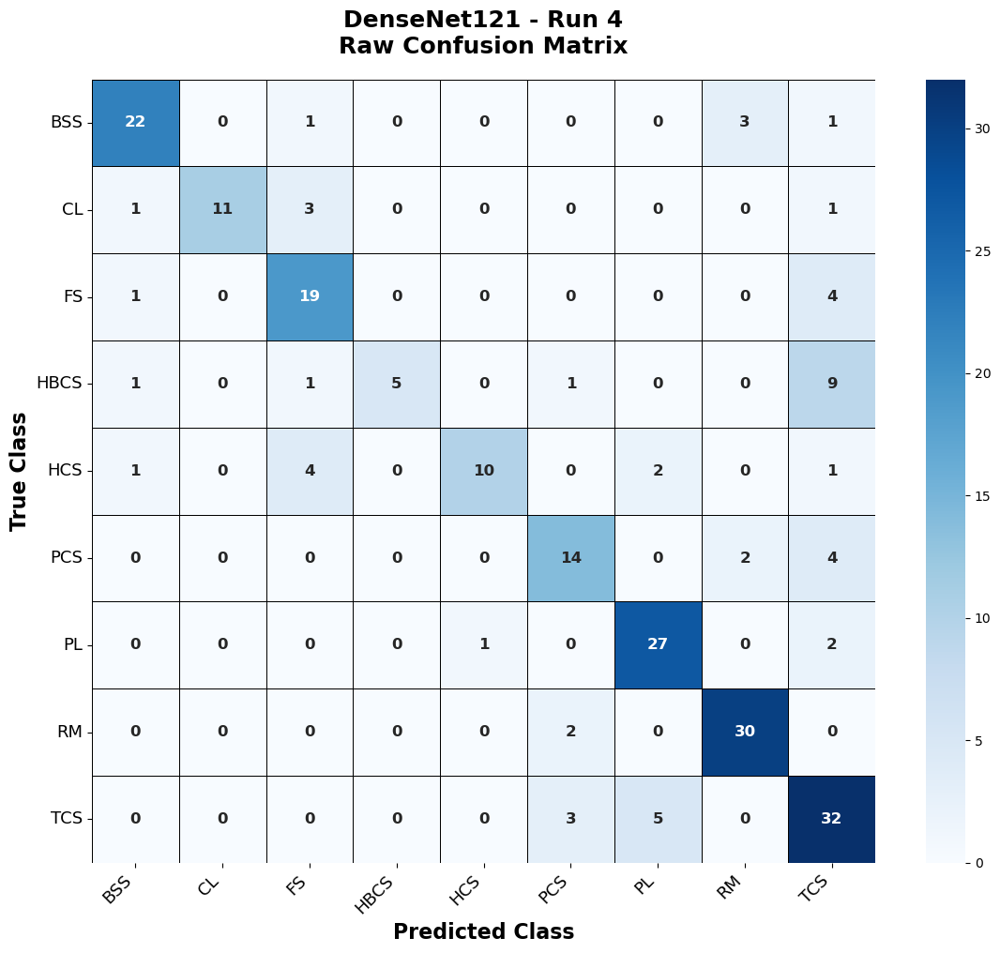

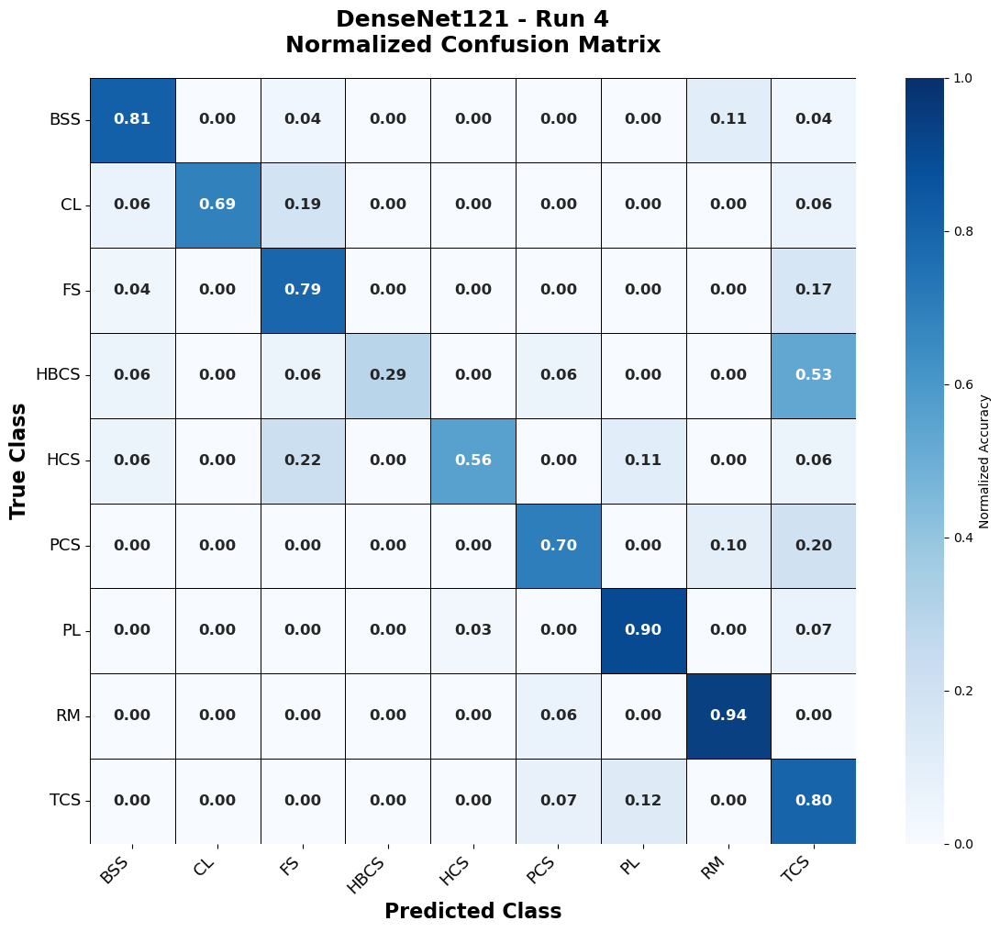


✓ Confusion matrices saved successfully
ROC Curve : DenseNet121 | Run 4


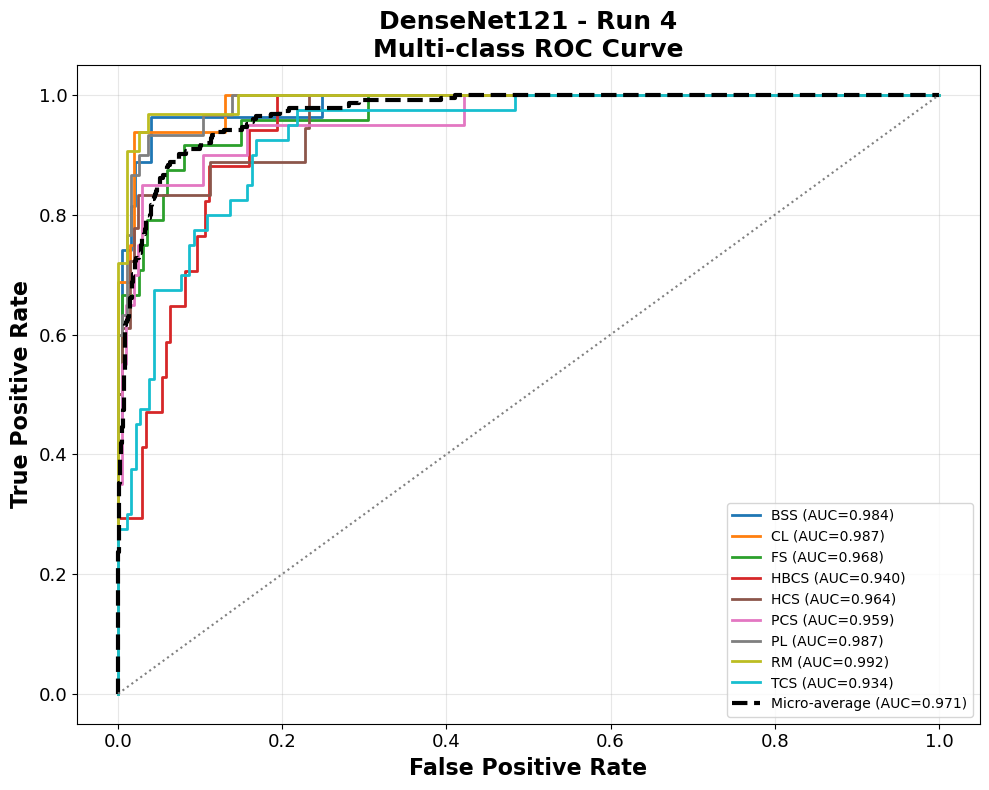


AUC Values
            Class       AUC
0             BSS  0.983644
1              CL  0.987380
2              FS  0.968333
3            HBCS  0.940324
4             HCS  0.963592
5             PCS  0.958824
6              PL  0.986770
7              RM  0.991536
8             TCS  0.934103
9   Micro Average  0.970967
10  Macro Average  0.968278

✓ ROC curve saved successfully.
✓ Completed Successfully

Run 5
Evaluating : DenseNet121 | Run 5

Loaded : DenseNet121_Run5.pkl



Images Evaluated : 224
Total Inference : 11.742 sec
Per Image       : 0.052421 sec
Computing Metrics : DenseNet121 | Run 5

Overall Performance
--------------------------------------------------
Accuracy              : 0.7411
Precision (Macro)     : 0.7362
Recall (Macro)        : 0.7258
F1 Score (Macro)      : 0.7276
Precision (Weighted)  : 0.7415
Recall (Weighted)     : 0.7411
F1 Score (Weighted)   : 0.7386
Balanced Accuracy     : 0.7258
Cohen Kappa           : 0.7048
MCC                   : 0.7053
Log Loss              : 0.7467
Confusion Matrix : DenseNet121 | Run 5


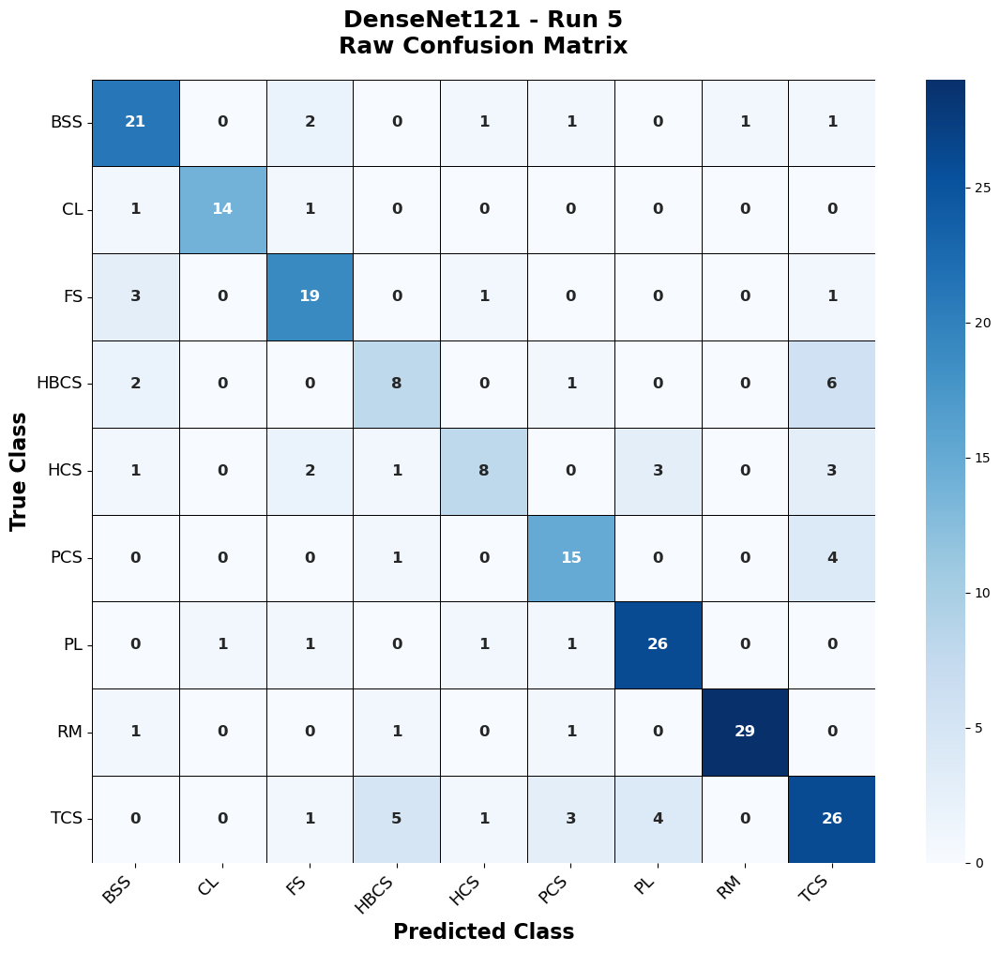

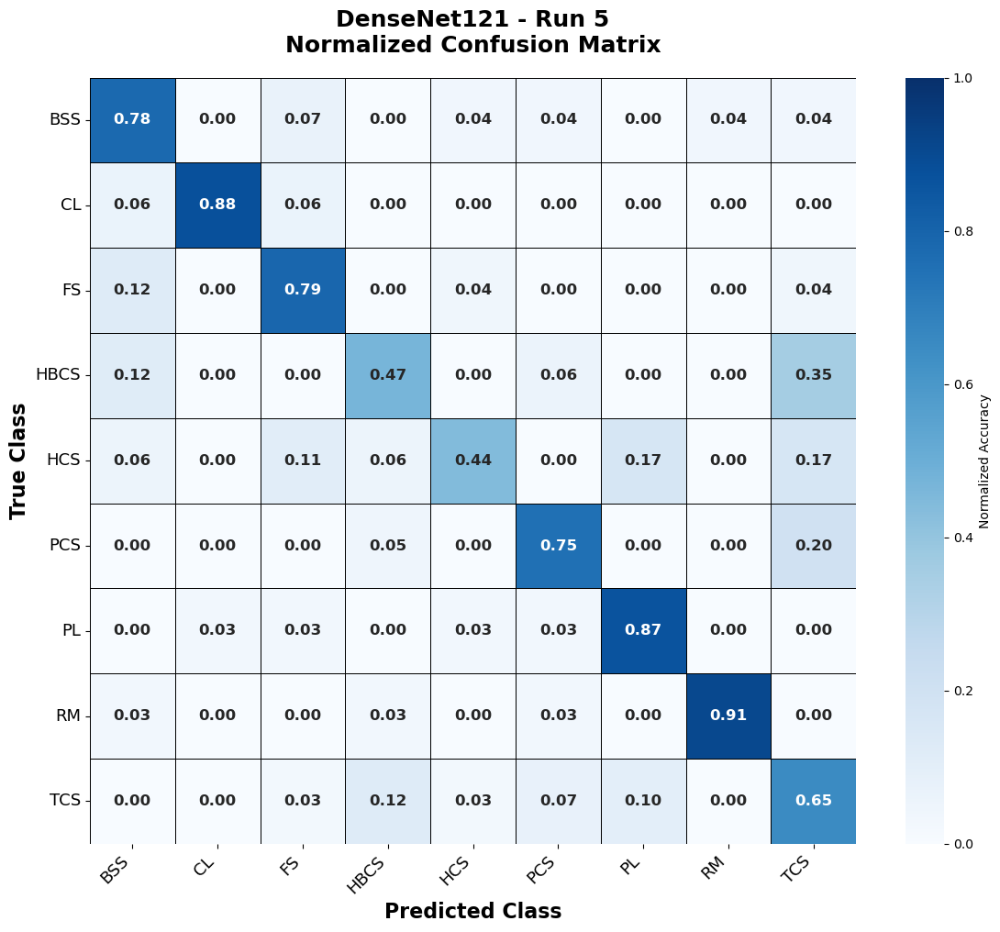


✓ Confusion matrices saved successfully
ROC Curve : DenseNet121 | Run 5


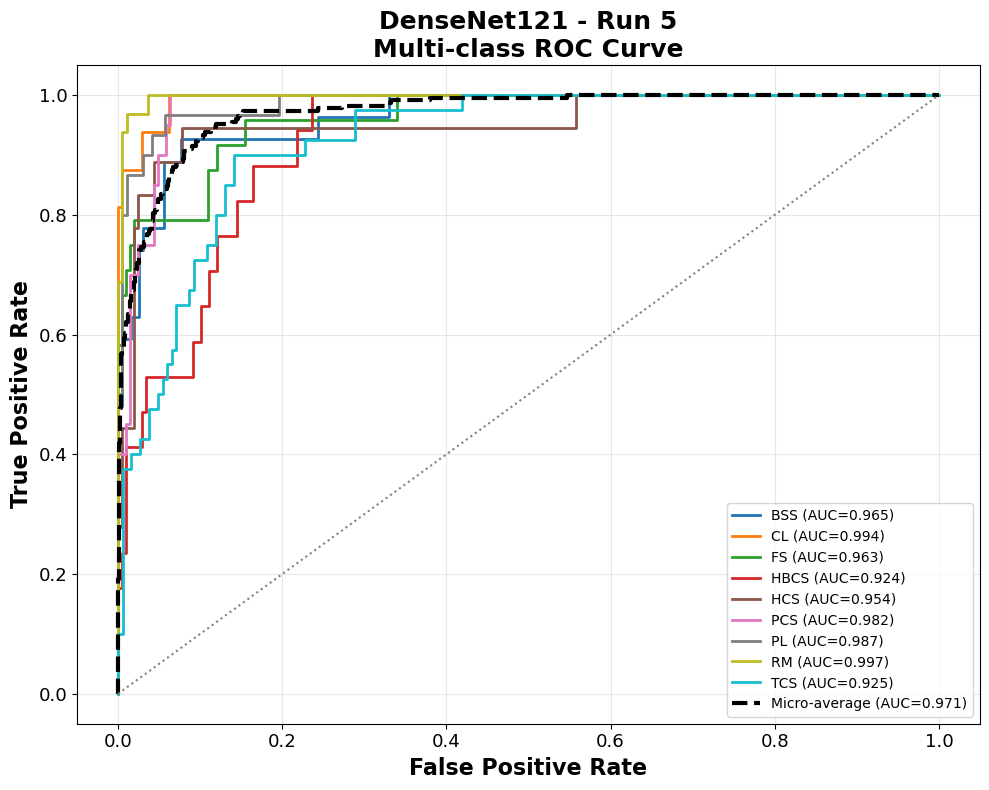


AUC Values
            Class       AUC
0             BSS  0.964655
1              CL  0.993990
2              FS  0.962917
3            HBCS  0.924410
4             HCS  0.953614
5             PCS  0.981618
6              PL  0.986942
7              RM  0.997233
8             TCS  0.924864
9   Micro Average  0.970760
10  Macro Average  0.965583

✓ ROC curve saved successfully.
✓ Completed Successfully

MODEL : MobileNetV3

Run 1
Evaluating : MobileNetV3 | Run 1

Loaded : MobileNetV3_Run1.pkl



Images Evaluated : 224
Total Inference : 3.706 sec
Per Image       : 0.016543 sec
Computing Metrics : MobileNetV3 | Run 1

Overall Performance
--------------------------------------------------
Accuracy              : 0.7098
Precision (Macro)     : 0.7191
Recall (Macro)        : 0.7056
F1 Score (Macro)      : 0.7036
Precision (Weighted)  : 0.7225
Recall (Weighted)     : 0.7098
F1 Score (Weighted)   : 0.7087
Balanced Accuracy     : 0.7056
Cohen Kappa           : 0.6702
MCC                   : 0.6722
Log Loss              : 0.9046
Confusion Matrix : MobileNetV3 | Run 1


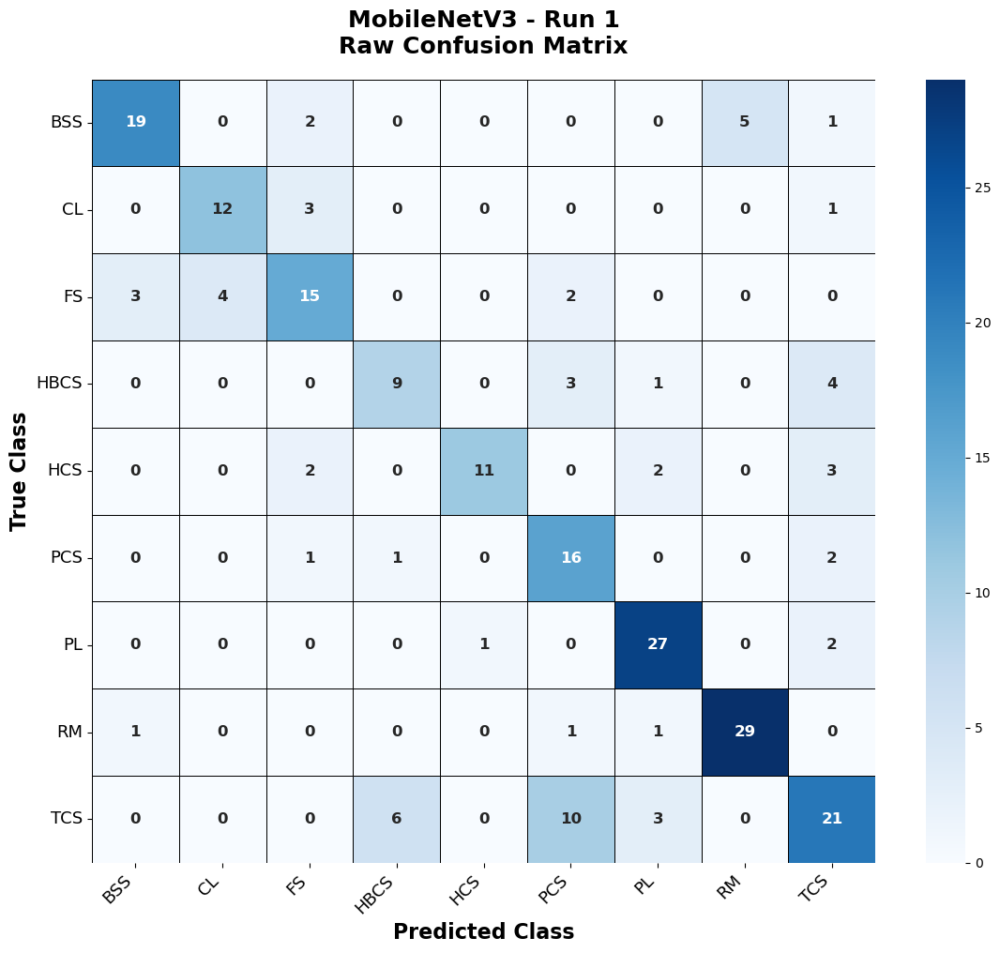

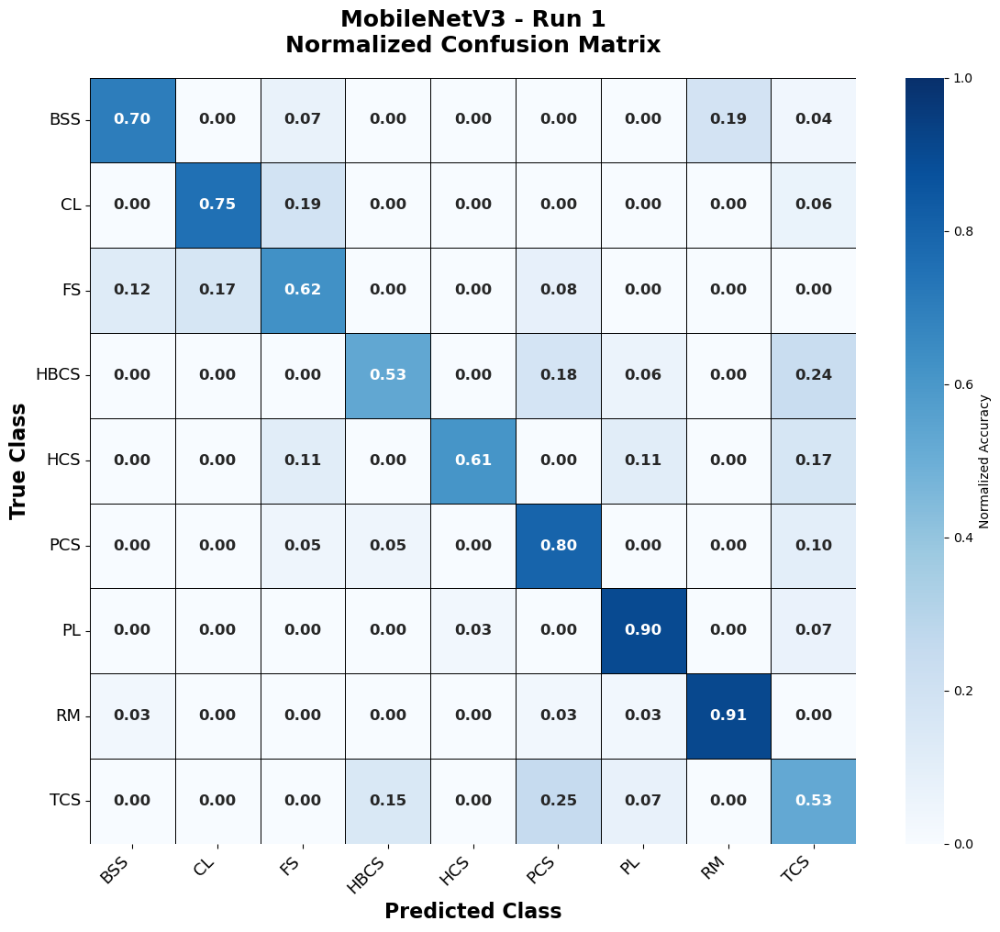


✓ Confusion matrices saved successfully
ROC Curve : MobileNetV3 | Run 1


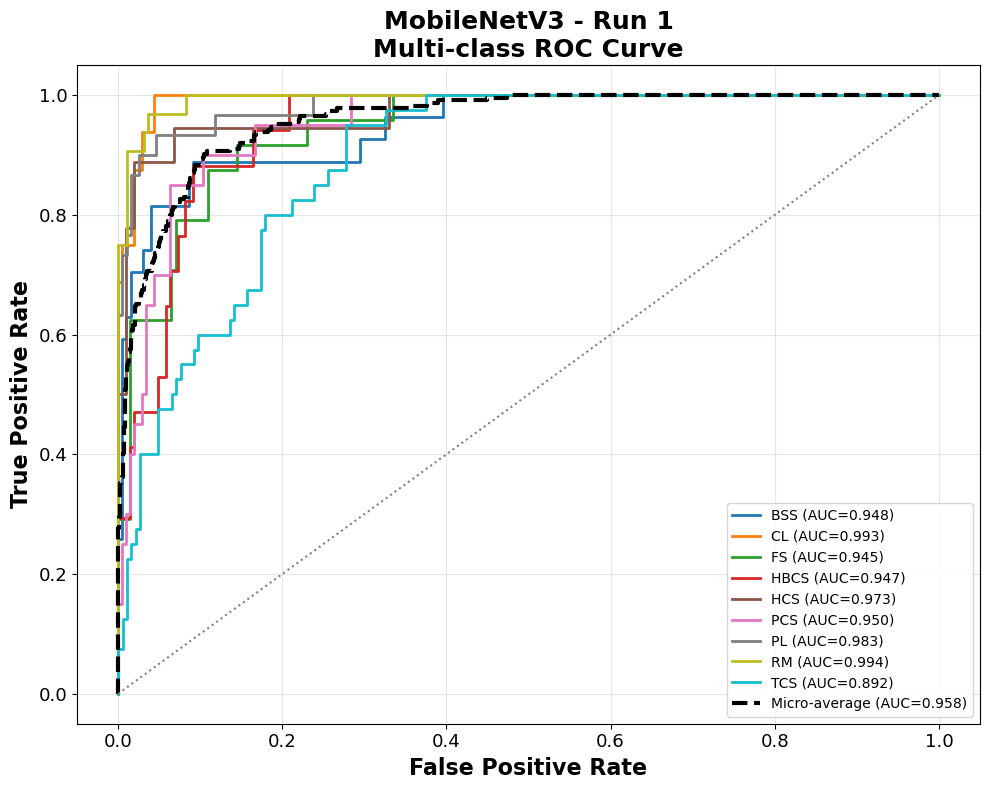


AUC Values
            Class       AUC
0             BSS  0.948487
1              CL  0.992788
2              FS  0.945000
3            HBCS  0.947428
4             HCS  0.973031
5             PCS  0.950490
6              PL  0.983333
7              RM  0.993652
8             TCS  0.891848
9   Micro Average  0.957941
10  Macro Average  0.958451

✓ ROC curve saved successfully.
✓ Completed Successfully

Run 2
Evaluating : MobileNetV3 | Run 2

Loaded : MobileNetV3_Run2.pkl



Images Evaluated : 224
Total Inference : 3.665 sec
Per Image       : 0.016360 sec
Computing Metrics : MobileNetV3 | Run 2

Overall Performance
--------------------------------------------------
Accuracy              : 0.6964
Precision (Macro)     : 0.7376
Recall (Macro)        : 0.6900
F1 Score (Macro)      : 0.6787
Precision (Weighted)  : 0.7368
Recall (Weighted)     : 0.6964
F1 Score (Weighted)   : 0.6849
Balanced Accuracy     : 0.6900
Cohen Kappa           : 0.6553
MCC                   : 0.6636
Log Loss              : 0.9485
Confusion Matrix : MobileNetV3 | Run 2


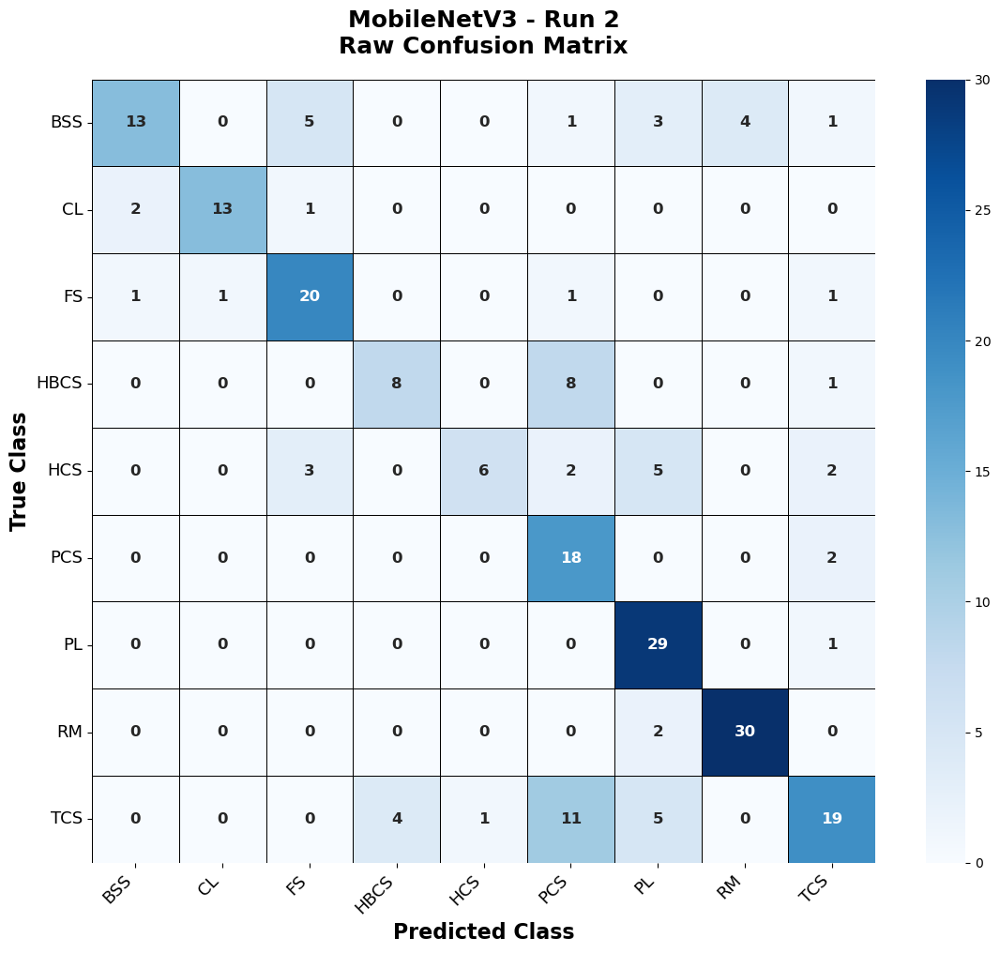

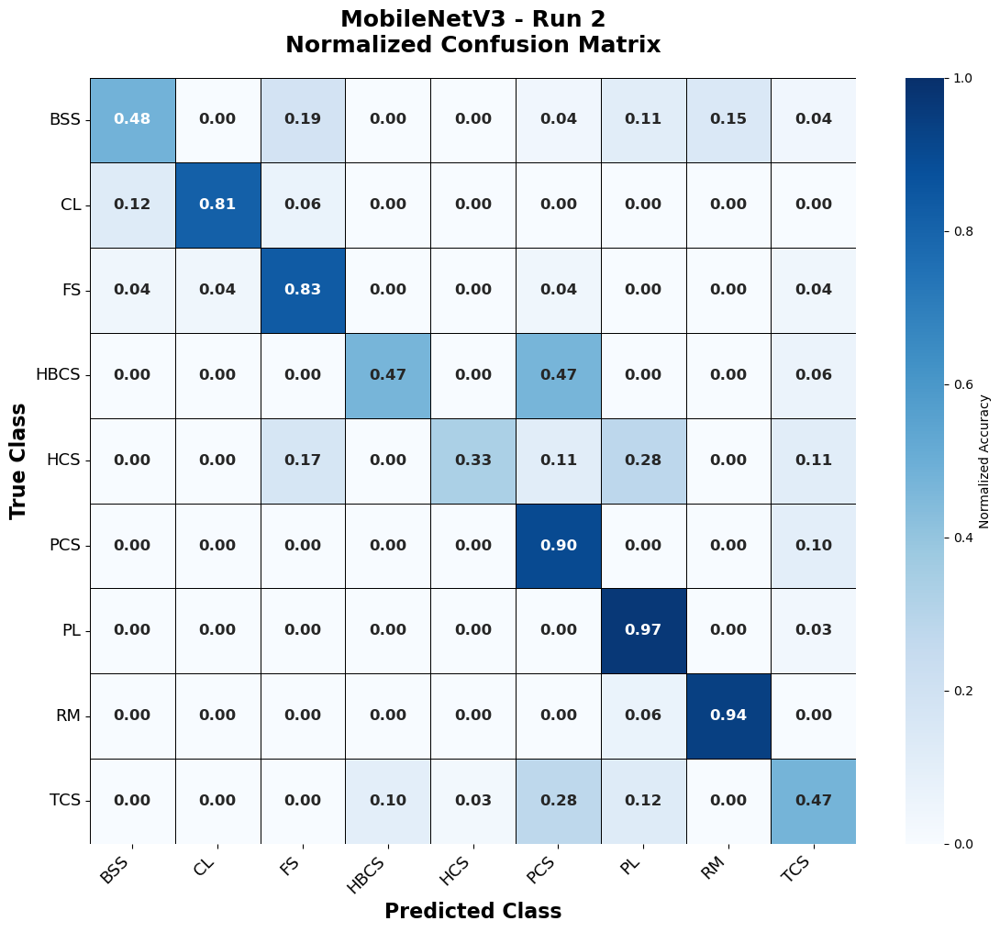


✓ Confusion matrices saved successfully
ROC Curve : MobileNetV3 | Run 2


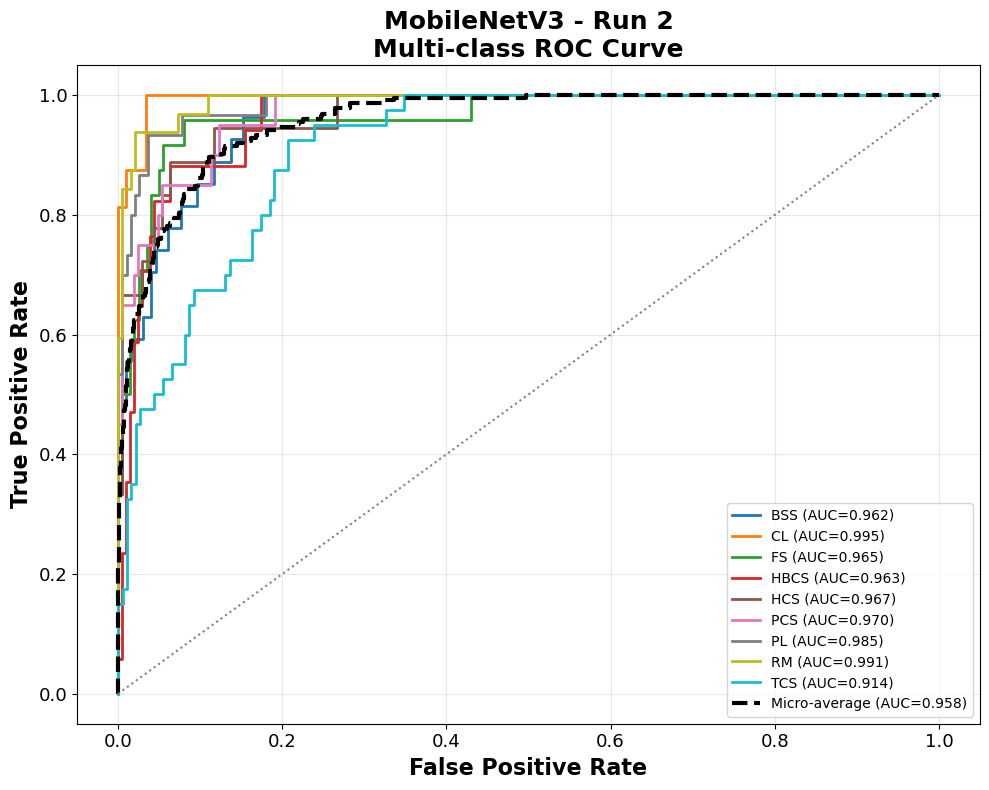


AUC Values
            Class       AUC
0             BSS  0.961835
1              CL  0.995192
2              FS  0.964792
3            HBCS  0.963058
4             HCS  0.966559
5             PCS  0.970343
6              PL  0.985223
7              RM  0.991211
8             TCS  0.913723
9   Micro Average  0.958142
10  Macro Average  0.967993

✓ ROC curve saved successfully.
✓ Completed Successfully

Run 3
Evaluating : MobileNetV3 | Run 3

Loaded : MobileNetV3_Run3.pkl



Images Evaluated : 224
Total Inference : 3.868 sec
Per Image       : 0.017268 sec
Computing Metrics : MobileNetV3 | Run 3

Overall Performance
--------------------------------------------------
Accuracy              : 0.6696
Precision (Macro)     : 0.6931
Recall (Macro)        : 0.6701
F1 Score (Macro)      : 0.6690
Precision (Weighted)  : 0.6867
Recall (Weighted)     : 0.6696
F1 Score (Weighted)   : 0.6668
Balanced Accuracy     : 0.6701
Cohen Kappa           : 0.6237
MCC                   : 0.6259
Log Loss              : 0.8997
Confusion Matrix : MobileNetV3 | Run 3


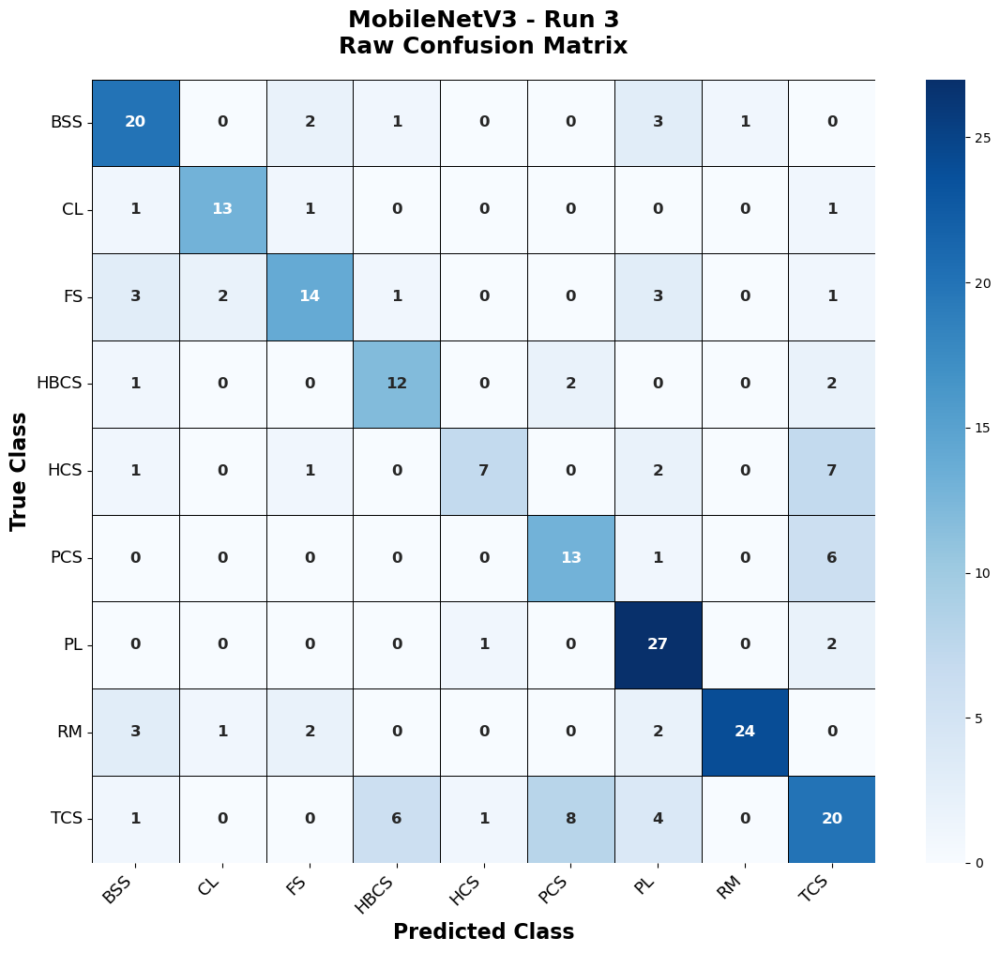

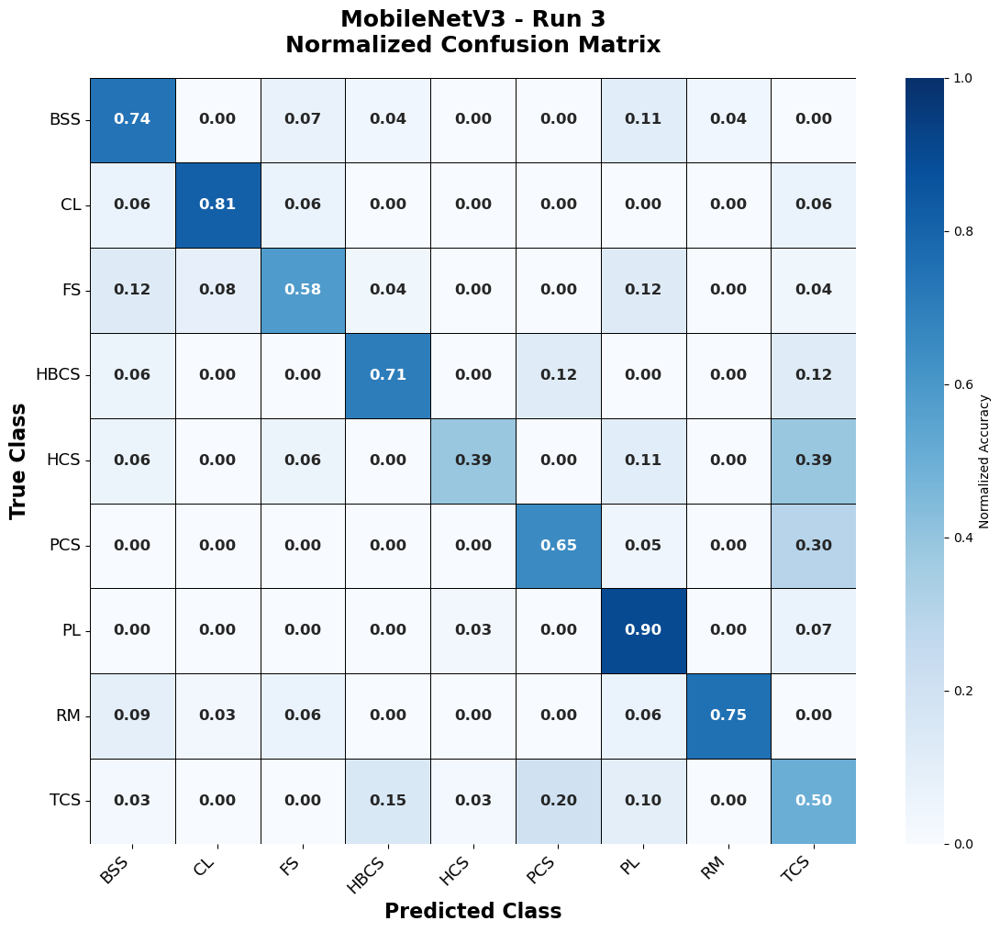


✓ Confusion matrices saved successfully
ROC Curve : MobileNetV3 | Run 3


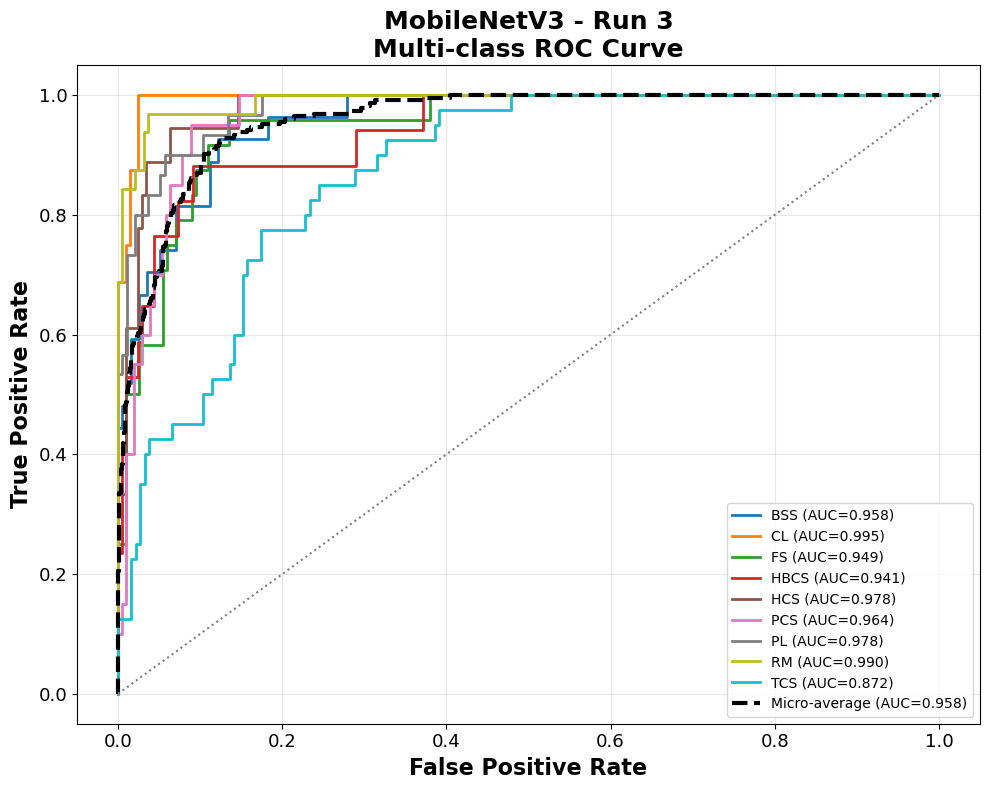


AUC Values
            Class       AUC
0             BSS  0.958075
1              CL  0.994591
2              FS  0.949375
3            HBCS  0.941176
4             HCS  0.978155
5             PCS  0.964216
6              PL  0.978179
7              RM  0.990234
8             TCS  0.872283
9   Micro Average  0.958247
10  Macro Average  0.958476

✓ ROC curve saved successfully.
✓ Completed Successfully

Run 4
Evaluating : MobileNetV3 | Run 4

Loaded : MobileNetV3_Run4.pkl



Images Evaluated : 224
Total Inference : 3.815 sec
Per Image       : 0.017031 sec
Computing Metrics : MobileNetV3 | Run 4

Overall Performance
--------------------------------------------------
Accuracy              : 0.6786
Precision (Macro)     : 0.7098
Recall (Macro)        : 0.6669
F1 Score (Macro)      : 0.6699
Precision (Weighted)  : 0.6996
Recall (Weighted)     : 0.6786
F1 Score (Weighted)   : 0.6732
Balanced Accuracy     : 0.6669
Cohen Kappa           : 0.6328
MCC                   : 0.6366
Log Loss              : 0.9199
Confusion Matrix : MobileNetV3 | Run 4


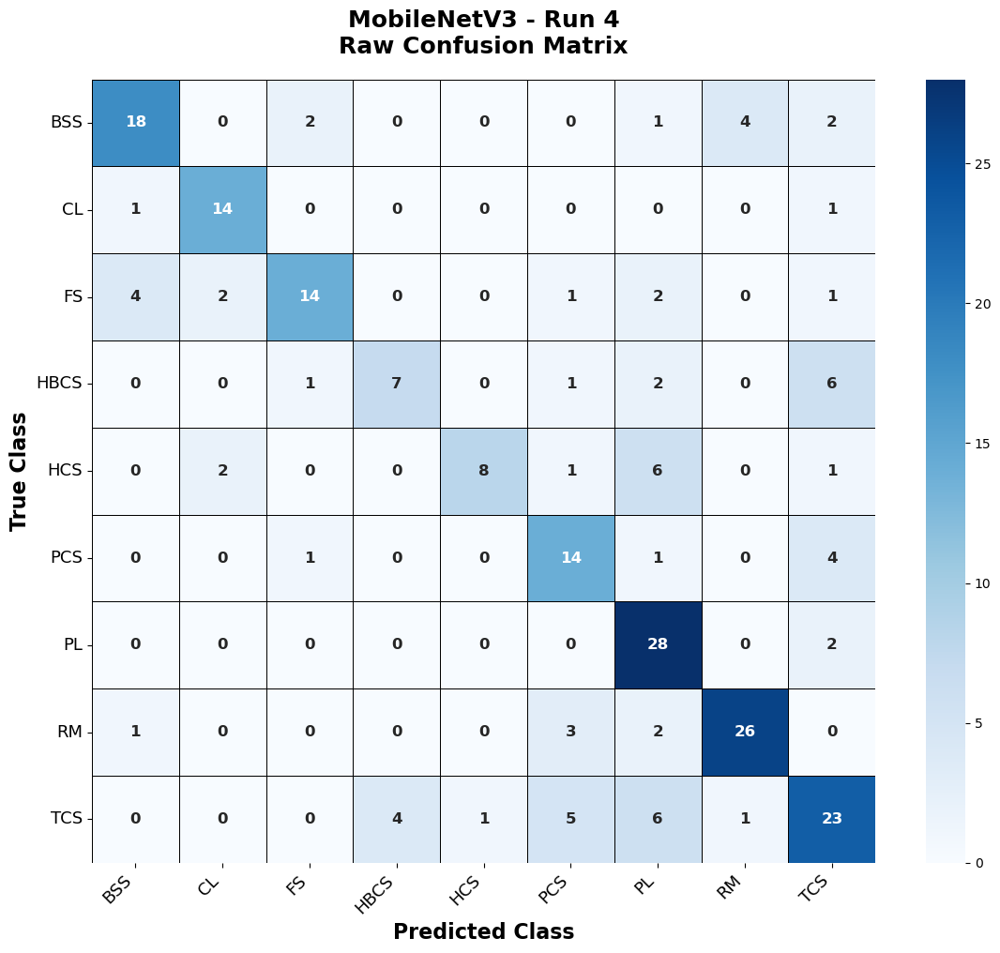

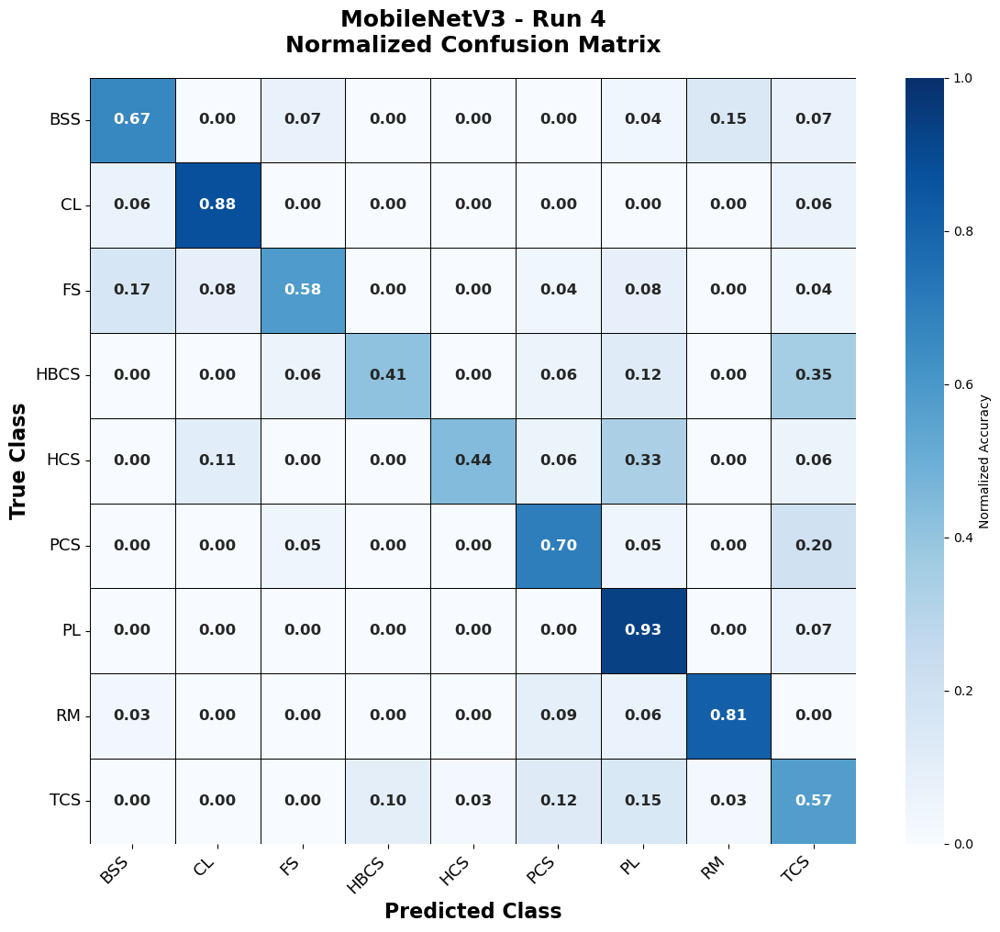


✓ Confusion matrices saved successfully
ROC Curve : MobileNetV3 | Run 4


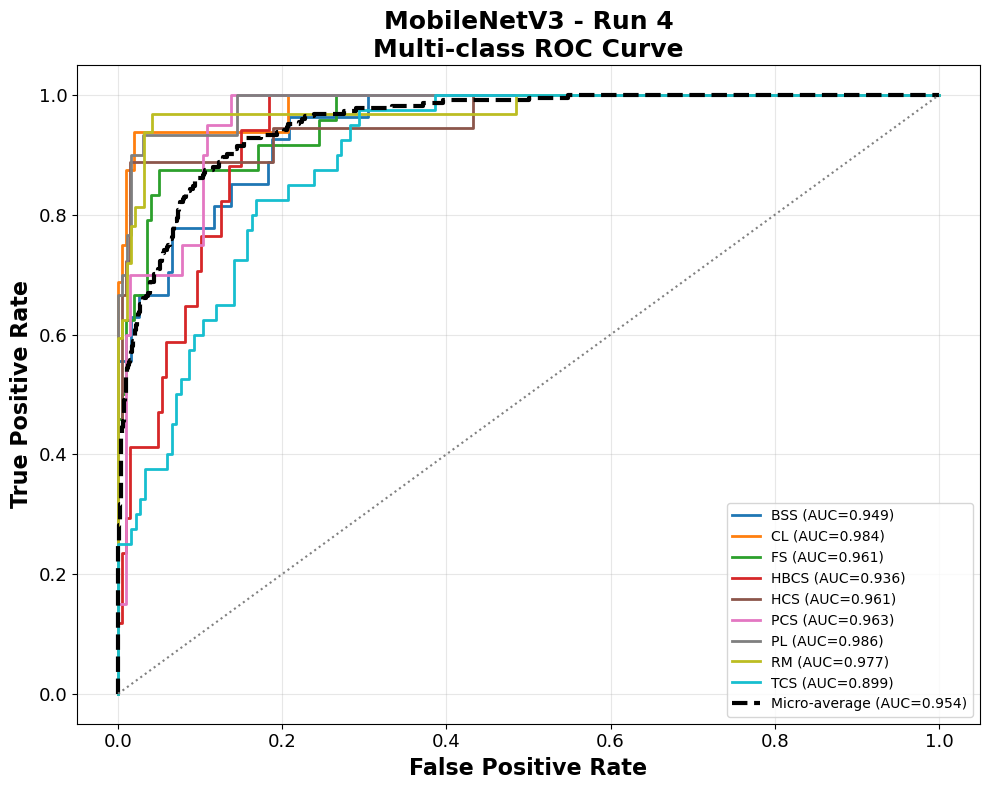


AUC Values
            Class       AUC
0             BSS  0.948675
1              CL  0.984375
2              FS  0.961250
3            HBCS  0.936346
4             HCS  0.961435
5             PCS  0.962500
6              PL  0.986426
7              RM  0.976888
8             TCS  0.898913
9   Micro Average  0.954064
10  Macro Average  0.957423

✓ ROC curve saved successfully.
✓ Completed Successfully

Run 5
Evaluating : MobileNetV3 | Run 5

Loaded : MobileNetV3_Run5.pkl



Images Evaluated : 224
Total Inference : 3.813 sec
Per Image       : 0.017024 sec
Computing Metrics : MobileNetV3 | Run 5

Overall Performance
--------------------------------------------------
Accuracy              : 0.6607
Precision (Macro)     : 0.7085
Recall (Macro)        : 0.6605
F1 Score (Macro)      : 0.6519
Precision (Weighted)  : 0.6979
Recall (Weighted)     : 0.6607
F1 Score (Weighted)   : 0.6516
Balanced Accuracy     : 0.6605
Cohen Kappa           : 0.6142
MCC                   : 0.6200
Log Loss              : 1.0778
Confusion Matrix : MobileNetV3 | Run 5


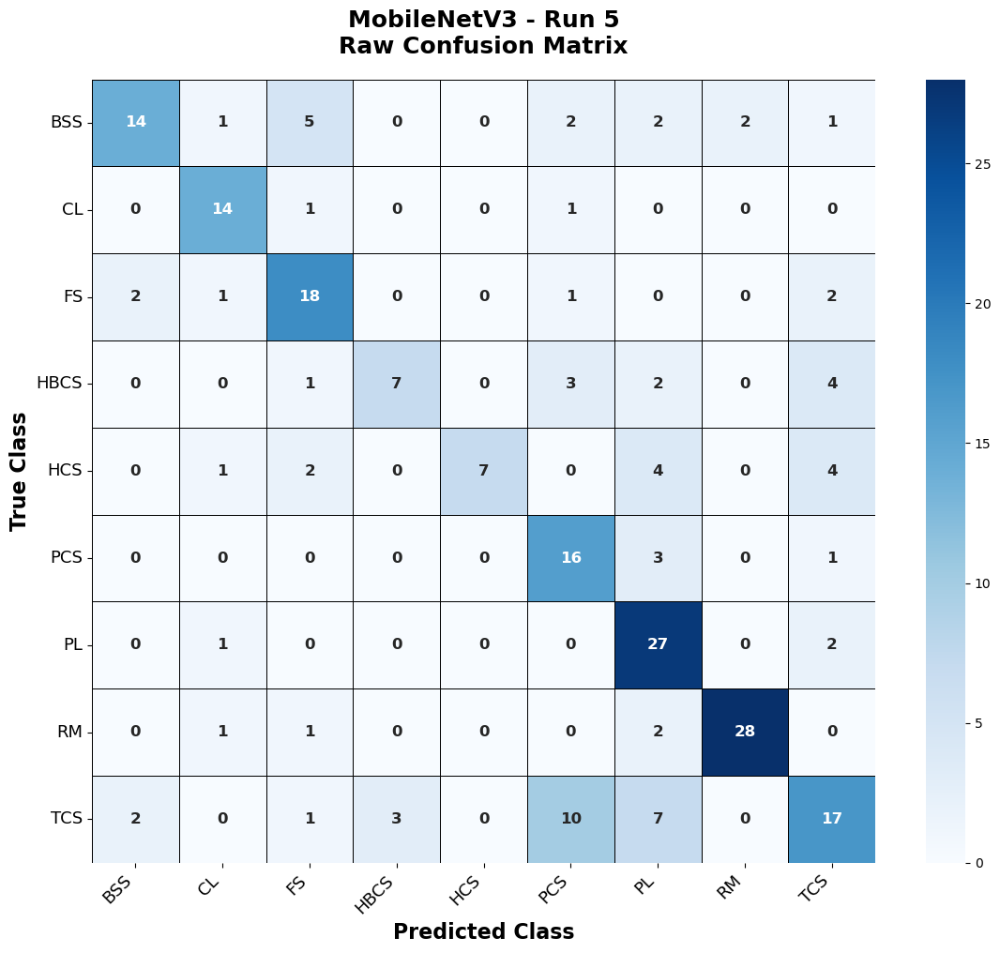

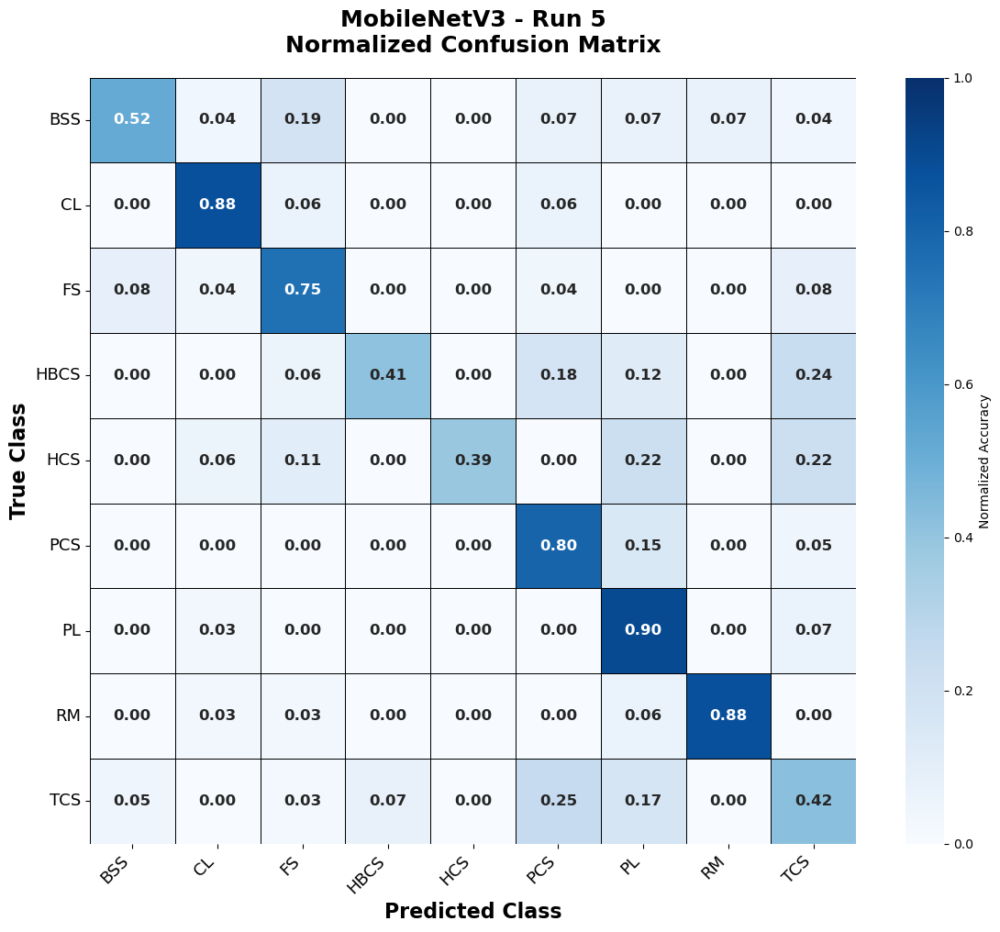


✓ Confusion matrices saved successfully
ROC Curve : MobileNetV3 | Run 5


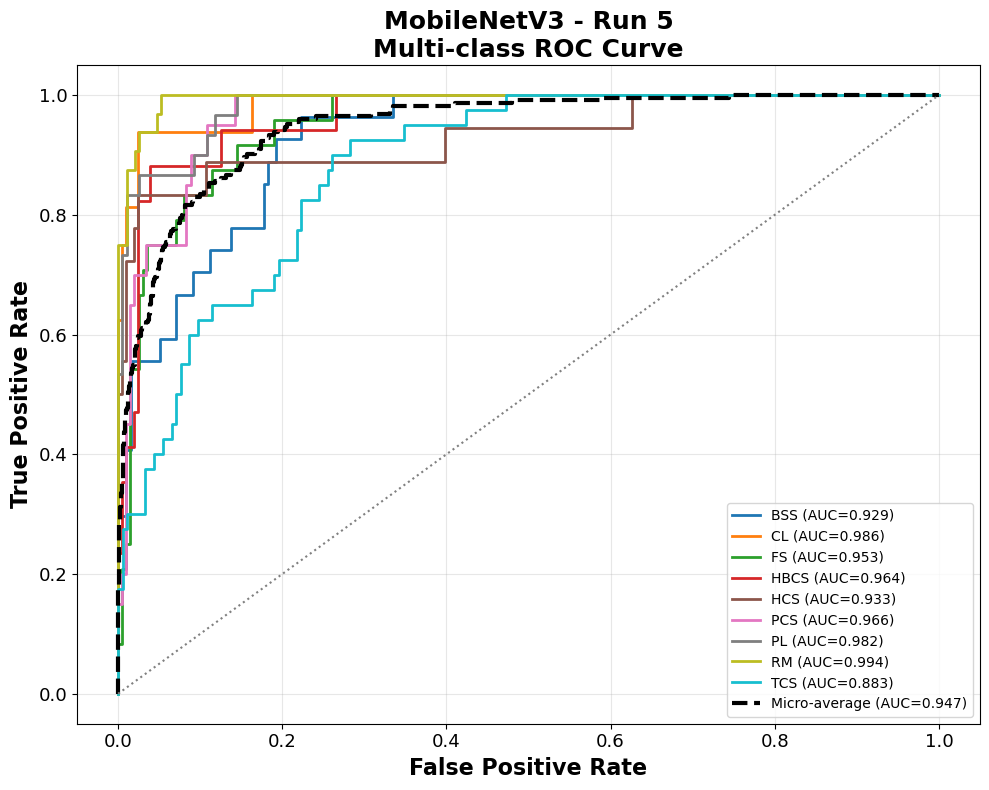


AUC Values
            Class       AUC
0             BSS  0.929122
1              CL  0.985577
2              FS  0.952917
3            HBCS  0.963910
4             HCS  0.932848
5             PCS  0.966422
6              PL  0.981615
7              RM  0.994141
8             TCS  0.882745
9   Micro Average  0.947007
10  Macro Average  0.954366

✓ ROC curve saved successfully.
✓ Completed Successfully

MODEL : EfficientNet_B0

Run 1
Evaluating : EfficientNet_B0 | Run 1

Loaded : EfficientNet_B0_Run1.pkl



Images Evaluated : 224
Total Inference : 6.138 sec
Per Image       : 0.027403 sec
Computing Metrics : EfficientNet_B0 | Run 1

Overall Performance
--------------------------------------------------
Accuracy              : 0.7009
Precision (Macro)     : 0.6911
Recall (Macro)        : 0.6997
F1 Score (Macro)      : 0.6908
Precision (Weighted)  : 0.7024
Recall (Weighted)     : 0.7009
F1 Score (Weighted)   : 0.6953
Balanced Accuracy     : 0.6997
Cohen Kappa           : 0.6606
MCC                   : 0.6627
Log Loss              : 1.0760
Confusion Matrix : EfficientNet_B0 | Run 1


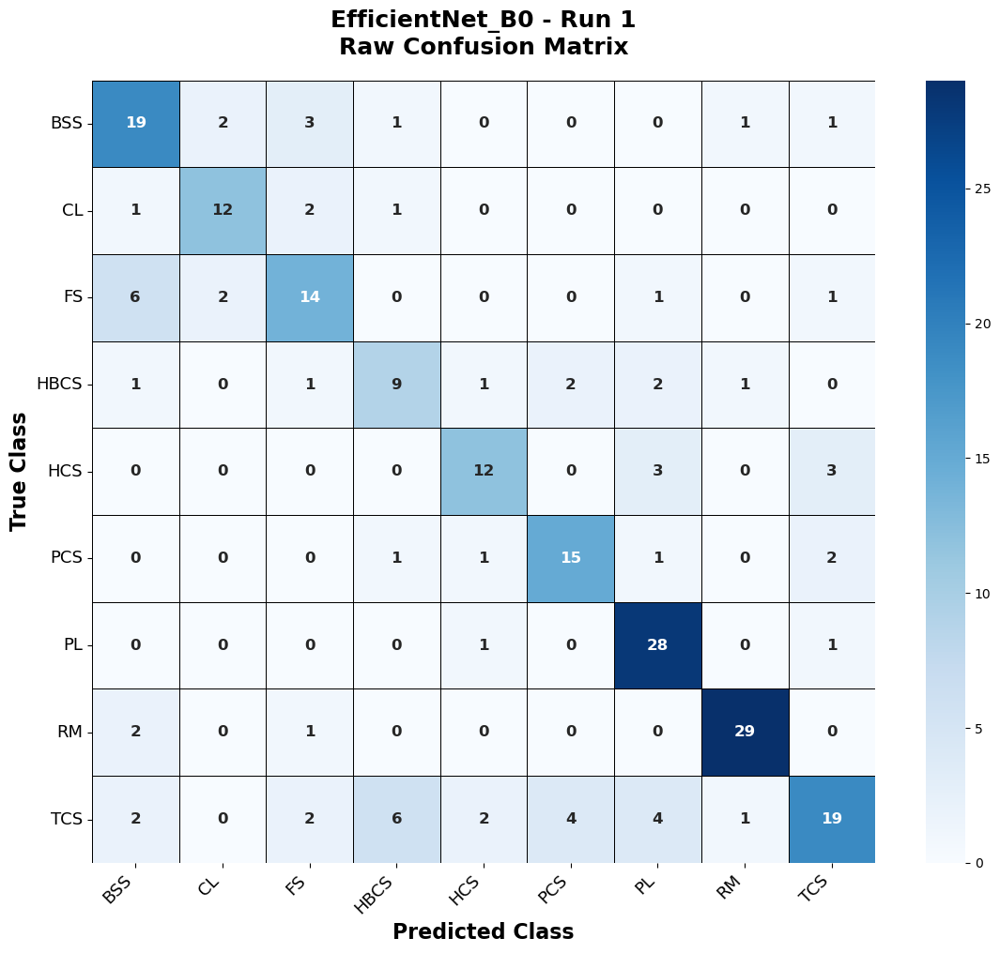

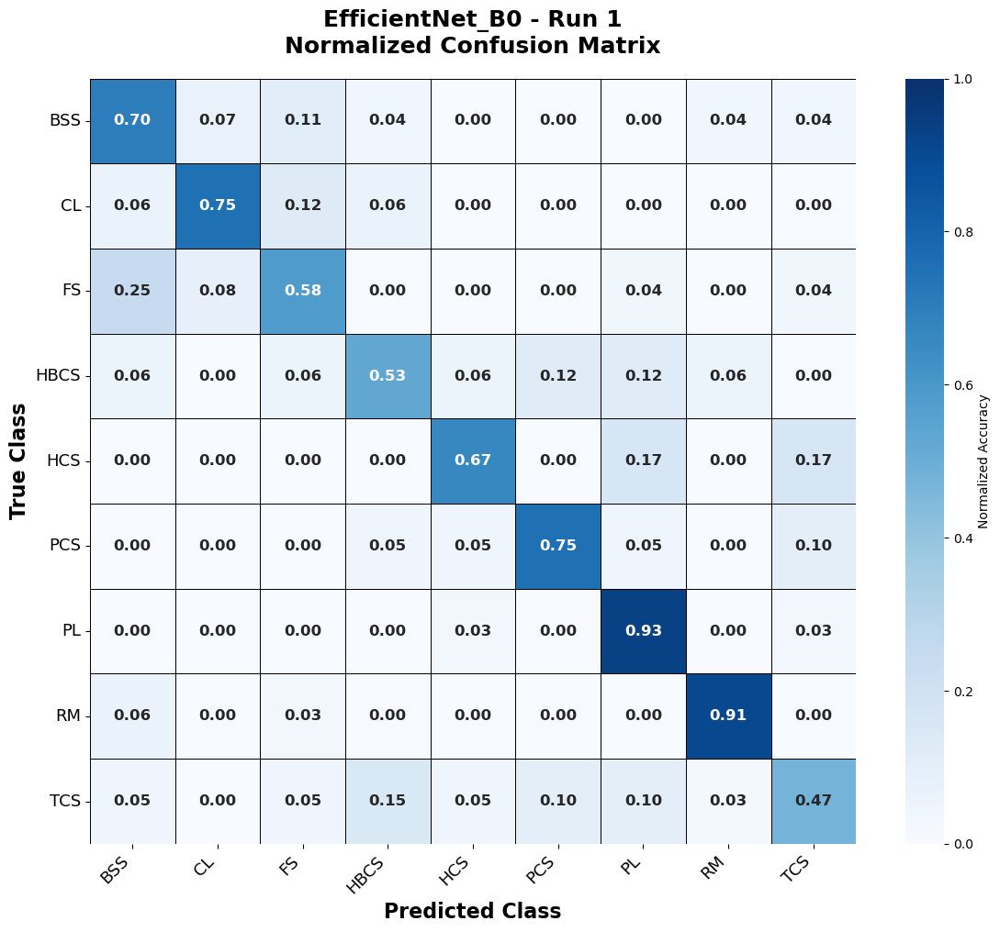


✓ Confusion matrices saved successfully
ROC Curve : EfficientNet_B0 | Run 1


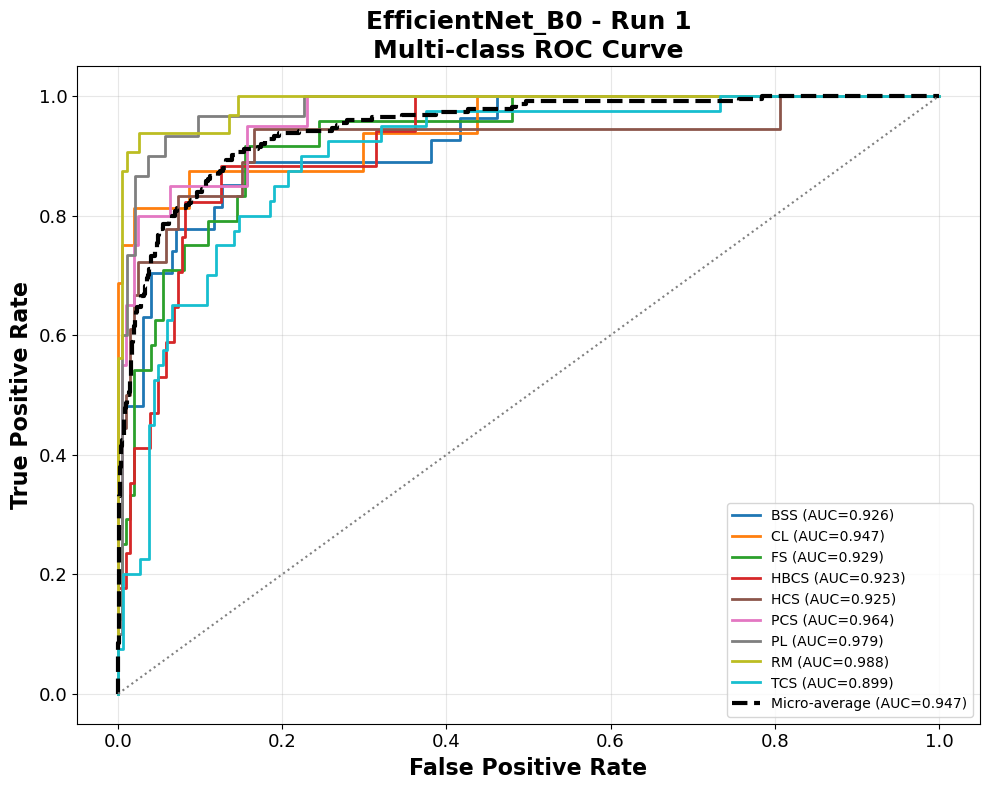


AUC Values
            Class       AUC
0             BSS  0.925550
1              CL  0.947115
2              FS  0.928958
3            HBCS  0.923274
4             HCS  0.925027
5             PCS  0.964461
6              PL  0.979381
7              RM  0.988444
8             TCS  0.898777
9   Micro Average  0.946969
10  Macro Average  0.942332

✓ ROC curve saved successfully.
✓ Completed Successfully

Run 2
Evaluating : EfficientNet_B0 | Run 2

Loaded : EfficientNet_B0_Run2.pkl



Images Evaluated : 224
Total Inference : 6.259 sec
Per Image       : 0.027941 sec
Computing Metrics : EfficientNet_B0 | Run 2

Overall Performance
--------------------------------------------------
Accuracy              : 0.6964
Precision (Macro)     : 0.6912
Recall (Macro)        : 0.6737
F1 Score (Macro)      : 0.6772
Precision (Weighted)  : 0.6969
Recall (Weighted)     : 0.6964
F1 Score (Weighted)   : 0.6920
Balanced Accuracy     : 0.6737
Cohen Kappa           : 0.6536
MCC                   : 0.6548
Log Loss              : 0.9525
Confusion Matrix : EfficientNet_B0 | Run 2


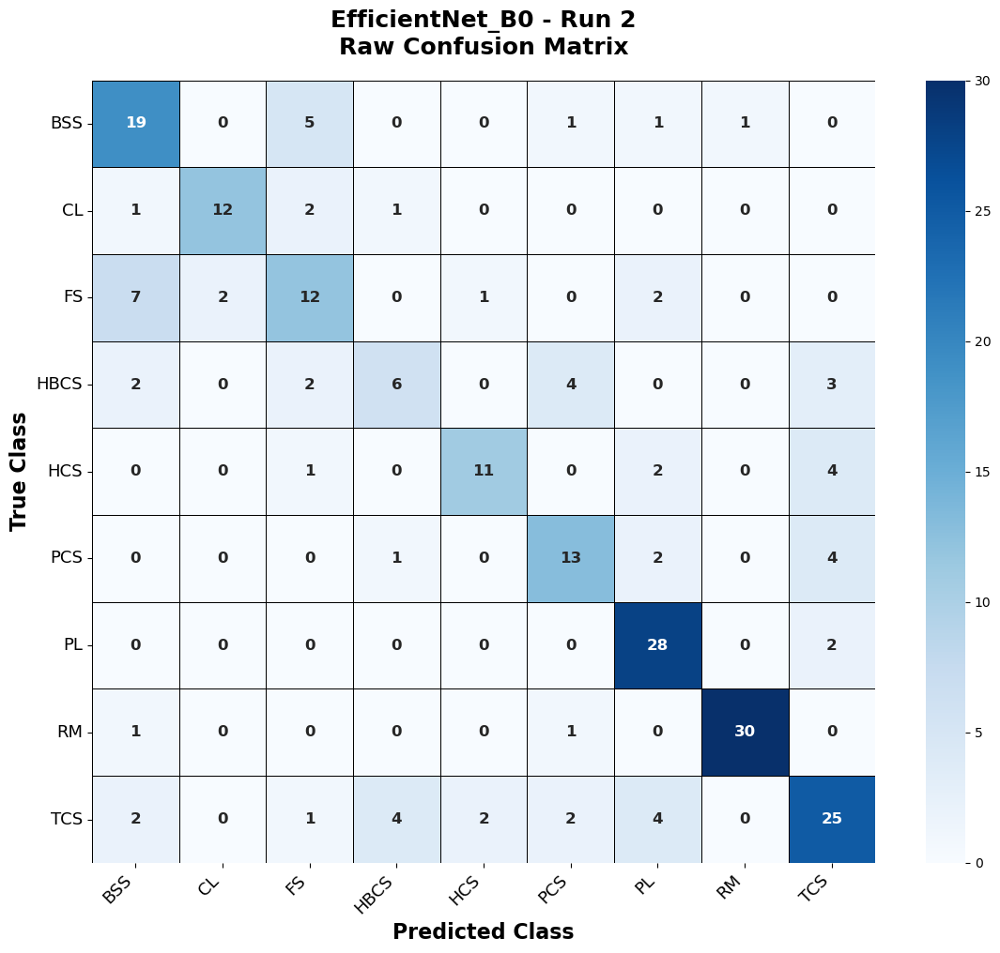

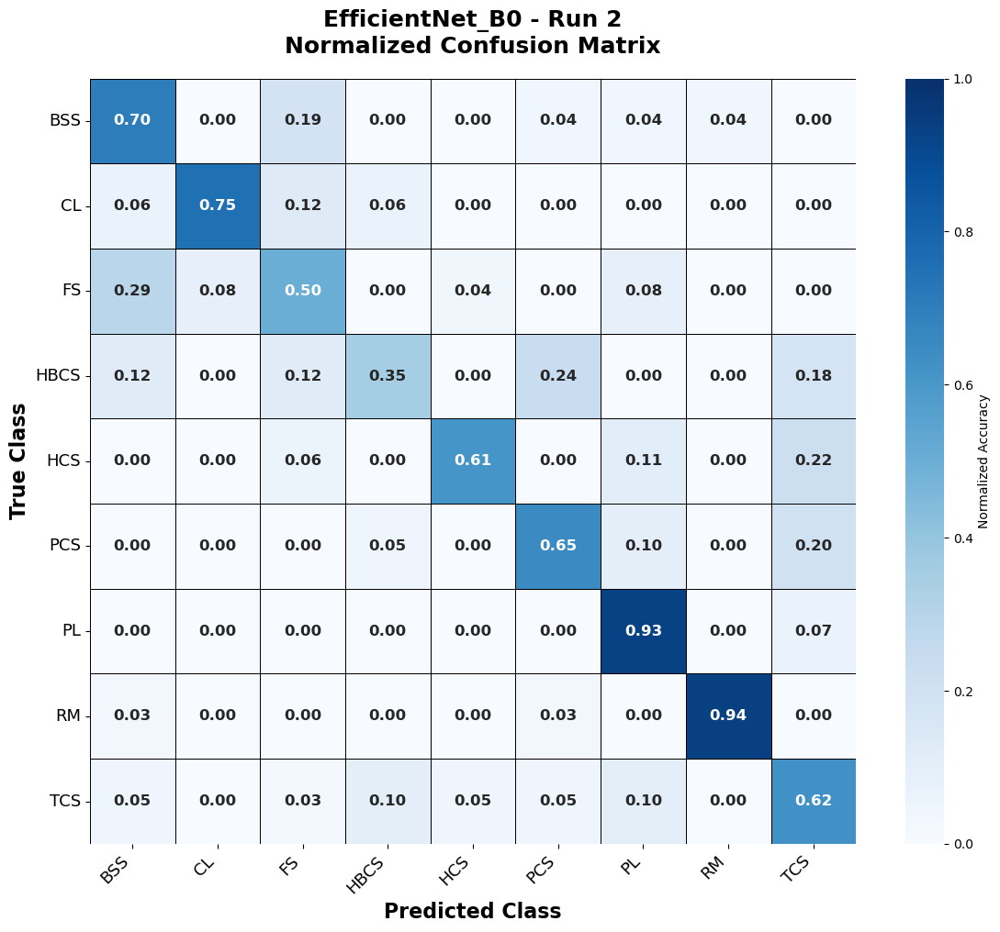


✓ Confusion matrices saved successfully
ROC Curve : EfficientNet_B0 | Run 2


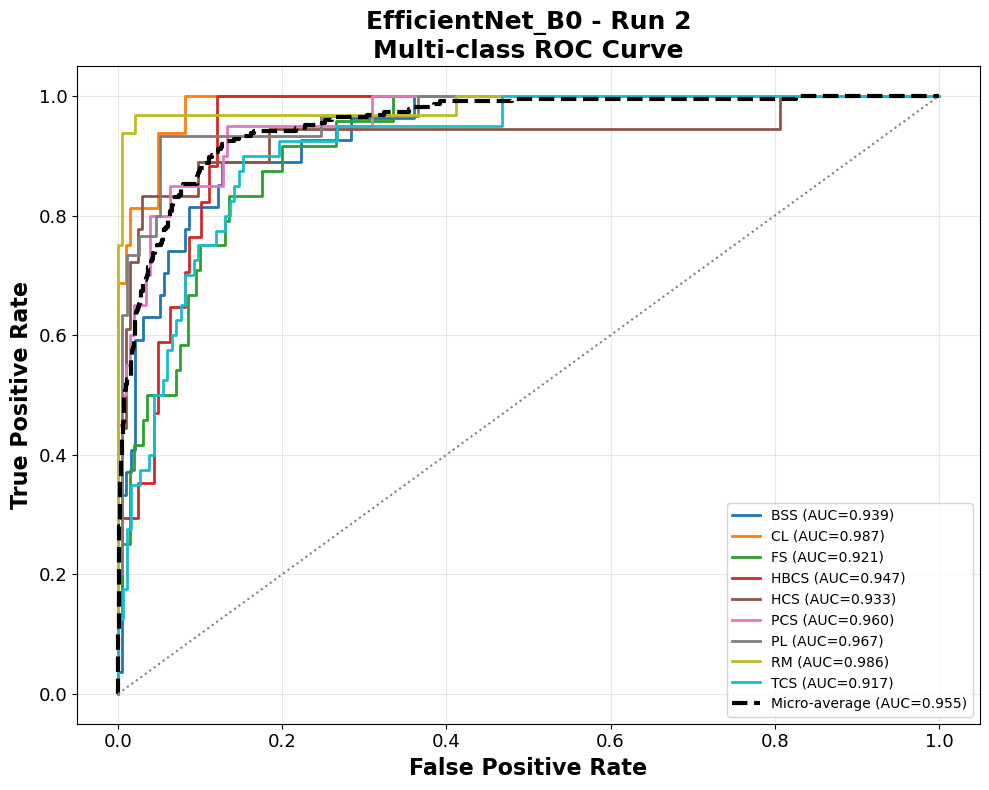


AUC Values
            Class       AUC
0             BSS  0.938898
1              CL  0.987380
2              FS  0.921250
3            HBCS  0.947428
4             HCS  0.932848
5             PCS  0.960294
6              PL  0.967010
7              RM  0.985514
8             TCS  0.917391
9   Micro Average  0.954921
10  Macro Average  0.950890

✓ ROC curve saved successfully.
✓ Completed Successfully

Run 3
Evaluating : EfficientNet_B0 | Run 3

Loaded : EfficientNet_B0_Run3.pkl



Images Evaluated : 224
Total Inference : 6.125 sec
Per Image       : 0.027346 sec
Computing Metrics : EfficientNet_B0 | Run 3

Overall Performance
--------------------------------------------------
Accuracy              : 0.7143
Precision (Macro)     : 0.7337
Recall (Macro)        : 0.6981
F1 Score (Macro)      : 0.7074
Precision (Weighted)  : 0.7214
Recall (Weighted)     : 0.7143
F1 Score (Weighted)   : 0.7106
Balanced Accuracy     : 0.6981
Cohen Kappa           : 0.6733
MCC                   : 0.6750
Log Loss              : 0.8554
Confusion Matrix : EfficientNet_B0 | Run 3


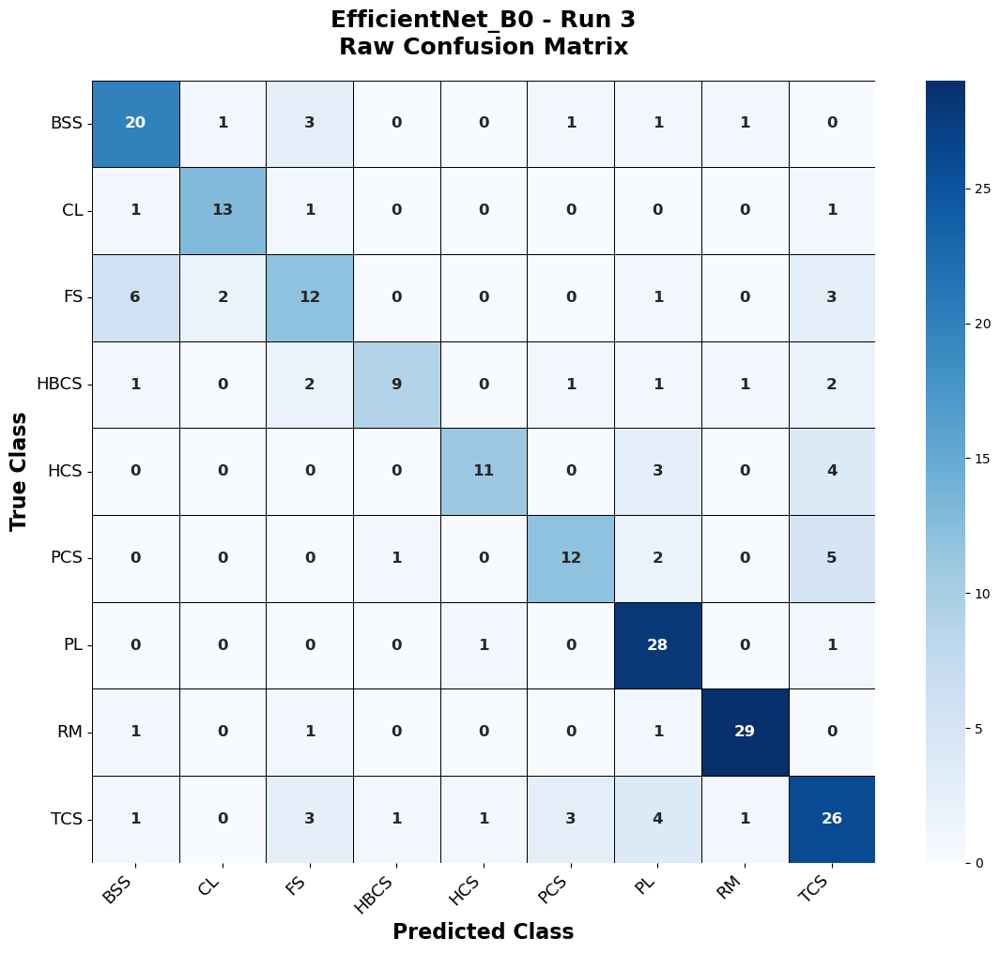

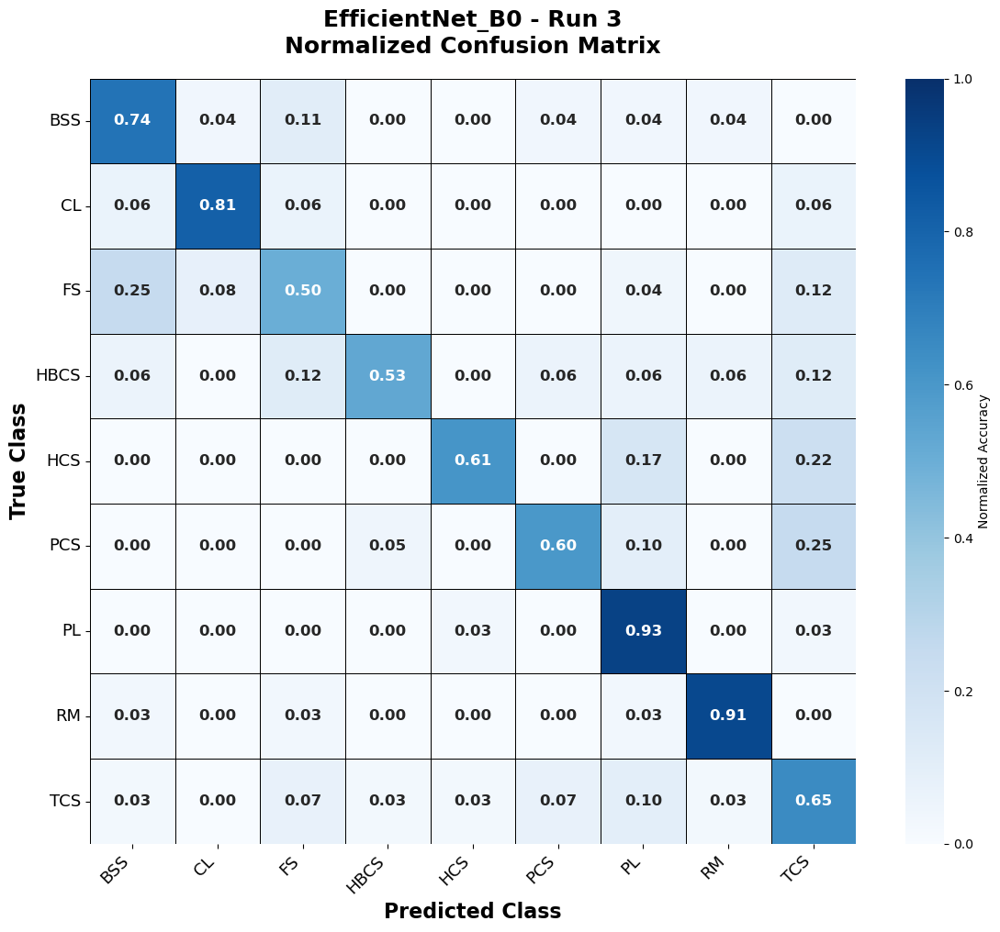


✓ Confusion matrices saved successfully
ROC Curve : EfficientNet_B0 | Run 3


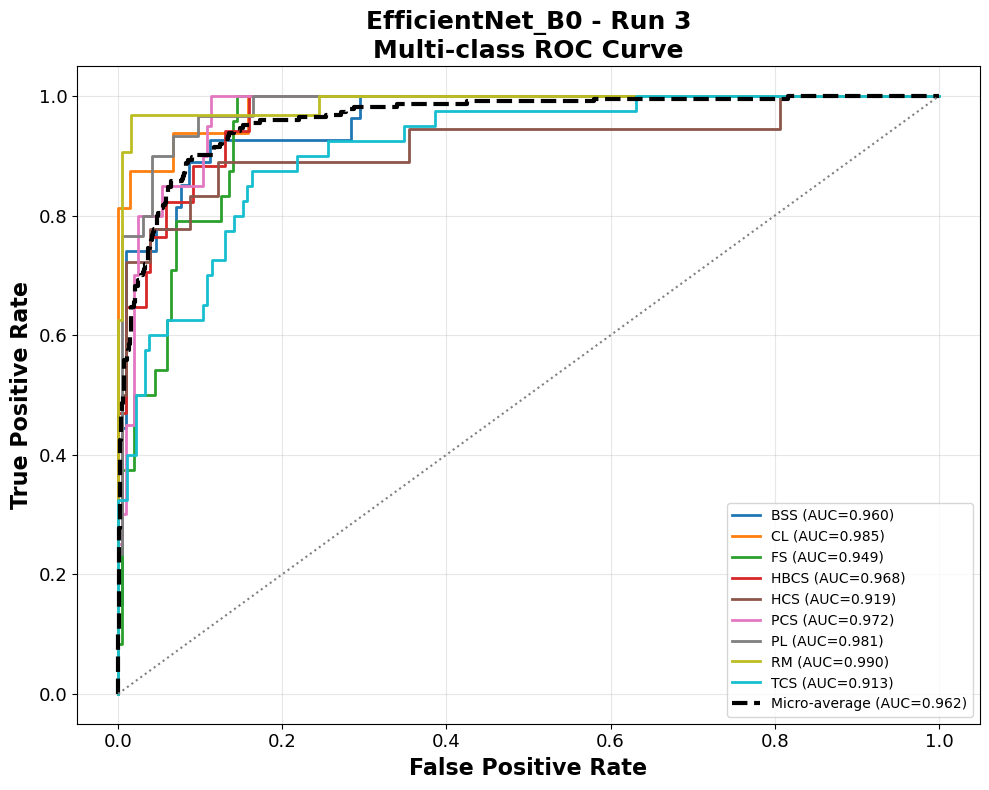


AUC Values
            Class       AUC
0             BSS  0.959579
1              CL  0.984976
2              FS  0.949375
3            HBCS  0.968173
4             HCS  0.918554
5             PCS  0.972059
6              PL  0.981100
7              RM  0.989909
8             TCS  0.913451
9   Micro Average  0.961899
10  Macro Average  0.959686

✓ ROC curve saved successfully.
✓ Completed Successfully

Run 4
Evaluating : EfficientNet_B0 | Run 4

Loaded : EfficientNet_B0_Run4.pkl



Images Evaluated : 224
Total Inference : 5.936 sec
Per Image       : 0.026498 sec
Computing Metrics : EfficientNet_B0 | Run 4

Overall Performance
--------------------------------------------------
Accuracy              : 0.7009
Precision (Macro)     : 0.6973
Recall (Macro)        : 0.6858
F1 Score (Macro)      : 0.6889
Precision (Weighted)  : 0.7042
Recall (Weighted)     : 0.7009
F1 Score (Weighted)   : 0.7002
Balanced Accuracy     : 0.6858
Cohen Kappa           : 0.6593
MCC                   : 0.6598
Log Loss              : 0.9158
Confusion Matrix : EfficientNet_B0 | Run 4


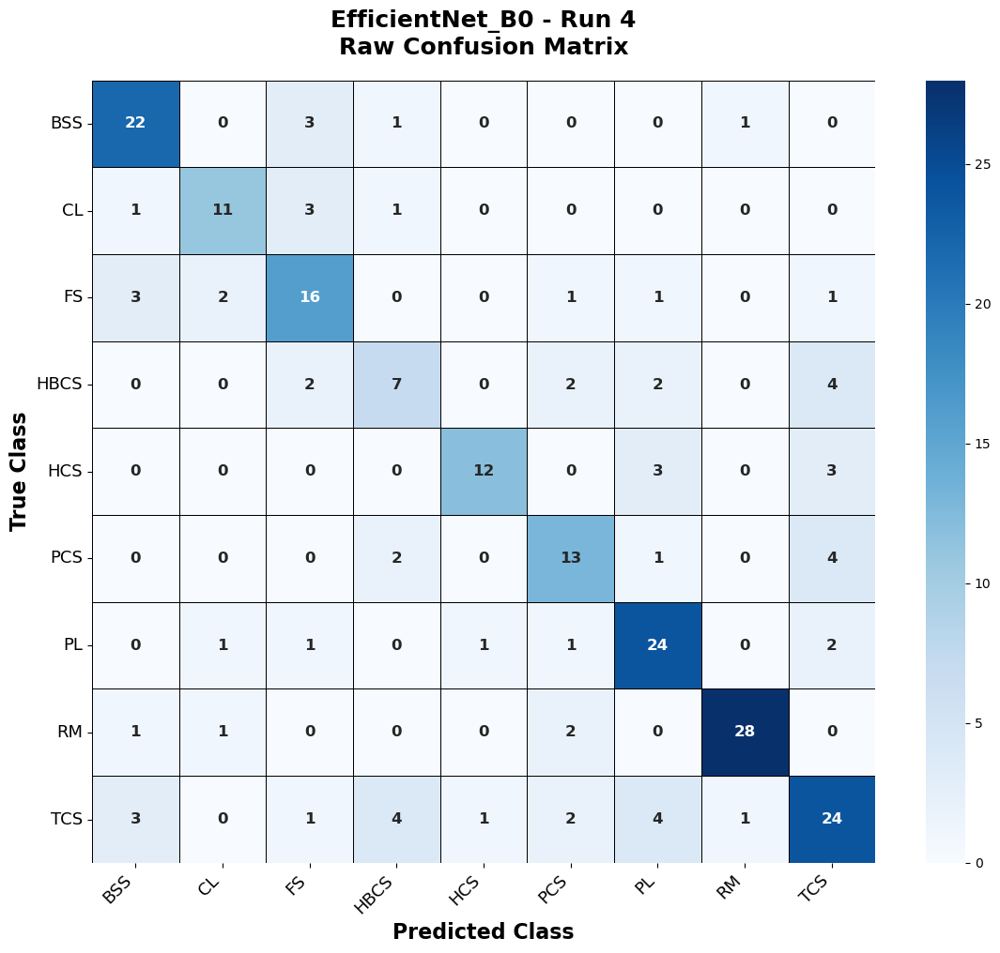

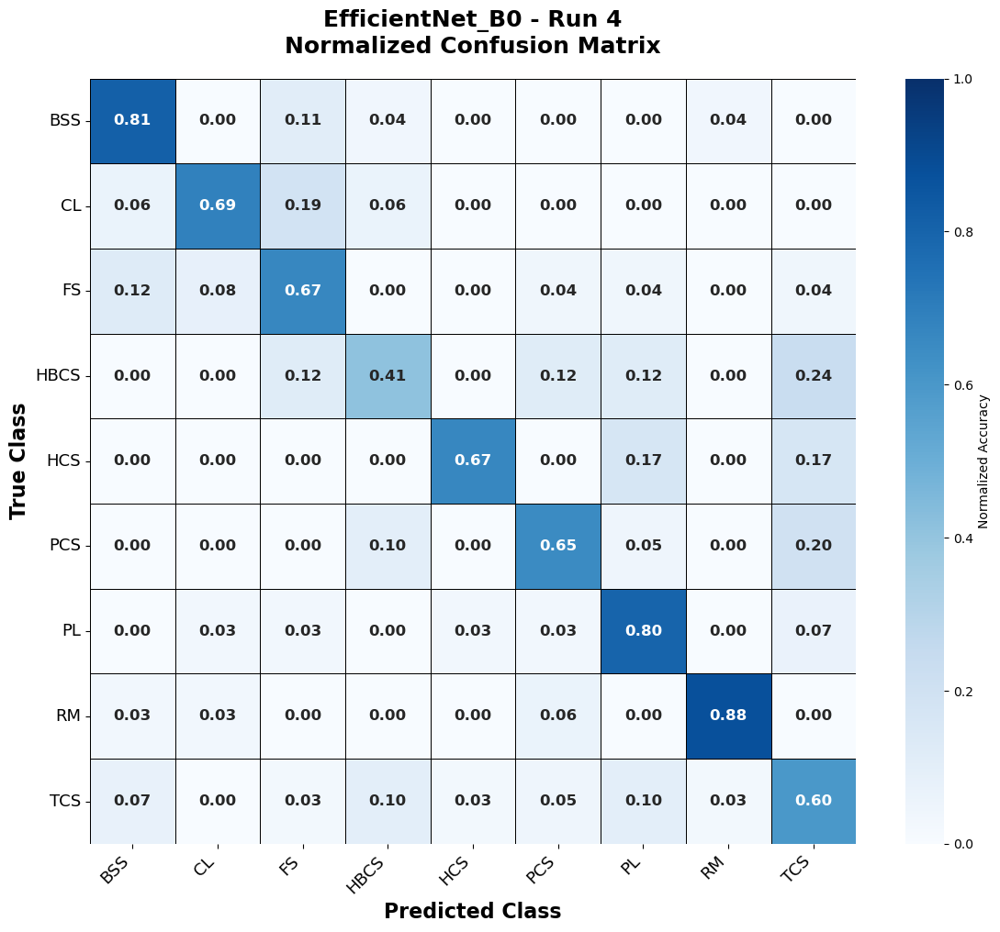


✓ Confusion matrices saved successfully
ROC Curve : EfficientNet_B0 | Run 4


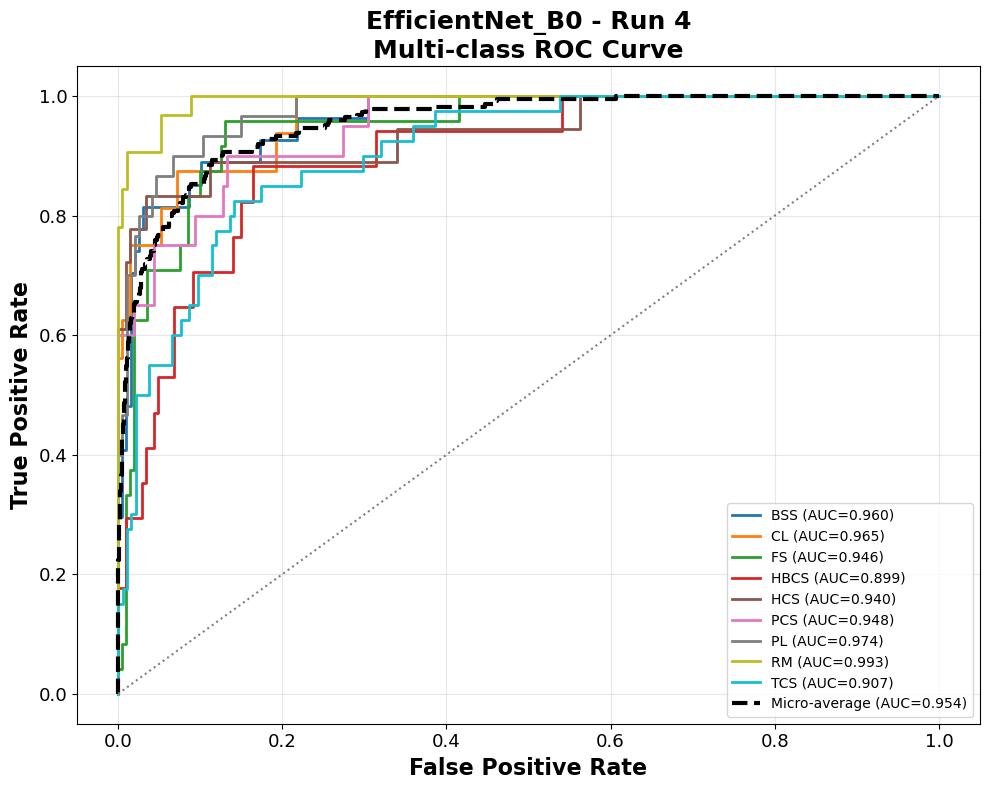


AUC Values
            Class       AUC
0             BSS  0.959767
1              CL  0.964543
2              FS  0.946458
3            HBCS  0.899403
4             HCS  0.939860
5             PCS  0.948039
6              PL  0.974227
7              RM  0.993001
8             TCS  0.906793
9   Micro Average  0.954196
10  Macro Average  0.948010

✓ ROC curve saved successfully.
✓ Completed Successfully

Run 5
Evaluating : EfficientNet_B0 | Run 5

Loaded : EfficientNet_B0_Run5.pkl



Images Evaluated : 224
Total Inference : 5.906 sec
Per Image       : 0.026365 sec
Computing Metrics : EfficientNet_B0 | Run 5

Overall Performance
--------------------------------------------------
Accuracy              : 0.6920
Precision (Macro)     : 0.7148
Recall (Macro)        : 0.6738
F1 Score (Macro)      : 0.6835
Precision (Weighted)  : 0.7015
Recall (Weighted)     : 0.6920
F1 Score (Weighted)   : 0.6879
Balanced Accuracy     : 0.6738
Cohen Kappa           : 0.6480
MCC                   : 0.6497
Log Loss              : 1.0195
Confusion Matrix : EfficientNet_B0 | Run 5


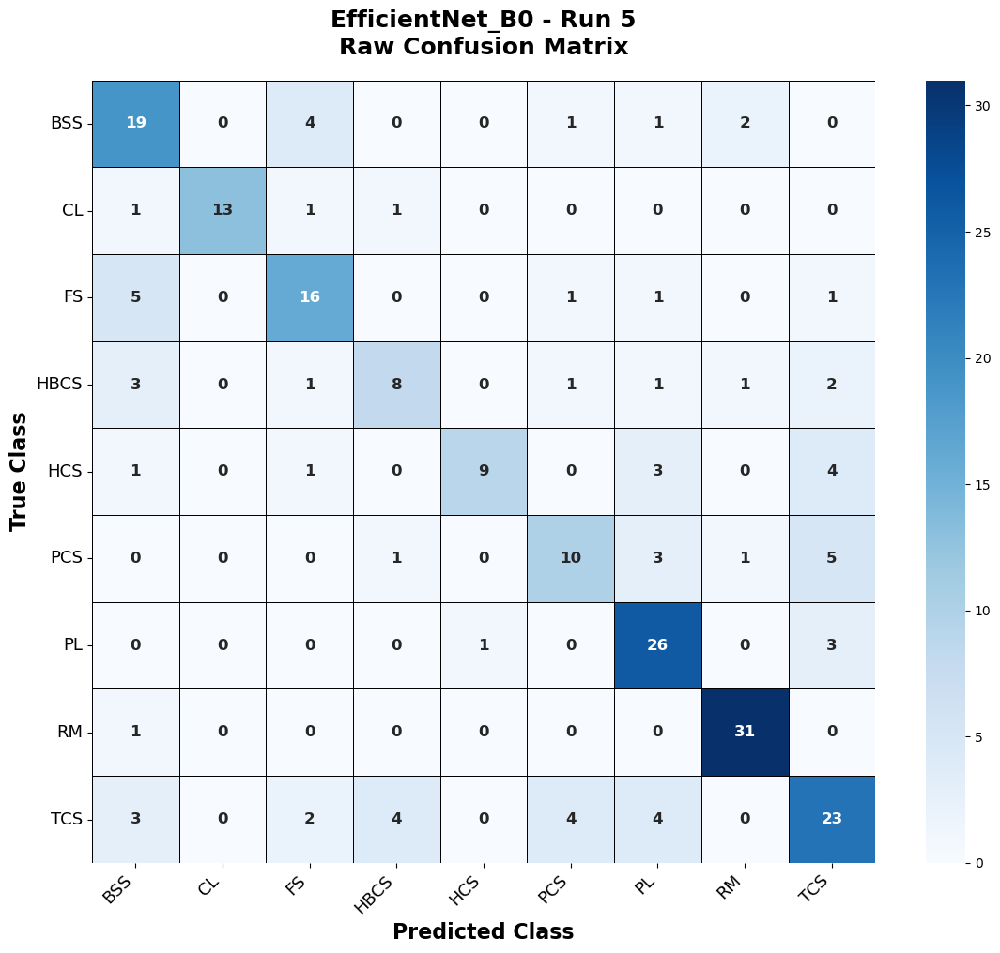

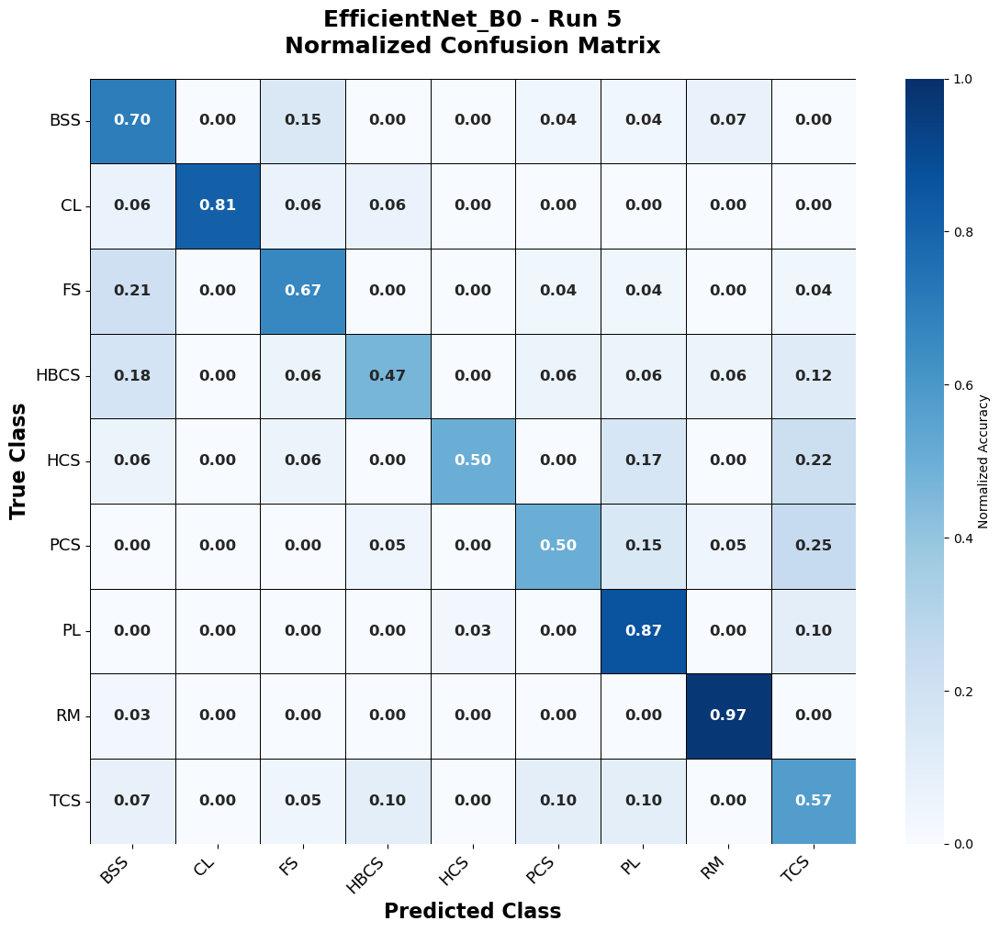


✓ Confusion matrices saved successfully
ROC Curve : EfficientNet_B0 | Run 5


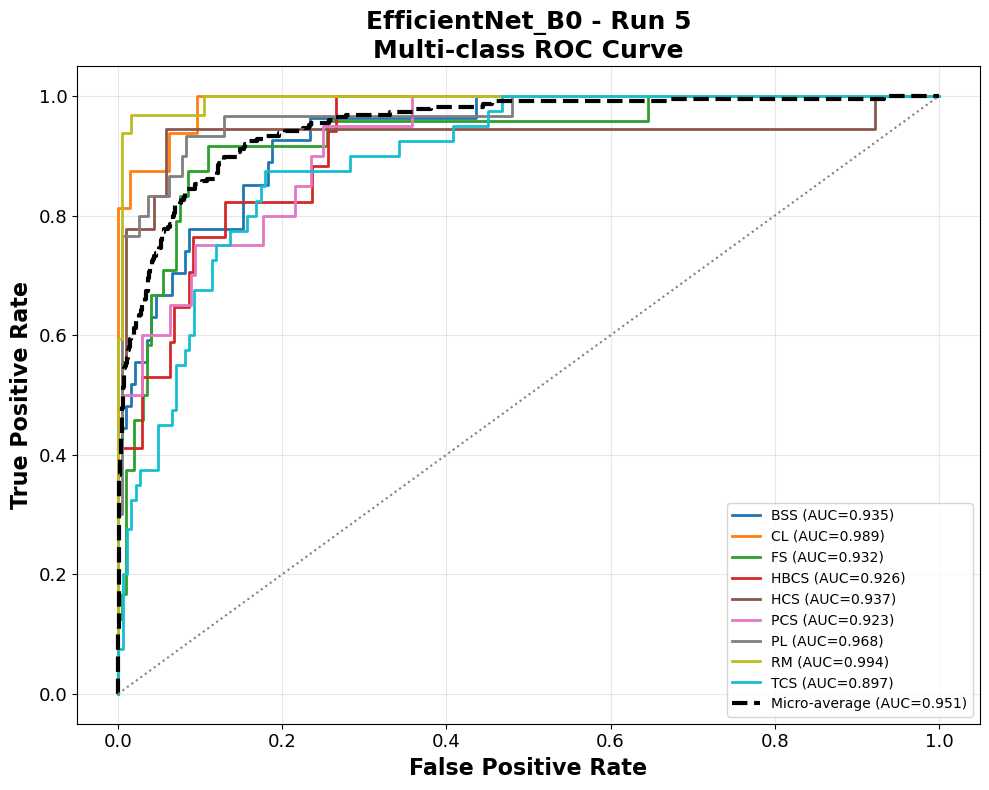


AUC Values
            Class       AUC
0             BSS  0.935138
1              CL  0.989183
2              FS  0.931667
3            HBCS  0.926115
4             HCS  0.937163
5             PCS  0.922794
6              PL  0.967869
7              RM  0.994466
8             TCS  0.896875
9   Micro Average  0.950544
10  Macro Average  0.944586

✓ ROC curve saved successfully.
✓ Completed Successfully

MODEL : EfficientNet_B1

Run 1
Evaluating : EfficientNet_B1 | Run 1

Loaded : EfficientNet_B1_Run1.pkl



Images Evaluated : 224
Total Inference : 9.322 sec
Per Image       : 0.041615 sec
Computing Metrics : EfficientNet_B1 | Run 1

Overall Performance
--------------------------------------------------
Accuracy              : 0.6696
Precision (Macro)     : 0.6613
Recall (Macro)        : 0.6629
F1 Score (Macro)      : 0.6587
Precision (Weighted)  : 0.6744
Recall (Weighted)     : 0.6696
F1 Score (Weighted)   : 0.6694
Balanced Accuracy     : 0.6629
Cohen Kappa           : 0.6245
MCC                   : 0.6251
Log Loss              : 0.9877
Confusion Matrix : EfficientNet_B1 | Run 1


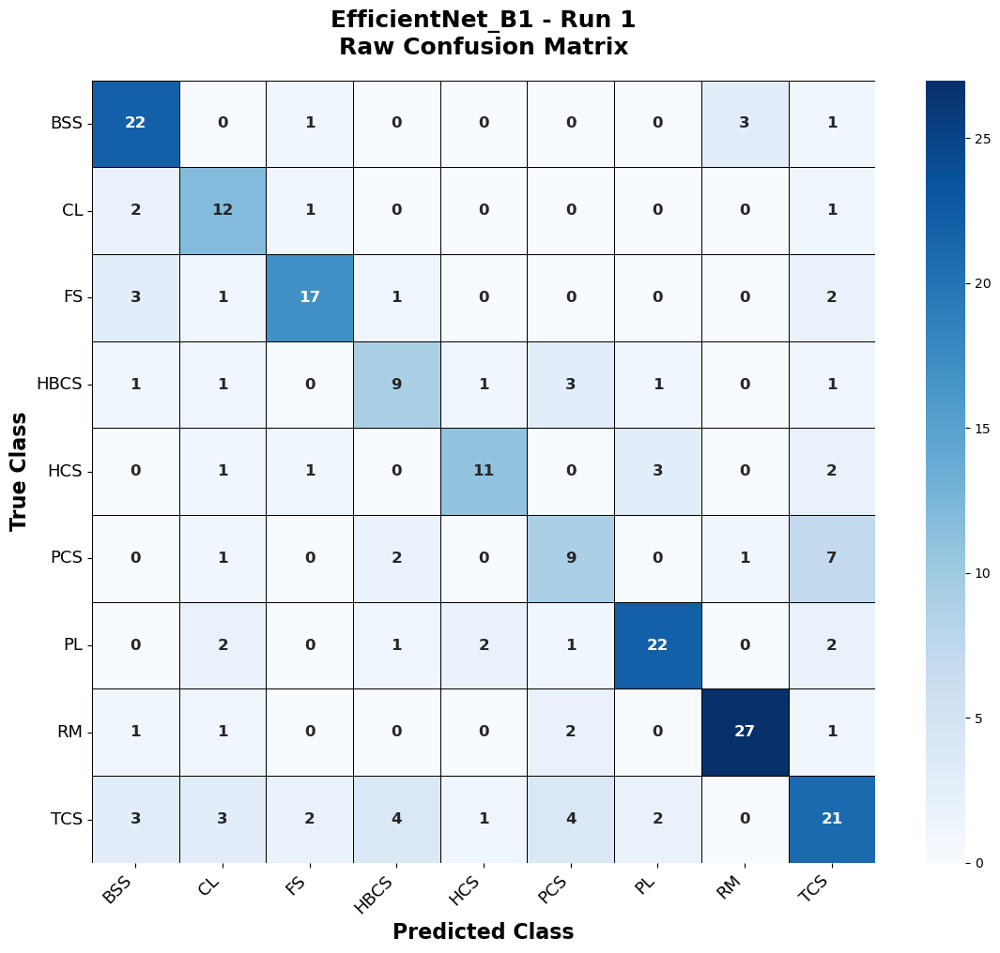

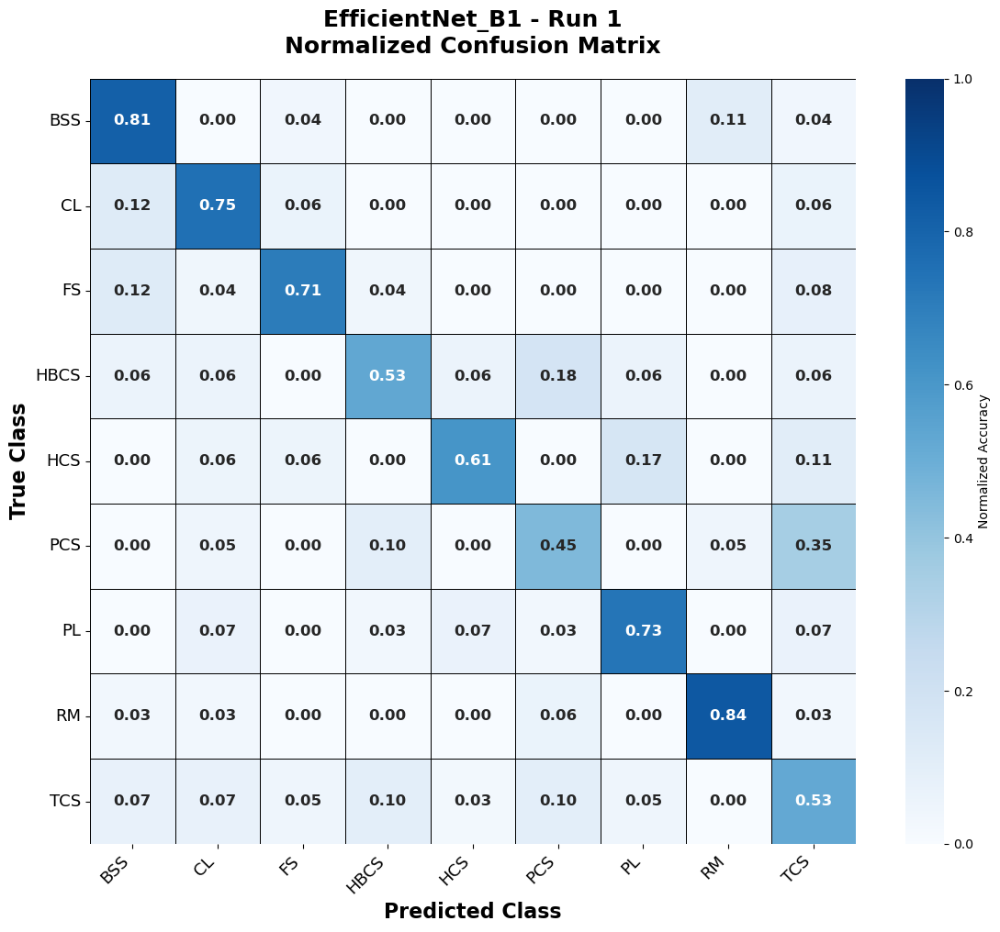


✓ Confusion matrices saved successfully
ROC Curve : EfficientNet_B1 | Run 1


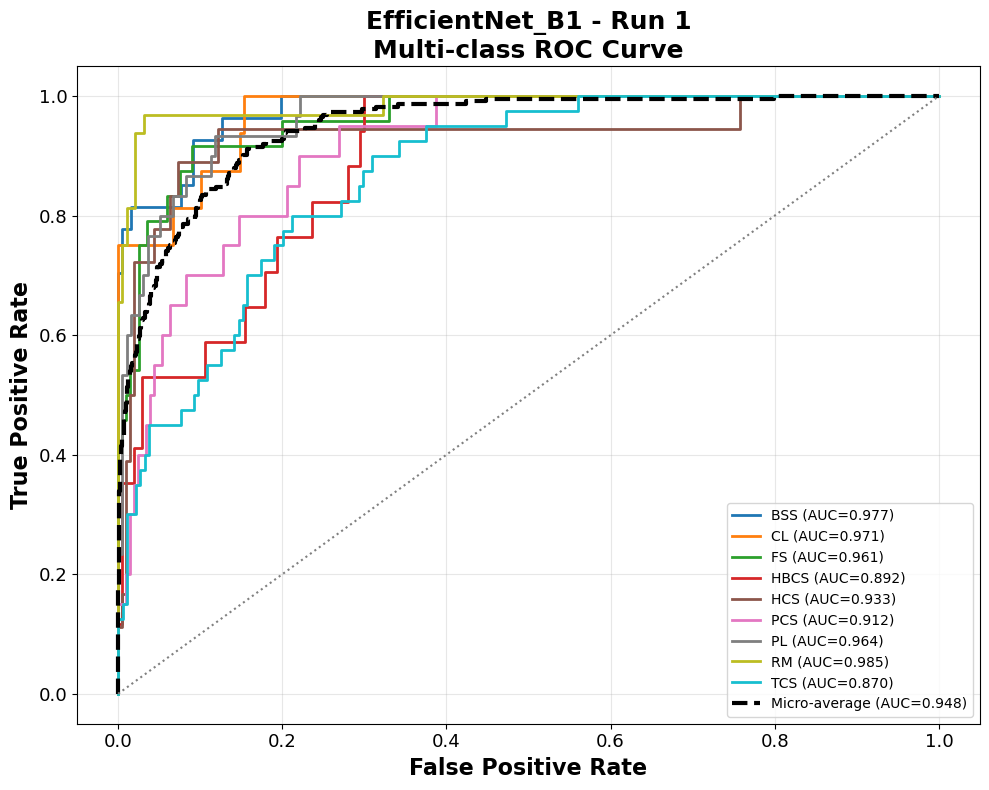


AUC Values
            Class       AUC
0             BSS  0.977439
1              CL  0.970553
2              FS  0.960625
3            HBCS  0.891731
4             HCS  0.932848
5             PCS  0.912010
6              PL  0.963918
7              RM  0.985189
8             TCS  0.869837
9   Micro Average  0.947956
10  Macro Average  0.940461

✓ ROC curve saved successfully.
✓ Completed Successfully

Run 2
Evaluating : EfficientNet_B1 | Run 2

Loaded : EfficientNet_B1_Run2.pkl



Images Evaluated : 224
Total Inference : 9.710 sec
Per Image       : 0.043347 sec
Computing Metrics : EfficientNet_B1 | Run 2

Overall Performance
--------------------------------------------------
Accuracy              : 0.7054
Precision (Macro)     : 0.7493
Recall (Macro)        : 0.6882
F1 Score (Macro)      : 0.7023
Precision (Weighted)  : 0.7363
Recall (Weighted)     : 0.7054
F1 Score (Weighted)   : 0.7081
Balanced Accuracy     : 0.6882
Cohen Kappa           : 0.6628
MCC                   : 0.6653
Log Loss              : 1.0213
Confusion Matrix : EfficientNet_B1 | Run 2


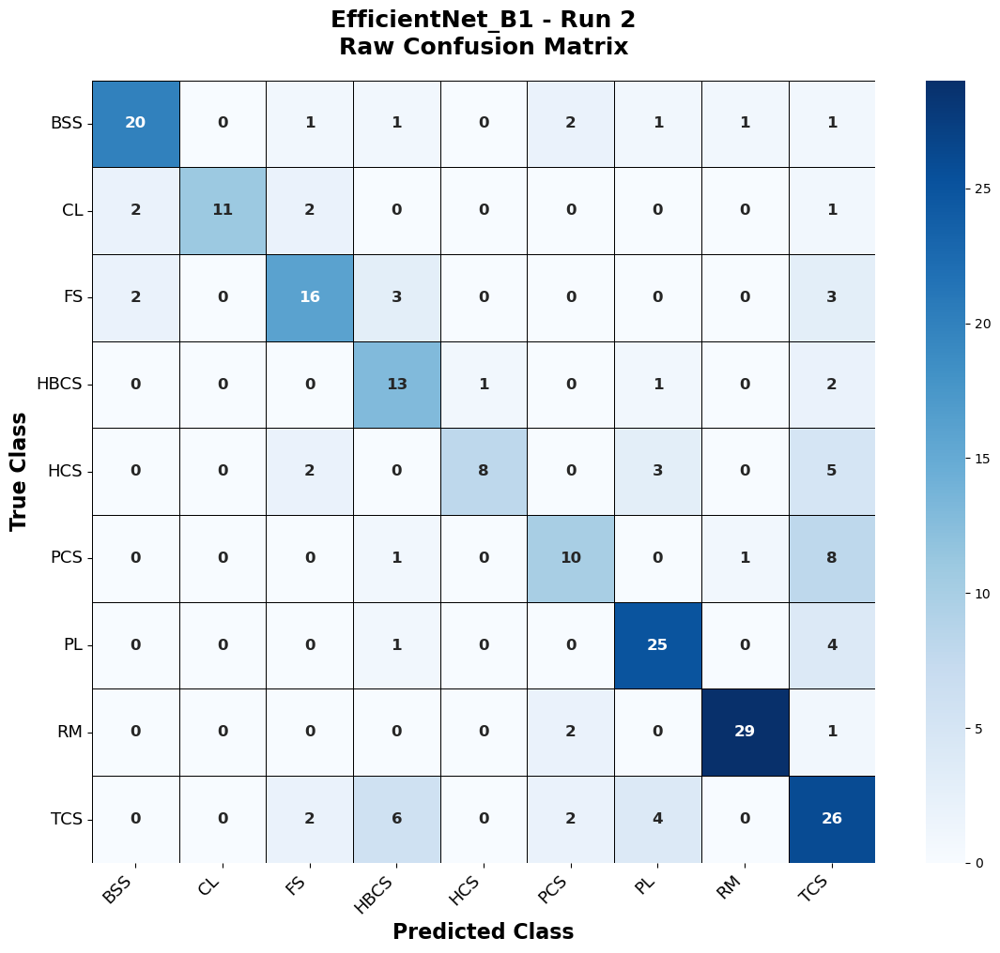

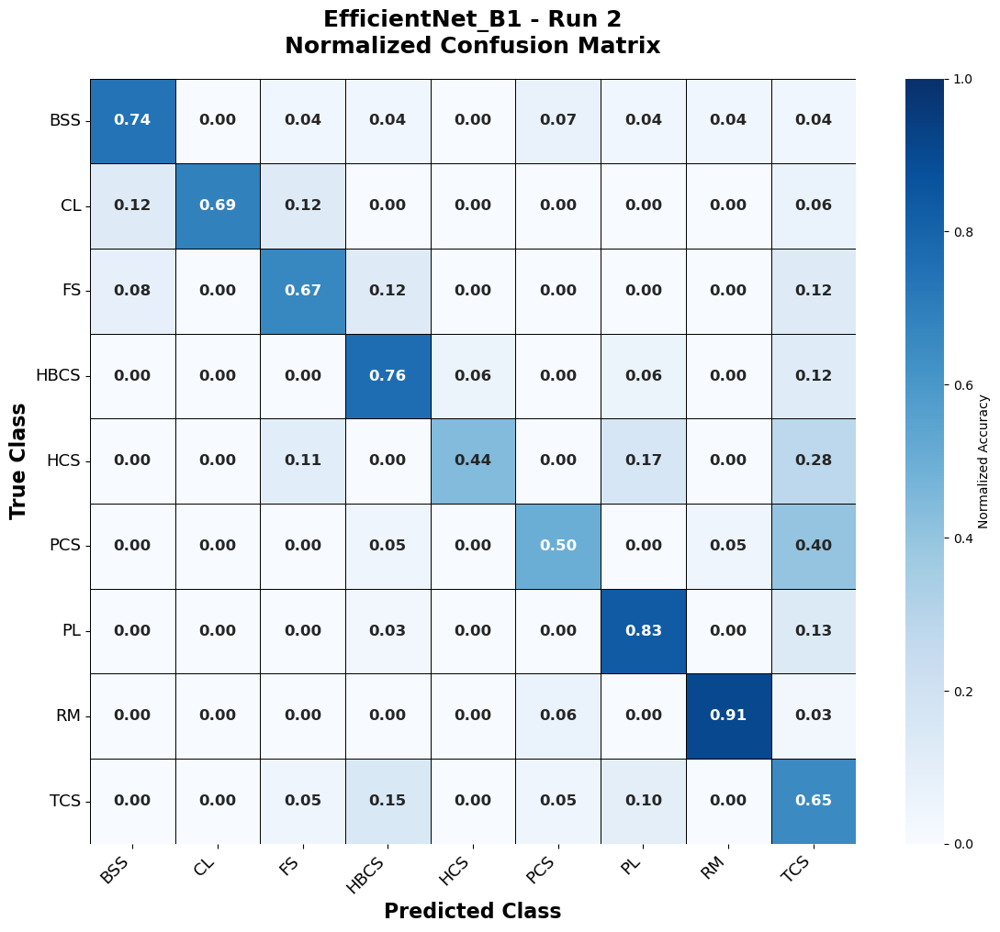


✓ Confusion matrices saved successfully
ROC Curve : EfficientNet_B1 | Run 2


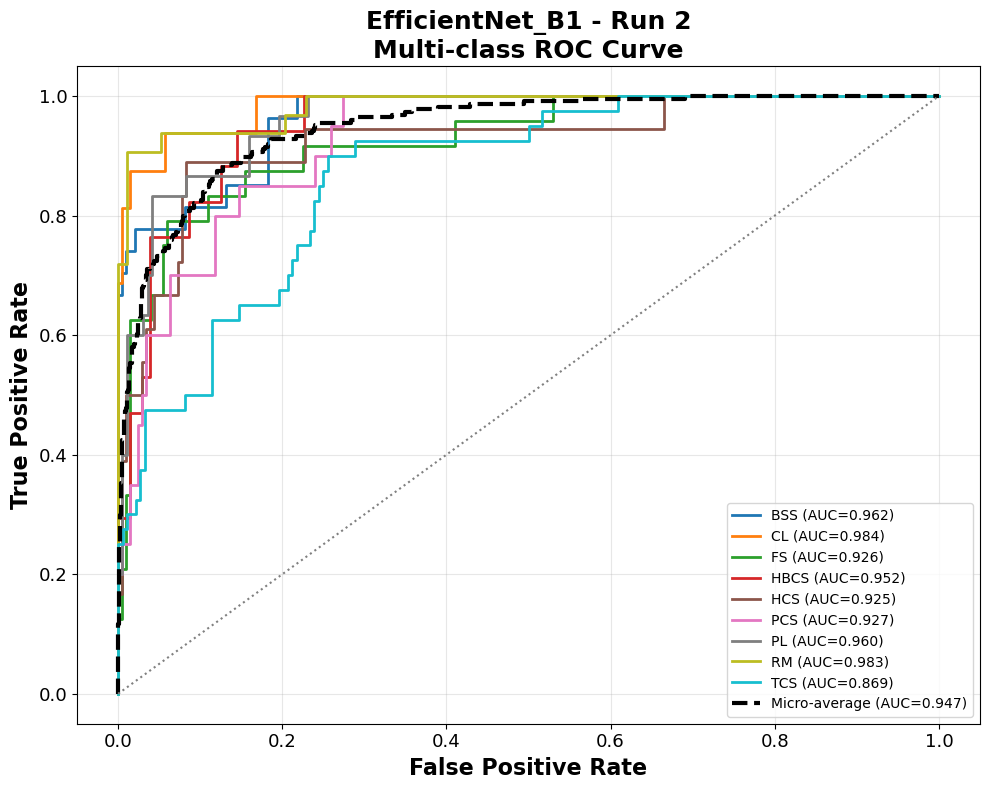


AUC Values
            Class       AUC
0             BSS  0.962399
1              CL  0.984375
2              FS  0.925625
3            HBCS  0.952259
4             HCS  0.925027
5             PCS  0.926716
6              PL  0.960309
7              RM  0.982910
8             TCS  0.869293
9   Micro Average  0.946962
10  Macro Average  0.943213

✓ ROC curve saved successfully.
✓ Completed Successfully

Run 3
Evaluating : EfficientNet_B1 | Run 3

Loaded : EfficientNet_B1_Run3.pkl



Images Evaluated : 224
Total Inference : 9.515 sec
Per Image       : 0.042476 sec
Computing Metrics : EfficientNet_B1 | Run 3

Overall Performance
--------------------------------------------------
Accuracy              : 0.6741
Precision (Macro)     : 0.6861
Recall (Macro)        : 0.6529
F1 Score (Macro)      : 0.6620
Precision (Weighted)  : 0.6855
Recall (Weighted)     : 0.6741
F1 Score (Weighted)   : 0.6724
Balanced Accuracy     : 0.6529
Cohen Kappa           : 0.6267
MCC                   : 0.6290
Log Loss              : 1.1530
Confusion Matrix : EfficientNet_B1 | Run 3


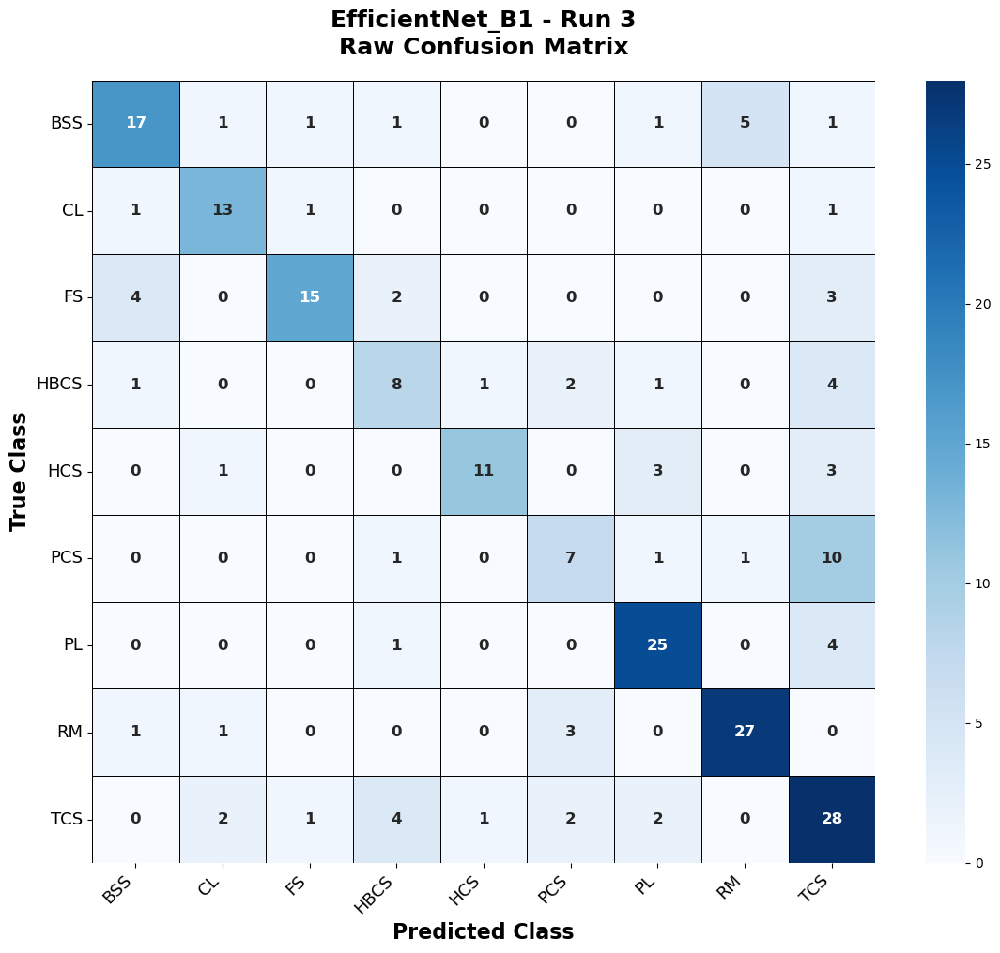

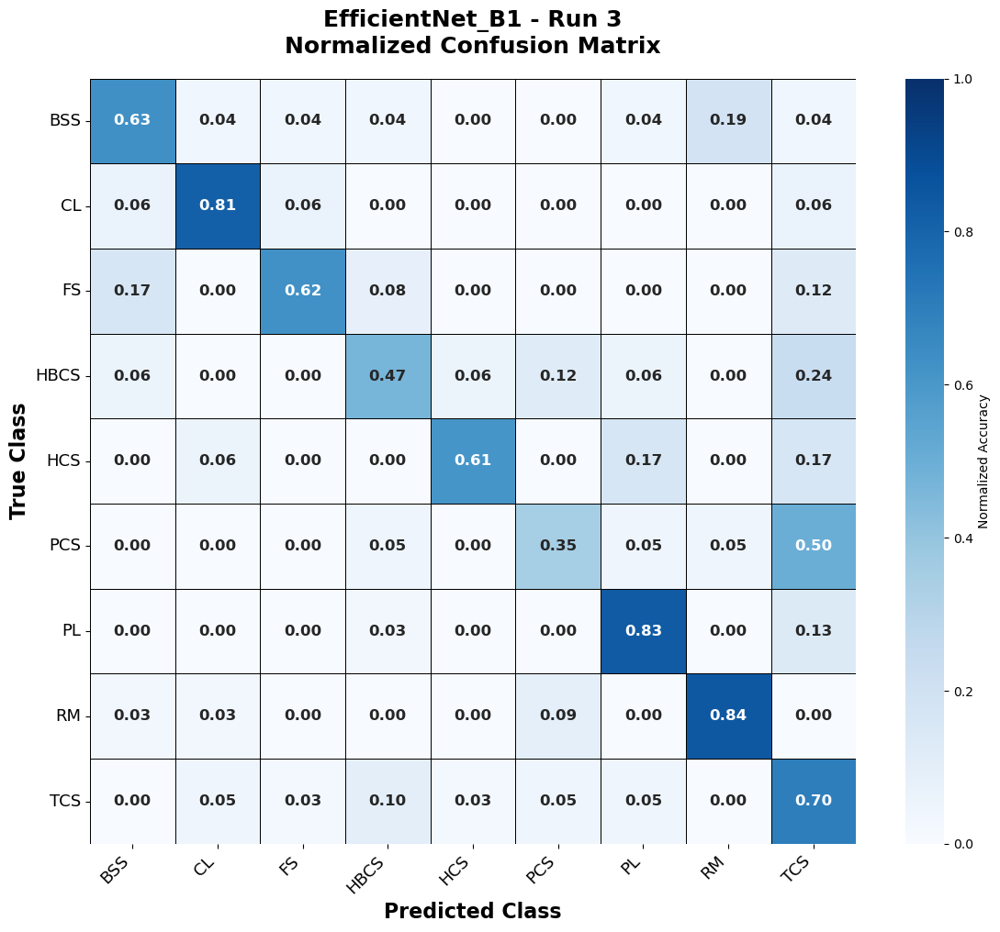


✓ Confusion matrices saved successfully
ROC Curve : EfficientNet_B1 | Run 3


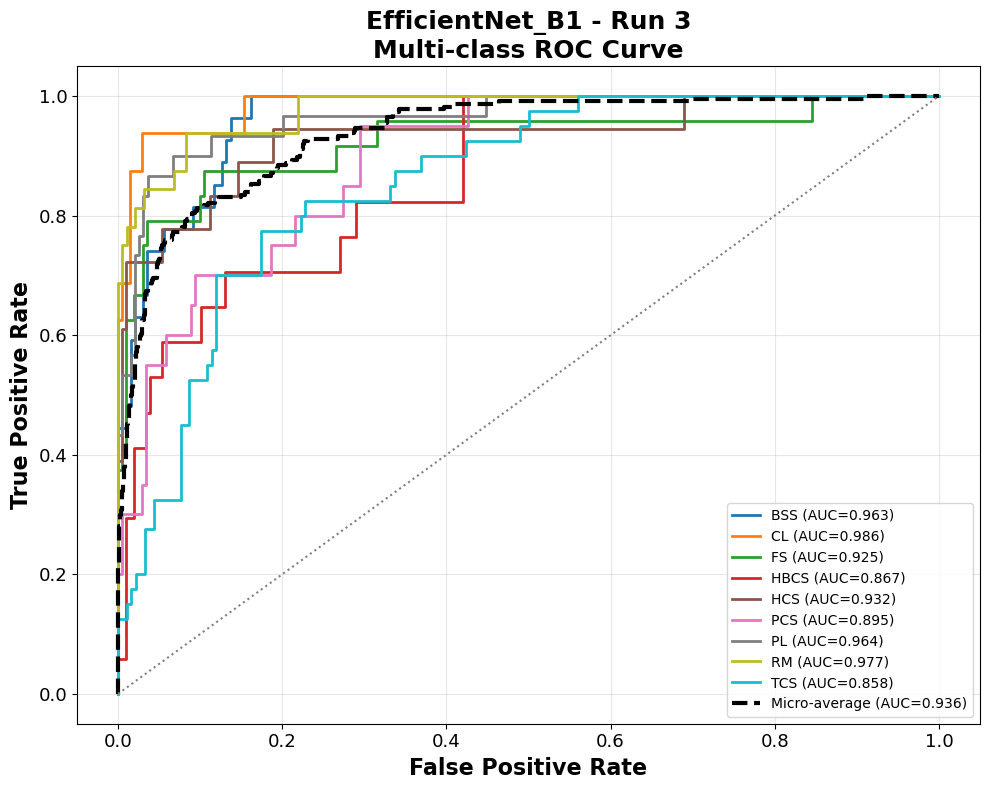


AUC Values
            Class       AUC
0             BSS  0.962963
1              CL  0.985577
2              FS  0.925000
3            HBCS  0.867292
4             HCS  0.931769
5             PCS  0.894608
6              PL  0.963746
7              RM  0.976725
8             TCS  0.858016
9   Micro Average  0.935821
10  Macro Average  0.929522

✓ ROC curve saved successfully.
✓ Completed Successfully

Run 4
Evaluating : EfficientNet_B1 | Run 4

Loaded : EfficientNet_B1_Run4.pkl



Images Evaluated : 224
Total Inference : 9.478 sec
Per Image       : 0.042314 sec
Computing Metrics : EfficientNet_B1 | Run 4

Overall Performance
--------------------------------------------------
Accuracy              : 0.6786
Precision (Macro)     : 0.6888
Recall (Macro)        : 0.6640
F1 Score (Macro)      : 0.6704
Precision (Weighted)  : 0.6916
Recall (Weighted)     : 0.6786
F1 Score (Weighted)   : 0.6806
Balanced Accuracy     : 0.6640
Cohen Kappa           : 0.6337
MCC                   : 0.6344
Log Loss              : 1.1104
Confusion Matrix : EfficientNet_B1 | Run 4


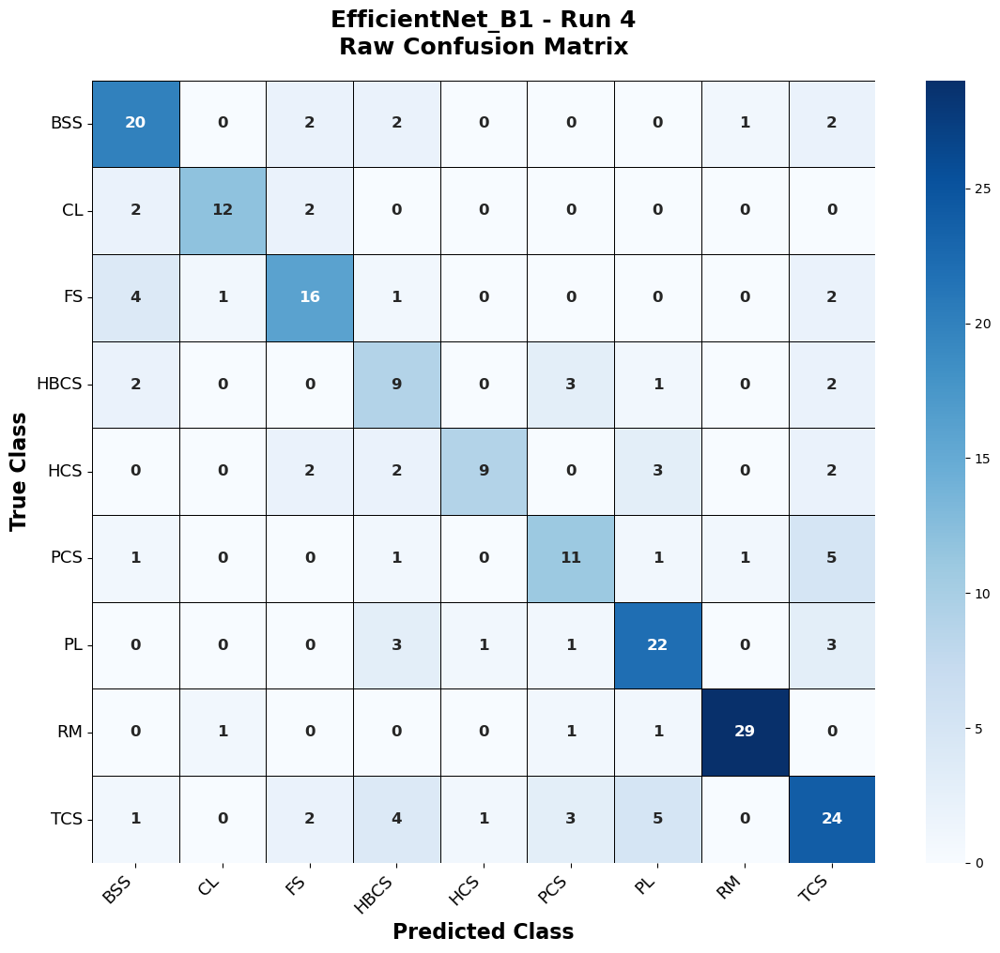

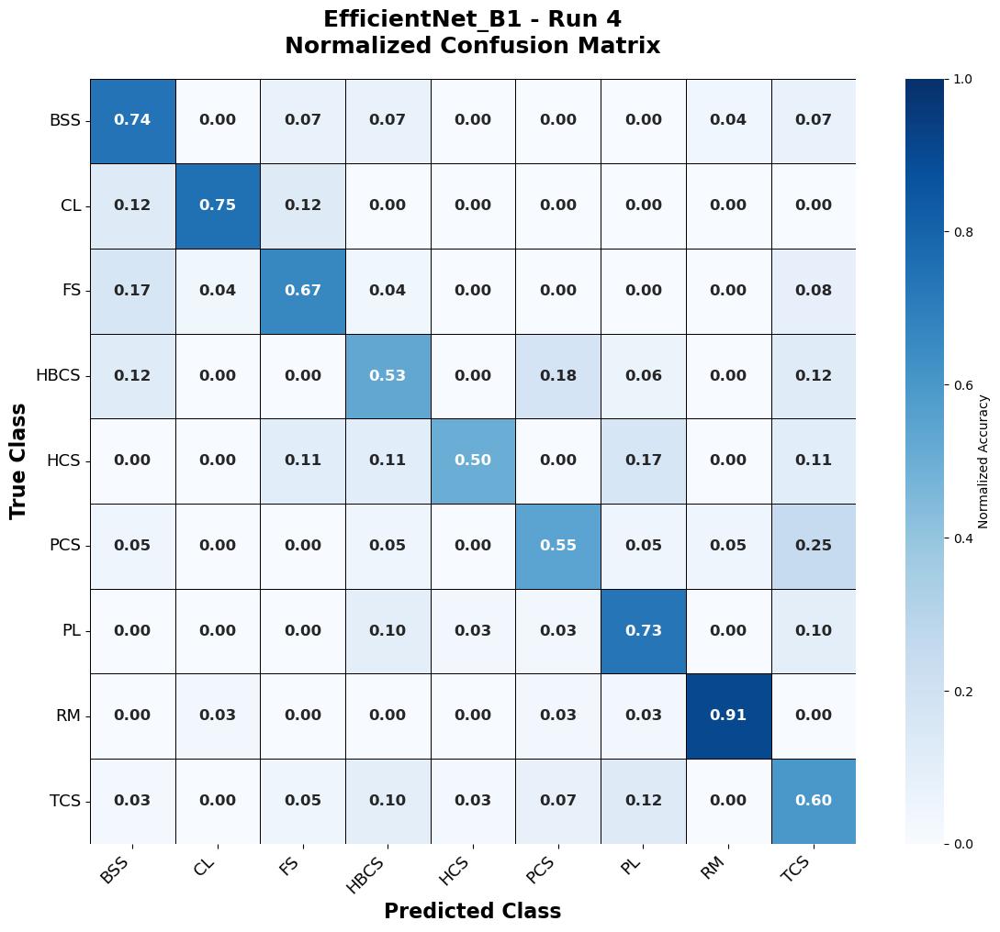


✓ Confusion matrices saved successfully
ROC Curve : EfficientNet_B1 | Run 4


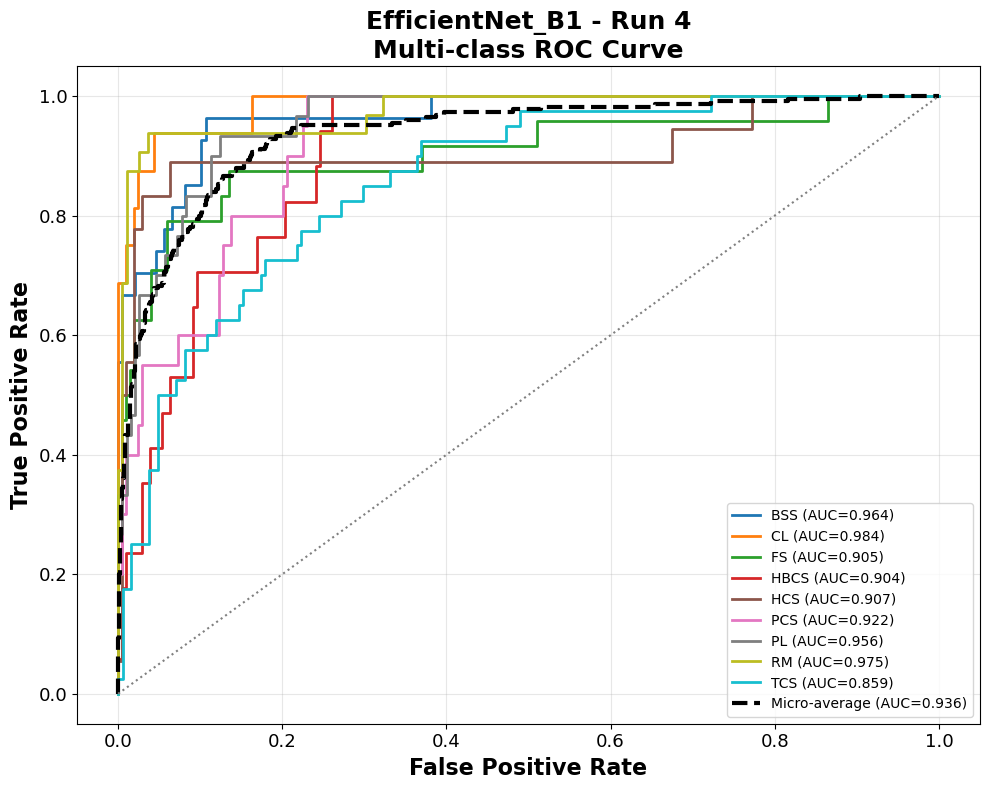


AUC Values
            Class       AUC
0             BSS  0.963903
1              CL  0.983774
2              FS  0.904792
3            HBCS  0.903950
4             HCS  0.907497
5             PCS  0.922059
6              PL  0.955670
7              RM  0.974935
8             TCS  0.859103
9   Micro Average  0.935552
10  Macro Average  0.930631

✓ ROC curve saved successfully.
✓ Completed Successfully

Run 5
Evaluating : EfficientNet_B1 | Run 5

Loaded : EfficientNet_B1_Run5.pkl



Images Evaluated : 224
Total Inference : 9.412 sec
Per Image       : 0.042017 sec
Computing Metrics : EfficientNet_B1 | Run 5

Overall Performance
--------------------------------------------------
Accuracy              : 0.6116
Precision (Macro)     : 0.6096
Recall (Macro)        : 0.5892
F1 Score (Macro)      : 0.5914
Precision (Weighted)  : 0.6117
Recall (Weighted)     : 0.6116
F1 Score (Weighted)   : 0.6042
Balanced Accuracy     : 0.5892
Cohen Kappa           : 0.5552
MCC                   : 0.5571
Log Loss              : 1.1389
Confusion Matrix : EfficientNet_B1 | Run 5


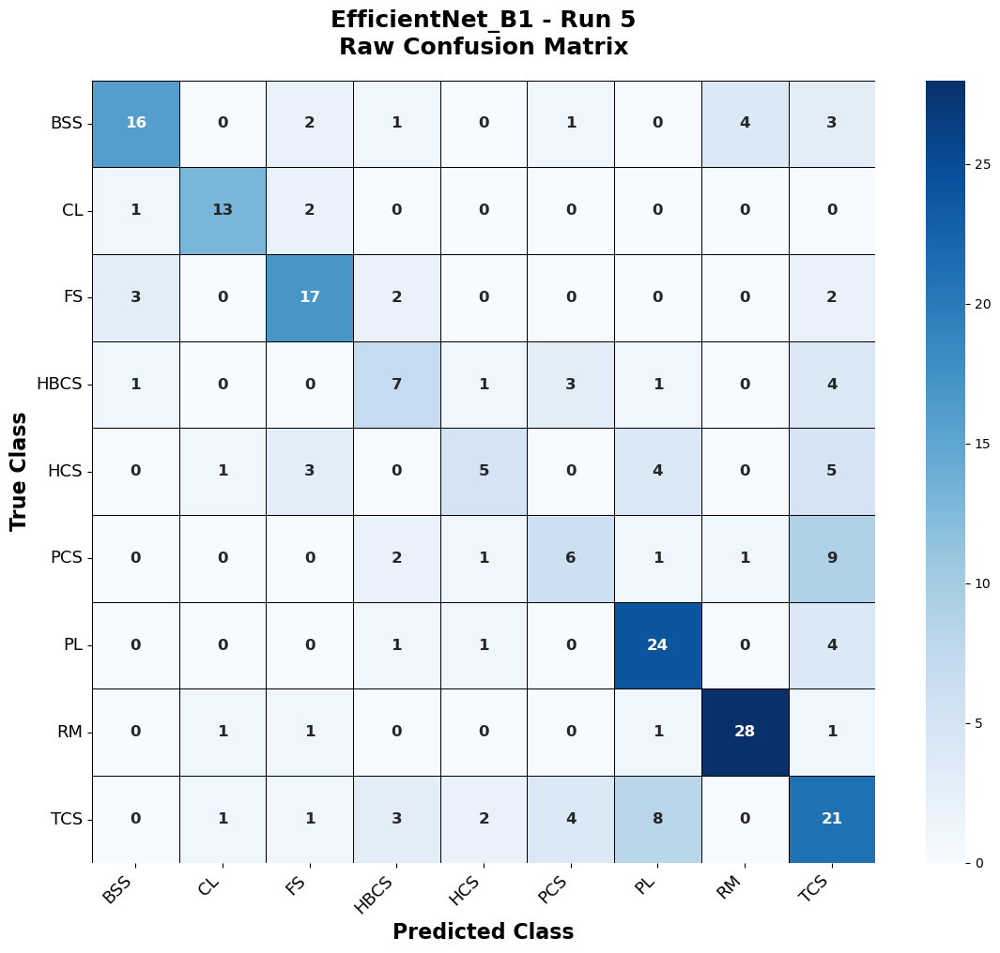

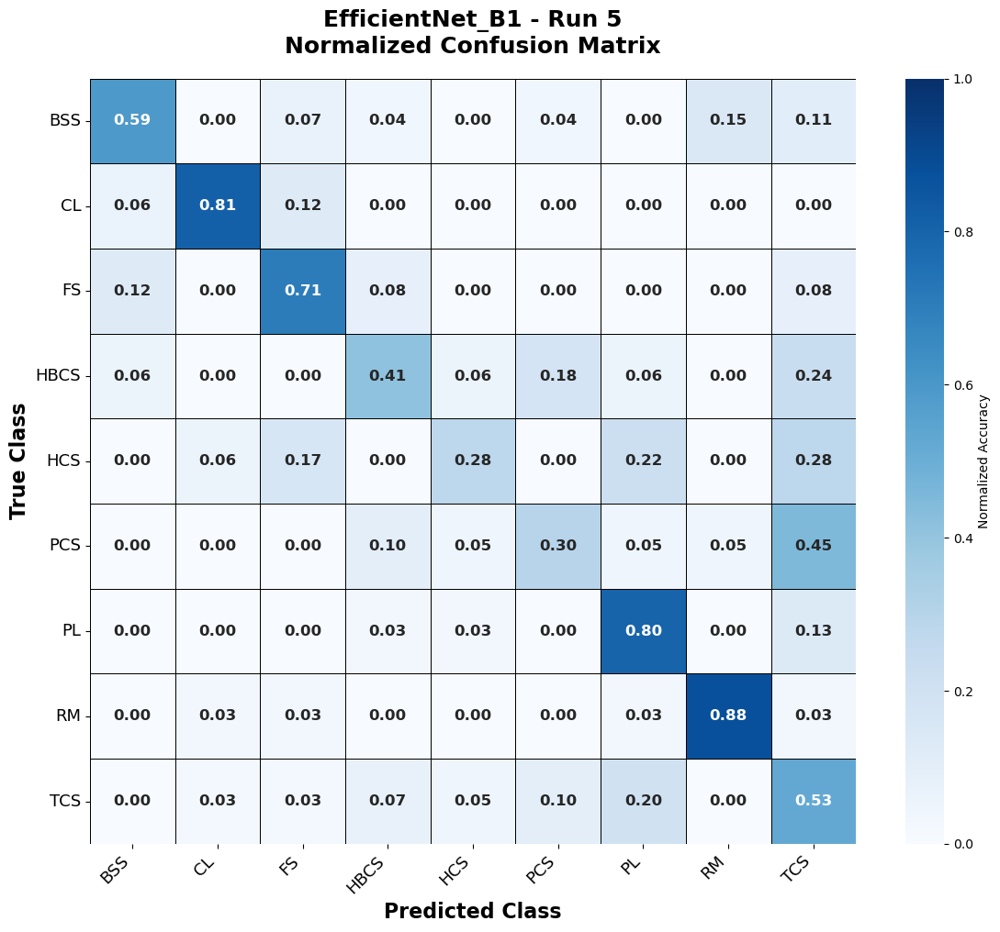


✓ Confusion matrices saved successfully
ROC Curve : EfficientNet_B1 | Run 5


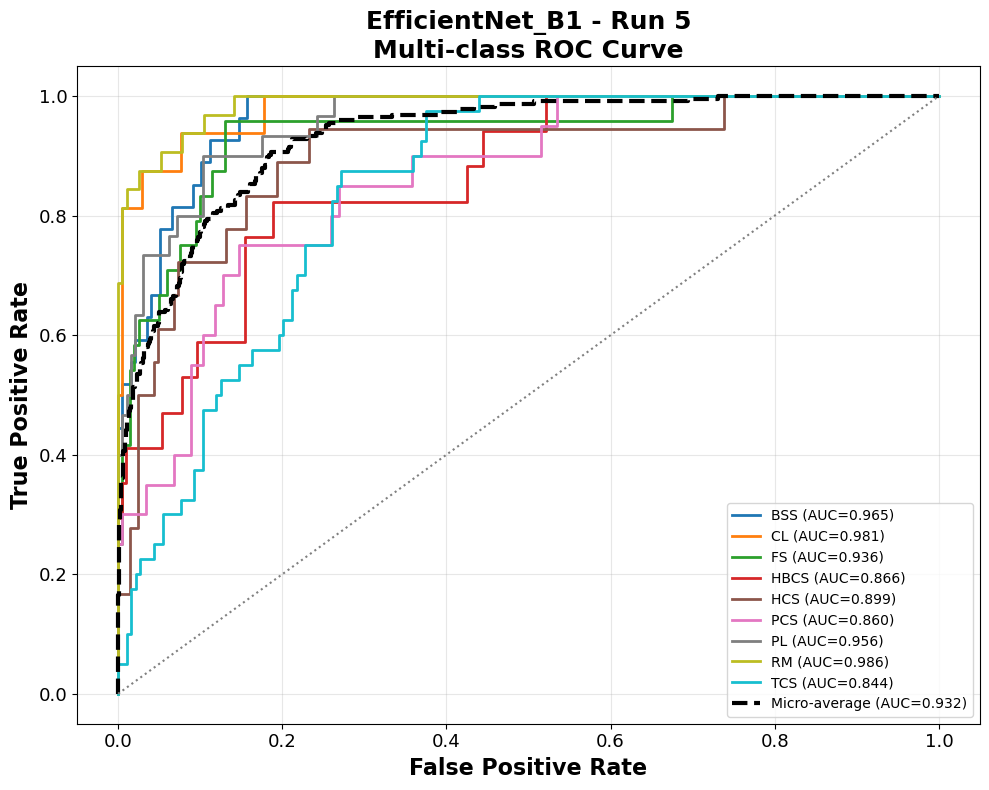


AUC Values
            Class       AUC
0             BSS  0.964843
1              CL  0.980769
2              FS  0.935833
3            HBCS  0.865587
4             HCS  0.899407
5             PCS  0.859804
6              PL  0.956357
7              RM  0.986491
8             TCS  0.844158
9   Micro Average  0.931616
10  Macro Average  0.921472

✓ ROC curve saved successfully.
✓ Completed Successfully

Master Results Saved
Benchmark_v2\Benchmark_Results\Evaluation\cnn_test_results.csv


,Model,Run,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,Precision_Weighted,Recall_Weighted,F1_Weighted,Balanced_Accuracy,Cohen_Kappa,MCC,Log_Loss,Parameters,Trainable_Parameters,Inference_Time_Total,Inference_Time_Per_Image
0,ResNet50,1,0.812500,0.836753,0.798673,0.813926,0.822268,0.812500,0.813641,0.798673,0.785406,0.786700,0.739441,25619008,25619008,12.110103,0.054063
1,ResNet50,2,0.758929,0.770564,0.738694,0.749218,0.765390,0.758929,0.756550,0.738694,0.724075,0.725669,0.865103,25619008,25619008,11.878119,0.053027
2,ResNet50,3,0.709821,0.703015,0.695310,0.696437,0.708838,0.709821,0.706373,0.695310,0.669008,0.669681,0.854735,25619008,25619008,14.437087,0.064451
3,ResNet50,4,0.767857,0.775399,0.741960,0.753714,0.771208,0.767857,0.765182,0.741960,0.734355,0.735479,0.804335,25619008,25619008,11.852218,0.052912
4,ResNet50,5,0.772321,0.773073,0.759656,0.762597,0.770197,0.772321,0.768221,0.759656,0.740257,0.740833,0.815813,25619008,25619008,12.066944,0.053870
5,DenseNet121,1,0.808036,0.819427,0.784075,0.792848,0.813161,0.808036,0.803567,0.784075,0.780287,0.781896,0.773372,8012160,8012160,12.146313,0.054225
6,DenseNet121,2,0.750000,0.756860,0.732483,0.740033,0.751873,0.750000,0.747307,0.732483,0.714585,0.715323,0.828848,8012160,8012160,11.780209,0.052590
7,DenseNet121,3,0.799107,0.796918,0.785032,0.788499,0.797848,0.799107,0.796455,0.785032,0.771039,0.771461,0.703015,8012160,8012160,11.720622,0.052324
8,DenseNet121,4,0.758929,0.819741,0.720128,0.737789,0.792193,0.758929,0.751495,0.720128,0.722842,0.726723,0.899368,8012160,8012160,11.706652,0.052262
9,DenseNet121,5,0.741071,0.736157,0.725822,0.727617,0.741497,0.741071,0.738599,0.725822,0.704801,0.705316,0.746736,8012160,8012160,11.742249,0.052421


STEP 8F COMPLETED


In [69]:
# ============================================================
# STEP 8F : EVALUATE ALL TRAINED MODELS
# ============================================================

print("=" * 80)
print("STEP 8F : EVALUATING ALL MODELS")
print("=" * 80)

all_results = []

for model_name in MODEL_LIST:

    print("\n" + "="*80)
    print(f"MODEL : {model_name}")
    print("="*80)

    for run in range(1, 6):

        print(f"\nRun {run}")

        try:

            # -----------------------------
            # Evaluate model
            # -----------------------------

            result = evaluate_model(model_name, run)

            # -----------------------------
            # Metrics
            # -----------------------------

            metrics, report_df = compute_metrics(result)

            # -----------------------------
            # Confusion Matrix
            # -----------------------------

            plot_confusion_matrix(result)

            # -----------------------------
            # ROC Curve
            # -----------------------------

            auc_df = plot_multiclass_roc(result)

            # -----------------------------
            # Store metrics
            # -----------------------------

            all_results.append(metrics)

            print("✓ Completed Successfully")

        except Exception as e:

            print(f"✗ Error : {e}")

# ============================================================
# Create Master Results Table
# ============================================================

results_df = pd.DataFrame(all_results)

results_df.to_csv(
    MASTER_RESULTS_FILE,
    index=False
)

print("\nMaster Results Saved")

print(MASTER_RESULTS_FILE)

display(results_df)

print("="*80)
print("STEP 8F COMPLETED")
print("="*80)

In [70]:
# ============================================================
# STEP 8F : EVALUATE ALL 25 MODELS
# ============================================================

print("="*80)
print("STEP 8F : EVALUATING ALL TRAINED MODELS")
print("="*80)

all_metrics = []

for model_name in MODEL_LIST:

    print("\n" + "="*80)
    print(f"MODEL : {model_name}")
    print("="*80)

    for run in range(1, 6):

        print(f"\nEvaluating Run {run}")

        try:

            # ------------------------------------------
            # Evaluate Model
            # ------------------------------------------

            result = evaluate_model(model_name, run)

            # ------------------------------------------
            # Compute Metrics
            # ------------------------------------------

            metrics, report_df = compute_metrics(result)

            # ------------------------------------------
            # Save per-class report
            # ------------------------------------------

            report_path = RESULTS_DIR / f"{model_name}_Run{run}_Classification_Report.csv"

            report_df.to_csv(
                report_path,
                index=True
            )

            # ------------------------------------------
            # Store metrics
            # ------------------------------------------

            all_metrics.append(metrics)

            print("✓ Completed Successfully")

        except Exception as e:

            print(f"✗ Failed : {e}")

# ============================================================
# Create Master Results DataFrame
# ============================================================

results_df = pd.DataFrame(all_metrics)

results_df = results_df.sort_values(
    by=["Model","Run"]
).reset_index(drop=True)

results_df.to_csv(
    MASTER_RESULTS_FILE,
    index=False
)

print("\nMaster Results Saved")

print(MASTER_RESULTS_FILE)

display(results_df)

print("="*80)
print("STEP 8F COMPLETED")
print("="*80)

STEP 8F : EVALUATING ALL TRAINED MODELS

MODEL : ResNet50

Evaluating Run 1
Evaluating : ResNet50 | Run 1

Loaded : ResNet50_Run1.pkl



Images Evaluated : 224
Total Inference : 12.235 sec
Per Image       : 0.054620 sec
Computing Metrics : ResNet50 | Run 1

Overall Performance
--------------------------------------------------
Accuracy              : 0.8125
Precision (Macro)     : 0.8368
Recall (Macro)        : 0.7987
F1 Score (Macro)      : 0.8139
Precision (Weighted)  : 0.8223
Recall (Weighted)     : 0.8125
F1 Score (Weighted)   : 0.8136
Balanced Accuracy     : 0.7987
Cohen Kappa           : 0.7854
MCC                   : 0.7867
Log Loss              : 0.7394
✓ Completed Successfully

Evaluating Run 2
Evaluating : ResNet50 | Run 2

Loaded : ResNet50_Run2.pkl



Images Evaluated : 224
Total Inference : 12.414 sec
Per Image       : 0.055420 sec
Computing Metrics : ResNet50 | Run 2

Overall Performance
--------------------------------------------------
Accuracy              : 0.7589
Precision (Macro)     : 0.7706
Recall (Macro)        : 0.7387
F1 Score (Macro)      : 0.7492
Precision (Weighted)  : 0.7654
Recall (Weighted)     : 0.7589
F1 Score (Weighted)   : 0.7565
Balanced Accuracy     : 0.7387
Cohen Kappa           : 0.7241
MCC                   : 0.7257
Log Loss              : 0.8651
✓ Completed Successfully

Evaluating Run 3
Evaluating : ResNet50 | Run 3

Loaded : ResNet50_Run3.pkl



Images Evaluated : 224
Total Inference : 12.058 sec
Per Image       : 0.053832 sec
Computing Metrics : ResNet50 | Run 3

Overall Performance
--------------------------------------------------
Accuracy              : 0.7098
Precision (Macro)     : 0.7030
Recall (Macro)        : 0.6953
F1 Score (Macro)      : 0.6964
Precision (Weighted)  : 0.7088
Recall (Weighted)     : 0.7098
F1 Score (Weighted)   : 0.7064
Balanced Accuracy     : 0.6953
Cohen Kappa           : 0.6690
MCC                   : 0.6697
Log Loss              : 0.8547
✓ Completed Successfully

Evaluating Run 4
Evaluating : ResNet50 | Run 4

Loaded : ResNet50_Run4.pkl



Images Evaluated : 224
Total Inference : 12.478 sec
Per Image       : 0.055705 sec
Computing Metrics : ResNet50 | Run 4

Overall Performance
--------------------------------------------------
Accuracy              : 0.7679
Precision (Macro)     : 0.7754
Recall (Macro)        : 0.7420
F1 Score (Macro)      : 0.7537
Precision (Weighted)  : 0.7712
Recall (Weighted)     : 0.7679
F1 Score (Weighted)   : 0.7652
Balanced Accuracy     : 0.7420
Cohen Kappa           : 0.7344
MCC                   : 0.7355
Log Loss              : 0.8043
✓ Completed Successfully

Evaluating Run 5
Evaluating : ResNet50 | Run 5

Loaded : ResNet50_Run5.pkl



Images Evaluated : 224
Total Inference : 11.565 sec
Per Image       : 0.051628 sec
Computing Metrics : ResNet50 | Run 5

Overall Performance
--------------------------------------------------
Accuracy              : 0.7723
Precision (Macro)     : 0.7731
Recall (Macro)        : 0.7597
F1 Score (Macro)      : 0.7626
Precision (Weighted)  : 0.7702
Recall (Weighted)     : 0.7723
F1 Score (Weighted)   : 0.7682
Balanced Accuracy     : 0.7597
Cohen Kappa           : 0.7403
MCC                   : 0.7408
Log Loss              : 0.8158
✓ Completed Successfully

MODEL : DenseNet121

Evaluating Run 1
Evaluating : DenseNet121 | Run 1

Loaded : DenseNet121_Run1.pkl



Images Evaluated : 224
Total Inference : 12.911 sec
Per Image       : 0.057637 sec
Computing Metrics : DenseNet121 | Run 1

Overall Performance
--------------------------------------------------
Accuracy              : 0.8080
Precision (Macro)     : 0.8194
Recall (Macro)        : 0.7841
F1 Score (Macro)      : 0.7928
Precision (Weighted)  : 0.8132
Recall (Weighted)     : 0.8080
F1 Score (Weighted)   : 0.8036
Balanced Accuracy     : 0.7841
Cohen Kappa           : 0.7803
MCC                   : 0.7819
Log Loss              : 0.7734
✓ Completed Successfully

Evaluating Run 2
Evaluating : DenseNet121 | Run 2

Loaded : DenseNet121_Run2.pkl



Images Evaluated : 224
Total Inference : 12.333 sec
Per Image       : 0.055058 sec
Computing Metrics : DenseNet121 | Run 2

Overall Performance
--------------------------------------------------
Accuracy              : 0.7500
Precision (Macro)     : 0.7569
Recall (Macro)        : 0.7325
F1 Score (Macro)      : 0.7400
Precision (Weighted)  : 0.7519
Recall (Weighted)     : 0.7500
F1 Score (Weighted)   : 0.7473
Balanced Accuracy     : 0.7325
Cohen Kappa           : 0.7146
MCC                   : 0.7153
Log Loss              : 0.8288
✓ Completed Successfully

Evaluating Run 3
Evaluating : DenseNet121 | Run 3

Loaded : DenseNet121_Run3.pkl



Images Evaluated : 224
Total Inference : 13.144 sec
Per Image       : 0.058678 sec
Computing Metrics : DenseNet121 | Run 3

Overall Performance
--------------------------------------------------
Accuracy              : 0.7991
Precision (Macro)     : 0.7969
Recall (Macro)        : 0.7850
F1 Score (Macro)      : 0.7885
Precision (Weighted)  : 0.7978
Recall (Weighted)     : 0.7991
F1 Score (Weighted)   : 0.7965
Balanced Accuracy     : 0.7850
Cohen Kappa           : 0.7710
MCC                   : 0.7715
Log Loss              : 0.7030
✓ Completed Successfully

Evaluating Run 4
Evaluating : DenseNet121 | Run 4

Loaded : DenseNet121_Run4.pkl



Images Evaluated : 224
Total Inference : 13.844 sec
Per Image       : 0.061802 sec
Computing Metrics : DenseNet121 | Run 4

Overall Performance
--------------------------------------------------
Accuracy              : 0.7589
Precision (Macro)     : 0.8197
Recall (Macro)        : 0.7201
F1 Score (Macro)      : 0.7378
Precision (Weighted)  : 0.7922
Recall (Weighted)     : 0.7589
F1 Score (Weighted)   : 0.7515
Balanced Accuracy     : 0.7201
Cohen Kappa           : 0.7228
MCC                   : 0.7267
Log Loss              : 0.8994
✓ Completed Successfully

Evaluating Run 5
Evaluating : DenseNet121 | Run 5

Loaded : DenseNet121_Run5.pkl



Images Evaluated : 224
Total Inference : 12.246 sec
Per Image       : 0.054668 sec
Computing Metrics : DenseNet121 | Run 5

Overall Performance
--------------------------------------------------
Accuracy              : 0.7411
Precision (Macro)     : 0.7362
Recall (Macro)        : 0.7258
F1 Score (Macro)      : 0.7276
Precision (Weighted)  : 0.7415
Recall (Weighted)     : 0.7411
F1 Score (Weighted)   : 0.7386
Balanced Accuracy     : 0.7258
Cohen Kappa           : 0.7048
MCC                   : 0.7053
Log Loss              : 0.7467
✓ Completed Successfully

MODEL : MobileNetV3

Evaluating Run 1
Evaluating : MobileNetV3 | Run 1

Loaded : MobileNetV3_Run1.pkl



Images Evaluated : 224
Total Inference : 3.706 sec
Per Image       : 0.016547 sec
Computing Metrics : MobileNetV3 | Run 1

Overall Performance
--------------------------------------------------
Accuracy              : 0.7098
Precision (Macro)     : 0.7191
Recall (Macro)        : 0.7056
F1 Score (Macro)      : 0.7036
Precision (Weighted)  : 0.7225
Recall (Weighted)     : 0.7098
F1 Score (Weighted)   : 0.7087
Balanced Accuracy     : 0.7056
Cohen Kappa           : 0.6702
MCC                   : 0.6722
Log Loss              : 0.9046
✓ Completed Successfully

Evaluating Run 2
Evaluating : MobileNetV3 | Run 2

Loaded : MobileNetV3_Run2.pkl



Images Evaluated : 224
Total Inference : 3.734 sec
Per Image       : 0.016672 sec
Computing Metrics : MobileNetV3 | Run 2

Overall Performance
--------------------------------------------------
Accuracy              : 0.6964
Precision (Macro)     : 0.7376
Recall (Macro)        : 0.6900
F1 Score (Macro)      : 0.6787
Precision (Weighted)  : 0.7368
Recall (Weighted)     : 0.6964
F1 Score (Weighted)   : 0.6849
Balanced Accuracy     : 0.6900
Cohen Kappa           : 0.6553
MCC                   : 0.6636
Log Loss              : 0.9485
✓ Completed Successfully

Evaluating Run 3
Evaluating : MobileNetV3 | Run 3

Loaded : MobileNetV3_Run3.pkl



Images Evaluated : 224
Total Inference : 3.748 sec
Per Image       : 0.016734 sec
Computing Metrics : MobileNetV3 | Run 3

Overall Performance
--------------------------------------------------
Accuracy              : 0.6696
Precision (Macro)     : 0.6931
Recall (Macro)        : 0.6701
F1 Score (Macro)      : 0.6690
Precision (Weighted)  : 0.6867
Recall (Weighted)     : 0.6696
F1 Score (Weighted)   : 0.6668
Balanced Accuracy     : 0.6701
Cohen Kappa           : 0.6237
MCC                   : 0.6259
Log Loss              : 0.8997
✓ Completed Successfully

Evaluating Run 4
Evaluating : MobileNetV3 | Run 4

Loaded : MobileNetV3_Run4.pkl



Images Evaluated : 224
Total Inference : 3.794 sec
Per Image       : 0.016940 sec
Computing Metrics : MobileNetV3 | Run 4

Overall Performance
--------------------------------------------------
Accuracy              : 0.6786
Precision (Macro)     : 0.7098
Recall (Macro)        : 0.6669
F1 Score (Macro)      : 0.6699
Precision (Weighted)  : 0.6996
Recall (Weighted)     : 0.6786
F1 Score (Weighted)   : 0.6732
Balanced Accuracy     : 0.6669
Cohen Kappa           : 0.6328
MCC                   : 0.6366
Log Loss              : 0.9199
✓ Completed Successfully

Evaluating Run 5
Evaluating : MobileNetV3 | Run 5

Loaded : MobileNetV3_Run5.pkl



Images Evaluated : 224
Total Inference : 3.760 sec
Per Image       : 0.016788 sec
Computing Metrics : MobileNetV3 | Run 5

Overall Performance
--------------------------------------------------
Accuracy              : 0.6607
Precision (Macro)     : 0.7085
Recall (Macro)        : 0.6605
F1 Score (Macro)      : 0.6519
Precision (Weighted)  : 0.6979
Recall (Weighted)     : 0.6607
F1 Score (Weighted)   : 0.6516
Balanced Accuracy     : 0.6605
Cohen Kappa           : 0.6142
MCC                   : 0.6200
Log Loss              : 1.0778
✓ Completed Successfully

MODEL : EfficientNet_B0

Evaluating Run 1
Evaluating : EfficientNet_B0 | Run 1

Loaded : EfficientNet_B0_Run1.pkl



Images Evaluated : 224
Total Inference : 6.226 sec
Per Image       : 0.027796 sec
Computing Metrics : EfficientNet_B0 | Run 1

Overall Performance
--------------------------------------------------
Accuracy              : 0.7009
Precision (Macro)     : 0.6911
Recall (Macro)        : 0.6997
F1 Score (Macro)      : 0.6908
Precision (Weighted)  : 0.7024
Recall (Weighted)     : 0.7009
F1 Score (Weighted)   : 0.6953
Balanced Accuracy     : 0.6997
Cohen Kappa           : 0.6606
MCC                   : 0.6627
Log Loss              : 1.0760
✓ Completed Successfully

Evaluating Run 2
Evaluating : EfficientNet_B0 | Run 2

Loaded : EfficientNet_B0_Run2.pkl



Images Evaluated : 224
Total Inference : 6.194 sec
Per Image       : 0.027650 sec
Computing Metrics : EfficientNet_B0 | Run 2

Overall Performance
--------------------------------------------------
Accuracy              : 0.6964
Precision (Macro)     : 0.6912
Recall (Macro)        : 0.6737
F1 Score (Macro)      : 0.6772
Precision (Weighted)  : 0.6969
Recall (Weighted)     : 0.6964
F1 Score (Weighted)   : 0.6920
Balanced Accuracy     : 0.6737
Cohen Kappa           : 0.6536
MCC                   : 0.6548
Log Loss              : 0.9525
✓ Completed Successfully

Evaluating Run 3
Evaluating : EfficientNet_B0 | Run 3

Loaded : EfficientNet_B0_Run3.pkl



Images Evaluated : 224
Total Inference : 6.272 sec
Per Image       : 0.028001 sec
Computing Metrics : EfficientNet_B0 | Run 3

Overall Performance
--------------------------------------------------
Accuracy              : 0.7143
Precision (Macro)     : 0.7337
Recall (Macro)        : 0.6981
F1 Score (Macro)      : 0.7074
Precision (Weighted)  : 0.7214
Recall (Weighted)     : 0.7143
F1 Score (Weighted)   : 0.7106
Balanced Accuracy     : 0.6981
Cohen Kappa           : 0.6733
MCC                   : 0.6750
Log Loss              : 0.8554
✓ Completed Successfully

Evaluating Run 4
Evaluating : EfficientNet_B0 | Run 4

Loaded : EfficientNet_B0_Run4.pkl



Images Evaluated : 224
Total Inference : 5.839 sec
Per Image       : 0.026067 sec
Computing Metrics : EfficientNet_B0 | Run 4

Overall Performance
--------------------------------------------------
Accuracy              : 0.7009
Precision (Macro)     : 0.6973
Recall (Macro)        : 0.6858
F1 Score (Macro)      : 0.6889
Precision (Weighted)  : 0.7042
Recall (Weighted)     : 0.7009
F1 Score (Weighted)   : 0.7002
Balanced Accuracy     : 0.6858
Cohen Kappa           : 0.6593
MCC                   : 0.6598
Log Loss              : 0.9158
✓ Completed Successfully

Evaluating Run 5
Evaluating : EfficientNet_B0 | Run 5

Loaded : EfficientNet_B0_Run5.pkl



Images Evaluated : 224
Total Inference : 5.842 sec
Per Image       : 0.026080 sec
Computing Metrics : EfficientNet_B0 | Run 5

Overall Performance
--------------------------------------------------
Accuracy              : 0.6920
Precision (Macro)     : 0.7148
Recall (Macro)        : 0.6738
F1 Score (Macro)      : 0.6835
Precision (Weighted)  : 0.7015
Recall (Weighted)     : 0.6920
F1 Score (Weighted)   : 0.6879
Balanced Accuracy     : 0.6738
Cohen Kappa           : 0.6480
MCC                   : 0.6497
Log Loss              : 1.0195
✓ Completed Successfully

MODEL : EfficientNet_B1

Evaluating Run 1
Evaluating : EfficientNet_B1 | Run 1

Loaded : EfficientNet_B1_Run1.pkl



Images Evaluated : 224
Total Inference : 9.253 sec
Per Image       : 0.041310 sec
Computing Metrics : EfficientNet_B1 | Run 1

Overall Performance
--------------------------------------------------
Accuracy              : 0.6696
Precision (Macro)     : 0.6613
Recall (Macro)        : 0.6629
F1 Score (Macro)      : 0.6587
Precision (Weighted)  : 0.6744
Recall (Weighted)     : 0.6696
F1 Score (Weighted)   : 0.6694
Balanced Accuracy     : 0.6629
Cohen Kappa           : 0.6245
MCC                   : 0.6251
Log Loss              : 0.9877
✓ Completed Successfully

Evaluating Run 2
Evaluating : EfficientNet_B1 | Run 2

Loaded : EfficientNet_B1_Run2.pkl



Images Evaluated : 224
Total Inference : 9.244 sec
Per Image       : 0.041266 sec
Computing Metrics : EfficientNet_B1 | Run 2

Overall Performance
--------------------------------------------------
Accuracy              : 0.7054
Precision (Macro)     : 0.7493
Recall (Macro)        : 0.6882
F1 Score (Macro)      : 0.7023
Precision (Weighted)  : 0.7363
Recall (Weighted)     : 0.7054
F1 Score (Weighted)   : 0.7081
Balanced Accuracy     : 0.6882
Cohen Kappa           : 0.6628
MCC                   : 0.6653
Log Loss              : 1.0213
✓ Completed Successfully

Evaluating Run 3
Evaluating : EfficientNet_B1 | Run 3

Loaded : EfficientNet_B1_Run3.pkl



Images Evaluated : 224
Total Inference : 9.261 sec
Per Image       : 0.041344 sec
Computing Metrics : EfficientNet_B1 | Run 3

Overall Performance
--------------------------------------------------
Accuracy              : 0.6741
Precision (Macro)     : 0.6861
Recall (Macro)        : 0.6529
F1 Score (Macro)      : 0.6620
Precision (Weighted)  : 0.6855
Recall (Weighted)     : 0.6741
F1 Score (Weighted)   : 0.6724
Balanced Accuracy     : 0.6529
Cohen Kappa           : 0.6267
MCC                   : 0.6290
Log Loss              : 1.1530
✓ Completed Successfully

Evaluating Run 4
Evaluating : EfficientNet_B1 | Run 4

Loaded : EfficientNet_B1_Run4.pkl



Images Evaluated : 224
Total Inference : 9.264 sec
Per Image       : 0.041355 sec
Computing Metrics : EfficientNet_B1 | Run 4

Overall Performance
--------------------------------------------------
Accuracy              : 0.6786
Precision (Macro)     : 0.6888
Recall (Macro)        : 0.6640
F1 Score (Macro)      : 0.6704
Precision (Weighted)  : 0.6916
Recall (Weighted)     : 0.6786
F1 Score (Weighted)   : 0.6806
Balanced Accuracy     : 0.6640
Cohen Kappa           : 0.6337
MCC                   : 0.6344
Log Loss              : 1.1104
✓ Completed Successfully

Evaluating Run 5
Evaluating : EfficientNet_B1 | Run 5

Loaded : EfficientNet_B1_Run5.pkl



Images Evaluated : 224
Total Inference : 9.248 sec
Per Image       : 0.041286 sec
Computing Metrics : EfficientNet_B1 | Run 5

Overall Performance
--------------------------------------------------
Accuracy              : 0.6116
Precision (Macro)     : 0.6096
Recall (Macro)        : 0.5892
F1 Score (Macro)      : 0.5914
Precision (Weighted)  : 0.6117
Recall (Weighted)     : 0.6116
F1 Score (Weighted)   : 0.6042
Balanced Accuracy     : 0.5892
Cohen Kappa           : 0.5552
MCC                   : 0.5571
Log Loss              : 1.1389
✓ Completed Successfully

Master Results Saved
Benchmark_v2\Benchmark_Results\Evaluation\cnn_test_results.csv


,Model,Run,Accuracy,Precision_Macro,Recall_Macro,F1_Macro,Precision_Weighted,Recall_Weighted,F1_Weighted,Balanced_Accuracy,Cohen_Kappa,MCC,Log_Loss,Parameters,Trainable_Parameters,Inference_Time_Total,Inference_Time_Per_Image
0,DenseNet121,1,0.808036,0.819427,0.784075,0.792848,0.813161,0.808036,0.803567,0.784075,0.780287,0.781896,0.773372,8012160,8012160,12.910599,0.057637
1,DenseNet121,2,0.750000,0.756860,0.732483,0.740033,0.751873,0.750000,0.747307,0.732483,0.714585,0.715323,0.828848,8012160,8012160,12.333075,0.055058
2,DenseNet121,3,0.799107,0.796918,0.785032,0.788499,0.797848,0.799107,0.796455,0.785032,0.771039,0.771461,0.703015,8012160,8012160,13.143952,0.058678
3,DenseNet121,4,0.758929,0.819741,0.720128,0.737789,0.792193,0.758929,0.751495,0.720128,0.722842,0.726723,0.899368,8012160,8012160,13.843545,0.061802
4,DenseNet121,5,0.741071,0.736157,0.725822,0.727617,0.741497,0.741071,0.738599,0.725822,0.704801,0.705316,0.746736,8012160,8012160,12.245640,0.054668
5,EfficientNet_B0,1,0.700893,0.691074,0.699744,0.690848,0.702390,0.700893,0.695276,0.699744,0.660644,0.662667,1.076013,5329020,5329020,6.226228,0.027796
6,EfficientNet_B0,2,0.696429,0.691220,0.673732,0.677238,0.696933,0.696429,0.691976,0.673732,0.653645,0.654827,0.952528,5329020,5329020,6.193596,0.027650
7,EfficientNet_B0,3,0.714286,0.733674,0.698150,0.707367,0.721420,0.714286,0.710592,0.698150,0.673343,0.674958,0.855412,5329020,5329020,6.272324,0.028001
8,EfficientNet_B0,4,0.700893,0.697282,0.685824,0.688925,0.704226,0.700893,0.700222,0.685824,0.659258,0.659768,0.915841,5329020,5329020,5.838943,0.026067
9,EfficientNet_B0,5,0.691964,0.714785,0.673764,0.683468,0.701508,0.691964,0.687880,0.673764,0.647999,0.649655,1.019543,5329020,5329020,5.841850,0.026080


STEP 8F COMPLETED


In [71]:
# ============================================================
# STEP 8G : STATISTICAL SUMMARY OF ALL MODELS
# ============================================================

print("=" * 80)
print("STEP 8G : STATISTICAL SUMMARY")
print("=" * 80)

# ------------------------------------------------------------
# Metrics to summarize
# ------------------------------------------------------------

metrics_to_analyze = [
    "Accuracy",
    "Precision_Macro",
    "Recall_Macro",
    "F1_Macro",
    "Precision_Weighted",
    "Recall_Weighted",
    "F1_Weighted",
    "Balanced_Accuracy",
    "Cohen_Kappa",
    "MCC",
    "Log_Loss",
    "Inference_Time_Per_Image"
]

summary_rows = []

# ------------------------------------------------------------
# Calculate statistics
# ------------------------------------------------------------

for model in MODEL_LIST:

    df_model = results_df[results_df["Model"] == model]

    row = {"Model": model}

    for metric in metrics_to_analyze:

        mean = df_model[metric].mean()
        std = df_model[metric].std()
        minimum = df_model[metric].min()
        maximum = df_model[metric].max()

        if mean != 0:
            cv = (std / mean) * 100
        else:
            cv = np.nan

        row[f"{metric}_Mean"] = mean
        row[f"{metric}_SD"] = std
        row[f"{metric}_Min"] = minimum
        row[f"{metric}_Max"] = maximum
        row[f"{metric}_CV"] = cv

    # Parameters remain constant for each architecture

    row["Parameters"] = df_model["Parameters"].iloc[0]
    row["Trainable_Parameters"] = df_model["Trainable_Parameters"].iloc[0]

    summary_rows.append(row)

# ------------------------------------------------------------
# Create Summary DataFrame
# ------------------------------------------------------------

summary_df = pd.DataFrame(summary_rows)

# ------------------------------------------------------------
# Rank by Accuracy
# ------------------------------------------------------------

summary_df["Accuracy_Rank"] = (
    summary_df["Accuracy_Mean"]
    .rank(ascending=False, method="min")
    .astype(int)
)

summary_df = summary_df.sort_values(
    "Accuracy_Rank"
).reset_index(drop=True)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

summary_df.to_csv(
    SUMMARY_RESULTS_FILE,
    index=False
)

print("\nSummary saved successfully.")

print(SUMMARY_RESULTS_FILE)

display(summary_df)

print("=" * 80)
print("STEP 8G COMPLETED")
print("=" * 80)

STEP 8G : STATISTICAL SUMMARY

Summary saved successfully.
Benchmark_v2\Benchmark_Results\Evaluation\cnn_summary_statistics.csv


,Model,Accuracy_Mean,Accuracy_SD,Accuracy_Min,Accuracy_Max,Accuracy_CV,Precision_Macro_Mean,Precision_Macro_SD,Precision_Macro_Min,Precision_Macro_Max,...,Log_Loss_Max,Log_Loss_CV,Inference_Time_Per_Image_Mean,Inference_Time_Per_Image_SD,Inference_Time_Per_Image_Min,Inference_Time_Per_Image_Max,Inference_Time_Per_Image_CV,Parameters,Trainable_Parameters,Accuracy_Rank
0,DenseNet121,0.771429,0.030179,0.741071,0.808036,3.912140,0.785821,0.037777,0.736157,0.819741,...,0.899368,9.633773,0.057569,0.002910,0.054668,0.061802,5.054551,8012160,8012160,1
1,ResNet50,0.764286,0.036732,0.709821,0.812500,4.806075,0.771761,0.047345,0.703015,0.836753,...,0.865103,6.100323,0.054241,0.001634,0.051628,0.055705,3.011692,25619008,25619008,2
2,EfficientNet_B0,0.700893,0.008352,0.691964,0.714286,1.191611,0.705607,0.018436,0.691074,0.733674,...,1.076013,8.966019,0.027119,0.000963,0.026067,0.028001,3.549396,5329020,5329020,3
3,MobileNetV3,0.683036,0.019965,0.660714,0.709821,2.922965,0.713620,0.016353,0.693093,0.737634,...,1.077778,7.776654,0.016736,0.000145,0.016547,0.016940,0.866427,3964464,3964464,4
4,EfficientNet_B1,0.667857,0.034378,0.611607,0.705357,5.147493,0.679009,0.050520,0.609640,0.749273,...,1.153031,6.798741,0.041312,0.000038,0.041266,0.041355,0.091860,7834656,7834656,5


STEP 8G COMPLETED


In [72]:
# ============================================================
# STEP 8H : PUBLICATION QUALITY COMPARISON FIGURES
# ============================================================

import matplotlib.pyplot as plt

print("="*80)
print("STEP 8H : GENERATING COMPARISON FIGURES")
print("="*80)

FIGURE_DIR = RESULTS_DIR / "Comparison_Figures"
FIGURE_DIR.mkdir(exist_ok=True)

# ------------------------------------------------------------
# Metrics to Plot
# ------------------------------------------------------------

plot_metrics = [

    ("Accuracy","Higher is Better"),
    ("Precision_Macro","Higher is Better"),
    ("Recall_Macro","Higher is Better"),
    ("F1_Macro","Higher is Better"),

    ("Precision_Weighted","Higher is Better"),
    ("Recall_Weighted","Higher is Better"),
    ("F1_Weighted","Higher is Better"),

    ("Balanced_Accuracy","Higher is Better"),
    ("Cohen_Kappa","Higher is Better"),
    ("MCC","Higher is Better"),

    ("Log_Loss","Lower is Better"),
    ("Inference_Time_Per_Image","Lower is Better")

]

# ------------------------------------------------------------
# Generate Figures
# ------------------------------------------------------------

for metric, direction in plot_metrics:

    mean_col = metric + "_Mean"
    sd_col   = metric + "_SD"

    plt.figure(figsize=(10,6))

    plt.bar(

        summary_df["Model"],

        summary_df[mean_col],

        yerr=summary_df[sd_col],

        capsize=6

    )

    plt.ylabel(
        metric.replace("_"," "),
        fontsize=15,
        fontweight="bold"
    )

    plt.xlabel(
        "CNN Architecture",
        fontsize=15,
        fontweight="bold"
    )

    plt.title(

        f"{metric.replace('_',' ')} (Mean ± SD)\n{direction}",

        fontsize=17,

        fontweight="bold"

    )

    plt.xticks(
        rotation=25,
        ha="right",
        fontsize=12
    )

    plt.yticks(fontsize=12)

    plt.grid(
        axis="y",
        linestyle="--",
        alpha=0.4
    )

    plt.tight_layout()

    save_path = FIGURE_DIR / f"{metric}.png"

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

print("\n✓ Comparison figures generated successfully.")

print(FIGURE_DIR)

print("="*80)
print("STEP 8H COMPLETED")
print("="*80)

STEP 8H : GENERATING COMPARISON FIGURES

✓ Comparison figures generated successfully.
Benchmark_v2\Benchmark_Results\Evaluation\Comparison_Figures
STEP 8H COMPLETED


In [73]:
!pip install statsmodels

In [75]:
!pip install scikit-posthocs

In [74]:
# ============================================================
# STEP 8I : STATISTICAL SIGNIFICANCE ANALYSIS
# ============================================================

from scipy.stats import shapiro
from scipy.stats import levene
from scipy.stats import f_oneway
from scipy.stats import kruskal
from statsmodels.stats.multicomp import pairwise_tukeyhsd

print("="*80)
print("STEP 8I : STATISTICAL ANALYSIS")
print("="*80)

STATS_DIR = RESULTS_DIR / "Statistical_Analysis"
STATS_DIR.mkdir(exist_ok=True)

metrics = [

    "Accuracy",
    "Precision_Macro",
    "Recall_Macro",
    "F1_Macro",
    "Precision_Weighted",
    "Recall_Weighted",
    "F1_Weighted",
    "Balanced_Accuracy",
    "Cohen_Kappa",
    "MCC"

]

anova_results = []

# ----------------------------------------------------------
# Loop over every metric
# ----------------------------------------------------------

for metric in metrics:

    print(f"\nProcessing {metric}")

    groups = []

    normality_p = []

    for model in MODEL_LIST:

        values = results_df.loc[
            results_df["Model"] == model,
            metric
        ].values

        groups.append(values)

        _, p = shapiro(values)

        normality_p.append(p)

    # ------------------------------------------------------

    _, levene_p = levene(*groups)

    assumptions_met = (
        min(normality_p) > 0.05 and
        levene_p > 0.05
    )

    if assumptions_met:

        test_name = "ANOVA"

        statistic, p_value = f_oneway(*groups)

    else:

        test_name = "Kruskal-Wallis"

        statistic, p_value = kruskal(*groups)

    anova_results.append({

        "Metric": metric,
        "Test": test_name,
        "Statistic": statistic,
        "P_Value": p_value,
        "Significant": p_value < 0.05

    })

    # ------------------------------------------------------
    # Tukey only after ANOVA
    # ------------------------------------------------------

    if assumptions_met and p_value < 0.05:

        tukey = pairwise_tukeyhsd(

            endog=results_df[metric],

            groups=results_df["Model"],

            alpha=0.05

        )

        tukey_df = pd.DataFrame(

            tukey.summary().data[1:],

            columns=tukey.summary().data[0]

        )

        tukey_df.to_csv(

            STATS_DIR /
            f"{metric}_TukeyHSD.csv",

            index=False

        )

# ----------------------------------------------------------
# Save summary
# ----------------------------------------------------------

anova_df = pd.DataFrame(anova_results)

anova_df.to_csv(

    STATS_DIR /
    "Statistical_Test_Summary.csv",

    index=False

)

display(anova_df)

print("\nResults saved successfully.")

print(STATS_DIR)

print("="*80)
print("STEP 8I COMPLETED")
print("="*80)

STEP 8I : STATISTICAL ANALYSIS

Processing Accuracy

Processing Precision_Macro

Processing Recall_Macro

Processing F1_Macro

Processing Precision_Weighted

Processing Recall_Weighted

Processing F1_Weighted

Processing Balanced_Accuracy

Processing Cohen_Kappa

Processing MCC


,Metric,Test,Statistic,P_Value,Significant
0,Accuracy,ANOVA,14.425586,0.000011,True
1,Precision_Macro,ANOVA,7.612342,0.000675,True
2,Recall_Macro,ANOVA,11.000587,0.000070,True
3,F1_Macro,ANOVA,11.293753,0.000059,True
4,Precision_Weighted,ANOVA,9.095970,0.000235,True
5,Recall_Weighted,ANOVA,14.425586,0.000011,True
6,F1_Weighted,ANOVA,12.918076,0.000024,True
7,Balanced_Accuracy,ANOVA,11.000587,0.000070,True
8,Cohen_Kappa,ANOVA,14.185277,0.000012,True
9,MCC,ANOVA,13.799428,0.000015,True



Results saved successfully.
Benchmark_v2\Benchmark_Results\Evaluation\Statistical_Analysis
STEP 8I COMPLETED


In [76]:
# ============================================================
# STEP 8I : FRIEDMAN + NEMENYI STATISTICAL ANALYSIS
# ============================================================

import numpy as np
import pandas as pd

from scipy.stats import friedmanchisquare
import scikit_posthocs as sp

print("="*80)
print("STEP 8I : FRIEDMAN + NEMENYI TEST")
print("="*80)

STATS_DIR = RESULTS_DIR / "Statistical_Analysis"
STATS_DIR.mkdir(exist_ok=True)

metrics = [

    "Accuracy",
    "Precision_Macro",
    "Recall_Macro",
    "F1_Macro",

    "Precision_Weighted",
    "Recall_Weighted",
    "F1_Weighted",

    "Balanced_Accuracy",
    "Cohen_Kappa",
    "MCC"

]

friedman_summary = []

# ============================================================
# Loop through every metric
# ============================================================

for metric in metrics:

    print(f"\nProcessing {metric}")

    # --------------------------------------------------------
    # Arrange data
    # Rows = Runs
    # Columns = Models
    # --------------------------------------------------------

    metric_matrix = []

    for model in MODEL_LIST:

        values = (
            results_df
            .loc[results_df["Model"] == model, metric]
            .values
        )

        metric_matrix.append(values)

    metric_matrix = np.array(metric_matrix).T

    # --------------------------------------------------------
    # Friedman Test
    # --------------------------------------------------------

    statistic, p_value = friedmanchisquare(

        *[metric_matrix[:,i] for i in range(metric_matrix.shape[1])]

    )

    friedman_summary.append({

        "Metric":metric,

        "Statistic":statistic,

        "P_Value":p_value,

        "Significant":p_value < 0.05

    })

    # --------------------------------------------------------
    # Nemenyi Post-hoc
    # --------------------------------------------------------

    if p_value < 0.05:

        nemenyi = sp.posthoc_nemenyi_friedman(

            pd.DataFrame(

                metric_matrix,

                columns=MODEL_LIST

            )

        )

        nemenyi.to_csv(

            STATS_DIR /
            f"{metric}_Nemenyi.csv"

        )

        print("   Significant Difference Found")

    else:

        print("   No Significant Difference")

# ============================================================
# Save Friedman Summary
# ============================================================

friedman_df = pd.DataFrame(friedman_summary)

friedman_df.to_csv(

    STATS_DIR /
    "Friedman_Test_Summary.csv",

    index=False

)

display(friedman_df)

print("\nResults saved.")

print(STATS_DIR)

print("="*80)
print("STEP 8I COMPLETED")
print("="*80)

STEP 8I : FRIEDMAN + NEMENYI TEST

Processing Accuracy
   Significant Difference Found

Processing Precision_Macro
   Significant Difference Found

Processing Recall_Macro
   Significant Difference Found

Processing F1_Macro
   Significant Difference Found

Processing Precision_Weighted
   Significant Difference Found

Processing Recall_Weighted
   Significant Difference Found

Processing F1_Weighted
   Significant Difference Found

Processing Balanced_Accuracy
   Significant Difference Found

Processing Cohen_Kappa
   Significant Difference Found

Processing MCC
   Significant Difference Found


,Metric,Statistic,P_Value,Significant
0,Accuracy,14.734694,0.005284,True
1,Precision_Macro,14.400000,0.006122,True
2,Recall_Macro,15.520000,0.003736,True
3,F1_Macro,14.240000,0.006567,True
4,Precision_Weighted,15.360000,0.004010,True
5,Recall_Weighted,14.734694,0.005284,True
6,F1_Weighted,14.880000,0.004957,True
7,Balanced_Accuracy,15.520000,0.003736,True
8,Cohen_Kappa,14.080000,0.007044,True
9,MCC,14.240000,0.006567,True



Results saved.
Benchmark_v2\Benchmark_Results\Evaluation\Statistical_Analysis
STEP 8I COMPLETED


In [77]:
!pip install scikit-posthocs
!pip install matplotlib

In [78]:
# ============================================================
# STEP 8I.1 : CRITICAL DIFFERENCE (CD) DIAGRAM
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scikit_posthocs as sp

print("="*80)
print("STEP 8I.1 : CRITICAL DIFFERENCE DIAGRAM")
print("="*80)

CD_DIR = STATS_DIR / "Critical_Difference_Diagrams"
CD_DIR.mkdir(exist_ok=True)

metrics = [

    "Accuracy",
    "F1_Macro",
    "Balanced_Accuracy",
    "Cohen_Kappa",
    "MCC"

]

for metric in metrics:

    print(f"\nGenerating CD Diagram : {metric}")

    # -------------------------------------------------------
    # Arrange data
    # -------------------------------------------------------

    metric_matrix = []

    for model in MODEL_LIST:

        values = results_df.loc[
            results_df["Model"] == model,
            metric
        ].values

        metric_matrix.append(values)

    metric_matrix = np.array(metric_matrix).T

    df_cd = pd.DataFrame(
        metric_matrix,
        columns=MODEL_LIST
    )

    # -------------------------------------------------------
    # Average Rank
    # -------------------------------------------------------

    ranks = df_cd.rank(
        axis=1,
        ascending=False
    )

    avg_rank = ranks.mean()

    avg_rank = avg_rank.sort_values()

    # -------------------------------------------------------
    # Plot
    # -------------------------------------------------------

    plt.figure(figsize=(10,2))

    sp.critical_difference_diagram(

        avg_rank,

        sp.posthoc_nemenyi_friedman(df_cd)

    )

    plt.title(
        f"Critical Difference Diagram ({metric})",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout()

    plt.savefig(

        CD_DIR /
        f"{metric}_CD_Diagram.png",

        dpi=300,

        bbox_inches="tight"

    )

    plt.close()

print("\nCritical Difference diagrams generated.")

print(CD_DIR)

print("="*80)
print("STEP 8I.1 COMPLETED")
print("="*80)

STEP 8I.1 : CRITICAL DIFFERENCE DIAGRAM

Generating CD Diagram : Accuracy

Generating CD Diagram : F1_Macro

Generating CD Diagram : Balanced_Accuracy

Generating CD Diagram : Cohen_Kappa

Generating CD Diagram : MCC

Critical Difference diagrams generated.
Benchmark_v2\Benchmark_Results\Evaluation\Statistical_Analysis\Critical_Difference_Diagrams
STEP 8I.1 COMPLETED


In [79]:
# Transformer based architecture

In [303]:
# ============================================================
# STEP 9A : TRANSFORMER BENCHMARK CONFIGURATION
# ============================================================

from pathlib import Path
import torch
import random
import numpy as np

print("=" * 80)
print("STEP 9A : TRANSFORMER BENCHMARK CONFIGURATION")
print("=" * 80)

# ------------------------------------------------------------
# Project Directories
# ------------------------------------------------------------

VIT_RESULTS_DIR = OUTPUT_DIR / "VisionTransformer_Results"

VIT_MODELS_DIR = VIT_RESULTS_DIR / "Saved_Models"
VIT_LOGS_DIR = VIT_RESULTS_DIR / "Training_Logs"
VIT_RESULTS_CSV = VIT_RESULTS_DIR / "Benchmark_Results"
VIT_FIGURES_DIR = VIT_RESULTS_DIR / "Figures"

for folder in [
    VIT_RESULTS_DIR,
    VIT_MODELS_DIR,
    VIT_LOGS_DIR,
    VIT_RESULTS_CSV,
    VIT_FIGURES_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Dataset Configuration
# ------------------------------------------------------------

IMAGE_SIZE = 224
NUM_CLASSES = len(CLASSES)

# ------------------------------------------------------------
# Training Configuration
# ------------------------------------------------------------

NUM_RUNS = 5

NUM_EPOCHS = 50

BATCH_SIZE = 32

INITIAL_LR = 3e-4

WEIGHT_DECAY = 1e-4

NUM_WORKERS = 4

PIN_MEMORY = True

EARLY_STOPPING_PATIENCE = 10

# ------------------------------------------------------------
# Random Seed
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print(f"Device                 : {DEVICE}")
print(f"Image Size             : {IMAGE_SIZE}")
print(f"Classes                : {NUM_CLASSES}")
print(f"Epochs                 : {NUM_EPOCHS}")
print(f"Batch Size             : {BATCH_SIZE}")
print(f"Learning Rate          : {INITIAL_LR}")
print(f"Weight Decay           : {WEIGHT_DECAY}")
print(f"Number of Runs         : {NUM_RUNS}")
print(f"Random Seed            : {SEED}")

print("=" * 80)
print("STEP 9A COMPLETED")
print("=" * 80)

STEP 9A : TRANSFORMER BENCHMARK CONFIGURATION
Device                 : cpu
Image Size             : 224
Classes                : 9
Epochs                 : 50
Batch Size             : 32
Learning Rate          : 0.0003
Weight Decay           : 0.0001
Number of Runs         : 5
Random Seed            : 42
STEP 9A COMPLETED


In [304]:
# ============================================================
# STEP 9B : IMPORT REQUIRED LIBRARIES
# ============================================================

print("=" * 80)
print("STEP 9B : IMPORT REQUIRED LIBRARIES")
print("=" * 80)

# ------------------------------------------------------------
# Standard Libraries
# ------------------------------------------------------------

import os
import time
import copy
import warnings

from pathlib import Path

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Numerical Libraries
# ------------------------------------------------------------

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Visualization
# ------------------------------------------------------------

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# PyTorch
# ------------------------------------------------------------

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader

# ------------------------------------------------------------
# Torchvision
# ------------------------------------------------------------

from torchvision import datasets
from torchvision import transforms

# ------------------------------------------------------------
# timm (Transformer Models)
# ------------------------------------------------------------

import timm

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef,
    log_loss,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)

# ------------------------------------------------------------
# Progress Bar
# ------------------------------------------------------------

from tqdm.auto import tqdm

# ------------------------------------------------------------
# Verify Installation
# ------------------------------------------------------------

print(f"PyTorch Version      : {torch.__version__}")
print(f"CUDA Available       : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU                  : {torch.cuda.get_device_name(0)}")

print(f"timm Version         : {timm.__version__}")

print("=" * 80)
print("STEP 9B COMPLETED")
print("=" * 80)

STEP 9B : IMPORT REQUIRED LIBRARIES
PyTorch Version      : 2.7.1+cpu
CUDA Available       : False
timm Version         : 1.0.27
STEP 9B COMPLETED


In [306]:
# ============================================================
# STEP 9C : DATASET CONFIGURATION
# ============================================================

print("=" * 80)
print("STEP 9C : DATASET CONFIGURATION")
print("=" * 80)

# ------------------------------------------------------------
# Dataset Directories
# ------------------------------------------------------------

DATASET_ROOT = PROJECT_DIR / "Fixed_Split"

TRAINVAL_DIR = DATASET_ROOT / "TrainVal"

TEST_DIR = DATASET_ROOT / "Test"

# ------------------------------------------------------------
# Verify Directories
# ------------------------------------------------------------

for folder in [TRAINVAL_DIR, TEST_DIR]:

    if not folder.exists():
        raise FileNotFoundError(f"Directory not found:\n{folder}")

# ------------------------------------------------------------
# Discover Classes
# ------------------------------------------------------------

CLASSES = sorted([
    d.name
    for d in TRAINVAL_DIR.iterdir()
    if d.is_dir()
])

NUM_CLASSES = len(CLASSES)

# ------------------------------------------------------------
# Count Images
# ------------------------------------------------------------

def count_images(root):

    total = 0

    counts = {}

    for cls in CLASSES:

        n = len(list((root / cls).glob("*")))

        counts[cls] = n

        total += n

    return total, counts

trainval_total, trainval_counts = count_images(TRAINVAL_DIR)

test_total, test_counts = count_images(TEST_DIR)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print(f"TrainVal Images : {trainval_total}")
print(f"Test Images     : {test_total}")

print(f"\nClasses ({NUM_CLASSES})")

for c in CLASSES:
    print(f" - {c}")

print("=" * 80)
print("STEP 9C COMPLETED")
print("=" * 80)

STEP 9C : DATASET CONFIGURATION
TrainVal Images : 661
Test Images     : 224

Classes (9)
 - BSS
 - CL
 - FS
 - HBCS
 - HCS
 - PCS
 - PL
 - RM
 - TCS
STEP 9C COMPLETED


In [307]:
# ============================================================
# STEP 9D : TRANSFORMER MODEL FACTORY
# ============================================================

print("=" * 80)
print("STEP 9D : TRANSFORMER MODEL FACTORY")
print("=" * 80)

import timm

# ------------------------------------------------------------
# Available Transformer Models
# ------------------------------------------------------------

VIT_MODELS = {

    "DeiT_Small": "deit_small_patch16_224",

    "Swin_Tiny": "swin_tiny_patch4_window7_224",

    "ViT_Base": "vit_base_patch16_224"

}

# ------------------------------------------------------------
# Model Factory
# ------------------------------------------------------------

def create_model(model_name):

    """
    Create a pretrained transformer model.

    Parameters
    ----------
    model_name : str

    Returns
    -------
    model
    """

    if model_name not in VIT_MODELS:
        raise ValueError(
            f"Unknown model: {model_name}\n"
            f"Available models: {list(VIT_MODELS.keys())}"
        )

    model = timm.create_model(

        VIT_MODELS[model_name],

        pretrained=True,

        num_classes=NUM_CLASSES

    )

    return model.to(DEVICE)

# ------------------------------------------------------------
# Display Available Models
# ------------------------------------------------------------

print("Available Transformer Models:\n")

for key, value in VIT_MODELS.items():
    print(f"{key:<15} -> {value}")

print("=" * 80)
print("STEP 9D COMPLETED")
print("=" * 80)

STEP 9D : TRANSFORMER MODEL FACTORY
Available Transformer Models:

DeiT_Small      -> deit_small_patch16_224
Swin_Tiny       -> swin_tiny_patch4_window7_224
ViT_Base        -> vit_base_patch16_224
STEP 9D COMPLETED


In [309]:
# ============================================================
# STEP 9E : TRANSFORMER DATALOADER FACTORY
# ============================================================

print("=" * 80)
print("STEP 9E : TRANSFORMER DATALOADER FACTORY")
print("=" * 80)

from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split

from timm.data import resolve_model_data_config
from timm.data.transforms_factory import create_transform


# ------------------------------------------------------------
# DataLoader Factory
# ------------------------------------------------------------

def create_dataloaders(model_name):

    # --------------------------------------------------------
    # Temporary pretrained model
    # --------------------------------------------------------

    temp_model = timm.create_model(
        VIT_MODELS[model_name],
        pretrained=True
    )

    # --------------------------------------------------------
    # Resolve official preprocessing
    # --------------------------------------------------------

    data_config = resolve_model_data_config(temp_model)

    train_transform = create_transform(
        **data_config,
        is_training=True
    )

    eval_transform = create_transform(
        **data_config,
        is_training=False
    )

    # --------------------------------------------------------
    # Independent datasets
    # --------------------------------------------------------

    train_dataset_full = ImageFolder(
        root=TRAINVAL_DIR,
        transform=train_transform
    )

    val_dataset_full = ImageFolder(
        root=TRAINVAL_DIR,
        transform=eval_transform
    )

    test_dataset = ImageFolder(
        root=TEST_DIR,
        transform=eval_transform
    )

    # --------------------------------------------------------
    # Same random split as CNN benchmark
    # --------------------------------------------------------

    indices = list(range(len(train_dataset_full)))

    train_idx, val_idx = train_test_split(
        indices,
        test_size=0.20,
        random_state=SEED,
        shuffle=True,
        stratify=train_dataset_full.targets
    )

    train_dataset = Subset(train_dataset_full, train_idx)

    val_dataset = Subset(val_dataset_full, val_idx)

    # --------------------------------------------------------
    # DataLoaders
    # --------------------------------------------------------

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY
    )

    print(f"\nModel : {model_name}")
    print(f"Training Images   : {len(train_dataset)}")
    print(f"Validation Images : {len(val_dataset)}")
    print(f"Testing Images    : {len(test_dataset)}")

    return (
        train_loader,
        val_loader,
        test_loader,
        data_config
    )


print("✓ Transformer DataLoader Factory Ready")

print("=" * 80)
print("STEP 9E COMPLETED")
print("=" * 80)

STEP 9E : TRANSFORMER DATALOADER FACTORY
✓ Transformer DataLoader Factory Ready
STEP 9E COMPLETED


In [310]:
# ============================================================
# TEST STEP 9E
# ============================================================

train_loader, val_loader, test_loader, data_config = create_dataloaders("DeiT_Small")

print("=" * 80)
print("DATALOADER TEST")
print("=" * 80)

print(f"Train batches      : {len(train_loader)}")
print(f"Validation batches : {len(val_loader)}")
print(f"Test batches       : {len(test_loader)}")

images, labels = next(iter(train_loader))

print(f"\nImage Batch Shape : {images.shape}")
print(f"Label Shape       : {labels.shape}")

print("\nData Config:")
print(data_config)


Model : DeiT_Small
Training Images   : 528
Validation Images : 133
Testing Images    : 224
DATALOADER TEST
Train batches      : 17
Validation batches : 5
Test batches       : 7

Image Batch Shape : torch.Size([32, 3, 224, 224])
Label Shape       : torch.Size([32])

Data Config:
{'input_size': (3, 224, 224), 'interpolation': 'bicubic', 'mean': (0.485, 0.456, 0.406), 'std': (0.229, 0.224, 0.225), 'crop_pct': 0.9, 'crop_mode': 'center'}


In [316]:
# ============================================================
# STEP 9F-1 : TRAINING UTILITIES
# ============================================================

print("=" * 80)
print("STEP 9F-1 : TRAINING UTILITIES")
print("=" * 80)

import time
import copy
from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim

# ------------------------------------------------------------
# Loss Function
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss()

# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

def create_optimizer(model):

    return optim.AdamW(
        model.parameters(),
        lr=INITIAL_LR,
        weight_decay=WEIGHT_DECAY
    )

# ------------------------------------------------------------
# Learning Rate Scheduler
# ------------------------------------------------------------

def create_scheduler(optimizer):

    return optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=NUM_EPOCHS,
        eta_min=1e-6
    )

# ------------------------------------------------------------
# Automatic Mixed Precision
# ------------------------------------------------------------

USE_AMP = torch.cuda.is_available()

# ------------------------------------------------------------
# Gradient Scaler
# ------------------------------------------------------------

if USE_AMP:
    scaler = torch.amp.GradScaler("cuda")
else:
    scaler = None

# ------------------------------------------------------------
# Count Trainable Parameters
# ------------------------------------------------------------

def count_parameters(model):

    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

# ------------------------------------------------------------
# Save Model
# ------------------------------------------------------------

def save_checkpoint(model, filepath):

    torch.save(model.state_dict(), filepath)

# ------------------------------------------------------------
# Load Model
# ------------------------------------------------------------

def load_checkpoint(model, filepath):

    model.load_state_dict(
        torch.load(
            filepath,
            map_location=DEVICE
        )
    )

    return model

# ------------------------------------------------------------
# Early Stopping Class
# ------------------------------------------------------------

class EarlyStopping:

    def __init__(self,
                 patience=EARLY_STOPPING_PATIENCE,
                 min_delta=0):

        self.patience = patience
        self.min_delta = min_delta

        self.counter = 0
        self.best_loss = np.inf

        self.stop = False

    def __call__(self, val_loss):

        if val_loss < self.best_loss - self.min_delta:

            self.best_loss = val_loss

            self.counter = 0

        else:

            self.counter += 1

            if self.counter >= self.patience:

                self.stop = True

# ------------------------------------------------------------
# Display Summary
# ------------------------------------------------------------

print(f"Loss Function        : {criterion.__class__.__name__}")
print(f"Optimizer            : AdamW")
print(f"Scheduler            : CosineAnnealingLR")
print(f"Automatic Mixed Precision : {USE_AMP}")
print(f"Early Stopping       : {EARLY_STOPPING_PATIENCE} epochs")

print("=" * 80)
print("STEP 9F-1 COMPLETED")
print("=" * 80)

STEP 9F-1 : TRAINING UTILITIES
Loss Function        : CrossEntropyLoss
Optimizer            : AdamW
Scheduler            : CosineAnnealingLR
Automatic Mixed Precision : False
Early Stopping       : 10 epochs
STEP 9F-1 COMPLETED


In [312]:
# ============================================================
# STEP 9F-2 : TRAINING ENGINE
# ============================================================

print("=" * 80)
print("STEP 9F-2 : TRAINING ENGINE")
print("=" * 80)

from tqdm import tqdm

# ------------------------------------------------------------
# One Epoch Training
# ------------------------------------------------------------

def train_one_epoch(model,
                    train_loader,
                    criterion,
                    optimizer,
                    scaler=None):

    model.train()

    running_loss = 0.0

    correct = 0
    total = 0

    start_time = time.time()

    progress_bar = tqdm(
        train_loader,
        desc="Training",
        leave=False
    )

    for images, labels in progress_bar:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # ----------------------------------------------------
        # Forward Pass
        # ----------------------------------------------------

        if USE_AMP:

            with torch.amp.autocast("cuda"):

                outputs = model(images)

                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()

            # --------------------------------------------
            # Gradient Clipping
            # --------------------------------------------

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            scaler.step(optimizer)

            scaler.update()

        else:

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

        # ----------------------------------------------------
        # Statistics
        # ----------------------------------------------------

        running_loss += loss.item() * images.size(0)

        _, preds = torch.max(outputs, 1)

        correct += (preds == labels).sum().item()

        total += labels.size(0)

        progress_bar.set_postfix({

            "Loss": f"{loss.item():.4f}",

            "Acc": f"{100*correct/total:.2f}%"

        })

    epoch_loss = running_loss / total

    epoch_accuracy = correct / total

    epoch_time = time.time() - start_time

    return {

        "loss": epoch_loss,

        "accuracy": epoch_accuracy,

        "time": epoch_time

    }

print("✓ Training Engine Ready")

print("=" * 80)
print("STEP 9F-2 COMPLETED")
print("=" * 80)

STEP 9F-2 : TRAINING ENGINE
✓ Training Engine Ready
STEP 9F-2 COMPLETED


In [313]:
# ============================================================
# STEP 9F-3 : VALIDATION ENGINE
# ============================================================

print("=" * 80)
print("STEP 9F-3 : VALIDATION ENGINE")
print("=" * 80)

from tqdm.auto import tqdm

# ------------------------------------------------------------
# One Epoch Validation
# ------------------------------------------------------------

def validate_one_epoch(model,
                       val_loader,
                       criterion):

    model.eval()

    running_loss = 0.0

    correct = 0
    total = 0

    start_time = time.time()

    progress_bar = tqdm(
        val_loader,
        desc="Validation",
        leave=False
    )

    with torch.no_grad():

        for images, labels in progress_bar:

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            # ------------------------------------------------
            # Forward Pass
            # ------------------------------------------------

            outputs = model(images)

            loss = criterion(outputs, labels)

            # ------------------------------------------------
            # Statistics
            # ------------------------------------------------

            running_loss += loss.item() * images.size(0)

            _, preds = torch.max(outputs, 1)

            correct += (preds == labels).sum().item()

            total += labels.size(0)

            progress_bar.set_postfix({

                "Loss": f"{loss.item():.4f}",

                "Acc": f"{100 * correct / total:.2f}%"

            })

    epoch_loss = running_loss / total

    epoch_accuracy = correct / total

    epoch_time = time.time() - start_time

    return {

        "loss": epoch_loss,

        "accuracy": epoch_accuracy,

        "time": epoch_time

    }


print("✓ Validation Engine Ready")

print("=" * 80)
print("STEP 9F-3 COMPLETED")
print("=" * 80)

STEP 9F-3 : VALIDATION ENGINE
✓ Validation Engine Ready
STEP 9F-3 COMPLETED


In [314]:
# ============================================================
# STEP 9F-4 : COMPLETE TRAINING FUNCTION
# ============================================================

print("=" * 80)
print("STEP 9F-4 : COMPLETE TRAINING FUNCTION")
print("=" * 80)

import pandas as pd

# ------------------------------------------------------------
# Complete Training Function
# ------------------------------------------------------------

def train_model(model,
                model_name,
                run_number,
                train_loader,
                val_loader):

    print("\n" + "=" * 80)
    print(f"Training : {model_name} | Run {run_number}")
    print("=" * 80)

    optimizer = create_optimizer(model)

    scheduler = create_scheduler(optimizer)

    early_stopping = EarlyStopping()

    history = []

    best_accuracy = 0.0

    best_epoch = 0

    model_path = VIT_MODELS_DIR / f"{model_name}_Run{run_number}.pth"

    total_start = time.time()

    for epoch in range(NUM_EPOCHS):

        print(f"\nEpoch [{epoch+1}/{NUM_EPOCHS}]")

        # ----------------------------------------------------
        # Training
        # ----------------------------------------------------

        train_metrics = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            scaler
        )

        # ----------------------------------------------------
        # Validation
        # ----------------------------------------------------

        val_metrics = validate_one_epoch(
            model,
            val_loader,
            criterion
        )

        scheduler.step()

        current_lr = optimizer.param_groups[0]["lr"]

        # ----------------------------------------------------
        # Save Best Model
        # ----------------------------------------------------

        if val_metrics["accuracy"] > best_accuracy:

            best_accuracy = val_metrics["accuracy"]

            best_epoch = epoch + 1

            save_checkpoint(
                model,
                model_path
            )

        # ----------------------------------------------------
        # Early Stopping
        # ----------------------------------------------------

        early_stopping(val_metrics["loss"])

        # ----------------------------------------------------
        # Save History
        # ----------------------------------------------------

        history.append({

            "Epoch": epoch + 1,

            "Train Loss": train_metrics["loss"],
            "Train Accuracy": train_metrics["accuracy"],

            "Validation Loss": val_metrics["loss"],
            "Validation Accuracy": val_metrics["accuracy"],

            "Learning Rate": current_lr,

            "Train Time": train_metrics["time"],
            "Validation Time": val_metrics["time"]

        })

        # ----------------------------------------------------
        # Console Output
        # ----------------------------------------------------

        print(f"Train Loss : {train_metrics['loss']:.4f}")

        print(f"Train Acc  : {train_metrics['accuracy']*100:.2f}%")

        print(f"Val Loss   : {val_metrics['loss']:.4f}")

        print(f"Val Acc    : {val_metrics['accuracy']*100:.2f}%")

        print(f"LR         : {current_lr:.7f}")

        print("-"*70)

        if early_stopping.stop:

            print("\nEarly stopping triggered.")

            break

    total_time = time.time() - total_start

    # --------------------------------------------------------
    # Load Best Model
    # --------------------------------------------------------

    load_checkpoint(
        model,
        model_path
    )

    history_df = pd.DataFrame(history)

    print("\n" + "=" * 80)

    print("Training Completed")

    print(f"Best Validation Accuracy : {best_accuracy*100:.2f}%")

    print(f"Best Epoch               : {best_epoch}")

    print(f"Total Training Time      : {total_time/60:.2f} minutes")

    print("=" * 80)

    return model, history_df
        

print("✓ Complete Training Function Ready")

print("=" * 80)
print("STEP 9F-4 COMPLETED")
print("=" * 80)

STEP 9F-4 : COMPLETE TRAINING FUNCTION
✓ Complete Training Function Ready
STEP 9F-4 COMPLETED


In [315]:
# ============================================================
# STEP 9G-1 : SINGLE MODEL TEST
# ============================================================

print("=" * 80)
print("STEP 9G-1 : VIT SINGLE MODEL TEST")
print("=" * 80)

# ------------------------------------------------------------
# Select Model
# ------------------------------------------------------------

MODEL_NAME = "DeiT_Small"

RUN_NUMBER = 1

# ------------------------------------------------------------
# Create Model
# ------------------------------------------------------------

model = create_model(MODEL_NAME)

print(f"\nModel : {MODEL_NAME}")

print(f"Trainable Parameters : {count_parameters(model):,}")

# ------------------------------------------------------------
# Create DataLoaders
# ------------------------------------------------------------

train_loader, val_loader, test_loader, data_config = create_dataloaders(MODEL_NAME)

# ------------------------------------------------------------
# Train
# ------------------------------------------------------------

best_model, history_df = train_model(
    model=model,
    model_name=MODEL_NAME,
    run_number=RUN_NUMBER,
    train_loader=train_loader,
    val_loader=val_loader
)

print("\nTraining History")

display(history_df.head())

print("=" * 80)
print("STEP 9G-1 COMPLETED")
print("=" * 80)

STEP 9G-1 : VIT SINGLE MODEL TEST

Model : DeiT_Small
Trainable Parameters : 21,669,129

Model : DeiT_Small
Training Images   : 528
Validation Images : 133
Testing Images    : 224

Training : DeiT_Small | Run 1

Epoch [1/50]


Training:   0%|          | 0/17 [00:15<?, ?it/s]

KeyboardInterrupt: 

In [265]:
# ============================================================
# STEP 9G-2 : BENCHMARK CONFIGURATION
# ============================================================

print("=" * 80)
print("STEP 9G-2 : BENCHMARK CONFIGURATION")
print("=" * 80)

import random
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Models to Benchmark
# ------------------------------------------------------------

BENCHMARK_MODELS = list(VIT_MODELS.keys())

print("\nModels Selected:")

for model in BENCHMARK_MODELS:
    print(f" • {model}")

# ------------------------------------------------------------
# Number of Runs
# ------------------------------------------------------------

TOTAL_RUNS = NUM_RUNS

print(f"\nRuns per Model : {TOTAL_RUNS}")

# ------------------------------------------------------------
# Random Seed Function
# ------------------------------------------------------------

def set_seed(seed):

    random.seed(seed)

    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():

        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# ------------------------------------------------------------
# Results Container
# ------------------------------------------------------------

benchmark_results = []

history_results = {}

# ------------------------------------------------------------
# Benchmark Summary
# ------------------------------------------------------------

print("\nBenchmark Summary")

print("-" * 80)

print(f"Models           : {len(BENCHMARK_MODELS)}")

print(f"Runs per Model   : {TOTAL_RUNS}")

print(f"Total Trainings  : {len(BENCHMARK_MODELS) * TOTAL_RUNS}")

print("=" * 80)
print("STEP 9G-2 COMPLETED")
print("=" * 80)

STEP 9G-2 : BENCHMARK CONFIGURATION

Models Selected:
 • DeiT_Small
 • Swin_Tiny
 • ViT_Base

Runs per Model : 5

Benchmark Summary
--------------------------------------------------------------------------------
Models           : 3
Runs per Model   : 5
Total Trainings  : 15
STEP 9G-2 COMPLETED


In [266]:
print("BENCHMARK_MODELS =", BENCHMARK_MODELS)
print("VIT_MODELS =", VIT_MODELS)

BENCHMARK_MODELS = ['DeiT_Small', 'Swin_Tiny', 'ViT_Base']
VIT_MODELS = {'DeiT_Small': 'deit_small_patch16_224', 'Swin_Tiny': 'swin_tiny_patch4_window7_224', 'ViT_Base': 'vit_base_patch16_224'}


In [107]:
from pathlib import Path

print("\nModels:")
for f in VIT_MODELS_DIR.glob("*"):
    print(f.name)

print("\nLogs:")
for f in VIT_LOGS_DIR.glob("*"):
    print(f.name)


Models:
DeiT_Small_Run1.pth
DeiT_Small_Run2.pth
DeiT_Small_Run3.pth
DeiT_Small_Run4.pth
DeiT_Small_Run5.pth
Swin_Tiny_Run1.pth
Swin_Tiny_Run2.pth
Swin_Tiny_Run3.pth
Swin_Tiny_Run4.pth
Swin_Tiny_Run5.pth
ViT_Base_Run1.pth
ViT_Base_Run2.pth
ViT_Base_Run3.pth
ViT_Base_Run4.pth
ViT_Base_Run5.pth

Logs:
DeiT_Small_Run1_History.csv
DeiT_Small_Run2_History.csv
DeiT_Small_Run3_History.csv
DeiT_Small_Run4_History.csv
DeiT_Small_Run5_History.csv
Swin_Tiny_Run1_History.csv
Swin_Tiny_Run2_History.csv
Swin_Tiny_Run3_History.csv
Swin_Tiny_Run4_History.csv
Swin_Tiny_Run5_History.csv
ViT_Base_Run1_History.csv
ViT_Base_Run2_History.csv
ViT_Base_Run3_History.csv
ViT_Base_Run4_History.csv
ViT_Base_Run5_History.csv


In [104]:
# ============================================================
# STEP 9G-3 : COMPLETE BENCHMARK TRAINING
# ============================================================

print("=" * 80)
print("STEP 9G-3 : COMPLETE BENCHMARK TRAINING")
print("=" * 80)

# ------------------------------------------------------------
# Benchmark Loop
# ------------------------------------------------------------

for model_name in BENCHMARK_MODELS:

    print("\n" + "=" * 80)
    print(f"TRAINING MODEL : {model_name}")
    print("=" * 80)

    history_results[model_name] = {}

    for run in range(1, TOTAL_RUNS + 1):

        print("\n" + "-" * 80)
        print(f"RUN {run}/{TOTAL_RUNS}")
        print("-" * 80)

        # ----------------------------------------------------
        # Different seed for every run
        # ----------------------------------------------------

        current_seed = SEED + run

        set_seed(current_seed)

        # ----------------------------------------------------
        # Create Model
        # ----------------------------------------------------

        model = create_model(model_name)

        # ----------------------------------------------------
        # DataLoaders
        # ----------------------------------------------------

        train_loader, val_loader, test_loader, data_config = create_dataloaders(model_name)

        # ----------------------------------------------------
        # Train
        # ----------------------------------------------------

        model, history_df, summary = train_model(
            model=model,
            model_name=model_name,
            run_number=run,
            train_loader=train_loader,
            val_loader=val_loader
        )

        # ----------------------------------------------------
        # Save Training History
        # ----------------------------------------------------

        history_file = VIT_LOGS_DIR / f"{model_name}_Run{run}_History.csv"

        history_df.to_csv(
            history_file,
            index=False
        )

        history_results[model_name][f"Run_{run}"] = history_df

        # ----------------------------------------------------
        # Store Benchmark Results
        # ----------------------------------------------------

        benchmark_results.append({

            "Model": model_name,

            "Run": run,

            "Seed": current_seed,

            "Parameters": count_parameters(model),

            "Best Validation Accuracy":
                summary["Best Validation Accuracy"],

            "Best Validation Loss":
                summary["Best Validation Loss"],

            "Best Epoch":
                summary["Best Epoch"],

            "Training Time (min)":
                summary["Training Time (min)"]

        })

        print("\n✓ Run Completed Successfully")

# ------------------------------------------------------------
# Convert Results to DataFrame
# ------------------------------------------------------------

benchmark_df = pd.DataFrame(benchmark_results)

print("\n")

print("=" * 80)
print("ALL TRAINING COMPLETED")
print("=" * 80)

display(benchmark_df)

print("=" * 80)
print("STEP 9G-3 COMPLETED")
print("=" * 80)

STEP 9G-3 : COMPLETE BENCHMARK TRAINING


PermissionError: [Errno 13] Permission denied: 'Benchmark_v2\\Benchmark_Results\\VisionTransformer_Results\\Benchmark_Results'

In [109]:
from pathlib import Path

print("Path:", VIT_RESULTS_CSV)
print("Exists:", VIT_RESULTS_CSV.exists())
print("Is File:", VIT_RESULTS_CSV.is_file())
print("Is Directory:", VIT_RESULTS_CSV.is_dir())

Path: Benchmark_v2\Benchmark_Results\VisionTransformer_Results\VisionTransformer_Benchmark_Results.csv
Exists: True
Is File: False
Is Directory: True


In [110]:
for item in VIT_RESULTS_DIR.iterdir():
    print(item.name, "| File" if item.is_file() else "| Folder")

Benchmark_Results | Folder
Figures | Folder
Saved_Models | Folder
Training_Logs | Folder
VisionTransformer_Benchmark_Results.csv | Folder


In [112]:
print(VIT_RESULTS_CSV.exists())
print(VIT_RESULTS_CSV.is_dir())

False
False


In [111]:
import shutil

wrong_folder = VIT_RESULTS_DIR / "VisionTransformer_Benchmark_Results.csv"

if wrong_folder.exists() and wrong_folder.is_dir():
    shutil.rmtree(wrong_folder)
    print("✓ Incorrect folder deleted.")
else:
    print("Folder not found.")

✓ Incorrect folder deleted.


In [113]:
# ============================================================
# STEP 9G-4 : CREATE BENCHMARK SUMMARY
# ============================================================

print("=" * 80)
print("STEP 9G-4 : CREATE BENCHMARK SUMMARY")
print("=" * 80)

benchmark_results = []

for model_name in BENCHMARK_MODELS:

    print(f"\nProcessing {model_name}")

    for run in range(1, TOTAL_RUNS + 1):

        history_file = VIT_LOGS_DIR / f"{model_name}_Run{run}_History.csv"

        model_file = VIT_MODELS_DIR / f"{model_name}_Run{run}.pth"

        if not history_file.exists():

            print(f"Missing History : {history_file.name}")
            continue

        history_df = pd.read_csv(history_file)

        # ----------------------------------------------------
        # Best Epoch
        # ----------------------------------------------------

        best_idx = history_df["Validation Accuracy"].idxmax()

        best_epoch = int(history_df.loc[best_idx, "Epoch"])

        best_val_acc = float(history_df.loc[best_idx, "Validation Accuracy"])

        best_val_loss = float(history_df.loc[best_idx, "Validation Loss"])

        training_time = float(history_df["Train Time"].sum()) / 60

        # ----------------------------------------------------
        # Count Parameters
        # ----------------------------------------------------

        model = create_model(model_name)

        load_checkpoint(model, model_file)

        params = count_parameters(model)

        benchmark_results.append({

            "Model": model_name,

            "Run": run,

            "Parameters": params,

            "Best Validation Accuracy": best_val_acc,

            "Best Validation Loss": best_val_loss,

            "Best Epoch": best_epoch,

            "Training Time (min)": training_time

        })

# ------------------------------------------------------------
# Save Benchmark Results
# ------------------------------------------------------------

benchmark_df = pd.DataFrame(benchmark_results)

benchmark_df.to_csv(
    VIT_RESULTS_CSV,
    index=False
)

print("\n")

print("=" * 80)
print("VISION TRANSFORMER BENCHMARK SUMMARY")
print("=" * 80)

display(benchmark_df)

print("\n")

print(benchmark_df.groupby("Model")[
    "Best Validation Accuracy"
].agg(["mean","std","min","max"]))

print("\nResults Saved To:")

print(VIT_RESULTS_CSV)

print("=" * 80)
print("STEP 9G-4 COMPLETED")
print("=" * 80)

STEP 9G-4 : CREATE BENCHMARK SUMMARY

Processing DeiT_Small

Processing Swin_Tiny

Processing ViT_Base


VISION TRANSFORMER BENCHMARK SUMMARY


,Model,Run,Parameters,Best Validation Accuracy,Best Validation Loss,Best Epoch,Training Time (min)
0,DeiT_Small,1,21669129,0.879699,0.442675,39,51.784807
1,DeiT_Small,2,21669129,0.834586,0.447807,10,24.014351
2,DeiT_Small,3,21669129,0.887218,0.342675,36,50.573472
3,DeiT_Small,4,21669129,0.834586,0.545751,3,13.977734
4,DeiT_Small,5,21669129,0.842105,0.534907,18,20.667819
5,Swin_Tiny,1,27526275,0.864662,0.543692,21,66.777448
6,Swin_Tiny,2,27526275,0.879699,0.355307,19,51.078915
7,Swin_Tiny,3,27526275,0.909774,0.316737,36,79.180277
8,Swin_Tiny,4,27526275,0.894737,0.315669,32,66.068469
9,Swin_Tiny,5,27526275,0.879699,0.411405,21,41.968864




                mean       std       min       max
Model                                             
DeiT_Small  0.855639  0.025718  0.834586  0.887218
Swin_Tiny   0.885714  0.017145  0.864662  0.909774
ViT_Base    0.774436  0.014066  0.759398  0.796992

Results Saved To:
Benchmark_v2\Benchmark_Results\VisionTransformer_Results\VisionTransformer_Benchmark_Results.csv
STEP 9G-4 COMPLETED


In [317]:
print("VIT_RESULTS_DIR :", VIT_RESULTS_DIR)
print("VIT_MODELS_DIR  :", VIT_MODELS_DIR)
print("VIT_LOGS_DIR    :", VIT_LOGS_DIR)
print("VIT_FIGURES_DIR :", VIT_FIGURES_DIR)
print("VIT_RESULTS_CSV :", VIT_RESULTS_CSV)

VIT_RESULTS_DIR : Benchmark_v2\Benchmark_Results\VisionTransformer_Results
VIT_MODELS_DIR  : Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Saved_Models
VIT_LOGS_DIR    : Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Training_Logs
VIT_FIGURES_DIR : Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Figures
VIT_RESULTS_CSV : Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Benchmark_Results


In [271]:
# ============================================================
# STEP 9H-1 : EVALUATION UTILITIES
# ============================================================

print("=" * 80)
print("STEP 9H-1 : EVALUATION UTILITIES")
print("=" * 80)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    cohen_kappa_score,
    matthews_corrcoef
)

import torch
import torch.nn.functional as F
from pathlib import Path

# ------------------------------------------------------------
# Evaluation Function
# ------------------------------------------------------------

def evaluate_model(model, dataloader, class_names):

    model.eval()

    predictions = []
    labels = []

    prediction_probabilities = []
    true_class_probabilities = []

    image_filenames = []

    with torch.no_grad():

        sample_index = 0

        for images, targets in dataloader:

            images = images.to(DEVICE)
            targets = targets.to(DEVICE)

            outputs = model(images)

            probabilities = F.softmax(outputs, dim=1)

            preds = torch.argmax(probabilities, dim=1)

            max_probs = torch.max(probabilities, dim=1).values

            true_probs = probabilities.gather(
                1,
                targets.unsqueeze(1)
            ).squeeze(1)

            predictions.extend(preds.cpu().numpy())
            labels.extend(targets.cpu().numpy())

            prediction_probabilities.extend(
                max_probs.cpu().numpy()
            )

            true_class_probabilities.extend(
                true_probs.cpu().numpy()
            )

            # --------------------------------------------
            # --------------------------------------------
            # --------------------------------------------
            # Store image filenames
            # --------------------------------------------
            
            batch_size = images.size(0)
            
            if hasattr(dataloader.dataset, "samples"):
            
                for i in range(batch_size):
            
                    image_path = dataloader.dataset.samples[sample_index + i][0]
            
                    image_filenames.append(
                        Path(image_path).name
                    )
            
            else:
            
                image_filenames.extend(
                    [f"Image_{sample_index + i + 1}" for i in range(batch_size)]
                )
            
            sample_index += batch_size
    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(labels, predictions)

    precision = precision_score(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        labels,
        predictions,
        average="macro",
        zero_division=0
    )

    kappa = cohen_kappa_score(
        labels,
        predictions
    )

    mcc = matthews_corrcoef(
        labels,
        predictions
    )

    cm = confusion_matrix(
        labels,
        predictions
    )

    report = classification_report(
        labels,
        predictions,
        target_names=class_names,
        zero_division=0,
        output_dict=True
    )

    return {

        "Accuracy": accuracy,

        "Precision": precision,

        "Recall": recall,

        "F1 Score": f1,

        "Cohen Kappa": kappa,

        "MCC": mcc,

        "Confusion Matrix": cm,

        "Classification Report": report,

        "True Labels": labels,

        "Predictions": predictions,

        "Prediction Probabilities": prediction_probabilities,

        "True Class Probabilities": true_class_probabilities,

        "Image Filenames": image_filenames

    }

print("✓ Evaluation Function Ready")

print("=" * 80)
print("STEP 9H-1 COMPLETED")
print("=" * 80)

STEP 9H-1 : EVALUATION UTILITIES
✓ Evaluation Function Ready
STEP 9H-1 COMPLETED


In [119]:
# ============================================================
# STEP 9H-2 : EVALUATE ALL SAVED MODELS
# ============================================================

print("=" * 80)
print("STEP 9H-2 : EVALUATE ALL SAVED MODELS")
print("=" * 80)

evaluation_results = []

for model_name in BENCHMARK_MODELS:

    print("\n" + "=" * 80)
    print(f"MODEL : {model_name}")
    print("=" * 80)

    for run in range(1, TOTAL_RUNS + 1):

        print(f"\nEvaluating Run {run}/{TOTAL_RUNS}")

        # ----------------------------------------------------
        # Model Path
        # ----------------------------------------------------

        model_path = VIT_MODELS_DIR / f"{model_name}_Run{run}.pth"

        if not model_path.exists():

            print(f"Model not found : {model_path.name}")
            continue

        # ----------------------------------------------------
        # Create Model
        # ----------------------------------------------------

        model = create_model(model_name)

        load_checkpoint(
            model,
            model_path
        )

        # ----------------------------------------------------
        # DataLoader
        # ----------------------------------------------------

        _, _, test_loader, _ = create_dataloaders(model_name)

        # ----------------------------------------------------
        # Evaluation
        # ----------------------------------------------------

        results = evaluate_model(
            model,
            test_loader,
            test_loader.dataset.classes
        )

        # ----------------------------------------------------
        # Store Results
        # ----------------------------------------------------

        evaluation_results.append({

            "Model": model_name,

            "Run": run,

            "Accuracy": results["Accuracy"],

            "Precision": results["Precision"],

            "Recall": results["Recall"],

            "F1 Score": results["F1 Score"],

            "Cohen Kappa": results["Cohen Kappa"],

            "MCC": results["MCC"]

        })

        print(
            f"Accuracy : {results['Accuracy']*100:.2f}% | "
            f"F1 : {results['F1 Score']:.4f}"
        )

# ------------------------------------------------------------
# Results DataFrame
# ------------------------------------------------------------

evaluation_df = pd.DataFrame(evaluation_results)

# ------------------------------------------------------------
# Save Results
# ------------------------------------------------------------

evaluation_csv = VIT_RESULTS_DIR / "VisionTransformer_Test_Results.csv"

evaluation_df.to_csv(
    evaluation_csv,
    index=False
)

print("\n")

print("=" * 80)
print("TEST EVALUATION COMPLETED")
print("=" * 80)

display(evaluation_df)

print("\nResults Saved To:")
print(evaluation_csv)

print("=" * 80)
print("STEP 9H-2 COMPLETED")
print("=" * 80)

STEP 9H-2 : EVALUATE ALL SAVED MODELS

MODEL : DeiT_Small

Evaluating Run 1/5

Model : DeiT_Small
Training Images   : 528
Validation Images : 133
Testing Images    : 224
Accuracy : 87.50% | F1 : 0.8728

Evaluating Run 2/5

Model : DeiT_Small
Training Images   : 528
Validation Images : 133
Testing Images    : 224
Accuracy : 82.14% | F1 : 0.8120

Evaluating Run 3/5

Model : DeiT_Small
Training Images   : 528
Validation Images : 133
Testing Images    : 224
Accuracy : 84.82% | F1 : 0.8532

Evaluating Run 4/5

Model : DeiT_Small
Training Images   : 528
Validation Images : 133
Testing Images    : 224
Accuracy : 80.36% | F1 : 0.7922

Evaluating Run 5/5

Model : DeiT_Small
Training Images   : 528
Validation Images : 133
Testing Images    : 224
Accuracy : 82.59% | F1 : 0.8217

MODEL : Swin_Tiny

Evaluating Run 1/5

Model : Swin_Tiny
Training Images   : 528
Validation Images : 133
Testing Images    : 224
Accuracy : 79.46% | F1 : 0.7875

Evaluating Run 2/5

Model : Swin_Tiny
Training Images   : 5

,Model,Run,Accuracy,Precision,Recall,F1 Score,Cohen Kappa,MCC
0,DeiT_Small,1,0.875000,0.881398,0.869802,0.872768,0.857438,0.858046
1,DeiT_Small,2,0.821429,0.838520,0.799325,0.812005,0.795863,0.797093
2,DeiT_Small,3,0.848214,0.859883,0.849377,0.853240,0.827086,0.827349
3,DeiT_Small,4,0.803571,0.797272,0.798339,0.792220,0.776918,0.778804
4,DeiT_Small,5,0.825893,0.842903,0.820007,0.821710,0.801815,0.803494
5,Swin_Tiny,1,0.794643,0.814151,0.790897,0.787471,0.766973,0.770423
6,Swin_Tiny,2,0.830357,0.826144,0.822187,0.821123,0.806813,0.807382
7,Swin_Tiny,3,0.866071,0.887845,0.855395,0.867295,0.846838,0.848539
8,Swin_Tiny,4,0.870536,0.873884,0.858347,0.864089,0.852374,0.852783
9,Swin_Tiny,5,0.781250,0.820047,0.745581,0.767861,0.748637,0.752561



Results Saved To:
Benchmark_v2\Benchmark_Results\VisionTransformer_Results\VisionTransformer_Test_Results.csv
STEP 9H-2 COMPLETED


In [120]:
# ============================================================
# STEP 9H-3 : VISION TRANSFORMER STATISTICAL SUMMARY
# ============================================================

print("=" * 80)
print("STEP 9H-3 : VISION TRANSFORMER STATISTICAL SUMMARY")
print("=" * 80)

metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "Cohen Kappa",
    "MCC"
]

summary_rows = []

for model_name in BENCHMARK_MODELS:

    model_df = evaluation_df[
        evaluation_df["Model"] == model_name
    ]

    row = {
        "Model": model_name
    }

    for metric in metrics:

        mean = model_df[metric].mean()
        std = model_df[metric].std()

        row[metric] = f"{mean:.4f} ± {std:.4f}"

        row[f"{metric}_Mean"] = mean
        row[f"{metric}_Std"] = std

    summary_rows.append(row)

summary_df = pd.DataFrame(summary_rows)

# ------------------------------------------------------------
# Save Summary
# ------------------------------------------------------------

summary_csv = VIT_RESULTS_DIR / "VisionTransformer_Summary.csv"

summary_df.to_csv(
    summary_csv,
    index=False
)

print("\n")

print("=" * 80)
print("VISION TRANSFORMER SUMMARY")
print("=" * 80)

display(summary_df)

print("\nSaved to:")

print(summary_csv)

print("=" * 80)
print("STEP 9H-3 COMPLETED")
print("=" * 80)

STEP 9H-3 : VISION TRANSFORMER STATISTICAL SUMMARY


VISION TRANSFORMER SUMMARY


,Model,Accuracy,Accuracy_Mean,Accuracy_Std,Precision,Precision_Mean,Precision_Std,Recall,Recall_Mean,Recall_Std,F1 Score,F1 Score_Mean,F1 Score_Std,Cohen Kappa,Cohen Kappa_Mean,Cohen Kappa_Std,MCC,MCC_Mean,MCC_Std
0,DeiT_Small,0.8348 ± 0.0275,0.834821,0.027520,0.8440 ± 0.0311,0.843995,0.031087,0.8274 ± 0.0315,0.827370,0.031497,0.8304 ± 0.0324,0.830389,0.032359,0.8118 ± 0.0312,0.811824,0.031173,0.8130 ± 0.0306,0.812957,0.030610
1,Swin_Tiny,0.8286 ± 0.0405,0.828571,0.040500,0.8444 ± 0.0339,0.844414,0.033905,0.8145 ± 0.0473,0.814481,0.047331,0.8216 ± 0.0446,0.821568,0.044571,0.8043 ± 0.0464,0.804327,0.046418,0.8063 ± 0.0451,0.806337,0.045058
2,ViT_Base,0.7429 ± 0.0242,0.742857,0.024165,0.7939 ± 0.0265,0.793916,0.026516,0.7137 ± 0.0391,0.713656,0.039077,0.7210 ± 0.0364,0.721042,0.036412,0.7051 ± 0.0288,0.705114,0.028841,0.7118 ± 0.0281,0.711758,0.028086



Saved to:
Benchmark_v2\Benchmark_Results\VisionTransformer_Results\VisionTransformer_Summary.csv
STEP 9H-3 COMPLETED


In [275]:
print(PROJECT_ROOT)
print(BENCHMARK_RESULTS_DIR)

C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results


In [273]:
# ============================================================
# STEP 9H-4 : CONFUSION MATRICES & CLASSIFICATION REPORTS
# ============================================================

print("=" * 80)
print("STEP 9H-4 : CONFUSION MATRICES & CLASSIFICATION REPORTS")
print("=" * 80)

from sklearn.metrics import (
    ConfusionMatrixDisplay,
    confusion_matrix
)
import matplotlib.pyplot as plt
import pandas as pd

# ------------------------------------------------------------
# Directories
# ------------------------------------------------------------

CM_DIR = VIT_FIGURES_DIR / "Confusion_Matrices"
CM_DIR.mkdir(parents=True, exist_ok=True)

REPORT_DIR = VIT_RESULTS_DIR / "Classification_Reports"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("\nSaving Confusion Matrices to:")
print(CM_DIR)

# ------------------------------------------------------------
# Evaluate Models
# ------------------------------------------------------------

for model_name in BENCHMARK_MODELS:

    print("\n" + "=" * 80)
    print(f"Processing : {model_name}")
    print("=" * 80)

    for run in range(1, TOTAL_RUNS + 1):

        print(f"\nRun {run}")

        model_path = VIT_MODELS_DIR / f"{model_name}_Run{run}.pth"

        raw_path = CM_DIR / (
            f"{model_name}_Run{run}_ConfusionMatrix.png"
        )

        norm_path = CM_DIR / (
            f"{model_name}_Run{run}_Normalized_ConfusionMatrix.png"
        )

        report_path = REPORT_DIR / (
            f"{model_name}_Run{run}_Classification_Report.csv"
        )

        print("Model :", model_path)

        # ----------------------------------------------------
        # Check model
        # ----------------------------------------------------

        if not model_path.exists():
            print("❌ Model not found.")
            continue

        print("✅ Model found.")
        print("Running evaluation...")

        # ----------------------------------------------------
        # Load Model
        # ----------------------------------------------------

        model = create_model(model_name)

        load_checkpoint(model, model_path)

        model = model.to(DEVICE)
        model.eval()

        # ----------------------------------------------------
        # Test Loader
        # ----------------------------------------------------

        _, _, test_loader, _ = create_dataloaders(model_name)

        # ----------------------------------------------------
        # Evaluation
        # ----------------------------------------------------

        results = evaluate_model(
            model,
            test_loader,
            test_loader.dataset.classes
        )

        cm = results["Confusion Matrix"]

        report = pd.DataFrame(
            results["Classification Report"]
        ).transpose()

        # ----------------------------------------------------
        # Save Classification Report
        # ----------------------------------------------------

        report.to_csv(report_path)

        print("✓ Report Saved :", report_path.exists())

        # ====================================================
        # RAW CONFUSION MATRIX
        # ====================================================

        fig, ax = plt.subplots(figsize=(8, 8))

        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=test_loader.dataset.classes
        )

        disp.plot(
            ax=ax,
            cmap="Blues",
            xticks_rotation=45,
            colorbar=False,
            values_format="d"
        )

        ax.set_title(f"{model_name} - Run {run}")

        fig.savefig(
            raw_path,
            dpi=300,
            bbox_inches="tight"
        )

        plt.close(fig)

        print("✓ Raw CM Saved :", raw_path.exists())

        # ====================================================
        # NORMALIZED CONFUSION MATRIX
        # ====================================================

        cm_norm = confusion_matrix(
            results["True Labels"],
            results["Predictions"],
            labels=range(len(test_loader.dataset.classes)),
            normalize="true"
        )

        fig, ax = plt.subplots(figsize=(8, 8))

        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm_norm,
            display_labels=test_loader.dataset.classes
        )

        disp.plot(
            ax=ax,
            cmap="Blues",
            xticks_rotation=45,
            colorbar=False,
            values_format=".2f"
        )

        ax.set_title(
            f"{model_name} - Run {run} (Normalized)"
        )

        fig.savefig(
            norm_path,
            dpi=300,
            bbox_inches="tight"
        )

        plt.close(fig)

        print("✓ Normalized CM Saved :", norm_path.exists())

print("\n")
print("=" * 80)
print("STEP 9H-4 COMPLETED")
print("=" * 80)
print("Confusion Matrices :", CM_DIR)
print("Classification Reports :", REPORT_DIR)

STEP 9H-4 : CONFUSION MATRICES & CLASSIFICATION REPORTS

Saving Confusion Matrices to:
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Figures\Confusion_Matrices

Processing : DeiT_Small

Run 1
Model : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Saved_Models\DeiT_Small_Run1.pth
✅ Model found.
Running evaluation...

Model : DeiT_Small
Training Images   : 528
Validation Images : 133
Testing Images    : 224
✓ Report Saved : True
✓ Raw CM Saved : True
✓ Normalized CM Saved : True

Run 2
Model : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Saved_Models\DeiT_Small_Run2.pth
✅ Model found.
Running evaluation...

Model : DeiT_Small
Training Images   : 528
Validation Images : 133
Testing Images    : 224
✓ Report Saved : True
✓ Raw CM Saved : True
✓ Normalized CM Saved : True

Run 3
Model 

KeyboardInterrupt: 

In [274]:
print("VIT_RESULTS_DIR :", VIT_RESULTS_DIR)
print("VIT_FIGURES_DIR :", VIT_FIGURES_DIR)
print("VIT_MODELS_DIR  :", VIT_MODELS_DIR)

print("CM_DIR          :", CM_DIR)
print("REPORT_DIR      :", REPORT_DIR)

VIT_RESULTS_DIR : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results
VIT_FIGURES_DIR : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Figures
VIT_MODELS_DIR  : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Saved_Models
CM_DIR          : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Figures\Confusion_Matrices
REPORT_DIR      : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Classification_Reports


In [222]:
from pathlib import Path

model_path = VIT_MODELS_DIR / "DeiT_Small_Run1.pth"

print("Expected path:")
print(model_path)

print("\nExists:", model_path.exists())

print("\nResolved:")
print(model_path.resolve())

print("\nDirectory contents:")
for f in VIT_MODELS_DIR.iterdir():
    print(f.name)

Expected path:
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Saved_Models\DeiT_Small_Run1.pth

Exists: False

Resolved:
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Fixed_Split\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\Saved_Models\DeiT_Small_Run1.pth

Directory contents:


In [127]:
# ============================================================
# STEP 10A : COMBINED CNN + VISION TRANSFORMER BENCHMARK
# ============================================================

print("=" * 80)
print("STEP 10A : COMBINED CNN + VISION TRANSFORMER BENCHMARK")
print("=" * 80)

import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# File Paths
# ------------------------------------------------------------

CNN_SUMMARY = Path(
    r"Benchmark_v2/Benchmark_Results/Evaluation/cnn_summary_statistics.csv"
)

VIT_SUMMARY = (
    VIT_RESULTS_DIR /
    "VisionTransformer_Summary.csv"
)

# ------------------------------------------------------------
# Read CSV Files
# ------------------------------------------------------------

cnn_df = pd.read_csv(CNN_SUMMARY)
vit_df = pd.read_csv(VIT_SUMMARY)

# ============================================================
# STANDARDIZE VISION TRANSFORMER COLUMN NAMES
# ============================================================

vit_df = vit_df.rename(columns={

    "Accuracy_Std": "Accuracy_SD",

    "Precision_Mean": "Precision_Macro_Mean",
    "Precision_Std": "Precision_Macro_SD",

    "Recall_Mean": "Recall_Macro_Mean",
    "Recall_Std": "Recall_Macro_SD",

    "F1 Score_Mean": "F1_Macro_Mean",
    "F1 Score_Std": "F1_Macro_SD",

    "Cohen Kappa_Mean": "Cohen_Kappa_Mean",
    "Cohen Kappa_Std": "Cohen_Kappa_SD",

    "MCC_Std": "MCC_SD"
})

# ------------------------------------------------------------
# Remove formatted text columns
# ------------------------------------------------------------

drop_columns = [

    "Accuracy",
    "Precision",
    "Recall",
    "F1 Score",
    "Cohen Kappa",
    "MCC"

]

vit_df.drop(
    columns=[c for c in drop_columns if c in vit_df.columns],
    inplace=True
)

# ------------------------------------------------------------
# Add Family
# ------------------------------------------------------------

cnn_df["Family"] = "CNN"
vit_df["Family"] = "Vision Transformer"

# ------------------------------------------------------------
# Keep only common columns
# ------------------------------------------------------------

common_columns = sorted(
    set(cnn_df.columns).intersection(vit_df.columns)
)

cnn_df = cnn_df[common_columns]
vit_df = vit_df[common_columns]

# ------------------------------------------------------------
# Combine
# ------------------------------------------------------------

combined_df = pd.concat(
    [cnn_df, vit_df],
    ignore_index=True
)

# ------------------------------------------------------------
# Rank Models
# ------------------------------------------------------------

combined_df = combined_df.sort_values(
    by="Accuracy_Mean",
    ascending=False
).reset_index(drop=True)

combined_df.insert(
    0,
    "Rank",
    range(1, len(combined_df)+1)
)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

combined_csv = (
    Path("Benchmark_v2")
    / "Benchmark_Results"
    / "Combined_Benchmark_Results.csv"
)

combined_df.to_csv(
    combined_csv,
    index=False
)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print()

display(combined_df)

print()

print(f"Total Models Compared : {len(combined_df)}")
print(f"CNN Models            : {len(cnn_df)}")
print(f"Vision Transformers   : {len(vit_df)}")

print()
print("Saved To:")
print(combined_csv)

print("=" * 80)
print("STEP 10A COMPLETED")
print("=" * 80)

STEP 10A : COMBINED CNN + VISION TRANSFORMER BENCHMARK



,Rank,Accuracy_Mean,Accuracy_SD,Cohen_Kappa_Mean,Cohen_Kappa_SD,F1_Macro_Mean,F1_Macro_SD,Family,MCC_Mean,MCC_SD,Model,Precision_Macro_Mean,Precision_Macro_SD,Recall_Macro_Mean,Recall_Macro_SD
0,1,0.834821,0.027520,0.811824,0.031173,0.830389,0.032359,Vision Transformer,0.812957,0.030610,DeiT_Small,0.843995,0.031087,0.827370,0.031497
1,2,0.828571,0.040500,0.804327,0.046418,0.821568,0.044571,Vision Transformer,0.806337,0.045058,Swin_Tiny,0.844414,0.033905,0.814481,0.047331
2,3,0.771429,0.030179,0.738711,0.034487,0.757357,0.030810,CNN,0.740144,0.034399,DenseNet121,0.785821,0.037777,0.749508,0.032291
3,4,0.764286,0.036732,0.730620,0.041675,0.755178,0.041817,CNN,0.731672,0.041849,ResNet50,0.771761,0.047345,0.746859,0.037405
4,5,0.742857,0.024165,0.705114,0.028841,0.721042,0.036412,Vision Transformer,0.711758,0.028086,ViT_Base,0.793916,0.026516,0.713656,0.039077
5,6,0.700893,0.008352,0.658978,0.009463,0.689569,0.011270,CNN,0.660375,0.009539,EfficientNet_B0,0.705607,0.018436,0.686243,0.012614
6,7,0.683036,0.019965,0.639241,0.023065,0.674618,0.018889,CNN,0.643670,0.023090,MobileNetV3,0.713620,0.016353,0.678632,0.018694
7,8,0.667857,0.034378,0.620563,0.039632,0.656957,0.040501,CNN,0.622188,0.039679,EfficientNet_B1,0.679009,0.050520,0.651437,0.037124



Total Models Compared : 8
CNN Models            : 5
Vision Transformers   : 3

Saved To:
Benchmark_v2\Benchmark_Results\Combined_Benchmark_Results.csv
STEP 10A COMPLETED


In [128]:
# ============================================================
# STEP 10B-1 : LOAD BENCHMARK RESULTS
# ============================================================

print("=" * 80)
print("STEP 10B-1 : LOAD BENCHMARK RESULTS")
print("=" * 80)

import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# File Paths
# ------------------------------------------------------------

CNN_RESULTS = Path(
    r"Benchmark_v2/Benchmark_Results/Evaluation/cnn_test_results.csv"
)

VIT_RESULTS = (
    VIT_RESULTS_DIR /
    "VisionTransformer_Test_Results.csv"
)

# ------------------------------------------------------------
# Read Results
# ------------------------------------------------------------

cnn_results = pd.read_csv(CNN_RESULTS)
vit_results = pd.read_csv(VIT_RESULTS)

# ------------------------------------------------------------
# Standardize Column Names
# ------------------------------------------------------------

vit_results = vit_results.rename(columns={

    "Precision":"Precision_Macro",
    "Recall":"Recall_Macro",
    "F1 Score":"F1_Macro",
    "Cohen Kappa":"Cohen_Kappa"

})

cnn_results["Family"] = "CNN"
vit_results["Family"] = "Vision Transformer"

# ------------------------------------------------------------
# Common Columns
# ------------------------------------------------------------

common_columns = sorted(
    set(cnn_results.columns).intersection(vit_results.columns)
)

cnn_results = cnn_results[common_columns]
vit_results = vit_results[common_columns]

benchmark_results = pd.concat(
    [cnn_results, vit_results],
    ignore_index=True
)

print()

print("Total Models :", benchmark_results["Model"].nunique())
print("Total Runs   :", len(benchmark_results))

print()

display(benchmark_results.head())

print()

print("=" * 80)
print("STEP 10B-1 COMPLETED")
print("=" * 80)

STEP 10B-1 : LOAD BENCHMARK RESULTS

Total Models : 8
Total Runs   : 40



,Accuracy,Cohen_Kappa,F1_Macro,Family,MCC,Model,Precision_Macro,Recall_Macro,Run
0,0.808036,0.780287,0.792848,CNN,0.781896,DenseNet121,0.819427,0.784075,1
1,0.750000,0.714585,0.740033,CNN,0.715323,DenseNet121,0.756860,0.732483,2
2,0.799107,0.771039,0.788499,CNN,0.771461,DenseNet121,0.796918,0.785032,3
3,0.758929,0.722842,0.737789,CNN,0.726723,DenseNet121,0.819741,0.720128,4
4,0.741071,0.704801,0.727617,CNN,0.705316,DenseNet121,0.736157,0.725822,5



STEP 10B-1 COMPLETED


In [129]:
# ============================================================
# STEP 10B-2 : ASSUMPTION TESTS
# ============================================================

print("=" * 80)
print("STEP 10B-2 : ASSUMPTION TESTS")
print("=" * 80)

from scipy.stats import shapiro, levene
import pandas as pd

metrics = [
    "Accuracy",
    "Precision_Macro",
    "Recall_Macro",
    "F1_Macro",
    "Cohen_Kappa",
    "MCC"
]

assumption_results = []

for metric in metrics:

    print("\n" + "=" * 60)
    print(metric)
    print("=" * 60)

    groups = []
    normal = True

    # --------------------------------------------------------
    # Shapiro-Wilk Test
    # --------------------------------------------------------

    for model in sorted(benchmark_results["Model"].unique()):

        values = benchmark_results.loc[
            benchmark_results["Model"] == model,
            metric
        ]

        groups.append(values)

        stat, p = shapiro(values)

        print(f"{model:<20} Shapiro p = {p:.4f}")

        if p < 0.05:
            normal = False

    # --------------------------------------------------------
    # Levene Test
    # --------------------------------------------------------

    lev_stat, lev_p = levene(*groups)

    print(f"\nLevene p-value : {lev_p:.4f}")

    equal_variance = lev_p >= 0.05

    if normal and equal_variance:
        recommendation = "One-way ANOVA"
    else:
        recommendation = "Kruskal-Wallis"

    print(f"Recommended Test : {recommendation}")

    assumption_results.append({

        "Metric": metric,
        "Normal_Distribution": normal,
        "Equal_Variance": equal_variance,
        "Levene_p": lev_p,
        "Recommended_Test": recommendation

    })

# ------------------------------------------------------------
# Summary Table
# ------------------------------------------------------------

assumption_df = pd.DataFrame(assumption_results)

display(assumption_df)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

stats_dir = Path(
    "Benchmark_v2/Benchmark_Results/Statistical_Analysis"
)

stats_dir.mkdir(parents=True, exist_ok=True)

assumption_csv = stats_dir / "Assumption_Test_Results.csv"

assumption_df.to_csv(
    assumption_csv,
    index=False
)

print("\nResults saved to:")
print(assumption_csv)

print("\n" + "=" * 80)
print("STEP 10B-2 COMPLETED")
print("=" * 80)

STEP 10B-2 : ASSUMPTION TESTS

Accuracy
DeiT_Small           Shapiro p = 0.8109
DenseNet121          Shapiro p = 0.2741
EfficientNet_B0      Shapiro p = 0.4532
EfficientNet_B1      Shapiro p = 0.3052
MobileNetV3          Shapiro p = 0.8013
ResNet50             Shapiro p = 0.7130
Swin_Tiny            Shapiro p = 0.3772
ViT_Base             Shapiro p = 0.2600

Levene p-value : 0.6256
Recommended Test : One-way ANOVA

Precision_Macro
DeiT_Small           Shapiro p = 0.8409
DenseNet121          Shapiro p = 0.2852
EfficientNet_B0      Shapiro p = 0.1957
EfficientNet_B1      Shapiro p = 0.8661
MobileNetV3          Shapiro p = 0.8602
ResNet50             Shapiro p = 0.4351
Swin_Tiny            Shapiro p = 0.1523
ViT_Base             Shapiro p = 0.4121

Levene p-value : 0.8194
Recommended Test : One-way ANOVA

Recall_Macro
DeiT_Small           Shapiro p = 0.3800
DenseNet121          Shapiro p = 0.0601
EfficientNet_B0      Shapiro p = 0.1757
EfficientNet_B1      Shapiro p = 0.1958
MobileNetV3  

,Metric,Normal_Distribution,Equal_Variance,Levene_p,Recommended_Test
0,Accuracy,True,True,0.625630,One-way ANOVA
1,Precision_Macro,True,True,0.819427,One-way ANOVA
2,Recall_Macro,True,True,0.735455,One-way ANOVA
3,F1_Macro,True,True,0.717559,One-way ANOVA
4,Cohen_Kappa,True,True,0.676965,One-way ANOVA
5,MCC,True,True,0.682053,One-way ANOVA



Results saved to:
Benchmark_v2\Benchmark_Results\Statistical_Analysis\Assumption_Test_Results.csv

STEP 10B-2 COMPLETED


In [130]:
# ============================================================
# STEP 10B-3 : ONE-WAY ANOVA
# ============================================================

print("=" * 80)
print("STEP 10B-3 : ONE-WAY ANOVA")
print("=" * 80)

from scipy.stats import f_oneway
import pandas as pd

metrics = [
    "Accuracy",
    "Precision_Macro",
    "Recall_Macro",
    "F1_Macro",
    "Cohen_Kappa",
    "MCC"
]

anova_results = []

for metric in metrics:

    groups = [

        benchmark_results.loc[
            benchmark_results["Model"] == model,
            metric
        ]

        for model in sorted(benchmark_results["Model"].unique())

    ]

    f_stat, p_value = f_oneway(*groups)

    significant = p_value < 0.05

    anova_results.append({

        "Metric": metric,
        "F Statistic": f_stat,
        "P Value": p_value,
        "Significant": significant

    })

anova_df = pd.DataFrame(anova_results)

display(anova_df)

# ------------------------------------------------------------
# Save Results
# ------------------------------------------------------------

anova_csv = stats_dir / "ANOVA_Results.csv"

anova_df.to_csv(
    anova_csv,
    index=False
)

print("\nResults saved to:")
print(anova_csv)

print("\n" + "=" * 80)
print("STEP 10B-3 COMPLETED")
print("=" * 80)

STEP 10B-3 : ONE-WAY ANOVA


,Metric,F Statistic,P Value,Significant
0,Accuracy,22.984632,8.586161e-11,True
1,Precision_Macro,16.219572,6.667241e-09,True
2,Recall_Macro,17.716373,2.289327e-09,True
3,F1_Macro,18.301769,1.535220e-09,True
4,Cohen_Kappa,22.689403,1.015014e-10,True
5,MCC,22.842499,9.304480e-11,True



Results saved to:
Benchmark_v2\Benchmark_Results\Statistical_Analysis\ANOVA_Results.csv

STEP 10B-3 COMPLETED


In [131]:
# ============================================================
# STEP 10B-4 : TUKEY HSD POST-HOC TEST
# ============================================================

print("=" * 80)
print("STEP 10B-4 : TUKEY HSD POST-HOC TEST")
print("=" * 80)

from statsmodels.stats.multicomp import pairwise_tukeyhsd
import pandas as pd

metrics = [
    "Accuracy",
    "Precision_Macro",
    "Recall_Macro",
    "F1_Macro",
    "Cohen_Kappa",
    "MCC"
]

tukey_results = {}

for metric in metrics:

    print(f"\n{'='*70}")
    print(metric)
    print(f"{'='*70}")

    tukey = pairwise_tukeyhsd(
        endog=benchmark_results[metric],
        groups=benchmark_results["Model"],
        alpha=0.05
    )

    print(tukey)

    # --------------------------------------------------------
    # Convert summary table to DataFrame
    # --------------------------------------------------------

    tukey_df = pd.DataFrame(
        tukey.summary().data[1:],
        columns=tukey.summary().data[0]
    )

    tukey_results[metric] = tukey_df

    save_path = (
        stats_dir /
        f"TukeyHSD_{metric}.csv"
    )

    tukey_df.to_csv(
        save_path,
        index=False
    )

print("\n")

print("=" * 80)
print("STEP 10B-4 COMPLETED")
print("=" * 80)

STEP 10B-4 : TUKEY HSD POST-HOC TEST

Accuracy
         Multiple Comparison of Means - Tukey HSD, FWER=0.05          
     group1          group2     meandiff p-adj   lower   upper  reject
----------------------------------------------------------------------
     DeiT_Small     DenseNet121  -0.0634  0.033 -0.1235 -0.0033   True
     DeiT_Small EfficientNet_B0  -0.1339    0.0 -0.1941 -0.0738   True
     DeiT_Small EfficientNet_B1   -0.167    0.0 -0.2271 -0.1068   True
     DeiT_Small     MobileNetV3  -0.1518    0.0 -0.2119 -0.0917   True
     DeiT_Small        ResNet50  -0.0705 0.0126 -0.1307 -0.0104   True
     DeiT_Small       Swin_Tiny  -0.0062    1.0 -0.0664  0.0539  False
     DeiT_Small        ViT_Base   -0.092 0.0005 -0.1521 -0.0318   True
    DenseNet121 EfficientNet_B0  -0.0705 0.0126 -0.1307 -0.0104   True
    DenseNet121 EfficientNet_B1  -0.1036 0.0001 -0.1637 -0.0434   True
    DenseNet121     MobileNetV3  -0.0884 0.0009 -0.1485 -0.0283   True
    DenseNet121        ResNet5

In [132]:
# ============================================================
# STEP 10B-5 : EFFECT SIZE (ETA SQUARED)
# ============================================================

print("=" * 80)
print("STEP 10B-5 : EFFECT SIZE (ETA SQUARED)")
print("=" * 80)

import pandas as pd
from scipy.stats import f_oneway

metrics = [
    "Accuracy",
    "Precision_Macro",
    "Recall_Macro",
    "F1_Macro",
    "Cohen_Kappa",
    "MCC"
]

effect_results = []

for metric in metrics:

    groups = [
        benchmark_results.loc[
            benchmark_results["Model"] == model,
            metric
        ].values

        for model in sorted(
            benchmark_results["Model"].unique()
        )
    ]

    all_values = benchmark_results[metric].values
    grand_mean = all_values.mean()

    # Between-group SS
    ss_between = sum(
        len(g) * (g.mean() - grand_mean) ** 2
        for g in groups
    )

    # Total SS
    ss_total = ((all_values - grand_mean) ** 2).sum()

    eta_sq = ss_between / ss_total

    if eta_sq < 0.01:
        interpretation = "Negligible"
    elif eta_sq < 0.06:
        interpretation = "Small"
    elif eta_sq < 0.14:
        interpretation = "Medium"
    else:
        interpretation = "Large"

    effect_results.append({

        "Metric": metric,
        "Eta Squared": eta_sq,
        "Interpretation": interpretation

    })

effect_df = pd.DataFrame(effect_results)

display(effect_df)

effect_csv = (
    stats_dir /
    "Effect_Size_Results.csv"
)

effect_df.to_csv(
    effect_csv,
    index=False
)

print("\nSaved to:")
print(effect_csv)

print("=" * 80)
print("STEP 10B-5 COMPLETED")
print("=" * 80)

STEP 10B-5 : EFFECT SIZE (ETA SQUARED)


,Metric,Eta Squared,Interpretation
0,Accuracy,0.834104,Large
1,Precision_Macro,0.780125,Large
2,Recall_Macro,0.794891,Large
3,F1_Macro,0.800140,Large
4,Cohen_Kappa,0.832308,Large
5,MCC,0.833244,Large



Saved to:
Benchmark_v2\Benchmark_Results\Statistical_Analysis\Effect_Size_Results.csv
STEP 10B-5 COMPLETED


In [133]:
# ============================================================
# STEP 10C-1 : PERFORMANCE SUMMARY TABLE
# ============================================================

print("=" * 80)
print("STEP 10C-1 : PERFORMANCE SUMMARY TABLE")
print("=" * 80)

import pandas as pd

metrics = [
    "Accuracy",
    "Precision_Macro",
    "Recall_Macro",
    "F1_Macro",
    "Cohen_Kappa",
    "MCC"
]

summary = benchmark_results.groupby(
    ["Model", "Family"]
)[metrics].agg(["mean", "std"])

summary.columns = [
    f"{metric}_{stat}"
    for metric, stat in summary.columns
]

summary = summary.reset_index()

display(summary)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

summary_path = (
    stats_dir /
    "Benchmark_Performance_Summary.csv"
)

summary.to_csv(
    summary_path,
    index=False
)

print("\nSaved to:")
print(summary_path)

print("\n" + "=" * 80)
print("STEP 10C-1 COMPLETED")
print("=" * 80)

STEP 10C-1 : PERFORMANCE SUMMARY TABLE


,Model,Family,Accuracy_mean,Accuracy_std,Precision_Macro_mean,Precision_Macro_std,Recall_Macro_mean,Recall_Macro_std,F1_Macro_mean,F1_Macro_std,Cohen_Kappa_mean,Cohen_Kappa_std,MCC_mean,MCC_std
0,DeiT_Small,Vision Transformer,0.834821,0.027520,0.843995,0.031087,0.827370,0.031497,0.830389,0.032359,0.811824,0.031173,0.812957,0.030610
1,DenseNet121,CNN,0.771429,0.030179,0.785821,0.037777,0.749508,0.032291,0.757357,0.030810,0.738711,0.034487,0.740144,0.034399
2,EfficientNet_B0,CNN,0.700893,0.008352,0.705607,0.018436,0.686243,0.012614,0.689569,0.011270,0.658978,0.009463,0.660375,0.009539
3,EfficientNet_B1,CNN,0.667857,0.034378,0.679009,0.050520,0.651437,0.037124,0.656957,0.040501,0.620563,0.039632,0.622188,0.039679
4,MobileNetV3,CNN,0.683036,0.019965,0.713620,0.016353,0.678632,0.018694,0.674618,0.018889,0.639241,0.023065,0.643670,0.023090
5,ResNet50,CNN,0.764286,0.036732,0.771761,0.047345,0.746859,0.037405,0.755178,0.041817,0.730620,0.041675,0.731672,0.041849
6,Swin_Tiny,Vision Transformer,0.828571,0.040500,0.844414,0.033905,0.814481,0.047331,0.821568,0.044571,0.804327,0.046418,0.806337,0.045058
7,ViT_Base,Vision Transformer,0.742857,0.024165,0.793916,0.026516,0.713656,0.039077,0.721042,0.036412,0.705114,0.028841,0.711758,0.028086



Saved to:
Benchmark_v2\Benchmark_Results\Statistical_Analysis\Benchmark_Performance_Summary.csv

STEP 10C-1 COMPLETED


STEP 10C-2 : ACCURACY COMPARISON


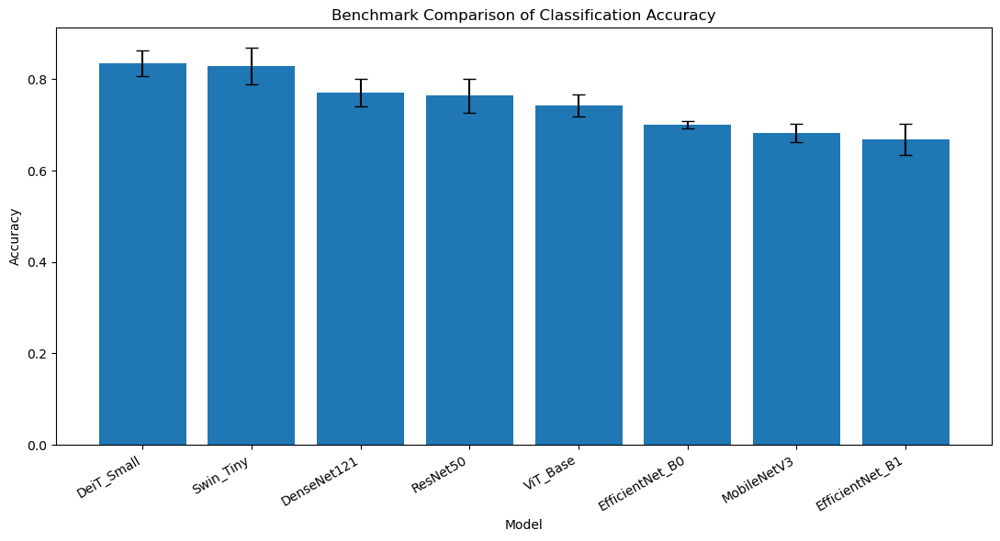


Saved to:
Benchmark_v2\Benchmark_Results\Publication_Figures\Figure_Accuracy_Comparison.png

STEP 10C-2 COMPLETED


In [134]:
# ============================================================
# STEP 10C-2 : ACCURACY COMPARISON
# ============================================================

print("=" * 80)
print("STEP 10C-2 : ACCURACY COMPARISON")
print("=" * 80)

import matplotlib.pyplot as plt

figure_dir = Path(
    "Benchmark_v2/Benchmark_Results/Publication_Figures"
)

figure_dir.mkdir(
    parents=True,
    exist_ok=True
)

plot_df = summary.sort_values(
    "Accuracy_mean",
    ascending=False
)

plt.figure(figsize=(11,6))

plt.bar(
    plot_df["Model"],
    plot_df["Accuracy_mean"],
    yerr=plot_df["Accuracy_std"],
    capsize=5
)

plt.ylabel("Accuracy")
plt.xlabel("Model")
plt.title("Benchmark Comparison of Classification Accuracy")

plt.xticks(rotation=30, ha="right")

plt.tight_layout()

save_path = figure_dir / "Figure_Accuracy_Comparison.png"

plt.savefig(
    save_path,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("\nSaved to:")
print(save_path)

print("\n" + "=" * 80)
print("STEP 10C-2 COMPLETED")
print("=" * 80)

STEP 10C-3 : ALL METRICS COMPARISON


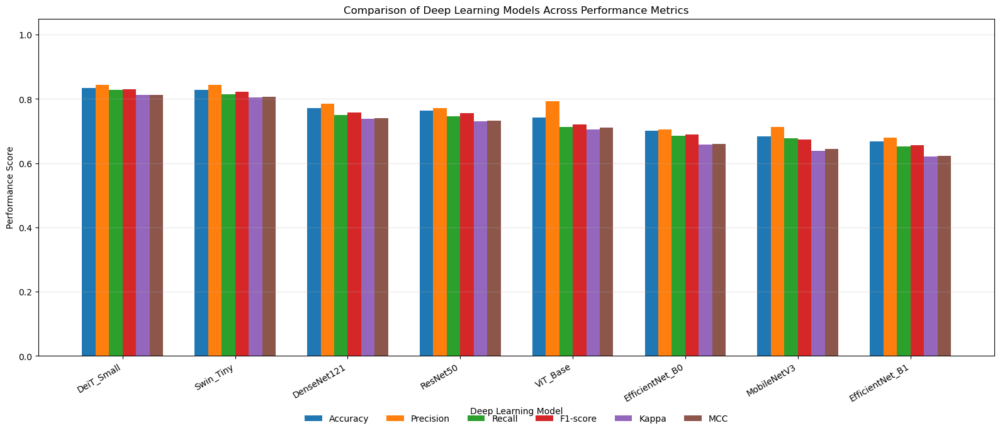


Saved to:
Benchmark_v2\Benchmark_Results\Publication_Figures\Figure_All_Metrics_Comparison.png

STEP 10C-3 COMPLETED


In [135]:
# ============================================================
# STEP 10C-3 : ALL METRICS COMPARISON
# ============================================================

print("=" * 80)
print("STEP 10C-3 : ALL METRICS COMPARISON")
print("=" * 80)

import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# Metrics to Plot
# ------------------------------------------------------------

metrics = [
    "Accuracy_mean",
    "Precision_Macro_mean",
    "Recall_Macro_mean",
    "F1_Macro_mean",
    "Cohen_Kappa_mean",
    "MCC_mean"
]

metric_labels = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "Kappa",
    "MCC"
]

# ------------------------------------------------------------
# Sort Models by Accuracy
# ------------------------------------------------------------

plot_df = summary.sort_values(
    "Accuracy_mean",
    ascending=False
).reset_index(drop=True)

models = plot_df["Model"]

# ------------------------------------------------------------
# Create Plot
# ------------------------------------------------------------

x = np.arange(len(models))
width = 0.12

plt.figure(figsize=(16,7))

for i, metric in enumerate(metrics):

    plt.bar(
        x + i*width,
        plot_df[metric],
        width=width,
        label=metric_labels[i]
    )

# ------------------------------------------------------------
# Formatting
# ------------------------------------------------------------

plt.xticks(
    x + width*2.5,
    models,
    rotation=30,
    ha="right"
)

plt.ylabel("Performance Score")
plt.xlabel("Deep Learning Model")
plt.title("Comparison of Deep Learning Models Across Performance Metrics")

plt.ylim(0,1.05)

plt.legend(
    loc="upper center",
    bbox_to_anchor=(0.5,-0.15),
    ncol=6,
    frameon=False
)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

save_path = (
    figure_dir /
    "Figure_All_Metrics_Comparison.png"
)

plt.savefig(
    save_path,
    dpi=600,
    bbox_inches="tight"
)

plt.show()

print("\nSaved to:")
print(save_path)

print("\n" + "="*80)
print("STEP 10C-3 COMPLETED")
print("="*80)

In [136]:
# ============================================================
# STEP 10D-1 : FINAL MODEL RANKING
# ============================================================

print("=" * 80)
print("STEP 10D-1 : FINAL MODEL RANKING")
print("=" * 80)

ranking_df = summary.copy()

ranking_df = ranking_df.sort_values(
    by="Accuracy_mean",
    ascending=False
).reset_index(drop=True)

ranking_df.insert(
    0,
    "Rank",
    range(1, len(ranking_df) + 1)
)

ranking_df = ranking_df[[
    "Rank",
    "Model",
    "Family",
    "Accuracy_mean",
    "Accuracy_std",
    "Precision_Macro_mean",
    "Recall_Macro_mean",
    "F1_Macro_mean",
    "Cohen_Kappa_mean",
    "MCC_mean"
]]

display(ranking_df)

ranking_csv = figure_dir / "Final_Model_Ranking.csv"

ranking_df.to_csv(
    ranking_csv,
    index=False
)

print("\nSaved to:")
print(ranking_csv)

print("=" * 80)
print("STEP 10D-1 COMPLETED")
print("=" * 80)

STEP 10D-1 : FINAL MODEL RANKING


,Rank,Model,Family,Accuracy_mean,Accuracy_std,Precision_Macro_mean,Recall_Macro_mean,F1_Macro_mean,Cohen_Kappa_mean,MCC_mean
0,1,DeiT_Small,Vision Transformer,0.834821,0.027520,0.843995,0.827370,0.830389,0.811824,0.812957
1,2,Swin_Tiny,Vision Transformer,0.828571,0.040500,0.844414,0.814481,0.821568,0.804327,0.806337
2,3,DenseNet121,CNN,0.771429,0.030179,0.785821,0.749508,0.757357,0.738711,0.740144
3,4,ResNet50,CNN,0.764286,0.036732,0.771761,0.746859,0.755178,0.730620,0.731672
4,5,ViT_Base,Vision Transformer,0.742857,0.024165,0.793916,0.713656,0.721042,0.705114,0.711758
5,6,EfficientNet_B0,CNN,0.700893,0.008352,0.705607,0.686243,0.689569,0.658978,0.660375
6,7,MobileNetV3,CNN,0.683036,0.019965,0.713620,0.678632,0.674618,0.639241,0.643670
7,8,EfficientNet_B1,CNN,0.667857,0.034378,0.679009,0.651437,0.656957,0.620563,0.622188



Saved to:
Benchmark_v2\Benchmark_Results\Publication_Figures\Final_Model_Ranking.csv
STEP 10D-1 COMPLETED


In [137]:
# ============================================================
# STEP 10D-2 : BEST MODEL FOR EACH METRIC
# ============================================================

print("=" * 80)
print("STEP 10D-2 : BEST MODEL FOR EACH METRIC")
print("=" * 80)

metric_map = {
    "Accuracy_mean":"Accuracy",
    "Precision_Macro_mean":"Precision",
    "Recall_Macro_mean":"Recall",
    "F1_Macro_mean":"F1-score",
    "Cohen_Kappa_mean":"Cohen's Kappa",
    "MCC_mean":"MCC"
}

best_models = []

for column, metric in metric_map.items():

    idx = summary[column].idxmax()

    best_models.append({

        "Metric": metric,
        "Best Model": summary.loc[idx, "Model"],
        "Family": summary.loc[idx, "Family"],
        "Score": round(summary.loc[idx, column], 4)

    })

best_df = pd.DataFrame(best_models)

display(best_df)

best_df.to_csv(
    figure_dir / "Best_Model_Per_Metric.csv",
    index=False
)

print("=" * 80)
print("STEP 10D-2 COMPLETED")
print("=" * 80)

STEP 10D-2 : BEST MODEL FOR EACH METRIC


,Metric,Best Model,Family,Score
0,Accuracy,DeiT_Small,Vision Transformer,0.8348
1,Precision,Swin_Tiny,Vision Transformer,0.8444
2,Recall,DeiT_Small,Vision Transformer,0.8274
3,F1-score,DeiT_Small,Vision Transformer,0.8304
4,Cohen's Kappa,DeiT_Small,Vision Transformer,0.8118
5,MCC,DeiT_Small,Vision Transformer,0.8130


STEP 10D-2 COMPLETED


In [138]:
# ============================================================
# STEP 10D-3 : FAMILY-WISE PERFORMANCE SUMMARY
# ============================================================

print("=" * 80)
print("STEP 10D-3 : FAMILY-WISE PERFORMANCE SUMMARY")
print("=" * 80)

import pandas as pd

metrics = [
    "Accuracy_mean",
    "Precision_Macro_mean",
    "Recall_Macro_mean",
    "F1_Macro_mean",
    "Cohen_Kappa_mean",
    "MCC_mean"
]

family_summary = (
    summary
    .groupby("Family")[metrics]
    .agg(["mean", "std"])
)

family_summary.columns = [
    f"{metric}_{stat}"
    for metric, stat in family_summary.columns
]

family_summary = family_summary.reset_index()

display(family_summary)

# ------------------------------------------------------------
# Save Results
# ------------------------------------------------------------

family_csv = figure_dir / "Family_Performance_Summary.csv"

family_summary.to_csv(
    family_csv,
    index=False
)

print("\nSaved to:")
print(family_csv)

print("\n" + "=" * 80)
print("STEP 10D-3 COMPLETED")
print("=" * 80)

STEP 10D-3 : FAMILY-WISE PERFORMANCE SUMMARY


,Family,Accuracy_mean_mean,Accuracy_mean_std,Precision_Macro_mean_mean,Precision_Macro_mean_std,Recall_Macro_mean_mean,Recall_Macro_mean_std,F1_Macro_mean_mean,F1_Macro_mean_std,Cohen_Kappa_mean_mean,Cohen_Kappa_mean_std,MCC_mean_mean,MCC_mean_std
0,CNN,0.717500,0.047501,0.731163,0.045598,0.702536,0.043643,0.706736,0.046673,0.677623,0.053891,0.679610,0.053230
1,Vision Transformer,0.802083,0.051386,0.827442,0.029035,0.785169,0.062267,0.791000,0.060745,0.773755,0.059563,0.777017,0.056613



Saved to:
Benchmark_v2\Benchmark_Results\Publication_Figures\Family_Performance_Summary.csv

STEP 10D-3 COMPLETED


In [139]:
# ============================================================
# STEP 10D-4 : FINAL BENCHMARK REPORT
# ============================================================

print("=" * 80)
print("STEP 10D-4 : FINAL BENCHMARK REPORT")
print("=" * 80)

from pathlib import Path

# ------------------------------------------------------------
# Basic Statistics
# ------------------------------------------------------------

total_models = summary.shape[0]

cnn_models = (summary["Family"] == "CNN").sum()

vit_models = (summary["Family"] == "Vision Transformer").sum()

best_model = ranking_df.iloc[0]

best_cnn = ranking_df[
    ranking_df["Family"] == "CNN"
].iloc[0]

best_vit = ranking_df[
    ranking_df["Family"] == "Vision Transformer"
].iloc[0]

cnn_accuracy = family_summary.loc[
    family_summary["Family"] == "CNN",
    "Accuracy_mean_mean"
].values[0]

vit_accuracy = family_summary.loc[
    family_summary["Family"] == "Vision Transformer",
    "Accuracy_mean_mean"
].values[0]

improvement = vit_accuracy - cnn_accuracy

# ------------------------------------------------------------
# Report
# ------------------------------------------------------------

report = f"""
============================================================
FINAL BENCHMARK REPORT
============================================================

Dataset Summary
---------------
Total Models Evaluated        : {total_models}
CNN Models                    : {cnn_models}
Vision Transformer Models     : {vit_models}

------------------------------------------------------------

Overall Best Model
------------------
Model                          : {best_model['Model']}
Architecture                   : {best_model['Family']}
Mean Accuracy                  : {best_model['Accuracy_mean']:.4f}

------------------------------------------------------------

Best CNN Model
--------------
Model                          : {best_cnn['Model']}
Mean Accuracy                  : {best_cnn['Accuracy_mean']:.4f}

------------------------------------------------------------

Best Vision Transformer
-----------------------
Model                          : {best_vit['Model']}
Mean Accuracy                  : {best_vit['Accuracy_mean']:.4f}

------------------------------------------------------------

Family-wise Mean Accuracy
-------------------------
CNN                           : {cnn_accuracy:.4f}

Vision Transformer            : {vit_accuracy:.4f}

Improvement                   : {improvement:.4f}

------------------------------------------------------------

Statistical Analysis
--------------------
Assumption Test               : Passed

One-way ANOVA                 : Significant (p < 0.001)

Post-hoc Test                 : Tukey HSD

Effect Size                   : Large (η² = 0.78–0.83)

------------------------------------------------------------

Overall Conclusion
------------------
Compact Vision Transformer architectures
(DeiT-Small and Swin-Tiny) consistently
outperformed conventional CNN models for
sedimentary structure classification.

DenseNet121 was the strongest CNN baseline.

ViT-Base did not outperform the compact
transformer models, suggesting that larger
Vision Transformers require larger training
datasets to realize their full potential.

============================================================
"""

print(report)

# ------------------------------------------------------------
# Save Report
# ------------------------------------------------------------

report_path = figure_dir / "Final_Benchmark_Report.txt"

with open(report_path, "w", encoding="utf-8") as f:
    f.write(report)

print("Report saved to:")
print(report_path)

print("\n" + "=" * 80)
print("BENCHMARK PIPELINE COMPLETED SUCCESSFULLY")
print("=" * 80)

STEP 10D-4 : FINAL BENCHMARK REPORT

FINAL BENCHMARK REPORT

Dataset Summary
---------------
Total Models Evaluated        : 8
CNN Models                    : 5
Vision Transformer Models     : 3

------------------------------------------------------------

Overall Best Model
------------------
Model                          : DeiT_Small
Architecture                   : Vision Transformer
Mean Accuracy                  : 0.8348

------------------------------------------------------------

Best CNN Model
--------------
Model                          : DenseNet121
Mean Accuracy                  : 0.7714

------------------------------------------------------------

Best Vision Transformer
-----------------------
Model                          : DeiT_Small
Mean Accuracy                  : 0.8348

------------------------------------------------------------

Family-wise Mean Accuracy
-------------------------
CNN                           : 0.7175

Vision Transformer            : 0.8021



In [141]:
from pathlib import Path

cnn_folder = Path(r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Training_Logs")

print("CNN Training Logs:\n")

for f in cnn_folder.glob("*"):
    print(f.name)

CNN Training Logs:



In [146]:
from pathlib import Path

ROOT = Path(r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2")

print("="*80)
print("Searching for training_summary.csv")
print("="*80)

files = list(ROOT.rglob("training_summary.csv"))

if len(files) == 0:
    print("No training_summary.csv found!")
else:
    for f in files:
        print(f)


from pathlib import Path

ROOT = Path(r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2")

print("="*80)
print("Searching Vision Transformer training summary")
print("="*80)

for file in ROOT.rglob("VisionTransformer_Summary.csv"):
    print(file)

Searching for training_summary.csv
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Saved_Models\training_summary.csv
Searching Vision Transformer training summary
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\VisionTransformer_Summary.csv


In [148]:
from pathlib import Path

ROOT = Path(r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2")

print("="*80)
print("Searching Benchmark_Performance_Summary.csv")
print("="*80)

files = list(ROOT.rglob("Benchmark_Performance_Summary.csv"))

if files:
    for f in files:
        print(f)
else:
    print("File not found.")

Searching Benchmark_Performance_Summary.csv
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Statistical_Analysis\Benchmark_Performance_Summary.csv


In [151]:
import pandas as pd
from pathlib import Path

history_file = Path(
    r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2"
) / "Benchmark_Results" / "VisionTransformer_Results" / "Training_Logs" / "DeiT_Small_Run1_History.csv"

history = pd.read_csv(history_file)

print(history.head())
print("\nColumns:")
print(history.columns.tolist())

   Epoch  Train Loss  Train Accuracy  Validation Loss  Validation Accuracy  \
0      1    1.916949        0.369318         1.551605             0.609023   
1      2    1.061454        0.679924         0.780867             0.721805   
2      3    0.691446        0.770833         0.646432             0.774436   
3      4    0.653064        0.765152         0.562562             0.774436   
4      5    0.677753        0.770833         1.226120             0.548872   

   Learning Rate  Train Time  Validation Time  
0       0.000084   48.863963        70.562539  
1       0.000138   50.049582        29.973075  
2       0.000192   52.440969         9.640699  
3       0.000246   55.654600        65.844436  
4       0.000300   51.011695         9.554075  

Columns:
['Epoch', 'Train Loss', 'Train Accuracy', 'Validation Loss', 'Validation Accuracy', 'Learning Rate', 'Train Time', 'Validation Time']


In [152]:
vit_summary = pd.read_csv(vit_training_file)

print(vit_summary.head())

        Model         Accuracy  Accuracy_Mean  Accuracy_Std        Precision  \
0  DeiT_Small  0.8348 ± 0.0275       0.834821      0.027520  0.8440 ± 0.0311   
1   Swin_Tiny  0.8286 ± 0.0405       0.828571      0.040500  0.8444 ± 0.0339   
2    ViT_Base  0.7429 ± 0.0242       0.742857      0.024165  0.7939 ± 0.0265   

   Precision_Mean  Precision_Std           Recall  Recall_Mean  Recall_Std  \
0        0.843995       0.031087  0.8274 ± 0.0315     0.827370    0.031497   
1        0.844414       0.033905  0.8145 ± 0.0473     0.814481    0.047331   
2        0.793916       0.026516  0.7137 ± 0.0391     0.713656    0.039077   

          F1 Score  F1 Score_Mean  F1 Score_Std      Cohen Kappa  \
0  0.8304 ± 0.0324       0.830389      0.032359  0.8118 ± 0.0312   
1  0.8216 ± 0.0446       0.821568      0.044571  0.8043 ± 0.0464   
2  0.7210 ± 0.0364       0.721042      0.036412  0.7051 ± 0.0288   

   Cohen Kappa_Mean  Cohen Kappa_Std              MCC  MCC_Mean   MCC_Std  
0          0.8118

In [149]:
print("\nCNN Columns")
print(cnn_train.columns.tolist())

print("\nVision Transformer Columns")
print(vit_train.columns.tolist())

print("\nBenchmark Columns")
print(benchmark.columns.tolist())


CNN Columns
['Model', 'Run', 'Seed', 'Status', 'Learning Rate', 'Epochs', 'Image Size', 'Batch Size', 'Training Time (min)']

Vision Transformer Columns
['Model', 'Accuracy', 'Accuracy_Mean', 'Accuracy_Std', 'Precision', 'Precision_Mean', 'Precision_Std', 'Recall', 'Recall_Mean', 'Recall_Std', 'F1 Score', 'F1 Score_Mean', 'F1 Score_Std', 'Cohen Kappa', 'Cohen Kappa_Mean', 'Cohen Kappa_Std', 'MCC', 'MCC_Mean', 'MCC_Std']

Benchmark Columns


NameError: name 'benchmark' is not defined

In [154]:
# ============================================================
# STEP 10E-0 : PREPARE COMPUTATIONAL EFFICIENCY DATASET
# ============================================================

print("="*80)
print("STEP 10E-0 : PREPARE COMPUTATIONAL EFFICIENCY DATASET")
print("="*80)

from pathlib import Path
import pandas as pd
import numpy as np

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

ROOT = Path(r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2")

cnn_training_file = (
    ROOT /
    "Benchmark_Results" /
    "Saved_Models" /
    "training_summary.csv"
)

benchmark_file = (
    ROOT /
    "Benchmark_Results" /
    "Statistical_Analysis" /
    "Benchmark_Performance_Summary.csv"
)

vit_summary_file = (
    ROOT /
    "Benchmark_Results" /
    "VisionTransformer_Results" /
    "VisionTransformer_Summary.csv"
)

vit_history_dir = (
    ROOT /
    "Benchmark_Results" /
    "VisionTransformer_Results" /
    "Training_Logs"
)

output_dir = (
    ROOT /
    "Benchmark_Results" /
    "Publication_Figures"
)

output_dir.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Check Files
# ------------------------------------------------------------

assert cnn_training_file.exists(), "CNN training summary not found."
assert benchmark_file.exists(), "Benchmark summary not found."
assert vit_summary_file.exists(), "Vision Transformer summary not found."
assert vit_history_dir.exists(), "Vision Transformer history folder not found."

# ------------------------------------------------------------
# Load CNN Training Summary
# ------------------------------------------------------------

cnn_train = pd.read_csv(cnn_training_file)

cnn_summary = (
    cnn_train
    .groupby("Model", as_index=False)
    .agg({
        "Training Time (min)": "mean",
        "Run": "count"
    })
)

cnn_summary.rename(columns={
    "Training Time (min)": "Training_Time_Min",
    "Run": "Runs"
}, inplace=True)

cnn_summary["Family"] = "CNN"

# ------------------------------------------------------------
# Compute Vision Transformer Training Time
# ------------------------------------------------------------

history_files = sorted(vit_history_dir.glob("*History.csv"))

records = []

for file in history_files:

    df = pd.read_csv(file)

    model = "_".join(file.stem.split("_")[:-2])
    run = file.stem.split("_")[-2]

    # Total training time in minutes
    total_time = (
        df["Train Time"] +
        df["Validation Time"]
    ).sum() / 60.0

    records.append({
        "Model": model,
        "Run": run,
        "Training_Time_Min": total_time
    })

vit_train = pd.DataFrame(records)

vit_summary = (
    vit_train
    .groupby("Model", as_index=False)
    .agg({
        "Training_Time_Min": "mean",
        "Run": "count"
    })
)

vit_summary.rename(columns={
    "Run": "Runs"
}, inplace=True)

vit_summary["Family"] = "Vision Transformer"

# ------------------------------------------------------------
# Parameters
# ------------------------------------------------------------

parameter_dict = {

    "ResNet50":25557032,
    "DenseNet121":7978856,
    "MobileNetV3":4214456,
    "EfficientNet_B0":5288548,
    "EfficientNet_B1":7794184,

    "DeiT_Small":21669129,
    "Swin_Tiny":27526275,
    "ViT_Base":85805577

}

cnn_summary["Parameters"] = cnn_summary["Model"].map(parameter_dict)
vit_summary["Parameters"] = vit_summary["Model"].map(parameter_dict)

# ------------------------------------------------------------
# Merge CNN + Vision Transformer
# ------------------------------------------------------------

training_summary = pd.concat(
    [cnn_summary, vit_summary],
    ignore_index=True
)

training_summary["Parameters_Million"] = (
    training_summary["Parameters"] / 1e6
)

# ------------------------------------------------------------
# Load Benchmark Performance
# ------------------------------------------------------------

benchmark = pd.read_csv(benchmark_file)

benchmark = benchmark.rename(columns={
    "Accuracy_mean":"Accuracy"
})

metrics = [
    "Model",
    "Accuracy",
    "Precision_Macro_mean",
    "Recall_Macro_mean",
    "F1_Macro_mean",
    "Cohen_Kappa_mean",
    "MCC_mean"
]

training_summary = training_summary.merge(
    benchmark[metrics],
    on="Model",
    how="left"
)

# ------------------------------------------------------------
# Sort
# ------------------------------------------------------------

training_summary = training_summary.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

save_file = output_dir / "Computational_Efficiency_Summary.csv"

training_summary.to_csv(
    save_file,
    index=False
)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("\nComputational Efficiency Dataset\n")

print(training_summary.round(4))

print("\nSaved to:")
print(save_file)

print("\nDone.")

STEP 10E-0 : PREPARE COMPUTATIONAL EFFICIENCY DATASET

Computational Efficiency Dataset

             Model  Training_Time_Min  Runs              Family  Parameters  \
0       DeiT_Small            39.1024     5  Vision Transformer    21669129   
1        Swin_Tiny            75.1840     5  Vision Transformer    27526275   
2      DenseNet121            40.8600     5                 CNN     7978856   
3         ResNet50            41.9720     5                 CNN    25557032   
4         ViT_Base            51.3300     5  Vision Transformer    85805577   
5  EfficientNet_B0            21.7600     5                 CNN     5288548   
6      MobileNetV3            12.6760     5                 CNN     4214456   
7  EfficientNet_B1            36.1360     5                 CNN     7794184   

   Parameters_Million  Accuracy  Precision_Macro_mean  Recall_Macro_mean  \
0             21.6691    0.8348                0.8440             0.8274   
1             27.5263    0.8286                

In [155]:
# ============================================================
# STEP 10E-1 : COMPUTATIONAL EFFICIENCY SUMMARY TABLE
# ============================================================

print("="*80)
print("STEP 10E-1 : COMPUTATIONAL EFFICIENCY SUMMARY TABLE")
print("="*80)

from pathlib import Path
import pandas as pd

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

ROOT = Path(r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2")

summary_file = (
    ROOT /
    "Benchmark_Results" /
    "Publication_Figures" /
    "Computational_Efficiency_Summary.csv"
)

output_dir = (
    ROOT /
    "Benchmark_Results" /
    "Publication_Figures"
)

# ------------------------------------------------------------
# Load Summary
# ------------------------------------------------------------

df = pd.read_csv(summary_file)

# ------------------------------------------------------------
# Round Values
# ------------------------------------------------------------

table = df.copy()

table["Accuracy"] = table["Accuracy"].round(4)
table["Training_Time_Min"] = table["Training_Time_Min"].round(2)
table["Parameters_Million"] = table["Parameters_Million"].round(2)

table = table[
    [
        "Model",
        "Family",
        "Accuracy",
        "Training_Time_Min",
        "Parameters_Million",
        "Precision_Macro_mean",
        "Recall_Macro_mean",
        "F1_Macro_mean",
        "Cohen_Kappa_mean",
        "MCC_mean"
    ]
]

table.rename(columns={
    "Training_Time_Min":"Training Time (min)",
    "Parameters_Million":"Parameters (Million)",
    "Precision_Macro_mean":"Precision",
    "Recall_Macro_mean":"Recall",
    "F1_Macro_mean":"F1-score",
    "Cohen_Kappa_mean":"Cohen's Kappa",
    "MCC_mean":"MCC"
}, inplace=True)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

save_file = output_dir / "Table_Computational_Efficiency.csv"

table.to_csv(save_file, index=False)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("\nPublication Table\n")
print(table)

print("\nSaved to:")
print(save_file)

STEP 10E-1 : COMPUTATIONAL EFFICIENCY SUMMARY TABLE

Publication Table

             Model              Family  Accuracy  Training Time (min)  \
0       DeiT_Small  Vision Transformer    0.8348                39.10   
1        Swin_Tiny  Vision Transformer    0.8286                75.18   
2      DenseNet121                 CNN    0.7714                40.86   
3         ResNet50                 CNN    0.7643                41.97   
4         ViT_Base  Vision Transformer    0.7429                51.33   
5  EfficientNet_B0                 CNN    0.7009                21.76   
6      MobileNetV3                 CNN    0.6830                12.68   
7  EfficientNet_B1                 CNN    0.6679                36.14   

   Parameters (Million)  Precision    Recall  F1-score  Cohen's Kappa  \
0                 21.67   0.843995  0.827370  0.830389       0.811824   
1                 27.53   0.844414  0.814481  0.821568       0.804327   
2                  7.98   0.785821  0.749508  0.757

STEP 10E-2 : ACCURACY vs TRAINING TIME


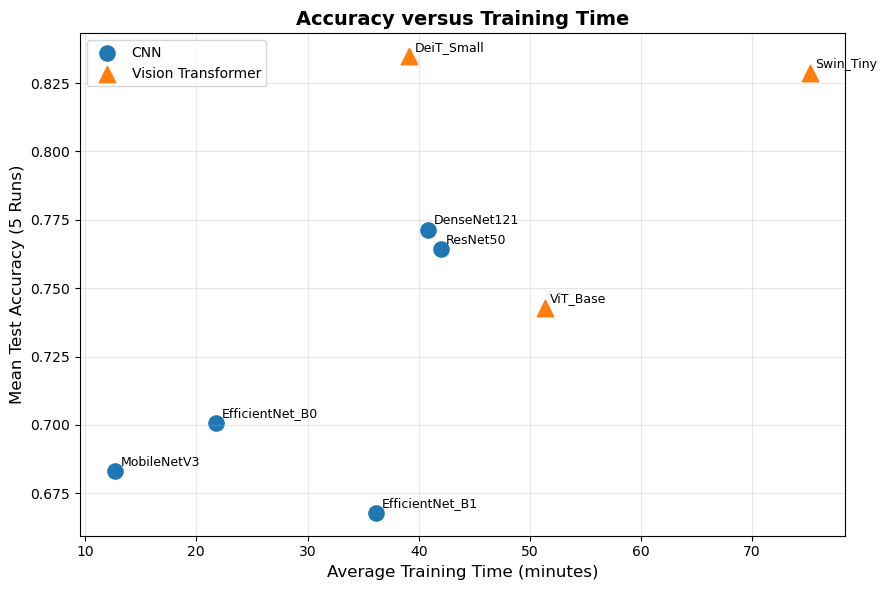


Saved:
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Publication_Figures\Figure_Accuracy_vs_Training_Time.png
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Publication_Figures\Figure_Accuracy_vs_Training_Time.pdf


In [162]:
# ============================================================
# STEP 10E-2 : ACCURACY vs TRAINING TIME
# ============================================================

print("="*80)
print("STEP 10E-2 : ACCURACY vs TRAINING TIME")
print("="*80)

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

ROOT = Path(r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2")

summary_file = (
    ROOT /
    "Benchmark_Results" /
    "Publication_Figures" /
    "Computational_Efficiency_Summary.csv"
)

output_dir = (
    ROOT /
    "Benchmark_Results" /
    "Publication_Figures"
)

# ------------------------------------------------------------
# Load Data
# ------------------------------------------------------------

df = pd.read_csv(summary_file)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(figsize=(9,6))

cnn = df[df["Family"]=="CNN"]
vit = df[df["Family"]=="Vision Transformer"]

plt.scatter(
    cnn["Training_Time_Min"],
    cnn["Accuracy"],
    s=120,
    marker='o',
    label="CNN"
)

plt.scatter(
    vit["Training_Time_Min"],
    vit["Accuracy"],
    s=140,
    marker='^',
    label="Vision Transformer"
)

# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

for _, row in df.iterrows():

    plt.text(
        row["Training_Time_Min"] + 0.5,
        row["Accuracy"] + 0.002,
        row["Model"],
        fontsize=9
    )

# ------------------------------------------------------------
# Formatting
# ------------------------------------------------------------

plt.xlabel("Average Training Time (minutes)", fontsize=12)
plt.ylabel("Mean Test Accuracy (5 Runs)", fontsize=12)

plt.title(
    "Accuracy versus Training Time",
    fontsize=14,
    weight="bold"
)

plt.grid(True, alpha=0.3)

plt.legend()

plt.tight_layout()

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

save_png = output_dir / "Figure_Accuracy_vs_Training_Time.png"
save_pdf = output_dir / "Figure_Accuracy_vs_Training_Time.pdf"

plt.savefig(save_png, dpi=600)
plt.savefig(save_pdf)

plt.show()

print("\nSaved:")

print(save_png)
print(save_pdf)

STEP 10E-3 : ACCURACY vs MODEL PARAMETERS


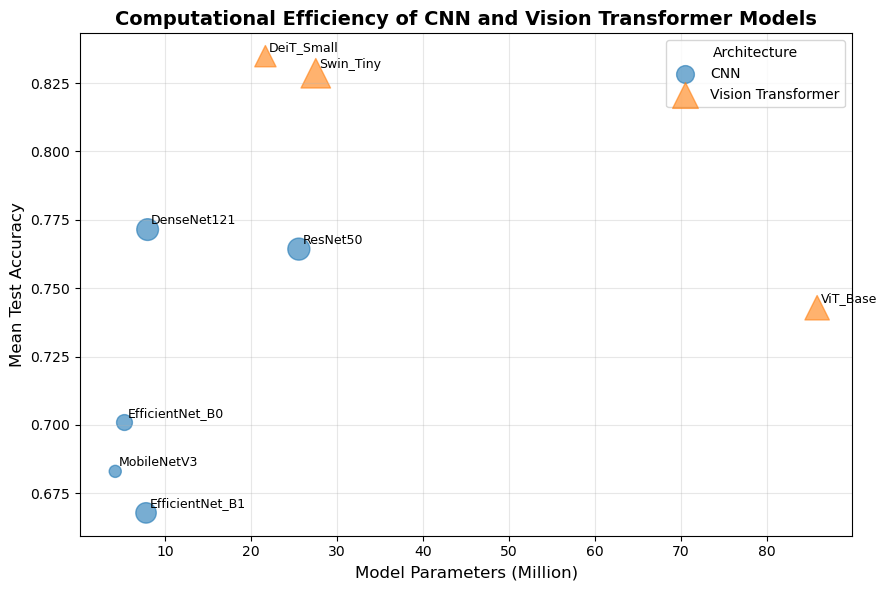


Saved:
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Publication_Figures\Figure_Accuracy_vs_Parameters_Bubble.png
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Publication_Figures\Figure_Accuracy_vs_Parameters_Bubble.pdf


In [164]:
# ============================================================
# STEP 10E-3 : ACCURACY vs MODEL PARAMETERS (BUBBLE PLOT)
# ============================================================

print("="*80)
print("STEP 10E-3 : ACCURACY vs MODEL PARAMETERS")
print("="*80)

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

ROOT = Path(r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2")

summary_file = (
    ROOT /
    "Benchmark_Results" /
    "Publication_Figures" /
    "Computational_Efficiency_Summary.csv"
)

output_dir = (
    ROOT /
    "Benchmark_Results" /
    "Publication_Figures"
)

# ------------------------------------------------------------
# Load Data
# ------------------------------------------------------------

df = pd.read_csv(summary_file)

# ------------------------------------------------------------
# Bubble Size
# ------------------------------------------------------------

# Bubble size proportional to training time
bubble_size = df["Training_Time_Min"] * 12

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(figsize=(9,6))

cnn = df[df["Family"]=="CNN"]
vit = df[df["Family"]=="Vision Transformer"]

plt.scatter(
    cnn["Parameters_Million"],
    cnn["Accuracy"],
    s=cnn["Training_Time_Min"]*6,
    alpha=0.6,
    marker='o',
    label="CNN"
)

plt.scatter(
    vit["Parameters_Million"],
    vit["Accuracy"],
    s=vit["Training_Time_Min"]*6,
    alpha=0.6,
    marker='^',
    label="Vision Transformer"
)

# ------------------------------------------------------------
# Labels
# ------------------------------------------------------------

for _, row in df.iterrows():

    plt.text(
        row["Parameters_Million"]+0.4,
        row["Accuracy"]+0.002,
        row["Model"],
        fontsize=9
    )

# ------------------------------------------------------------
# Formatting
# ------------------------------------------------------------

plt.xlabel("Model Parameters (Million)", fontsize=12)
plt.ylabel("Mean Test Accuracy", fontsize=12)

plt.title(
    "Computational Efficiency of CNN and Vision Transformer Models",
    fontsize=14,
    weight="bold"
)

plt.grid(True, alpha=0.3)

plt.legend(title="Architecture")

plt.tight_layout()

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

save_png = output_dir / "Figure_Accuracy_vs_Parameters_Bubble.png"
save_pdf = output_dir / "Figure_Accuracy_vs_Parameters_Bubble.pdf"

plt.savefig(save_png, dpi=600)
plt.savefig(save_pdf)

plt.show()

print("\nSaved:")

print(save_png)
print(save_pdf)

In [165]:
# ============================================================
# STEP 10E-4 : COMPUTATIONAL EFFICIENCY RANKING
# ============================================================

print("="*80)
print("STEP 10E-4 : COMPUTATIONAL EFFICIENCY RANKING")
print("="*80)

from pathlib import Path
import pandas as pd

# ------------------------------------------------------------
# Paths
# ------------------------------------------------------------

ROOT = Path(r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2")

summary_file = (
    ROOT /
    "Benchmark_Results" /
    "Publication_Figures" /
    "Computational_Efficiency_Summary.csv"
)

output_dir = (
    ROOT /
    "Benchmark_Results" /
    "Publication_Figures"
)

# ------------------------------------------------------------
# Load
# ------------------------------------------------------------

df = pd.read_csv(summary_file)

# ------------------------------------------------------------
# Rankings
# ------------------------------------------------------------

best_accuracy = df.loc[df["Accuracy"].idxmax()]

fastest = df.loc[df["Training_Time_Min"].idxmin()]

smallest = df.loc[df["Parameters_Million"].idxmin()]

best_cnn = (
    df[df["Family"]=="CNN"]
    .sort_values("Accuracy", ascending=False)
    .iloc[0]
)

best_vit = (
    df[df["Family"]=="Vision Transformer"]
    .sort_values("Accuracy", ascending=False)
    .iloc[0]
)

# ------------------------------------------------------------
# Summary Table
# ------------------------------------------------------------

ranking = pd.DataFrame({

    "Category":[
        "Highest Accuracy",
        "Fastest Training",
        "Smallest Model",
        "Best CNN",
        "Best Vision Transformer"
    ],

    "Model":[
        best_accuracy["Model"],
        fastest["Model"],
        smallest["Model"],
        best_cnn["Model"],
        best_vit["Model"]
    ],

    "Accuracy":[
        best_accuracy["Accuracy"],
        fastest["Accuracy"],
        smallest["Accuracy"],
        best_cnn["Accuracy"],
        best_vit["Accuracy"]
    ],

    "Training Time (min)":[
        best_accuracy["Training_Time_Min"],
        fastest["Training_Time_Min"],
        smallest["Training_Time_Min"],
        best_cnn["Training_Time_Min"],
        best_vit["Training_Time_Min"]
    ],

    "Parameters (Million)":[
        best_accuracy["Parameters_Million"],
        fastest["Parameters_Million"],
        smallest["Parameters_Million"],
        best_cnn["Parameters_Million"],
        best_vit["Parameters_Million"]
    ]

})

ranking = ranking.round(2)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

save_file = output_dir / "Computational_Efficiency_Ranking.csv"

ranking.to_csv(save_file,index=False)

print("\nComputational Efficiency Ranking\n")

print(ranking)

print("\nSaved to:")

print(save_file)

STEP 10E-4 : COMPUTATIONAL EFFICIENCY RANKING

Computational Efficiency Ranking

                  Category        Model  Accuracy  Training Time (min)  \
0         Highest Accuracy   DeiT_Small      0.83                39.10   
1         Fastest Training  MobileNetV3      0.68                12.68   
2           Smallest Model  MobileNetV3      0.68                12.68   
3                 Best CNN  DenseNet121      0.77                40.86   
4  Best Vision Transformer   DeiT_Small      0.83                39.10   

   Parameters (Million)  
0                 21.67  
1                  4.21  
2                  4.21  
3                  7.98  
4                 21.67  

Saved to:
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Publication_Figures\Computational_Efficiency_Ranking.csv


In [252]:
# ============================================================
# STEP 11A-1 : ABLATION STUDY CONFIGURATION
# EFFECT OF DATA AUGMENTATION
# Experiment : WITHOUT DATA AUGMENTATION
# ============================================================

from pathlib import Path
import torch
import random
import numpy as np

print("=" * 80)
print("STEP 11A-1 : ABLATION STUDY CONFIGURATION")
print("Experiment : WITHOUT DATA AUGMENTATION")
print("=" * 80)

# ------------------------------------------------------------
# Project Directories
# ------------------------------------------------------------

PROJECT_DIR = ROOT

DATASET_ROOT = PROJECT_DIR / "Fixed_Split"

TRAINVAL_DIR = DATASET_ROOT / "TrainVal"

TEST_DIR = DATASET_ROOT / "Test"

# ------------------------------------------------------------
# Output Directories
# ------------------------------------------------------------

ABLATION_RESULTS_DIR = OUTPUT_DIR / "Ablation_Study"

WITHOUT_AUG_DIR = ABLATION_RESULTS_DIR / "Without_Augmentation"

ABLATION_MODELS_DIR = WITHOUT_AUG_DIR / "Saved_Models"

ABLATION_LOGS_DIR = WITHOUT_AUG_DIR / "Training_Logs"

ABLATION_RESULTS_CSV = WITHOUT_AUG_DIR / "Without_Augmentation_Results.csv"

ABLATION_FIGURES_DIR = WITHOUT_AUG_DIR / "Figures"

for folder in [
    WITHOUT_AUG_DIR,
    ABLATION_MODELS_DIR,
    ABLATION_LOGS_DIR,
    ABLATION_FIGURES_DIR
]:
    folder.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Dataset Configuration
# ------------------------------------------------------------

IMAGE_SIZE = 224

NUM_CLASSES = len(CLASSES)

# ------------------------------------------------------------
# Training Configuration
# (Keep IDENTICAL to Benchmark)
# ------------------------------------------------------------

NUM_RUNS = 5

WARMUP_EPOCHS = 5

NUM_EPOCHS = 50

BATCH_SIZE = 32

INITIAL_LR = 3e-4

WEIGHT_DECAY = 1e-4

NUM_WORKERS = 4

PIN_MEMORY = True

EARLY_STOPPING_PATIENCE = 10

# ------------------------------------------------------------
# Ablation Configuration
# ------------------------------------------------------------

MODEL_NAME = "DeiT_Small"

ABLATION_MODEL = MODEL_NAME

USE_AUGMENTATION = False

EXPERIMENT_NAME = "Without_Augmentation"

# ------------------------------------------------------------
# Random Seed
# ------------------------------------------------------------

SEED = 42

random.seed(SEED)
np.random.seed(SEED)

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

# ------------------------------------------------------------
# Device
# ------------------------------------------------------------

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print(f"Experiment             : {EXPERIMENT_NAME}")
print(f"Model                  : {MODEL_NAME}")
print(f"Augmentation           : {USE_AUGMENTATION}")
print(f"Device                 : {DEVICE}")
print(f"Image Size             : {IMAGE_SIZE}")
print(f"Classes                : {NUM_CLASSES}")
print(f"Epochs                 : {NUM_EPOCHS}")
print(f"Batch Size             : {BATCH_SIZE}")
print(f"Learning Rate          : {INITIAL_LR}")
print(f"Weight Decay           : {WEIGHT_DECAY}")
print(f"Runs                   : {NUM_RUNS}")
print(f"Random Seed            : {SEED}")

print("\nOutput Directory")
print(WITHOUT_AUG_DIR)

print("=" * 80)
print("STEP 11A-1 COMPLETED")
print("=" * 80)

STEP 11A-1 : ABLATION STUDY CONFIGURATION
Experiment : WITHOUT DATA AUGMENTATION
Experiment             : Without_Augmentation
Model                  : DeiT_Small
Augmentation           : False
Device                 : cpu
Image Size             : 224
Classes                : 9
Epochs                 : 50
Batch Size             : 32
Learning Rate          : 0.0003
Weight Decay           : 0.0001
Runs                   : 5
Random Seed            : 42

Output Directory
Benchmark_v2\Benchmark_Results\Ablation_Study\Without_Augmentation
STEP 11A-1 COMPLETED


In [186]:
# ============================================================
# STEP 11A-2 : IMPORT REQUIRED LIBRARIES
# ============================================================

print("=" * 80)
print("STEP 11A-2 : IMPORT REQUIRED LIBRARIES")
print("=" * 80)

# ------------------------------------------------------------
# Standard Libraries
# ------------------------------------------------------------

import os
import time
import copy
import warnings

from pathlib import Path

warnings.filterwarnings("ignore")

# ------------------------------------------------------------
# Numerical Libraries
# ------------------------------------------------------------

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Visualization
# ------------------------------------------------------------

import matplotlib.pyplot as plt

# ------------------------------------------------------------
# PyTorch
# ------------------------------------------------------------

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import DataLoader

# ------------------------------------------------------------
# Torchvision
# ------------------------------------------------------------

from torchvision import datasets
from torchvision import transforms

# ------------------------------------------------------------
# timm (Transformer Models)
# ------------------------------------------------------------

import timm

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef,
    log_loss,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)

# ------------------------------------------------------------
# Progress Bar
# ------------------------------------------------------------

from tqdm.auto import tqdm

# ------------------------------------------------------------
# Verify Installation
# ------------------------------------------------------------

print(f"PyTorch Version      : {torch.__version__}")
print(f"CUDA Available       : {torch.cuda.is_available()}")

if torch.cuda.is_available():
    print(f"GPU                  : {torch.cuda.get_device_name(0)}")

print(f"timm Version         : {timm.__version__}")

print("=" * 80)
print("STEP 11A-2 COMPLETED")
print("=" * 80)

STEP 11A-2 : IMPORT REQUIRED LIBRARIES
PyTorch Version      : 2.7.1+cpu
CUDA Available       : False
timm Version         : 1.0.27
STEP 11A-2 COMPLETED


In [187]:
# ============================================================
# STEP 11A-3 : DATASET CONFIGURATION
# ============================================================

print("=" * 80)
print("STEP 11A-3 : DATASET CONFIGURATION")
print("=" * 80)

# ------------------------------------------------------------
# Dataset Directories
# ------------------------------------------------------------

DATASET_ROOT = PROJECT_DIR / "Fixed_Split"

TRAINVAL_DIR = DATASET_ROOT / "TrainVal"

TEST_DIR = DATASET_ROOT / "Test"

# ------------------------------------------------------------
# Verify Directories
# ------------------------------------------------------------

for folder in [TRAINVAL_DIR, TEST_DIR]:

    if not folder.exists():
        raise FileNotFoundError(f"Directory not found:\n{folder}")

# ------------------------------------------------------------
# Discover Classes
# ------------------------------------------------------------

CLASSES = sorted([
    d.name
    for d in TRAINVAL_DIR.iterdir()
    if d.is_dir()
])

NUM_CLASSES = len(CLASSES)

# ------------------------------------------------------------
# Count Images
# ------------------------------------------------------------

def count_images(root):

    total = 0

    counts = {}

    for cls in CLASSES:

        n = len(list((root / cls).glob("*")))

        counts[cls] = n

        total += n

    return total, counts

trainval_total, trainval_counts = count_images(TRAINVAL_DIR)

test_total, test_counts = count_images(TEST_DIR)

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print(f"TrainVal Images : {trainval_total}")
print(f"Test Images     : {test_total}")

print(f"\nClasses ({NUM_CLASSES})")

for c in CLASSES:
    print(f" - {c}")

print("=" * 80)
print("STEP 11A-3 COMPLETED")
print("=" * 80)

STEP 11A-3 : DATASET CONFIGURATION
TrainVal Images : 661
Test Images     : 224

Classes (9)
 - BSS
 - CL
 - FS
 - HBCS
 - HCS
 - PCS
 - PL
 - RM
 - TCS
STEP 11A-3 COMPLETED


In [253]:
# ============================================================
# STEP 11A-4 : TRANSFORMER MODEL FACTORY
# ============================================================

print("=" * 80)
print("STEP 11A-4 : TRANSFORMER MODEL FACTORY")
print("=" * 80)

import timm

# ------------------------------------------------------------
# Available Transformer Models
# ------------------------------------------------------------

ABLATION_MODELS = {

    "DeiT_Small": "deit_small_patch16_224",

    "Swin_Tiny": "swin_tiny_patch4_window7_224",

    "ViT_Base": "vit_base_patch16_224"

}

# ------------------------------------------------------------
# Model Factory
# ------------------------------------------------------------

def create_model(model_name):

    """
    Create a pretrained transformer model.

    Parameters
    ----------
    model_name : str

    Returns
    -------
    model
    """

    if model_name not in ABLATION_MODELS:
        raise ValueError(
            f"Unknown model: {model_name}\n"
            f"Available models: {list(ABLATION_MODELS.keys())}"
        )

    model = timm.create_model(

        ABLATION_MODELS[model_name],

        pretrained=True,

        num_classes=NUM_CLASSES

    )

    return model.to(DEVICE)

# ------------------------------------------------------------
# Display Available Models
# ------------------------------------------------------------

print("Available Transformer Models:\n")

for key, value in ABLATION_MODELS.items():
    print(f"{key:<15} -> {value}")

print("=" * 80)
print("STEP 11A-4 COMPLETED")
print("=" * 80)

STEP 11A-4 : TRANSFORMER MODEL FACTORY
Available Transformer Models:

DeiT_Small      -> deit_small_patch16_224
Swin_Tiny       -> swin_tiny_patch4_window7_224
ViT_Base        -> vit_base_patch16_224
STEP 11A-4 COMPLETED


In [ ]:
# ============================================================
# STEP 11A-5 : TRANSFORMER DATALOADER FACTORY
# WITHOUT DATA AUGMENTATION
# ============================================================

print("=" * 80)
print("STEP 11A-5 : TRANSFORMER DATALOADER FACTORY")
print("Experiment : WITHOUT DATA AUGMENTATION")
print("=" * 80)

from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import train_test_split

from timm.data import resolve_model_data_config
from timm.data.transforms_factory import create_transform

# ------------------------------------------------------------
# DataLoader Factory
# ------------------------------------------------------------

def create_dataloaders(model_name):

    # --------------------------------------------------------
    # Temporary pretrained model
    # --------------------------------------------------------

    temp_model = timm.create_model(
        ABLATION_MODELS[model_name],
        pretrained=True
    )

    # --------------------------------------------------------
    # Resolve official preprocessing
    # --------------------------------------------------------

    data_config = resolve_model_data_config(temp_model)

    # --------------------------------------------------------
    # WITHOUT DATA AUGMENTATION
    # --------------------------------------------------------

    train_transform = create_transform(
        **data_config,
        is_training=False
    )

    eval_transform = create_transform(
        **data_config,
        is_training=False
    )

    # --------------------------------------------------------
    # Independent datasets
    # --------------------------------------------------------

    train_dataset_full = ImageFolder(
        root=TRAINVAL_DIR,
        transform=train_transform
    )

    val_dataset_full = ImageFolder(
        root=TRAINVAL_DIR,
        transform=eval_transform
    )

    test_dataset = ImageFolder(
        root=TEST_DIR,
        transform=eval_transform
    )

    # --------------------------------------------------------
    # Same random split as Benchmark
    # --------------------------------------------------------

    indices = list(range(len(train_dataset_full)))

    train_idx, val_idx = train_test_split(
        indices,
        test_size=0.20,
        random_state=SEED,
        shuffle=True,
        stratify=train_dataset_full.targets
    )

    train_dataset = Subset(train_dataset_full, train_idx)

    val_dataset = Subset(val_dataset_full, val_idx)

    # --------------------------------------------------------
    # DataLoaders
    # --------------------------------------------------------

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY
    )

    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=NUM_WORKERS,
        pin_memory=PIN_MEMORY
    )

    print(f"\nModel : {model_name}")
    print(f"Training Images   : {len(train_dataset)}")
    print(f"Validation Images : {len(val_dataset)}")
    print(f"Testing Images    : {len(test_dataset)}")
    print("Data Augmentation : Disabled")

    return (
        train_loader,
        val_loader,
        test_loader,
        data_config
    )

print("✓ Transformer DataLoader Factory Ready")

print("=" * 80)
print("STEP 11A-5 COMPLETED")
print("=" * 80)

# ============================================================
# TEST STEP 11A-5
# ============================================================

train_loader, val_loader, test_loader, data_config = create_dataloaders("DeiT_Small")

print("=" * 80)
print("DATALOADER TEST")
print("=" * 80)

print(f"Train batches      : {len(train_loader)}")
print(f"Validation batches : {len(val_loader)}")
print(f"Test batches       : {len(test_loader)}")

images, labels = next(iter(train_loader))

print(f"\nImage Batch Shape : {images.shape}")
print(f"Label Shape       : {labels.shape}")

print("\nData Config:")
print(data_config)

print("\n✓ WITHOUT DATA AUGMENTATION VERIFIED")

In [190]:
# ============================================================
# STEP 11A-6 : TRAINING UTILITIES
# ============================================================

print("=" * 80)
print("STEP 11A-6 : TRAINING UTILITIES")
print("=" * 80)

import time
import copy
from pathlib import Path

import torch
import torch.nn as nn
import torch.optim as optim

# ------------------------------------------------------------
# Loss Function
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss()

# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

def create_optimizer(model):

    return optim.AdamW(
        model.parameters(),
        lr=INITIAL_LR,
        weight_decay=WEIGHT_DECAY
    )

# ------------------------------------------------------------
# Learning Rate Scheduler
# ------------------------------------------------------------

def create_scheduler(optimizer):

    warmup_scheduler = optim.lr_scheduler.LinearLR(
        optimizer,
        start_factor=0.1,
        end_factor=1.0,
        total_iters=WARMUP_EPOCHS
    )

    cosine_scheduler = optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=NUM_EPOCHS - WARMUP_EPOCHS,
        eta_min=1e-6
    )

    scheduler = optim.lr_scheduler.SequentialLR(
        optimizer,
        schedulers=[
            warmup_scheduler,
            cosine_scheduler
        ],
        milestones=[WARMUP_EPOCHS]
    )

    return scheduler

# ------------------------------------------------------------
# Automatic Mixed Precision
# ------------------------------------------------------------

USE_AMP = torch.cuda.is_available()

# ------------------------------------------------------------
# Gradient Scaler
# ------------------------------------------------------------

if USE_AMP:
    scaler = torch.amp.GradScaler("cuda")
else:
    scaler = None

# ------------------------------------------------------------
# Count Trainable Parameters
# ------------------------------------------------------------

def count_parameters(model):

    return sum(
        p.numel()
        for p in model.parameters()
        if p.requires_grad
    )

# ------------------------------------------------------------
# Save Model
# ------------------------------------------------------------

def save_checkpoint(model, filepath):

    torch.save(model.state_dict(), filepath)

# ------------------------------------------------------------
# Load Model
# ------------------------------------------------------------

def load_checkpoint(model, filepath):

    model.load_state_dict(
        torch.load(
            filepath,
            map_location=DEVICE
        )
    )

    return model

# ------------------------------------------------------------
# Early Stopping
# ------------------------------------------------------------

class EarlyStopping:

    def __init__(self,
                 patience=EARLY_STOPPING_PATIENCE,
                 min_delta=0):

        self.patience = patience
        self.min_delta = min_delta

        self.counter = 0
        self.best_loss = np.inf

        self.stop = False

    def __call__(self, val_loss):

        if val_loss < self.best_loss - self.min_delta:

            self.best_loss = val_loss
            self.counter = 0

        else:

            self.counter += 1

            if self.counter >= self.patience:

                self.stop = True

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print(f"Loss Function              : {criterion.__class__.__name__}")
print(f"Optimizer                  : AdamW")
print(f"Scheduler                  : Linear Warmup + CosineAnnealingLR")
print(f"Automatic Mixed Precision  : {USE_AMP}")
print(f"Early Stopping             : {EARLY_STOPPING_PATIENCE} epochs")

print("=" * 80)
print("STEP 11A-6 COMPLETED")
print("=" * 80)

STEP 11A-6 : TRAINING UTILITIES
Loss Function              : CrossEntropyLoss
Optimizer                  : AdamW
Scheduler                  : Linear Warmup + CosineAnnealingLR
Automatic Mixed Precision  : False
Early Stopping             : 10 epochs
STEP 11A-6 COMPLETED


In [193]:
# ============================================================
# STEP 11A-7 : TRAINING ENGINE
# ============================================================

print("=" * 80)
print("STEP 11A-7 : TRAINING ENGINE")
print("=" * 80)

from tqdm import tqdm

# ------------------------------------------------------------
# One Epoch Training
# ------------------------------------------------------------

def train_one_epoch(model,
                    train_loader,
                    criterion,
                    optimizer,
                    scaler=None):

    model.train()

    running_loss = 0.0

    correct = 0
    total = 0

    start_time = time.time()

    progress_bar = tqdm(
        train_loader,
        desc="Training",
        leave=False
    )

    for images, labels in progress_bar:

        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        # ----------------------------------------------------
        # Forward Pass
        # ----------------------------------------------------

        if USE_AMP:

            with torch.amp.autocast("cuda"):

                outputs = model(images)

                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()

            # --------------------------------------------
            # Gradient Clipping
            # --------------------------------------------

            scaler.unscale_(optimizer)

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            scaler.step(optimizer)

            scaler.update()

        else:

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            torch.nn.utils.clip_grad_norm_(
                model.parameters(),
                max_norm=1.0
            )

            optimizer.step()

        # ----------------------------------------------------
        # Statistics
        # ----------------------------------------------------

        running_loss += loss.item() * images.size(0)

        _, preds = torch.max(outputs, 1)

        correct += (preds == labels).sum().item()

        total += labels.size(0)

        progress_bar.set_postfix({

            "Loss": f"{loss.item():.4f}",

            "Acc": f"{100*correct/total:.2f}%"

        })

    epoch_loss = running_loss / total

    epoch_accuracy = correct / total

    epoch_time = time.time() - start_time

    return {

        "loss": epoch_loss,

        "accuracy": epoch_accuracy,

        "time": epoch_time

    }

print("✓ Training Engine Ready")

print("=" * 80)
print("STEP 11A-7 COMPLETED")
print("=" * 80)

STEP 11A-7 : TRAINING ENGINE
✓ Training Engine Ready
STEP 11A-7 COMPLETED


In [194]:
# ============================================================
# STEP 11A-8 : VALIDATION ENGINE
# ============================================================

print("=" * 80)
print("STEP 11A-8 : VALIDATION ENGINE")
print("=" * 80)

from tqdm import tqdm

# ------------------------------------------------------------
# One Epoch Validation
# ------------------------------------------------------------

def validate_one_epoch(model,
                       val_loader,
                       criterion):

    model.eval()

    running_loss = 0.0

    correct = 0
    total = 0

    start_time = time.time()

    progress_bar = tqdm(
        val_loader,
        desc="Validation",
        leave=False
    )

    with torch.no_grad():

        for images, labels in progress_bar:

            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            # ------------------------------------------------
            # Forward Pass
            # ------------------------------------------------

            outputs = model(images)

            loss = criterion(outputs, labels)

            # ------------------------------------------------
            # Statistics
            # ------------------------------------------------

            running_loss += loss.item() * images.size(0)

            _, preds = torch.max(outputs, 1)

            correct += (preds == labels).sum().item()

            total += labels.size(0)

            progress_bar.set_postfix({

                "Loss": f"{loss.item():.4f}",

                "Acc": f"{100 * correct / total:.2f}%"

            })

    epoch_loss = running_loss / total

    epoch_accuracy = correct / total

    epoch_time = time.time() - start_time

    return {

        "loss": epoch_loss,

        "accuracy": epoch_accuracy,

        "time": epoch_time

    }


print("✓ Validation Engine Ready")

print("=" * 80)
print("STEP 11A-8 COMPLETED")
print("=" * 80)

STEP 11A-8 : VALIDATION ENGINE
✓ Validation Engine Ready
STEP 11A-8 COMPLETED


In [195]:
# ============================================================
# STEP 11A-9 : COMPLETE TRAINING FUNCTION
# ============================================================

print("=" * 80)
print("STEP 11A-9 : COMPLETE TRAINING FUNCTION")
print("=" * 80)

import pandas as pd

# ------------------------------------------------------------
# Complete Training Function
# ------------------------------------------------------------

def train_model(model,
                model_name,
                run_number,
                train_loader,
                val_loader):

    print("\n" + "=" * 80)
    print(f"Training : {model_name} | Run {run_number}")
    print("=" * 80)

    optimizer = create_optimizer(model)

    scheduler = create_scheduler(optimizer)

    early_stopping = EarlyStopping()

    history = []

    best_accuracy = 0.0

    best_epoch = 0

    model_path = ABLATION_MODELS_DIR / f"{model_name}_Run{run_number}.pth"

    total_start = time.time()

    for epoch in range(NUM_EPOCHS):

        print(f"\nEpoch [{epoch+1}/{NUM_EPOCHS}]")

        # ----------------------------------------------------
        # Training
        # ----------------------------------------------------

        train_metrics = train_one_epoch(
            model,
            train_loader,
            criterion,
            optimizer,
            scaler
        )

        # ----------------------------------------------------
        # Validation
        # ----------------------------------------------------

        val_metrics = validate_one_epoch(
            model,
            val_loader,
            criterion
        )

        scheduler.step()

        current_lr = optimizer.param_groups[0]["lr"]

        # ----------------------------------------------------
        # Save Best Model
        # ----------------------------------------------------

        if val_metrics["accuracy"] > best_accuracy:

            best_accuracy = val_metrics["accuracy"]

            best_epoch = epoch + 1

            save_checkpoint(
                model,
                model_path
            )

        # ----------------------------------------------------
        # Early Stopping
        # ----------------------------------------------------

        early_stopping(val_metrics["loss"])

        # ----------------------------------------------------
        # Save History
        # ----------------------------------------------------

        history.append({

            "Epoch": epoch + 1,

            "Train Loss": train_metrics["loss"],
            "Train Accuracy": train_metrics["accuracy"],

            "Validation Loss": val_metrics["loss"],
            "Validation Accuracy": val_metrics["accuracy"],

            "Learning Rate": current_lr,

            "Train Time": train_metrics["time"],
            "Validation Time": val_metrics["time"]

        })

        # ----------------------------------------------------
        # Console Output
        # ----------------------------------------------------

        print(f"Train Loss : {train_metrics['loss']:.4f}")

        print(f"Train Acc  : {train_metrics['accuracy']*100:.2f}%")

        print(f"Val Loss   : {val_metrics['loss']:.4f}")

        print(f"Val Acc    : {val_metrics['accuracy']*100:.2f}%")

        print(f"LR         : {current_lr:.7f}")

        print("-"*70)

        if early_stopping.stop:

            print("\nEarly stopping triggered.")

            break

    total_time = time.time() - total_start

    # --------------------------------------------------------
    # Load Best Model
    # --------------------------------------------------------

    load_checkpoint(
        model,
        model_path
    )

    history_df = pd.DataFrame(history)

    print("\n" + "=" * 80)

    print("Training Completed")

    print(f"Best Validation Accuracy : {best_accuracy*100:.2f}%")

    print(f"Best Epoch               : {best_epoch}")

    print(f"Total Training Time      : {total_time/60:.2f} minutes")

    print("=" * 80)

    training_summary = {
        "Best Validation Accuracy": best_accuracy,
        "Best Validation Loss": history_df["Validation Loss"].min(),
        "Best Epoch": best_epoch,
        "Training Time (min)": total_time / 60
    }
    
    return model, history_df, training_summary
        

print("✓ Complete Training Function Ready")

print("=" * 80)
print("STEP 11A-9 COMPLETED")
print("=" * 80)

STEP 11A-9 : COMPLETE TRAINING FUNCTION
✓ Complete Training Function Ready
STEP 11A-9 COMPLETED


In [254]:
# ============================================================
# STEP 11A-10 : DATA AUGMENTATION ABLATION
# TRAIN DEIT-SMALL (WITHOUT AUGMENTATION)
# ============================================================

print("=" * 80)
print("STEP 11A-10 : TRAIN DEIT-SMALL")
print("Experiment : WITHOUT DATA AUGMENTATION")
print("=" * 80)

import pandas as pd

# ------------------------------------------------------------
# Model
# ------------------------------------------------------------

MODEL_NAME = "DeiT_Small"

TOTAL_RUNS = NUM_RUNS

# ------------------------------------------------------------
# Results Containers
# ------------------------------------------------------------

ablation_results = []

history_results = {}

# ------------------------------------------------------------
# Training Loop
# ------------------------------------------------------------

for run in range(1, TOTAL_RUNS + 1):

    print("\n" + "=" * 80)
    print(f"RUN {run}/{TOTAL_RUNS}")
    print("=" * 80)

    # --------------------------------------------------------
    # Set Random Seed
    # --------------------------------------------------------

    set_seed(SEED + run)

    # --------------------------------------------------------
    # Create Model
    # --------------------------------------------------------

    model = create_model(MODEL_NAME)

    print(f"\nModel : {MODEL_NAME}")
    print(f"Trainable Parameters : {count_parameters(model):,}")

    # --------------------------------------------------------
    # DataLoaders
    # --------------------------------------------------------

    train_loader, val_loader, test_loader, data_config = create_dataloaders(
        MODEL_NAME
    )

    # --------------------------------------------------------
    # Train Model
    # --------------------------------------------------------

    model, history_df, training_summary = train_model(

        model=model,

        model_name=MODEL_NAME,

        run_number=run,

        train_loader=train_loader,

        val_loader=val_loader

    )

    # --------------------------------------------------------
    # Save History
    # --------------------------------------------------------

    history_file = ABLATION_LOGS_DIR / f"{MODEL_NAME}_Run{run}_History.csv"

    history_df.to_csv(history_file, index=False)

    history_results[f"Run_{run}"] = history_df

    # --------------------------------------------------------
    # Store Results
    # --------------------------------------------------------

    ablation_results.append({

        "Model": MODEL_NAME,

        "Run": run,

        "Parameters": count_parameters(model),

        "Best Validation Accuracy":
            training_summary["Best Validation Accuracy"],

        "Best Validation Loss":
            training_summary["Best Validation Loss"],

        "Best Epoch":
            training_summary["Best Epoch"],

        "Training Time (min)":
            training_summary["Training Time (min)"]

    })

# ------------------------------------------------------------
# Save Benchmark Results
# ------------------------------------------------------------

ablation_df = pd.DataFrame(ablation_results)

ablation_df.to_csv(

    ABLATION_RESULTS_CSV,

    index=False

)

# ------------------------------------------------------------
# Display Summary
# ------------------------------------------------------------

print("\n")

print("=" * 80)
print("ABLATION STUDY SUMMARY")
print("=" * 80)

display(ablation_df)

print("\nMean Performance")

display(

    ablation_df.groupby("Model")[
        "Best Validation Accuracy"
    ].agg(
        ["mean", "std", "min", "max"]
    )

)

print("\nResults Saved To")

print(ABLATION_RESULTS_CSV)

print("=" * 80)
print("STEP 11A-10 COMPLETED")
print("=" * 80)

STEP 11A-10 : TRAIN DEIT-SMALL
Experiment : WITHOUT DATA AUGMENTATION

RUN 1/5

Model : DeiT_Small
Trainable Parameters : 21,669,129

Model : DeiT_Small
Training Images   : 528
Validation Images : 133
Testing Images    : 224

Training : DeiT_Small | Run 1

Epoch [1/50]


Training:   0%|          | 0/17 [00:13<?, ?it/s]

Validation:   0%|          | 0/5 [00:13<?, ?it/s]

Train Loss : 1.9169
Train Acc  : 36.93%
Val Loss   : 1.5516
Val Acc    : 60.90%
LR         : 0.0000840
----------------------------------------------------------------------

Epoch [2/50]


Training:   0%|          | 0/17 [00:13<?, ?it/s]

KeyboardInterrupt: 

In [ ]:
# ============================================================
# STEP 11B-1 : LOAD BEST MODELS
# TEST SET PREDICTION PREPARATION
# ============================================================

print("=" * 80)
print("STEP 11B-1 : LOAD BEST MODELS")
print("Experiment : WITHOUT DATA AUGMENTATION")
print("=" * 80)

import torch

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

MODEL_NAME = "DeiT_Small"

TOTAL_RUNS = NUM_RUNS

loaded_models = {}

# ------------------------------------------------------------
# Load Test DataLoader
# ------------------------------------------------------------

_, _, test_loader, data_config = create_dataloaders(MODEL_NAME)

print(f"\nTest Images : {len(test_loader.dataset)}")

# ------------------------------------------------------------
# Load Best Models
# ------------------------------------------------------------

for run in range(1, TOTAL_RUNS + 1):

    print("\n" + "-" * 70)

    model_path = ABLATION_MODELS_DIR / f"{MODEL_NAME}_Run{run}.pth"

    print(f"Loading Run {run}")
    print(model_path)

    if not model_path.exists():

        raise FileNotFoundError(
            f"Model not found:\n{model_path}"
        )

    model = create_model(MODEL_NAME)

    load_checkpoint(
        model,
        model_path
    )

    model.eval()

    loaded_models[run] = model

    print("✓ Loaded Successfully")

print("\n" + "=" * 80)
print(f"Loaded Models : {len(loaded_models)}")
print("Ready for Test Prediction")
print("=" * 80)

In [198]:
# ============================================================
# STEP 11B-2 : PREDICTION ON FIXED TEST SET
# WITHOUT DATA AUGMENTATION
# ============================================================

print("=" * 80)
print("STEP 11B-2 : PREDICTION ON FIXED TEST SET")
print("Experiment : WITHOUT DATA AUGMENTATION")
print("=" * 80)

import torch
import torch.nn.functional as F
import pandas as pd
from pathlib import Path

# ------------------------------------------------------------
# Prediction Directory
# ------------------------------------------------------------

PREDICTION_DIR = RESULT_DIR / "Predictions"
PREDICTION_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Class Names
# ------------------------------------------------------------

class_names = test_loader.dataset.classes

# ------------------------------------------------------------
# Prediction Loop
# ------------------------------------------------------------

prediction_files = []

for run, model in loaded_models.items():

    print("\n" + "=" * 70)
    print(f"Predicting : Run {run}")
    print("=" * 70)

    all_predictions = []

    image_index = 0

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)

            probabilities = F.softmax(outputs, dim=1)

            confidences, predictions = torch.max(probabilities, dim=1)

            for i in range(images.size(0)):

                all_predictions.append({

                    "Image_Index": image_index,

                    "True_Label":
                        class_names[labels[i].item()],

                    "Predicted_Label":
                        class_names[predictions[i].item()],

                    "Confidence":
                        float(confidences[i].item())

                })

                image_index += 1

    prediction_df = pd.DataFrame(all_predictions)

    prediction_file = (
        PREDICTION_DIR /
        f"{MODEL_NAME}_Run{run}_Predictions.csv"
    )

    prediction_df.to_csv(
        prediction_file,
        index=False
    )

    prediction_files.append(prediction_file)

    print(f"Predictions Saved : {prediction_file.name}")

    display(prediction_df.head())

print("\n" + "=" * 80)
print("ALL TEST PREDICTIONS COMPLETED")
print("=" * 80)

print(f"Prediction Files : {len(prediction_files)}")
print(f"Prediction Folder : {PREDICTION_DIR}")

print("=" * 80)
print("STEP 11B-2 COMPLETED")
print("=" * 80)

STEP 11B-2 : PREDICTION ON FIXED TEST SET
Experiment : WITHOUT DATA AUGMENTATION

Predicting : Run 1
Predictions Saved : DeiT_Small_Run1_Predictions.csv


,Image_Index,True_Label,Predicted_Label,Confidence
0,0,BSS,BSS,0.885608
1,1,BSS,RM,0.945054
2,2,BSS,BSS,0.869414
3,3,BSS,BSS,0.632757
4,4,BSS,BSS,0.572787



Predicting : Run 2
Predictions Saved : DeiT_Small_Run2_Predictions.csv


,Image_Index,True_Label,Predicted_Label,Confidence
0,0,BSS,BSS,0.973802
1,1,BSS,BSS,0.971716
2,2,BSS,BSS,0.993034
3,3,BSS,BSS,0.990956
4,4,BSS,BSS,0.937908



Predicting : Run 3
Predictions Saved : DeiT_Small_Run3_Predictions.csv


,Image_Index,True_Label,Predicted_Label,Confidence
0,0,BSS,BSS,0.863638
1,1,BSS,RM,0.947239
2,2,BSS,BSS,0.908322
3,3,BSS,BSS,0.931345
4,4,BSS,BSS,0.858176



Predicting : Run 4
Predictions Saved : DeiT_Small_Run4_Predictions.csv


,Image_Index,True_Label,Predicted_Label,Confidence
0,0,BSS,BSS,0.973277
1,1,BSS,BSS,0.830690
2,2,BSS,BSS,0.978500
3,3,BSS,BSS,0.983937
4,4,BSS,BSS,0.730957



Predicting : Run 5
Predictions Saved : DeiT_Small_Run5_Predictions.csv


,Image_Index,True_Label,Predicted_Label,Confidence
0,0,BSS,BSS,0.993249
1,1,BSS,RM,0.908966
2,2,BSS,BSS,0.997584
3,3,BSS,BSS,0.678014
4,4,BSS,BSS,0.996655



ALL TEST PREDICTIONS COMPLETED
Prediction Files : 5
Prediction Folder : C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Ablation_Study\Without_Augmentation\Predictions
STEP 11B-2 COMPLETED


In [199]:
# ============================================================
# STEP 11B-3 : TEST PERFORMANCE EVALUATION
# WITHOUT DATA AUGMENTATION
# ============================================================

print("=" * 80)
print("STEP 11B-3 : TEST PERFORMANCE EVALUATION")
print("Experiment : WITHOUT DATA AUGMENTATION")
print("=" * 80)

import pandas as pd
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef
)

# ------------------------------------------------------------
# Results Directory
# ------------------------------------------------------------

TEST_RESULTS_DIR = RESULT_DIR / "Test_Results"
TEST_RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------

evaluation_results = []

for prediction_file in prediction_files:

    df = pd.read_csv(prediction_file)

    y_true = df["True_Label"]
    y_pred = df["Predicted_Label"]

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    balanced_acc = balanced_accuracy_score(
        y_true,
        y_pred
    )

    kappa = cohen_kappa_score(
        y_true,
        y_pred
    )

    mcc = matthews_corrcoef(
        y_true,
        y_pred
    )

    evaluation_results.append({

        "Run":
            prediction_file.stem.split("Run")[1].split("_")[0],

        "Accuracy":
            accuracy,

        "Precision":
            precision,

        "Recall":
            recall,

        "F1_Score":
            f1,

        "Balanced_Accuracy":
            balanced_acc,

        "Cohen_Kappa":
            kappa,

        "MCC":
            mcc

    })

# ------------------------------------------------------------
# Results DataFrame
# ------------------------------------------------------------

evaluation_df = pd.DataFrame(evaluation_results)

display(evaluation_df)

# ------------------------------------------------------------
# Mean Statistics
# ------------------------------------------------------------

summary_df = evaluation_df.drop(columns="Run").agg(
    ["mean", "std", "min", "max"]
)

print("\n")
print("=" * 80)
print("MEAN TEST PERFORMANCE")
print("=" * 80)

display(summary_df)

# ------------------------------------------------------------
# Save Results
# ------------------------------------------------------------

evaluation_csv = (
    TEST_RESULTS_DIR /
    "Without_Augmentation_Test_Results.csv"
)

summary_csv = (
    TEST_RESULTS_DIR /
    "Without_Augmentation_Test_Summary.csv"
)

evaluation_df.to_csv(
    evaluation_csv,
    index=False
)

summary_df.to_csv(
    summary_csv
)

print("\nResults Saved")

print(evaluation_csv)
print(summary_csv)

print("=" * 80)
print("STEP 11B-3 COMPLETED")
print("=" * 80)

STEP 11B-3 : TEST PERFORMANCE EVALUATION
Experiment : WITHOUT DATA AUGMENTATION


,Run,Accuracy,Precision,Recall,F1_Score,Balanced_Accuracy,Cohen_Kappa,MCC
0,1,0.781250,0.795826,0.752354,0.764942,0.752354,0.749686,0.751508
1,2,0.839286,0.837911,0.845242,0.833610,0.845242,0.817767,0.820232
2,3,0.821429,0.858676,0.785052,0.801666,0.785052,0.794806,0.798897
3,4,0.825893,0.813495,0.819007,0.811720,0.819007,0.802008,0.802754
4,5,0.839286,0.875532,0.803428,0.820443,0.803428,0.815452,0.819600




MEAN TEST PERFORMANCE


,Accuracy,Precision,Recall,F1_Score,Balanced_Accuracy,Cohen_Kappa,MCC
mean,0.821429,0.836288,0.801017,0.806476,0.801017,0.795944,0.798598
std,0.023833,0.032406,0.035029,0.026015,0.035029,0.027544,0.028036
min,0.781250,0.795826,0.752354,0.764942,0.752354,0.749686,0.751508
max,0.839286,0.875532,0.845242,0.833610,0.845242,0.817767,0.820232



Results Saved
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Ablation_Study\Without_Augmentation\Test_Results\Without_Augmentation_Test_Results.csv
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Ablation_Study\Without_Augmentation\Test_Results\Without_Augmentation_Test_Summary.csv
STEP 11B-3 COMPLETED


In [200]:
# ============================================================
# STEP 11B-4 : CONFUSION MATRIX
# WITHOUT DATA AUGMENTATION
# ============================================================

print("=" * 80)
print("STEP 11B-4 : CONFUSION MATRIX")
print("Experiment : WITHOUT DATA AUGMENTATION")
print("=" * 80)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# ------------------------------------------------------------
# Directory
# ------------------------------------------------------------

CONFUSION_DIR = RESULT_DIR / "Confusion_Matrix"
CONFUSION_DIR.mkdir(parents=True, exist_ok=True)

class_names = test_loader.dataset.classes

# ------------------------------------------------------------
# Generate Confusion Matrix
# ------------------------------------------------------------

for prediction_file in prediction_files:

    df = pd.read_csv(prediction_file)

    y_true = df["True_Label"]
    y_pred = df["Predicted_Label"]

    run = prediction_file.stem.split("Run")[1].split("_")[0]

    # --------------------------------------------------------
    # Raw Confusion Matrix
    # --------------------------------------------------------

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=class_names
    )

    fig, ax = plt.subplots(figsize=(10,8))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    disp.plot(
        cmap="Blues",
        ax=ax,
        values_format="d",
        colorbar=False
    )

    plt.title(f"Run {run} - Confusion Matrix")

    plt.tight_layout()

    plt.savefig(
        CONFUSION_DIR /
        f"Run{run}_Confusion_Matrix.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

    # --------------------------------------------------------
    # Normalized Confusion Matrix
    # --------------------------------------------------------

    cm_norm = confusion_matrix(
        y_true,
        y_pred,
        labels=class_names,
        normalize="true"
    )

    fig, ax = plt.subplots(figsize=(10,8))

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm_norm,
        display_labels=class_names
    )

    disp.plot(
        cmap="Blues",
        ax=ax,
        values_format=".2f",
        colorbar=False
    )

    plt.title(f"Run {run} - Normalized Confusion Matrix")

    plt.tight_layout()

    plt.savefig(
        CONFUSION_DIR /
        f"Run{run}_Normalized_Confusion_Matrix.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

    print(f"✓ Run {run} Completed")

print("\n")

print("=" * 80)
print("CONFUSION MATRICES SAVED")
print(CONFUSION_DIR)
print("=" * 80)

print("STEP 11B-4 COMPLETED")
print("=" * 80)

STEP 11B-4 : CONFUSION MATRIX
Experiment : WITHOUT DATA AUGMENTATION
✓ Run 1 Completed
✓ Run 2 Completed
✓ Run 3 Completed
✓ Run 4 Completed
✓ Run 5 Completed


CONFUSION MATRICES SAVED
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Ablation_Study\Without_Augmentation\Confusion_Matrix
STEP 11B-4 COMPLETED


In [201]:
# ============================================================
# STEP 11B-5 : CLASSIFICATION REPORT
# WITHOUT DATA AUGMENTATION
# ============================================================

print("=" * 80)
print("STEP 11B-5 : CLASSIFICATION REPORT")
print("Experiment : WITHOUT DATA AUGMENTATION")
print("=" * 80)

import pandas as pd

from sklearn.metrics import classification_report

# ------------------------------------------------------------
# Directory
# ------------------------------------------------------------

REPORT_DIR = RESULT_DIR / "Classification_Report"
REPORT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# Generate Reports
# ------------------------------------------------------------

summary_reports = []

for prediction_file in prediction_files:

    df = pd.read_csv(prediction_file)

    y_true = df["True_Label"]
    y_pred = df["Predicted_Label"]

    run = prediction_file.stem.split("Run")[1].split("_")[0]

    report = classification_report(
        y_true,
        y_pred,
        labels=class_names,
        target_names=class_names,
        output_dict=True,
        zero_division=0
    )

    report_df = pd.DataFrame(report).transpose()

    report_csv = (
        REPORT_DIR /
        f"Run{run}_Classification_Report.csv"
    )

    report_df.to_csv(report_csv)

    print(f"✓ Run {run} Report Saved")

    display(report_df)

    # Store Overall Accuracy
    summary_reports.append({

        "Run": run,

        "Accuracy":
            report["accuracy"],

        "Macro Precision":
            report["macro avg"]["precision"],

        "Macro Recall":
            report["macro avg"]["recall"],

        "Macro F1":
            report["macro avg"]["f1-score"],

        "Weighted Precision":
            report["weighted avg"]["precision"],

        "Weighted Recall":
            report["weighted avg"]["recall"],

        "Weighted F1":
            report["weighted avg"]["f1-score"]

    })

# ------------------------------------------------------------
# Overall Summary
# ------------------------------------------------------------

summary_df = pd.DataFrame(summary_reports)

summary_csv = (
    REPORT_DIR /
    "Classification_Report_Summary.csv"
)

summary_df.to_csv(
    summary_csv,
    index=False
)

print("\n")
print("=" * 80)
print("CLASSIFICATION REPORT SUMMARY")
print("=" * 80)

display(summary_df)

print("\nSaved To")

print(summary_csv)

print("=" * 80)
print("STEP 11B-5 COMPLETED")
print("=" * 80)

STEP 11B-5 : CLASSIFICATION REPORT
Experiment : WITHOUT DATA AUGMENTATION
✓ Run 1 Report Saved


,precision,recall,f1-score,support
BSS,0.758621,0.814815,0.785714,27.00000
CL,0.666667,0.625000,0.645161,16.00000
FS,0.620690,0.750000,0.679245,24.00000
HBCS,0.812500,0.764706,0.787879,17.00000
HCS,0.818182,0.500000,0.620690,18.00000
PCS,0.928571,0.650000,0.764706,20.00000
PL,0.962963,0.866667,0.912281,30.00000
RM,0.941176,1.000000,0.969697,32.00000
TCS,0.653061,0.800000,0.719101,40.00000
accuracy,0.781250,0.781250,0.781250,0.78125


✓ Run 2 Report Saved


,precision,recall,f1-score,support
BSS,0.806452,0.925926,0.862069,27.000000
CL,0.923077,0.750000,0.827586,16.000000
FS,0.680000,0.708333,0.693878,24.000000
HBCS,0.772727,1.000000,0.871795,17.000000
HCS,0.750000,0.666667,0.705882,18.000000
PCS,0.869565,1.000000,0.930233,20.000000
PL,0.810811,1.000000,0.895522,30.000000
RM,1.000000,0.906250,0.950820,32.000000
TCS,0.928571,0.650000,0.764706,40.000000
accuracy,0.839286,0.839286,0.839286,0.839286


✓ Run 3 Report Saved


,precision,recall,f1-score,support
BSS,0.733333,0.814815,0.771930,27.000000
CL,0.875000,0.875000,0.875000,16.000000
FS,0.750000,0.625000,0.681818,24.000000
HBCS,0.875000,0.411765,0.560000,17.000000
HCS,1.000000,0.555556,0.714286,18.000000
PCS,1.000000,0.900000,0.947368,20.000000
PL,0.875000,0.933333,0.903226,30.000000
RM,0.941176,1.000000,0.969697,32.000000
TCS,0.678571,0.950000,0.791667,40.000000
accuracy,0.821429,0.821429,0.821429,0.821429


✓ Run 4 Report Saved


,precision,recall,f1-score,support
BSS,0.806452,0.925926,0.862069,27.000000
CL,0.705882,0.750000,0.727273,16.000000
FS,0.681818,0.625000,0.652174,24.000000
HBCS,0.772727,1.000000,0.871795,17.000000
HCS,0.769231,0.555556,0.645161,18.000000
PCS,0.857143,0.900000,0.878049,20.000000
PL,0.933333,0.933333,0.933333,30.000000
RM,1.000000,0.906250,0.950820,32.000000
TCS,0.794872,0.775000,0.784810,40.000000
accuracy,0.825893,0.825893,0.825893,0.825893


✓ Run 5 Report Saved


,precision,recall,f1-score,support
BSS,0.742857,0.962963,0.838710,27.000000
CL,1.000000,0.937500,0.967742,16.000000
FS,1.000000,0.666667,0.800000,24.000000
HBCS,0.846154,0.647059,0.733333,17.000000
HCS,0.818182,0.500000,0.620690,18.000000
PCS,1.000000,0.600000,0.750000,20.000000
PL,0.852941,0.966667,0.906250,30.000000
RM,0.888889,1.000000,0.941176,32.000000
TCS,0.730769,0.950000,0.826087,40.000000
accuracy,0.839286,0.839286,0.839286,0.839286




CLASSIFICATION REPORT SUMMARY


,Run,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted Precision,Weighted Recall,Weighted F1
0,1,0.781250,0.795826,0.752354,0.764942,0.795920,0.781250,0.780634
1,2,0.839286,0.837911,0.845242,0.833610,0.849814,0.839286,0.835632
2,3,0.821429,0.858676,0.785052,0.801666,0.840114,0.821429,0.813946
3,4,0.825893,0.813495,0.819007,0.811720,0.827465,0.825893,0.823114
4,5,0.839286,0.875532,0.803428,0.820443,0.859074,0.839286,0.831771



Saved To
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Ablation_Study\Without_Augmentation\Classification_Report\Classification_Report_Summary.csv
STEP 11B-5 COMPLETED


In [202]:
# ============================================================
# STEP 11B-6 : MULTI-CLASS ROC CURVES & AUC
# WITHOUT DATA AUGMENTATION
# ============================================================

print("=" * 80)
print("STEP 11B-6 : MULTI-CLASS ROC CURVES & AUC")
print("Experiment : WITHOUT DATA AUGMENTATION")
print("=" * 80)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

# ------------------------------------------------------------
# Directory
# ------------------------------------------------------------

ROC_DIR = RESULT_DIR / "ROC_Curves"
ROC_DIR.mkdir(parents=True, exist_ok=True)

class_names = test_loader.dataset.classes
num_classes = len(class_names)

# ------------------------------------------------------------
# Generate ROC Curve for Each Run
# ------------------------------------------------------------

for run, model in loaded_models.items():

    print(f"\nGenerating ROC : Run {run}")

    y_true = []
    y_scores = []

    model.eval()

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(DEVICE)

            outputs = model(images)

            probabilities = torch.softmax(outputs, dim=1)

            y_scores.extend(
                probabilities.cpu().numpy()
            )

            y_true.extend(
                labels.numpy()
            )

    y_true = np.array(y_true)
    y_scores = np.array(y_scores)

    # --------------------------------------------------------
    # Binarize Labels
    # --------------------------------------------------------

    y_true_bin = label_binarize(
        y_true,
        classes=np.arange(num_classes)
    )

    plt.figure(figsize=(8,8))

    auc_values = {}

    # --------------------------------------------------------
    # One-vs-Rest ROC
    # --------------------------------------------------------

    for i in range(num_classes):

        fpr, tpr, _ = roc_curve(
            y_true_bin[:, i],
            y_scores[:, i]
        )

        roc_auc = auc(fpr, tpr)

        auc_values[class_names[i]] = roc_auc

        plt.plot(
            fpr,
            tpr,
            lw=2,
            label=f"{class_names[i]} (AUC = {roc_auc:.3f})"
        )

    # Random Classifier
    plt.plot(
        [0,1],
        [0,1],
        linestyle="--",
        linewidth=1,
        color="black"
    )

    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.title(f"Run {run} - ROC Curves")
    plt.legend(fontsize=8)

    plt.tight_layout()

    plt.savefig(
        ROC_DIR /
        f"Run{run}_ROC_Curves.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

    # --------------------------------------------------------
    # Save AUC Values
    # --------------------------------------------------------

    auc_df = pd.DataFrame({

        "Class": class_names,

        "AUC":
            [auc_values[c] for c in class_names]

    })

    auc_df.loc[len(auc_df)] = [

        "Mean",

        np.mean(list(auc_values.values()))

    ]

    auc_df.to_csv(

        ROC_DIR /

        f"Run{run}_AUC.csv",

        index=False

    )

    print(f"✓ Run {run} Completed")

print("\n")

print("="*80)
print("ROC CURVES GENERATED")
print(ROC_DIR)
print("="*80)

print("STEP 11B-6 COMPLETED")
print("="*80)

STEP 11B-6 : MULTI-CLASS ROC CURVES & AUC
Experiment : WITHOUT DATA AUGMENTATION

Generating ROC : Run 1
✓ Run 1 Completed

Generating ROC : Run 2
✓ Run 2 Completed

Generating ROC : Run 3
✓ Run 3 Completed

Generating ROC : Run 4
✓ Run 4 Completed

Generating ROC : Run 5
✓ Run 5 Completed


ROC CURVES GENERATED
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Ablation_Study\Without_Augmentation\ROC_Curves
STEP 11B-6 COMPLETED


In [203]:
# ============================================================
# STEP 11B-7 : PRECISION-RECALL CURVES
# WITHOUT DATA AUGMENTATION
# ============================================================

print("=" * 80)
print("STEP 11B-7 : PRECISION-RECALL CURVES")
print("Experiment : WITHOUT DATA AUGMENTATION")
print("=" * 80)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import label_binarize
from sklearn.metrics import precision_recall_curve, average_precision_score

# ------------------------------------------------------------
# Directory
# ------------------------------------------------------------

PR_DIR = RESULT_DIR / "Precision_Recall_Curves"
PR_DIR.mkdir(parents=True, exist_ok=True)

class_names = test_loader.dataset.classes
num_classes = len(class_names)

# ------------------------------------------------------------
# Generate PR Curve for Each Run
# ------------------------------------------------------------

for run, model in loaded_models.items():

    print(f"\nGenerating Precision-Recall Curves : Run {run}")

    y_true = []
    y_scores = []

    model.eval()

    with torch.no_grad():

        for images, labels in test_loader:

            images = images.to(DEVICE)

            outputs = model(images)

            probabilities = torch.softmax(outputs, dim=1)

            y_scores.extend(probabilities.cpu().numpy())
            y_true.extend(labels.numpy())

    y_true = np.array(y_true)
    y_scores = np.array(y_scores)

    # --------------------------------------------------------
    # Binarize Labels
    # --------------------------------------------------------

    y_true_bin = label_binarize(
        y_true,
        classes=np.arange(num_classes)
    )

    plt.figure(figsize=(8,8))

    ap_values = {}

    # --------------------------------------------------------
    # One-vs-Rest PR Curves
    # --------------------------------------------------------

    for i in range(num_classes):

        precision, recall, _ = precision_recall_curve(
            y_true_bin[:, i],
            y_scores[:, i]
        )

        ap = average_precision_score(
            y_true_bin[:, i],
            y_scores[:, i]
        )

        ap_values[class_names[i]] = ap

        plt.plot(
            recall,
            precision,
            linewidth=2,
            label=f"{class_names[i]} (AP = {ap:.3f})"
        )

    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"Run {run} - Precision-Recall Curves")
    plt.legend(fontsize=8)

    plt.tight_layout()

    plt.savefig(
        PR_DIR /
        f"Run{run}_Precision_Recall_Curves.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.close()

    # --------------------------------------------------------
    # Save AP Values
    # --------------------------------------------------------

    ap_df = pd.DataFrame({

        "Class": class_names,

        "Average_Precision": [
            ap_values[c] for c in class_names
        ]

    })

    ap_df.loc[len(ap_df)] = [

        "Mean",

        np.mean(list(ap_values.values()))

    ]

    ap_df.to_csv(

        PR_DIR /

        f"Run{run}_Average_Precision.csv",

        index=False

    )

    print(f"✓ Run {run} Completed")

print("\n")

print("=" * 80)
print("PRECISION-RECALL CURVES GENERATED")
print(PR_DIR)
print("=" * 80)

print("STEP 11B-7 COMPLETED")
print("=" * 80)

STEP 11B-7 : PRECISION-RECALL CURVES
Experiment : WITHOUT DATA AUGMENTATION

Generating Precision-Recall Curves : Run 1
✓ Run 1 Completed

Generating Precision-Recall Curves : Run 2
✓ Run 2 Completed

Generating Precision-Recall Curves : Run 3
✓ Run 3 Completed

Generating Precision-Recall Curves : Run 4
✓ Run 4 Completed

Generating Precision-Recall Curves : Run 5
✓ Run 5 Completed


PRECISION-RECALL CURVES GENERATED
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Ablation_Study\Without_Augmentation\Precision_Recall_Curves
STEP 11B-7 COMPLETED


In [206]:
import pandas as pd

df = pd.read_csv(r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\VisionTransformer_Summary.csv")

print(df.columns.tolist())
display(df.head())

['Model', 'Accuracy', 'Accuracy_Mean', 'Accuracy_Std', 'Precision', 'Precision_Mean', 'Precision_Std', 'Recall', 'Recall_Mean', 'Recall_Std', 'F1 Score', 'F1 Score_Mean', 'F1 Score_Std', 'Cohen Kappa', 'Cohen Kappa_Mean', 'Cohen Kappa_Std', 'MCC', 'MCC_Mean', 'MCC_Std']


,Model,Accuracy,Accuracy_Mean,Accuracy_Std,Precision,Precision_Mean,Precision_Std,Recall,Recall_Mean,Recall_Std,F1 Score,F1 Score_Mean,F1 Score_Std,Cohen Kappa,Cohen Kappa_Mean,Cohen Kappa_Std,MCC,MCC_Mean,MCC_Std
0,DeiT_Small,0.8348 ± 0.0275,0.834821,0.027520,0.8440 ± 0.0311,0.843995,0.031087,0.8274 ± 0.0315,0.827370,0.031497,0.8304 ± 0.0324,0.830389,0.032359,0.8118 ± 0.0312,0.811824,0.031173,0.8130 ± 0.0306,0.812957,0.030610
1,Swin_Tiny,0.8286 ± 0.0405,0.828571,0.040500,0.8444 ± 0.0339,0.844414,0.033905,0.8145 ± 0.0473,0.814481,0.047331,0.8216 ± 0.0446,0.821568,0.044571,0.8043 ± 0.0464,0.804327,0.046418,0.8063 ± 0.0451,0.806337,0.045058
2,ViT_Base,0.7429 ± 0.0242,0.742857,0.024165,0.7939 ± 0.0265,0.793916,0.026516,0.7137 ± 0.0391,0.713656,0.039077,0.7210 ± 0.0364,0.721042,0.036412,0.7051 ± 0.0288,0.705114,0.028841,0.7118 ± 0.0281,0.711758,0.028086


STEP 11B-8 : ABLATION STUDY COMPARISON


,Metric,With Augmentation,Without Augmentation,Improvement
0,Accuracy,0.834821,0.821429,0.013393
1,Precision,0.843995,0.836288,0.007707
2,Recall,0.827370,0.801017,0.026353
3,F1 Score,0.830389,0.806476,0.023913


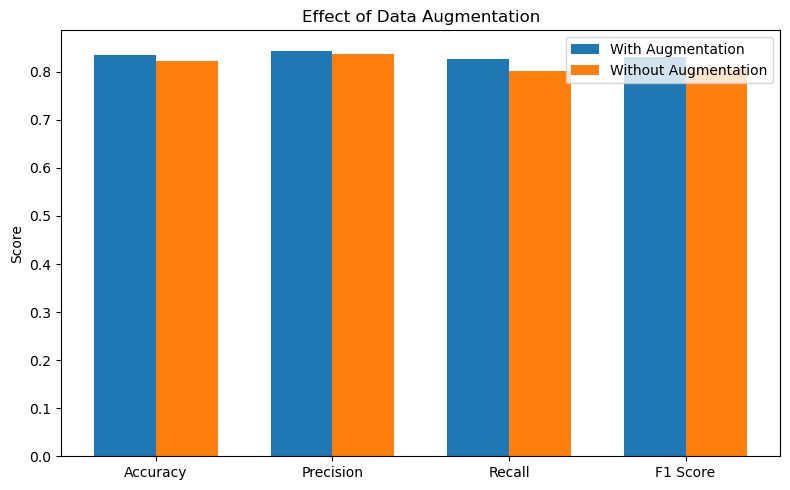


Comparison saved successfully.


In [207]:
# ============================================================
# STEP 11B-8 : ABLATION STUDY COMPARISON
# WITH vs WITHOUT DATA AUGMENTATION
# ============================================================

print("="*80)
print("STEP 11B-8 : ABLATION STUDY COMPARISON")
print("="*80)

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# File Paths
# ------------------------------------------------------------

WITH_AUG_FILE = Path(
    r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\VisionTransformer_Summary.csv"
)

WITHOUT_AUG_FILE = Path(
    r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Ablation_Study\Without_Augmentation\Classification_Report\Classification_Report_Summary.csv"
)

# ------------------------------------------------------------
# Load Files
# ------------------------------------------------------------

with_aug = pd.read_csv(WITH_AUG_FILE)

without_aug = pd.read_csv(WITHOUT_AUG_FILE)

# ------------------------------------------------------------
# Mean values of Without Augmentation
# ------------------------------------------------------------

without_mean = {

    "Accuracy"         : without_aug["Accuracy"].mean(),
    "Precision"        : without_aug["Macro Precision"].mean(),
    "Recall"           : without_aug["Macro Recall"].mean(),
    "F1 Score"         : without_aug["Macro F1"].mean()

}

# ------------------------------------------------------------
# ------------------------------------------------------------
# Select DeiT-Small from Benchmark
# ------------------------------------------------------------

with_aug = with_aug[with_aug["Model"] == MODEL_NAME]

if len(with_aug) == 0:
    raise ValueError(f"{MODEL_NAME} not found in benchmark summary.")

with_aug = with_aug.iloc[0]

# ------------------------------------------------------------
# Mean values of Without Augmentation
# ------------------------------------------------------------

without_mean = {

    "Accuracy"  : without_aug["Accuracy"].mean(),
    "Precision" : without_aug["Macro Precision"].mean(),
    "Recall"    : without_aug["Macro Recall"].mean(),
    "F1 Score"  : without_aug["Macro F1"].mean()

}

# ------------------------------------------------------------
# Comparison Table
# ------------------------------------------------------------

comparison = pd.DataFrame({

    "Metric":[
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],

    "With Augmentation":[

        with_aug["Accuracy_Mean"],

        with_aug["Precision_Mean"],

        with_aug["Recall_Mean"],

        with_aug["F1 Score_Mean"]

    ],

    "Without Augmentation":[

        without_mean["Accuracy"],

        without_mean["Precision"],

        without_mean["Recall"],

        without_mean["F1 Score"]

    ]

})

comparison["Improvement"] = (
    comparison["With Augmentation"] -
    comparison["Without Augmentation"]
)

display(comparison)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

SAVE_DIR = Path(
    r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Ablation_Study"
)

SAVE_DIR.mkdir(exist_ok=True)

comparison.to_csv(

    SAVE_DIR /

    "With_vs_Without_Augmentation.csv",

    index=False

)

# ------------------------------------------------------------
# Plot
# ------------------------------------------------------------

plt.figure(figsize=(8,5))

x = range(len(comparison))

width = 0.35

plt.bar(

    [i-width/2 for i in x],

    comparison["With Augmentation"],

    width,

    label="With Augmentation"

)

plt.bar(

    [i+width/2 for i in x],

    comparison["Without Augmentation"],

    width,

    label="Without Augmentation"

)

plt.xticks(

    x,

    comparison["Metric"]

)

plt.ylabel("Score")

plt.title("Effect of Data Augmentation")

plt.legend()

plt.tight_layout()

plt.savefig(

    SAVE_DIR /

    "With_vs_Without_Augmentation.png",

    dpi=300

)

plt.show()

print("\nComparison saved successfully.")

STEP 11B-8 : ABLATION STUDY COMPARISON


ABLATION STUDY RESULTS


,Metric,With Augmentation,Without Augmentation,Improvement,Improvement (%)
0,Accuracy,0.834821,0.821429,0.013393,1.339286
1,Precision,0.843995,0.836288,0.007707,0.770701
2,Recall,0.827370,0.801017,0.026353,2.635318
3,F1 Score,0.830389,0.806476,0.023913,2.391251
4,Cohen Kappa,0.811824,0.795944,0.015880,1.587998
5,MCC,0.812957,0.798598,0.014359,1.435890


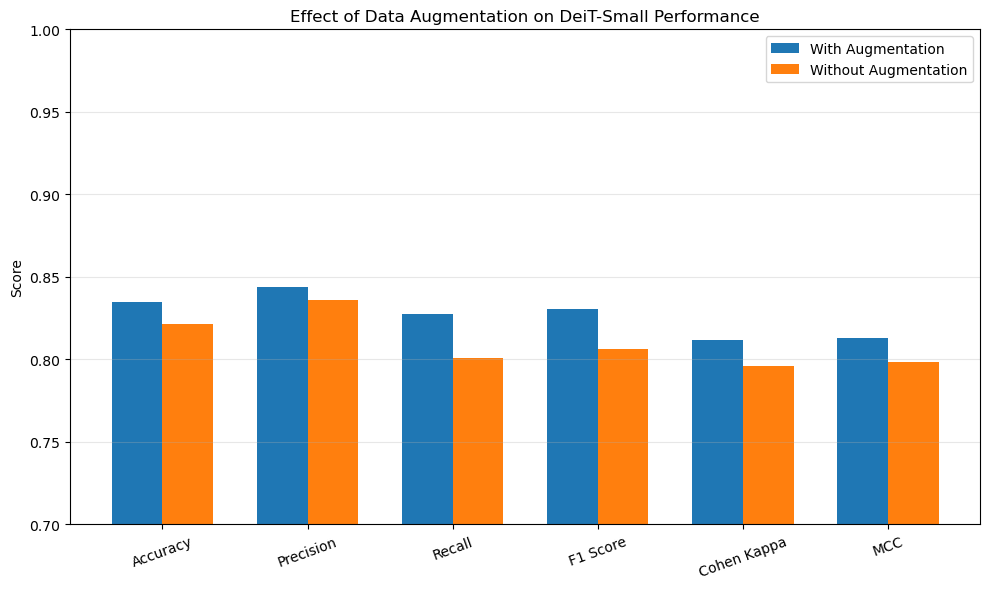



Comparison Saved Successfully
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Ablation_Study\With_vs_Without_Augmentation.csv
C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Ablation_Study\With_vs_Without_Augmentation.png
STEP 11B-8 COMPLETED


In [208]:
# ============================================================
# STEP 11B-8 : ABLATION STUDY COMPARISON
# WITH vs WITHOUT DATA AUGMENTATION
# ============================================================

print("=" * 80)
print("STEP 11B-8 : ABLATION STUDY COMPARISON")
print("=" * 80)

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# ------------------------------------------------------------
# File Paths
# ------------------------------------------------------------

WITH_AUG_FILE = Path(
    r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\VisionTransformer_Results\VisionTransformer_Summary.csv"
)

WITHOUT_AUG_FILE = Path(
    r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Ablation_Study\Without_Augmentation\Classification_Report\Classification_Report_Summary.csv"
)

WITHOUT_TEST_RESULTS = Path(
    r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Ablation_Study\Without_Augmentation\Test_Results\Without_Augmentation_Test_Results.csv"
)

# ------------------------------------------------------------
# Load Data
# ------------------------------------------------------------

with_aug = pd.read_csv(WITH_AUG_FILE)

without_aug = pd.read_csv(WITHOUT_AUG_FILE)

without_test = pd.read_csv(WITHOUT_TEST_RESULTS)

# ------------------------------------------------------------
# Select Model
# ------------------------------------------------------------

with_aug = with_aug[with_aug["Model"] == MODEL_NAME]

if len(with_aug) == 0:
    raise ValueError(f"{MODEL_NAME} not found in benchmark summary.")

with_aug = with_aug.iloc[0]

# ------------------------------------------------------------
# Compute Mean Metrics (Without Augmentation)
# ------------------------------------------------------------

without_metrics = {

    "Accuracy"      : without_aug["Accuracy"].mean(),
    "Precision"     : without_aug["Macro Precision"].mean(),
    "Recall"        : without_aug["Macro Recall"].mean(),
    "F1 Score"      : without_aug["Macro F1"].mean(),
    "Cohen Kappa"   : without_test["Cohen_Kappa"].mean(),
    "MCC"           : without_test["MCC"].mean()

}

# ------------------------------------------------------------
# Comparison Table
# ------------------------------------------------------------

comparison = pd.DataFrame({

    "Metric":[

        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "Cohen Kappa",
        "MCC"

    ],

    "With Augmentation":[

        with_aug["Accuracy_Mean"],
        with_aug["Precision_Mean"],
        with_aug["Recall_Mean"],
        with_aug["F1 Score_Mean"],
        with_aug["Cohen Kappa_Mean"],
        with_aug["MCC_Mean"]

    ],

    "Without Augmentation":[

        without_metrics["Accuracy"],
        without_metrics["Precision"],
        without_metrics["Recall"],
        without_metrics["F1 Score"],
        without_metrics["Cohen Kappa"],
        without_metrics["MCC"]

    ]

})

comparison["Improvement"] = (

    comparison["With Augmentation"]

    -

    comparison["Without Augmentation"]

)

comparison["Improvement (%)"] = (

    comparison["Improvement"] * 100

)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

print("\n")

print("=" * 80)
print("ABLATION STUDY RESULTS")
print("=" * 80)

display(comparison)

# ------------------------------------------------------------
# Save
# ------------------------------------------------------------

SAVE_DIR = Path(
    r"C:\Users\Frontech\Desktop\Codes\Combined Data set\New Test\Benchmark_v2\Benchmark_Results\Ablation_Study"
)

SAVE_DIR.mkdir(parents=True, exist_ok=True)

comparison.to_csv(

    SAVE_DIR /
    "With_vs_Without_Augmentation.csv",

    index=False

)

# ------------------------------------------------------------
# Publication Figure
# ------------------------------------------------------------

plt.figure(figsize=(10,6))

x = range(len(comparison))

width = 0.35

plt.bar(

    [i-width/2 for i in x],

    comparison["With Augmentation"],

    width,

    label="With Augmentation"

)

plt.bar(

    [i+width/2 for i in x],

    comparison["Without Augmentation"],

    width,

    label="Without Augmentation"

)

plt.xticks(

    x,

    comparison["Metric"],

    rotation=20

)

plt.ylabel("Score")

plt.ylim(0.70,1.00)

plt.grid(axis="y",alpha=0.3)

plt.legend()

plt.title("Effect of Data Augmentation on DeiT-Small Performance")

plt.tight_layout()

plt.savefig(

    SAVE_DIR /
    "With_vs_Without_Augmentation.png",

    dpi=300,

    bbox_inches="tight"

)

plt.show()

print("\n")

print("="*80)
print("Comparison Saved Successfully")
print("="*80)

print(SAVE_DIR / "With_vs_Without_Augmentation.csv")
print(SAVE_DIR / "With_vs_Without_Augmentation.png")

print("="*80)
print("STEP 11B-8 COMPLETED")
print("="*80)

In [269]:
# Prediction Performance Analysis

In [3]:
# ============================================================
# STEP 12A-1 : IMAGE-WISE PREDICTION EXTRACTION
# Save Prediction Probabilities for Every Test Image
# ============================================================

print("=" * 80)
print("STEP 12A-1 : IMAGE-WISE PREDICTION EXTRACTION")
print("=" * 80)

import torch
import torch.nn.functional as F
import pandas as pd
import numpy as np
from pathlib import Path

# ------------------------------------------------------------
# Output Directory
# ------------------------------------------------------------

PREDICTION_DIR = VIT_RESULTS_DIR / "Prediction_Reports"
PREDICTION_DIR.mkdir(parents=True, exist_ok=True)

print("\nPrediction Reports Folder:")
print(PREDICTION_DIR)

# ------------------------------------------------------------
# Prediction Extraction Function
# ------------------------------------------------------------

def extract_predictions(
    model,
    dataloader,
    class_names,
    model_name,
    run_number
):

    model.eval()

    prediction_records = []

    sample_id = 1

    with torch.no_grad():

        for batch in dataloader:

            # ------------------------------------------------
            # Images & Labels
            # ------------------------------------------------

            images = batch[0].to(DEVICE)
            labels = batch[1].to(DEVICE)

            outputs = model(images)

            probabilities = F.softmax(outputs, dim=1)

            top_probabilities, predictions = torch.max(
                probabilities,
                dim=1
            )

            # Top-2 probabilities (for prediction margin)

            top2_probabilities = torch.topk(
                probabilities,
                k=2,
                dim=1
            ).values

            # ------------------------------------------------
            # Store Image-wise Results
            # ------------------------------------------------

            for i in range(images.size(0)):

                true_class = labels[i].item()

                predicted_class = predictions[i].item()

                prediction_probability = float(
                    top_probabilities[i]
                )

                true_class_probability = float(
                    probabilities[i, true_class]
                )

                prediction_margin = float(
                    top2_probabilities[i, 0] -
                    top2_probabilities[i, 1]
                )

                entropy = float(

                    -(probabilities[i] *
                      torch.log(
                          probabilities[i] + 1e-12
                      )).sum()

                )

                prediction_records.append({

                    "Sample_ID":
                        sample_id,

                    "Model":
                        model_name,

                    "Run":
                        run_number,

                    "True_Label":
                        class_names[true_class],

                    "Predicted_Label":
                        class_names[predicted_class],

                    "Prediction_Probability":
                        prediction_probability,

                    "True_Class_Probability":
                        true_class_probability,

                    "Prediction_Margin":
                        prediction_margin,

                    "Prediction_Entropy":
                        entropy,

                    "Correct":
                        predicted_class == true_class

                })

                sample_id += 1

    prediction_df = pd.DataFrame(prediction_records)

    return prediction_df

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("\n✓ Prediction Extraction Function Created")

print("=" * 80)
print("STEP 12A-1 COMPLETED")
print("=" * 80)

STEP 12A-1 : IMAGE-WISE PREDICTION EXTRACTION


NameError: name 'VIT_RESULTS_DIR' is not defined

In [ ]:
# ============================================================
# STEP 12B : GENERATE IMAGE-WISE PREDICTION REPORTS
# ============================================================

print("=" * 80)
print("STEP 12B : GENERATE IMAGE-WISE PREDICTION REPORTS")
print("=" * 80)

from pathlib import Path
import pandas as pd

# ------------------------------------------------------------
# Output Directory
# ------------------------------------------------------------

PREDICTION_DIR = VIT_RESULTS_DIR / "Prediction_Reports"
PREDICTION_DIR.mkdir(parents=True, exist_ok=True)

print("\nPrediction Reports will be saved to:")
print(PREDICTION_DIR)

# ------------------------------------------------------------
# Class Names
# ------------------------------------------------------------

CLASS_NAMES = test_loader.dataset.classes

# ------------------------------------------------------------
# Generate Prediction Reports
# ------------------------------------------------------------

for model_name in BENCHMARK_MODELS:

    print("\n" + "="*60)
    print(f"Processing Model : {model_name}")
    print("="*60)

    for run in range(1, NUM_RUNS + 1):

        checkpoint = (
            VIT_MODELS_DIR /
            f"{model_name}_Run{run}.pth"
        )

        if not checkpoint.exists():

            print(f"Run {run} : Model not found.")
            continue

        print(f"Run {run} : Loading model...")

        model = create_model(model_name)

        load_checkpoint(
            model=model,
            optimizer=None,
            scheduler=None,
            filename=checkpoint,
            device=DEVICE
        )

        model.eval()

        prediction_df = extract_predictions(

            model=model,
            dataloader=test_loader,
            class_names=CLASS_NAMES,
            model_name=model_name,
            run_number=run

        )

        csv_file = (
            PREDICTION_DIR /
            f"{model_name}_Run{run}_Predictions.csv"
        )

        prediction_df.to_csv(
            csv_file,
            index=False
        )

        print(f"Saved : {csv_file.name}")

print("\n" + "="*80)
print("ALL PREDICTION REPORTS GENERATED SUCCESSFULLY")
print("="*80)